# Webtoon Crisis and Recovery Analysis
## 팀명: 쉬었음청년
- 팀장: 서동균<br>
- 팀원: 이정원, 한승원, 홍서진

# 필요한 패키지

Python **3.12**를 사용합니다. 저장소의 [pyproject.toml](pyproject.toml)에 분석 의존성과 실제 `dev` 그룹이 정의되어 있습니다. `uv.lock`은 해당 설정에서 생성한 의존성 잠금 파일입니다.

환경 파일을 새로 만들 필요 없이 아래 설치 안내를 따르세요. 웹 수집 패키지는 선택 의존성으로 분리되어 있으며 Step 5 이후 분석에는 필요하지 않습니다.


## 실행 환경 구성 안내

자세한 설치·실행 방법은 [README의 Run the Analysis](README.md#run-the-analysis)를 참고하세요.

1. 저장소 루트에 `webtoon_crisis_recovery.ipynb`, `pyproject.toml`, `uv.lock`이 있고, 준비된 데이터를 압축 해제하여 `data/processed/`와 `data/팀원별 라벨링/`이 있도록 배치합니다.
2. 프로젝트 루트에서 아래 명령을 실행합니다.

```bash
uv sync --locked --group dev
uv run --locked --group dev python -m ipykernel install --user --name webtoon-crisis-recovery --display-name "Python (webtoon-crisis-recovery)"
uv run --locked --group dev jupyter lab webtoon_crisis_recovery.ipynb
```

3. 커널은 `Python (webtoon-crisis-recovery)`을 선택합니다. VS Code에서도 같은 커널을 선택할 수 있습니다.
4. **Step 5. 데이터 수집 검증 코드**의 초기 import·경로 설정 셀부터 Step 9 마지막까지 순서대로 실행합니다. 상단부터 전체 실행하면 안 됩니다.

필수 데이터 파일의 구성은 [데이터 안내](docs/data.md)를 참고하세요.

제공된 수집 데이터와 확정 라벨을 사용하므로 분석 재현에는 LLM API 키가 필요하지 않습니다. 웹 재수집·LLM 라벨링·사람 검토 과정은 다시 실행하지 않습니다.

일부 셀은 `Malgun Gothic`을 지정합니다. Windows 이외 환경에서는 설치된 한글 폰트에 맞게 조정해야 그림의 한글을 표시할 수 있습니다. 계산 완료와 동일한 그림 표시 여부는 구분해야 합니다.


# 사전 수집된 데이터 다운로드
구글 드라이브 링크<a>https://drive.google.com/file/d/15eoIuDqCiX1QvS9BnkfTSSbzZDW5uYbA/view?usp=sharing</a><br>
링크에서 다운받으신 후 압축을 해제하신 다음 아래와 같은 형태로 폴더를 두시면 됩니다.

가상환경 패키지 관리자 uv 사용시, 반드시 최상위 프로젝트 폴더 이름은 영문명이어야 합니다. 

```txt
<프로젝트 폴더>
data/
│    ├── processed/
│    │    ├── comments/
│    │        ├── 각 웹툰별 폴더 - 폴더 안에 댓글 데이터 포함
│    │    ├── collection_status.parquet
│    │    ├── episodes.parquet
│    │    ├── labeling_result_codex_final.xlsx
│    │    ├── webtoon_genres.parquet
│    │    ├── webtoon_info.parquet
│    │    ├── webtoon_tags.parquet
│    │    └── works_base.parquet
│    ├── 팀원별 라벨링
│    │    ├── groundtruth - {이름} 최종.xlsx <-- 4개
│    │    ├── groundtruth - {이름}.xlsx <-- 4개
│    │    └── groundtruth_merged.xlsx
│    ├──
│    └── works_base.csv
webtoon_crisis_recovery.ipynb
```

# 프로젝트 재현 안내 및 전체 실행 흐름

본 노트북은 데이터 수집, 정제, RQ1~RQ4 분석을 하나의 파일에서 순차적으로 재현할 수 있도록 통합한 최종 제출용 코드입니다.  
다만 실제 재현 실행에서는 원자료 수집과 정제 과정을 다시 수행하지 않고, 구글 드라이브를 통해 제공된 정제 완료 데이터셋을 사용해야 합니다. 

따라서 `pyproject.toml`에 명시된 패키지를 설치한 뒤, 제공된 정제 데이터 폴더를 프로젝트 경로에 배치하고 **Step 5부터 순서대로 실행**하면 됩니다.  
Step 1~4는 데이터 수집 및 정제 과정을 확인할 수 있도록 포함한 참고용 코드이며, 최종 재현 실행 대상은 아닙니다.

## 실행 시작 지점

- 실행 시작: **Step 5. 데이터 수집 검증 코드**
- 이후 실행 순서: **Step 5 → Step 6 → Step 7 → Step 8 → Step 9**
- Step 5 이전 코드는 실제 웹 수집 및 원자료 정제 코드이므로, 제출 재현 시에는 실행하지 않습니다.

## 전체 Step 구성

### Step 1~4. 데이터 수집 및 정제 과정
네이버웹툰 작품 정보, 회차 정보, 댓글 데이터를 수집하고 분석 가능한 형태로 정제하는 코드입니다.  
최종 제출용 재현에서는 이미 정제된 데이터셋을 사용하므로 이 구간은 실행하지 않습니다.

### Step 5. 데이터 수집 검증
구글 드라이브에서 받은 정제 데이터가 올바른 위치에 있는지, 주요 테이블과 댓글 파일이 분석에 필요한 형태로 준비되어 있는지 검증합니다.

### Step 6. RQ1 분석
별점 하락을 기준으로 위기 회차를 탐지하고, 위기 강도 및 위기 클러스터를 생성합니다.  
주요 산출물은 `data/processed/rq1_*` 파일과 RQ1 시각화 자료입니다.

### Step 7. RQ2 분석
RQ1에서 탐지한 위기 회차에 해당하는 댓글을 결합하고, 댓글 라벨링 결과를 분석 가능한 형태로 정리합니다.  
주요 산출물은 `data/processed/rq2_*` 파일입니다.

### Step 8. RQ3 분석
저희 프로젝트의 핵심 분석 파트입니다. 
RQ1의 위기 클러스터와 RQ2의 댓글 원인 라벨을 결합하여 위기 이후 회복, 지속성, 다음 위기 전이, 원인별 차이를 분석합니다.  
주요 산출물은 `data/processed/rq3_*` 파일과 `data/plots/RQ3_analysis` 폴더입니다.

### Step 9. RQ4 분석
RQ3 결과를 작품 단위로 집계하여 위기-회복 trajectory 유형을 구성하고, 대표 사례 및 발표용 시각화 자료를 생성합니다.  
주요 산출물은 `data/processed/rq4_*` 파일과 `data/plots/RQ4_analysis` 폴더입니다.

## 재현 시 주의사항

1. 구글 드라이브에서 제공된 정제 데이터가 `data/processed` 및 관련 하위 폴더에 배치되어 있어야 합니다.
2. 노트북은 반드시 **Step 5부터 아래 방향으로 순차 실행**해야 합니다.
3. RQ3와 RQ4는 앞선 RQ1, RQ2 산출물을 입력으로 사용하므로 중간 셀을 건너뛰지 않아야 합니다.
4. 모든 주요 산출물은 연구질문 번호에 맞춰 `rq1_`, `rq2_`, `rq3_`, `rq4_` prefix를 사용합니다.


### 데이터 저장 경로
`./data/raw`
`./data/logs`
`./data/interim`

# Step 1. 웹툰 목록 수집

In [38]:
import time
import json
from pathlib import Path
from typing import Any, Dict, List, Optional

import pandas as pd
import requests


WEEKDAY_TITLELIST_URL = "https://comic.naver.com/api/webtoon/titlelist/weekday"

# 데이터 수집에 가장 기본이 되는 수집 객체
class NaverWebtoonTitleCollector:
    def __init__(
        self,
        raw_dir: str = "data/raw",
        interim_dir: str = "data/interim",
        log_dir: str = "data/logs",
        sleep_sec: float = 1.0,
        max_retries: int = 2,
    ):
        self.session = requests.Session()
        self.session.headers.update({
            "User-Agent": (
                "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                "AppleWebKit/537.36 (KHTML, like Gecko) "
                "Chrome/122.0 Safari/537.36"
            ),
            "Accept": "application/json, text/plain, */*",
            "Accept-Language": "ko-KR,ko;q=0.9,en-US;q=0.8,en;q=0.7",
            "Referer": "https://comic.naver.com/webtoon",
        })

        self.raw_dir = Path(raw_dir)
        self.interim_dir = Path(interim_dir)
        self.log_dir = Path(log_dir)

        self.raw_dir.mkdir(parents=True, exist_ok=True)
        self.interim_dir.mkdir(parents=True, exist_ok=True)
        self.log_dir.mkdir(parents=True, exist_ok=True)

        self.sleep_sec = sleep_sec
        self.max_retries = max_retries
        self.logs: List[Dict[str, Any]] = []

    def _log(
        self,
        target: str,
        status: str,
        url: str,
        params: Optional[Dict[str, Any]] = None,
        error_message: Optional[str] = None,
    ):
        self.logs.append({
            "target": target,
            "status": status,
            "url": url,
            "params": json.dumps(params or {}, ensure_ascii=False),
            "error_message": error_message,
            "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
        })

    def request_json(
        self,
        url: str,
        params: Optional[Dict[str, Any]] = None,
        target: str = "unknown",
    ) -> Dict[str, Any]: # 출력 타입은 딕셔너리로
        for attempt in range(self.max_retries + 1):
            try:
                time.sleep(self.sleep_sec)

                response = self.session.get(
                    url,
                    params=params,
                    timeout=10,
                )

                if response.status_code != 200:
                    self._log(
                        target=target,
                        status=f"http_{response.status_code}",
                        url=response.url,
                        params=params,
                        error_message=response.text[:500],
                    )
                    continue

                data = response.json()

                self._log(
                    target=target,
                    status="success",
                    url=response.url,
                    params=params,
                )

                return data

            except Exception as e:
                self._log(
                    target=target,
                    status=f"error_attempt_{attempt}",
                    url=url,
                    params=params,
                    error_message=str(e),
                )

        raise RuntimeError(f"Failed to request JSON: {url}")

    def save_json(self, data: Dict[str, Any], path: Path):
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False, indent=2)

    def save_logs(self):
        path = self.log_dir / "weekday_titlelist_collection_log.json"
        self.save_json({"logs": self.logs}, path)

    def collect_weekday_titlelist_raw(self, order: str = "user") -> Dict[str, Any]:
        params = {"order": order}

        data = self.request_json(
            WEEKDAY_TITLELIST_URL,
            params=params,
            target=f"weekday_titlelist_order_{order}",
        )

        raw_path = self.raw_dir / f"weekday_titlelist_order_{order}.json"
        self.save_json(data, raw_path)

        return data

# 요일별 웹툰 리스트 가져오기(raw데이터에서 에서 파싱)
def parse_weekday_titlelist(data: Dict[str, Any]) -> pd.DataFrame:
    title_list_map = data.get("titleListMap", {})

    rows = []

    for weekday, title_items in title_list_map.items():
        if not isinstance(title_items, list):
            continue

        for item in title_items:
            if not isinstance(item, dict):
                continue

            row = {
                "title_id": item.get("titleId"),
                "title_name": item.get("titleName"),
                "author_text": item.get("author"),
                "thumbnail_url": item.get("thumbnailUrl"),
                "weekday": weekday,

                # 상태/메타 플래그
                "is_up": item.get("up"),
                "is_rest": item.get("rest"),
                "is_bookmarked": item.get("bm"),
                "is_adult": item.get("adult"),
                "is_open_today": item.get("openToday"),
                "is_poten_up": item.get("potenUp"),
                "is_best_challenge_level_up": item.get("bestChallengeLevelUp"),
                "is_finished": item.get("finish"),
                "is_new": item.get("new"),

                # 지표
                "star_score": item.get("starScore"),
                "view_count": item.get("viewCount"),

                # 수집 메타데이터
                "source": "naver_webtoon_weekday_titlelist_api",
                "collected_at": time.strftime("%Y-%m-%d %H:%M:%S"),
            }

            rows.append(row)

    df = pd.DataFrame(rows)

    if df.empty:
        return df

    # 타입 정리
    df["title_id"] = pd.to_numeric(df["title_id"], errors="coerce").astype("Int64")
    df["star_score"] = pd.to_numeric(df["star_score"], errors="coerce")
    df["view_count"] = pd.to_numeric(df["view_count"], errors="coerce").astype("Int64")

    bool_cols = [
        "is_up",
        "is_rest",
        "is_bookmarked",
        "is_adult",
        "is_open_today",
        "is_poten_up",
        "is_best_challenge_level_up",
        "is_finished",
        "is_new",
    ]

    for col in bool_cols:
        if col in df.columns:
            df[col] = df[col].astype("boolean")

    return df


def build_works_and_weekdays(
    weekday_df: pd.DataFrame,
    exclude_adult: bool = True,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    df = weekday_df.copy()

    if exclude_adult:
        df = df[df["is_adult"] != True].copy()

    # 작품-요일 매핑 테이블
    work_weekdays = (
        df[["title_id", "weekday"]]
        .drop_duplicates()
        .sort_values(["title_id", "weekday"])
        .reset_index(drop=True)
    )

    # 작품 단위 base 테이블에서 요일 정보를 잃지 않기 위한 최소 집계 컬럼
    # 복수 요일 여부, weekday_count 등 추가 파생 변수는 여기서 생성하지 않음
    weekday_list = (
        work_weekdays
        .groupby("title_id")["weekday"]
        .apply(lambda x: ",".join(sorted(x.dropna().astype(str).unique())))
        .reset_index()
        .rename(columns={"weekday": "weekday_list"})
    )

    # works_base.csv에 포함할 원천 컬럼만 선택
    base_cols = [
        "title_id",
        "title_name",
        "author_text",
        "is_adult",
        "is_rest",
        "is_new",
        "star_score",
    ]

    works_base = (
        df[base_cols]
        .sort_values(["title_id"])
        .drop_duplicates(subset=["title_id"], keep="first")
        .merge(weekday_list, on="title_id", how="left")
        .reset_index(drop=True)
    )

    return works_base, work_weekdays


def audit_dataframe_summary(
    df: pd.DataFrame,
    name: str = "dataframe",
):
    print("=" * 80)
    print(f"[SUMMARY AUDIT] {name}")
    print("=" * 80)

    print(f"rows: {len(df):,}")
    print(f"columns: {len(df.columns):,}")

    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "null": df.isna().sum(),
        "null_ratio": df.isna().mean().round(4),
        "unique": df.nunique(dropna=True),
    }).reset_index().rename(columns={"index": "column"})

    print("\n[컬럼 요약]")
    print(summary.to_string(index=False))

    print("\n[boolean / flag 컬럼 분포]")
    for col in df.columns:
        series = df[col]
        non_null_unique = set(series.dropna().unique())

        if pd.api.types.is_bool_dtype(series) or non_null_unique.issubset({True, False}):
            print("-" * 80)
            print(f"{col}")
            print(series.value_counts(dropna=False).to_string())

    print("\n[numeric 컬럼 0 비율]")
    for col in df.select_dtypes(include=["number"]).columns:
        zero_ratio = (df[col] == 0).mean()
        print(f"{col}: zero_ratio={zero_ratio:.2%}, unique={df[col].nunique(dropna=True)}")

    print("\n[object 컬럼 상위값]")
    for col in df.select_dtypes(include=["object"]).columns:
        print("-" * 80)
        print(f"{col}")
        print(df[col].value_counts(dropna=False).head(10).to_string())

    print("\n[중복]")
    if "title_id" in df.columns:
        print(f"unique title_id: {df['title_id'].nunique(dropna=True):,}")
        print(f"duplicated title_id rows: {df.duplicated(subset=['title_id']).sum():,}")

    if {"title_id", "weekday"}.issubset(df.columns):
        print(f"unique title_id-weekday pairs: {df[['title_id', 'weekday']].drop_duplicates().shape[0]:,}")
        print(f"duplicated title_id-weekday rows: {df.duplicated(subset=['title_id', 'weekday']).sum():,}")

    print("=" * 80)


def main():
    collector = NaverWebtoonTitleCollector(
        raw_dir="data/raw",
        interim_dir="data/interim",
        log_dir="data/logs",
        sleep_sec=1.0,
        max_retries=2,
    )

    # 요일별 작품 목록 API 수집
    raw_data = collector.collect_weekday_titlelist_raw(order="user")

    # 수집한 원본 JSON 데이터를 평탄화하여 DataFrame으로 변환
    weekday_df = parse_weekday_titlelist(raw_data)

    weekday_df.to_csv(
        "data/interim/weekday_titlelist_raw_flat.csv",
        index=False,
        encoding="utf-8-sig",
    )

    weekday_df = pd.read_csv("data/interim/weekday_titlelist_raw_flat.csv")

    # DataFrame 전체 품질 점검
    audit_dataframe_summary(
        weekday_df,
        name="weekday_titlelist_raw_flat",
    )

    # 19금 작품 제외 후 작품 base 테이블과 작품-요일 매핑 테이블 생성
    works_base, work_weekdays = build_works_and_weekdays(
        weekday_df,
        exclude_adult=True,
    )

    works_base.to_csv(
        "data/interim/works_base.csv",
        index=False,
        encoding="utf-8-sig",
    )
    works_base.to_csv(
        "data/works_base.csv",
        index=False,
        encoding="utf-8-sig",
    )

    work_weekdays.to_csv(
        "data/interim/work_weekdays.csv",
        index=False,
        encoding="utf-8-sig",
    )

    # 로그 저장
    collector.save_logs()

    print(f"전체 작품-요일 row 수: {len(weekday_df)}")
    print(f"19금 제외 후 작품 수: {len(works_base)}")
    print(f"작품-요일 매핑 수: {len(work_weekdays)}")
    print("저장 완료:")
    print("- data/raw/weekday_titlelist_order_user.json")
    print("- data/interim/weekday_titlelist_raw_flat.csv")
    print("- data/interim/works_base.csv")
    print("- data/works_base.csv")
    print("- data/interim/work_weekdays.csv")

# works_base.csv 생성 로직 실행
main()

[SUMMARY AUDIT] weekday_titlelist_raw_flat
rows: 782
columns: 18

[컬럼 요약]
                    column   dtype  non_null  null  null_ratio  unique
                  title_id   int64       782     0         0.0     752
                title_name  object       782     0         0.0     752
               author_text  object       782     0         0.0     748
             thumbnail_url  object       782     0         0.0     752
                   weekday  object       782     0         0.0       7
                     is_up    bool       782     0         0.0       2
                   is_rest    bool       782     0         0.0       2
             is_bookmarked    bool       782     0         0.0       1
                  is_adult    bool       782     0         0.0       2
             is_open_today    bool       782     0         0.0       2
               is_poten_up    bool       782     0         0.0       1
is_best_challenge_level_up    bool       782     0         0.0       1
   

/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/1773599606.py:182: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["title_id"] = pd.to_numeric(df["title_id"], errors="coerce").astype("Int64")
/var/folders/td/gc0r8mhx5mlg2jb

# Step 2. EDA

### 기본 설정

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["axes.unicode_minus"] = False

try:
    # plt.rcParams["font.family"] = "Malgun Gothic"  # Windows 환경
    plt.rcParams['font.family'] = 'AppleGothic'  # macOS 환경이면 이걸로 하기
except:
    pass

DATA_PATH = "./data/works_base.csv"

df = pd.read_csv(DATA_PATH)

print("데이터 크기:", df.shape)
display(df.head())

데이터 크기: (706, 8)


,title_id,title_name,author_text,is_adult,is_rest,is_new,star_score,weekday_list
0,21815,히어로메이커,빤쓰,False,False,False,9.90681,MONDAY
1,64997,나이트런,김성민,False,False,False,9.91362,SATURDAY
2,131385,쿠베라,카레곰,False,False,False,9.96418,THURSDAY
3,400739,에이머,구동인,False,False,False,9.80818,TUESDAY
4,570506,최강전설 강해효,최병열,False,False,False,9.55005,THURSDAY


In [9]:
# ============================================================
# 01. 데이터 기본 품질 점검
# ============================================================

print("컬럼 목록")
print(df.columns.tolist())

print("\n데이터 타입")
display(df.dtypes)

print("\n결측치 개수")
display(df.isna().sum())

print("\ntitle_id 중복 개수")
print(df["title_id"].duplicated().sum())

print("\n고유 title_id 수")
print(df["title_id"].nunique())

print("\nBoolean 변수 분포")
for col in ["is_adult", "is_rest", "is_new"]:
    print(f"\n[{col}]")
    display(df[col].value_counts(dropna=False))

print("\nstar_score 기본 범위")
print("min:", df["star_score"].min())
print("max:", df["star_score"].max())

컬럼 목록
['title_id', 'title_name', 'author_text', 'is_adult', 'is_rest', 'is_new', 'star_score', 'weekday_list']

데이터 타입


title_id          int64
title_name       object
author_text      object
is_adult           bool
is_rest            bool
is_new             bool
star_score      float64
weekday_list     object
dtype: object


결측치 개수


title_id        0
title_name      0
author_text     0
is_adult        0
is_rest         0
is_new          0
star_score      0
weekday_list    0
dtype: int64


title_id 중복 개수
0

고유 title_id 수
706

Boolean 변수 분포

[is_adult]


...


[is_rest]


is_rest
False    668
True      38
Name: count, dtype: int64


[is_new]


is_new
False    668
True      38
Name: count, dtype: int64


star_score 기본 범위
min: 2.56687
max: 9.98329


In [10]:
# ============================================================
# 02. 전체 작품 평점 분포 1차 확인
# ============================================================

score = df["star_score"].dropna()

score_summary = score.describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print("star_score 기술통계 및 주요 분위수")
display(score_summary)

print("\n요약")
print(f"평균: {score.mean():.4f}")
print(f"중앙값: {score.median():.4f}")
print(f"표준편차: {score.std():.4f}")
print(f"최솟값: {score.min():.4f}")
print(f"최댓값: {score.max():.4f}")

star_score 기술통계 및 주요 분위수


count    706.000000
mean       9.741658
std        0.600968
min        2.566870
1%         7.324495
5%         9.032637
10%        9.505010
25%        9.795410
50%        9.895525
75%        9.944560
90%        9.963330
95%        9.970200
99%        9.978109
max        9.983290
Name: star_score, dtype: float64


요약
평균: 9.7417
중앙값: 9.8955
표준편차: 0.6010
최솟값: 2.5669
최댓값: 9.9833


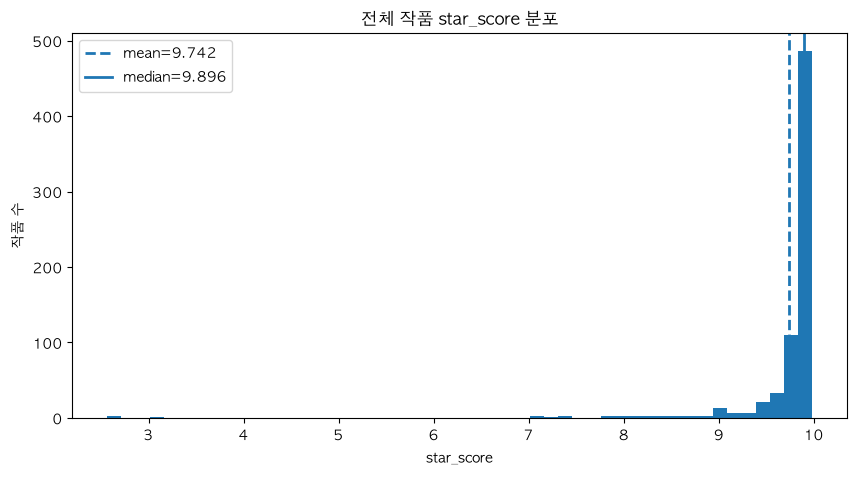

/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/3819921383.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(score, vert=True)


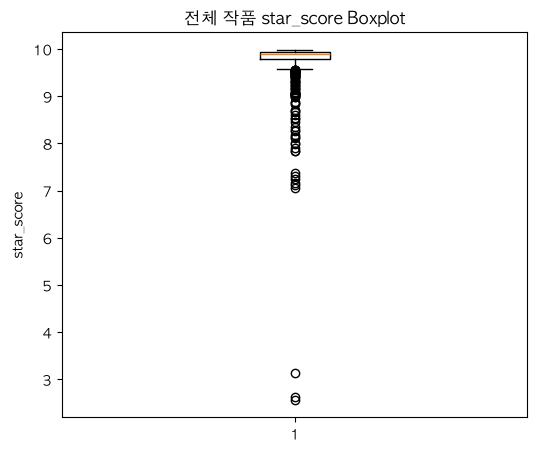

In [11]:
# ============================================================
# 03. 전체 작품 평점 분포 시각화
# ============================================================
plt.figure(figsize=(10, 5))
plt.hist(score, bins=50)
plt.axvline(score.mean(), linestyle="--", linewidth=2, label=f"mean={score.mean():.3f}")
plt.axvline(score.median(), linestyle="-", linewidth=2, label=f"median={score.median():.3f}")
plt.title("전체 작품 star_score 분포")
plt.xlabel("star_score")
plt.ylabel("작품 수")
plt.legend()
plt.show()

plt.figure(figsize=(6, 5))
plt.boxplot(score, vert=True)
plt.title("전체 작품 star_score Boxplot")
plt.ylabel("star_score")
plt.show()

In [12]:
# ============================================================
# 04. 도메인 기반 평점 구간화
# ============================================================
eda_df = df.copy()

score_bins = [ # 별점별로 구간 나눔 - 휴리스틱하게 일단 나눠서 확인
    0, 5.0,
    7.0,
    8.0,
    9.0,
    9.3,
    9.5,
    9.7,
    9.8,
    9.85,
    9.9,
    9.95,
    10.01
]

score_labels = [
    "0~5.0",
    "5.0~7.0",
    "7.0~8.0",
    "8.0~9.0",
    "9.0~9.3",
    "9.3~9.5",
    "9.5~9.7",
    "9.7~9.8",
    "9.8~9.85",
    "9.85~9.9",
    "9.9~9.95",
    "9.95~10.0"
]

eda_df["star_score_bin"] = pd.cut(
    eda_df["star_score"],
    bins=score_bins,
    labels=score_labels,
    include_lowest=True,
    right=False
)

score_bin_counts = eda_df["star_score_bin"].value_counts().reindex(score_labels)
score_bin_ratio = score_bin_counts / len(eda_df)

score_bin_table = pd.DataFrame({
    "count": score_bin_counts,
    "ratio": score_bin_ratio
})

display(score_bin_table)

/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/3801909778.py:36: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  eda_df["star_score_bin"] = pd.cut(


,count,ratio
star_score_bin,,
0~5.0,3,0.004249
5.0~7.0,0,0.000000
7.0~8.0,10,0.014164
8.0~9.0,20,0.028329
9.0~9.3,19,0.026912
9.3~9.5,17,0.024079
9.5~9.7,48,0.067989
9.7~9.8,69,0.097734
9.8~9.85,58,0.082153


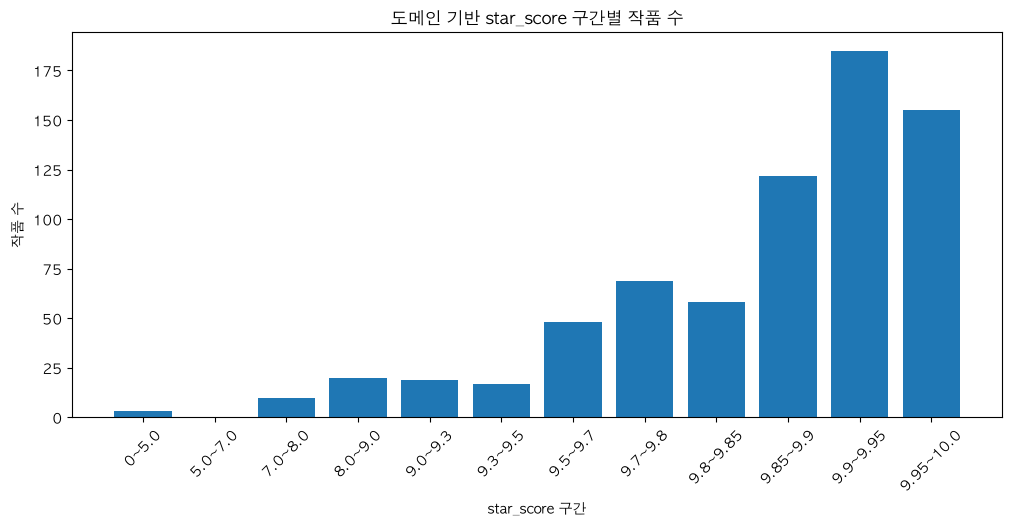

In [13]:
# ============================================================
# 05. 도메인 기반 평점 구간별 작품 수 시각화
# ============================================================

plt.figure(figsize=(12, 5))
plt.bar(score_bin_table.index.astype(str), score_bin_table["count"])
plt.title("도메인 기반 star_score 구간별 작품 수")
plt.xlabel("star_score 구간")
plt.ylabel("작품 수")
plt.xticks(rotation=45)
plt.show()

In [14]:
# ============================================================
# 06. 주요 기준별 작품 수와 비율
# ============================================================

score_ratio_summary = pd.DataFrame({
    "기준": [
        "9.95 이상",
        "9.9 이상",
        "9.8 이상",
        "9.5 이상",
        "9.0 미만",
        "8.0 미만",
        "5.0 미만"
    ],
    "작품 수": [
        (eda_df["star_score"] >= 9.95).sum(),
        (eda_df["star_score"] >= 9.9).sum(),
        (eda_df["star_score"] >= 9.8).sum(),
        (eda_df["star_score"] >= 9.5).sum(),
        (eda_df["star_score"] < 9.0).sum(),
        (eda_df["star_score"] < 8.0).sum(),
        (eda_df["star_score"] < 5.0).sum()
    ]
})

score_ratio_summary["비율"] = score_ratio_summary["작품 수"] / len(eda_df)

display(score_ratio_summary)

/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/2301920101.py:26: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  score_ratio_summary["비율"] = score_ratio_summary["작품 수"] / len(eda_df)


,기준,작품 수,비율
0,9.95 이상,155,0.219547
1,9.9 이상,340,0.481586
2,9.8 이상,520,0.736544
3,9.5 이상,637,0.902266
4,9.0 미만,33,0.046742
5,8.0 미만,13,0.018414
6,5.0 미만,3,0.004249


In [15]:
# ============================================================
# 07. 도메인 기반 평점 그룹 라벨링
# ============================================================

def assign_score_group(x): 
    if x < 5.0:
        return "extreme_low(<5.0)"
    elif x < 8.0:
        return "very_low(5.0~8.0)"
    elif x < 9.0:
        return "low(8.0~9.0)"
    elif x < 9.5:
        return "watch(9.0~9.5)"
    elif x < 9.8:
        return "normal(9.5~9.8)"
    else:
        return "normal_high(>=9.8)"

eda_df["score_group"] = eda_df["star_score"].apply(assign_score_group)

score_group_order = [
    "extreme_low(<5.0)",
    "very_low(5.0~8.0)",
    "low(8.0~9.0)",
    "watch(9.0~9.5)",
    "normal(9.5~9.8)",
    "normal_high(>=9.8)"
]

score_group_summary = (
    eda_df["score_group"]
    .value_counts()
    .reindex(score_group_order)
    .to_frame("count")
)

score_group_summary["ratio"] = score_group_summary["count"] / len(eda_df)

display(score_group_summary)

/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/963710483.py:19: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  eda_df["score_group"] = eda_df["star_score"].apply(assign_score_group)
/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c00

,count,ratio
score_group,,
extreme_low(<5.0),3,0.004249
very_low(5.0~8.0),10,0.014164
low(8.0~9.0),20,0.028329
watch(9.0~9.5),36,0.050992
normal(9.5~9.8),117,0.165722
normal_high(>=9.8),520,0.736544


In [16]:
# ============================================================
# 08. 저평점 및 관찰 후보 작품 목록 확인
# ============================================================

print("극단적 저평점 작품(extreme_low): star_score < 5.0")
display(
    eda_df.loc[
        eda_df["star_score"] < 5.0,
        ["title_id", "title_name", "star_score", "is_new", "is_rest", "weekday_list", "score_group"]
    ].sort_values("star_score")
)

print("매우 낮은 평점 작품: 5.0 <= star_score < 8.0")
display(
    eda_df.loc[
        (eda_df["star_score"] >= 5.0) & (eda_df["star_score"] < 8.0),
        ["title_id", "title_name", "star_score", "is_new", "is_rest", "weekday_list", "score_group"]
    ].sort_values("star_score")
)

print("저평점 작품: 8.0 <= star_score < 9.0")
display(
    eda_df.loc[
        (eda_df["star_score"] >= 8.0) & (eda_df["star_score"] < 9.0),
        ["title_id", "title_name", "star_score", "is_new", "is_rest", "weekday_list", "score_group"]
    ].sort_values("star_score")
)

print("주의 관찰 작품: 9.0 <= star_score < 9.5")
display(
    eda_df.loc[
        (eda_df["star_score"] >= 9.0) & (eda_df["star_score"] < 9.5),
        ["title_id", "title_name", "star_score", "is_new", "is_rest", "weekday_list", "score_group"]
    ].sort_values("star_score")
)

극단적 저평점 작품(extreme_low): star_score < 5.0


,title_id,title_name,star_score,is_new,is_rest,weekday_list,score_group
526,845671,공주님 학교 가신다,2.56687,False,False,FRIDAY,extreme_low(<5.0)
428,842322,웅녀님이 보우하사,2.62200,False,False,MONDAY,extreme_low(<5.0)
299,835801,달마건,3.14270,False,False,WEDNESDAY,extreme_low(<5.0)


매우 낮은 평점 작품: 5.0 <= star_score < 8.0


,title_id,title_name,star_score,is_new,is_rest,weekday_list,score_group
698,851384,에투알의 비밀,7.06122,True,False,TUESDAY,very_low(5.0~8.0)
462,843209,포비든 플레저,7.12066,False,False,WEDNESDAY,very_low(5.0~8.0)
50,774358,천마는 평범하게 살 수 없다,7.16204,False,False,TUESDAY,very_low(5.0~8.0)
211,827335,소년교도소,7.24192,False,True,SUNDAY,very_low(5.0~8.0)
347,839284,복학생,7.32140,False,False,THURSDAY,very_low(5.0~8.0)
672,850649,무무무,7.38331,True,False,SATURDAY,very_low(5.0~8.0)
556,846866,데빌 캐피탈,7.83218,False,False,MONDAY,very_low(5.0~8.0)
699,851409,더 스트리머,7.84519,True,False,WEDNESDAY,very_low(5.0~8.0)
554,846820,들개전쟁,7.90160,False,False,SATURDAY,very_low(5.0~8.0)
92,803792,연애의 기록,7.98021,False,False,FRIDAY,very_low(5.0~8.0)


저평점 작품: 8.0 <= star_score < 9.0


,title_id,title_name,star_score,is_new,is_rest,weekday_list,score_group
262,833418,하이클래스,8.01762,False,False,THURSDAY,low(8.0~9.0)
440,842624,동경,8.10665,False,False,SATURDAY,low(8.0~9.0)
551,846650,연애지옥,8.14707,False,False,SATURDAY,low(8.0~9.0)
157,819506,이매망량,8.18621,False,False,SATURDAY,low(8.0~9.0)
494,844505,르르르,8.27413,False,False,SATURDAY,low(8.0~9.0)
323,837998,마교 교주의 부군이 되었다,8.28614,False,False,TUESDAY,low(8.0~9.0)
514,845175,뼈말라인 내가 100kg가 된 이유,8.35600,False,False,SUNDAY,low(8.0~9.0)
585,848103,미스테리 쇼크,8.45251,False,False,SUNDAY,low(8.0~9.0)
525,845665,블러드레인 3,8.52468,False,False,TUESDAY,low(8.0~9.0)
330,838432,우렉 마지노,8.53995,False,False,TUESDAY,low(8.0~9.0)


주의 관찰 작품: 9.0 <= star_score < 9.5


,title_id,title_name,star_score,is_new,is_rest,weekday_list,score_group
367,840344,비기닝즈,9.02004,False,False,TUESDAY,watch(9.0~9.5)
694,851029,더킹,9.02946,True,False,WEDNESDAY,watch(9.0~9.5)
412,841792,청소요원,9.02986,False,False,FRIDAY,watch(9.0~9.5)
566,847541,천씨세가의 망나니가 되었다,9.04097,False,True,TUESDAY,watch(9.0~9.5)
695,851257,폭풍의 전학생 시즌3,9.04246,True,False,TUESDAY,watch(9.0~9.5)
632,849538,고교야구 타이쿤,9.04916,False,False,SATURDAY,watch(9.0~9.5)
688,850952,이레즈미 소개팅남,9.06898,True,False,"SUNDAY,THURSDAY",watch(9.0~9.5)
604,848901,엄마는 남자만 좋아해,9.07540,False,False,SATURDAY,watch(9.0~9.5)
702,851610,무림사채왕,9.07818,True,False,THURSDAY,watch(9.0~9.5)
388,840900,썸머문: 더 큐프리즈,9.08123,False,True,TUESDAY,watch(9.0~9.5)


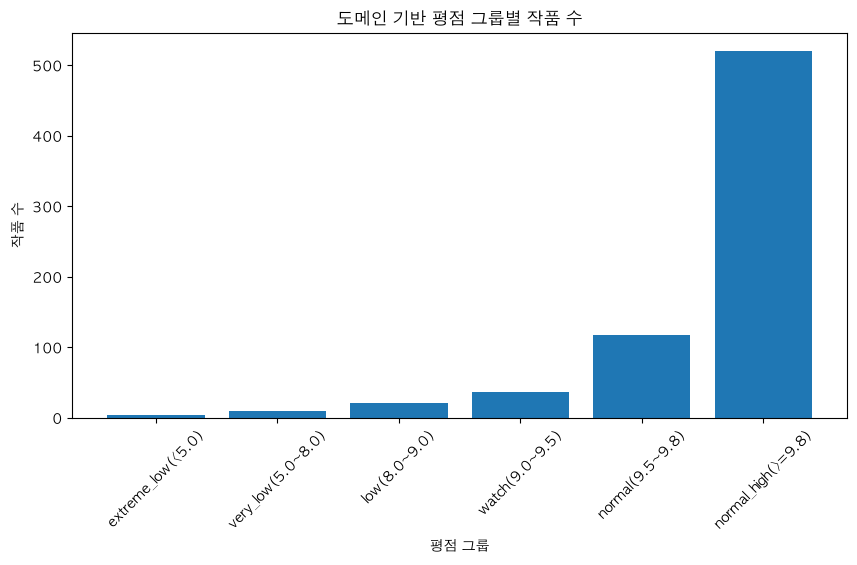

In [17]:
# ============================================================
# 09. 평점 그룹별 시각화
# ============================================================

plt.figure(figsize=(10, 5))
plt.bar(score_group_summary.index, score_group_summary["count"])
plt.title("도메인 기반 평점 그룹별 작품 수")
plt.xlabel("평점 그룹")
plt.ylabel("작품 수")
plt.xticks(rotation=45)
plt.show()

In [18]:
# ============================================================
# 10. 요일별 데이터 생성
# ============================================================

weekday_df = eda_df.copy()

# 복수 요일 연재 작품을 요일 단위로 펼치기
weekday_df["weekday"] = weekday_df["weekday_list"].str.split(",")
weekday_df = weekday_df.explode("weekday")

weekday_order = [
    "MONDAY", "TUESDAY", "WEDNESDAY", "THURSDAY",
    "FRIDAY", "SATURDAY", "SUNDAY"
]

weekday_kor = {
    "MONDAY": "월",
    "TUESDAY": "화",
    "WEDNESDAY": "수",
    "THURSDAY": "목",
    "FRIDAY": "금",
    "SATURDAY": "토",
    "SUNDAY": "일"
}

weekday_df["weekday_kor"] = weekday_df["weekday"].map(weekday_kor)

print("요일 단위로 펼친 데이터 크기:", weekday_df.shape)
display(weekday_df[["title_id", "title_name", "star_score", "weekday_list", "weekday", "weekday_kor"]].head())

요일 단위로 펼친 데이터 크기: (733, 12)


/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/1749432055.py:8: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  weekday_df["weekday"] = weekday_df["weekday_list"].str.split(",")
/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/

,title_id,title_name,star_score,weekday_list,weekday,weekday_kor
0,21815,히어로메이커,9.90681,MONDAY,MONDAY,월
1,64997,나이트런,9.91362,SATURDAY,SATURDAY,토
2,131385,쿠베라,9.96418,THURSDAY,THURSDAY,목
3,400739,에이머,9.80818,TUESDAY,TUESDAY,화
4,570506,최강전설 강해효,9.55005,THURSDAY,THURSDAY,목


,작품 수
월,106
화,110
수,102
목,99
금,109
토,109
일,98


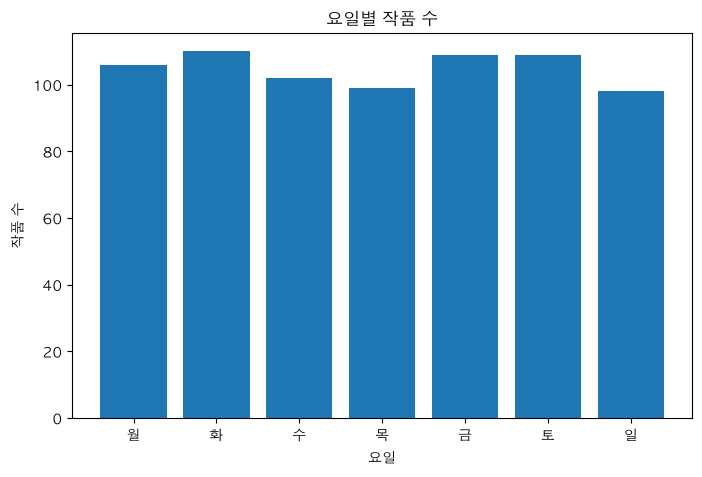

In [19]:
# ============================================================
# 11. 요일별 작품 수
# ============================================================

weekday_counts = (
    weekday_df["weekday"]
    .value_counts()
    .reindex(weekday_order)
)

weekday_counts.index = [weekday_kor[x] for x in weekday_counts.index]

display(weekday_counts.to_frame("작품 수"))

plt.figure(figsize=(8, 5))
plt.bar(weekday_counts.index, weekday_counts.values)
plt.title("요일별 작품 수")
plt.xlabel("요일")
plt.ylabel("작품 수")
plt.show()

In [20]:
# ============================================================
# 12. 요일별 평점 요약 통계
# ============================================================

weekday_score_summary = (
    weekday_df
    .groupby("weekday")["star_score"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reindex(weekday_order)
)

weekday_score_summary.index = [weekday_kor[x] for x in weekday_score_summary.index]

display(weekday_score_summary)

,count,mean,median,std,min,max
월,106,9.758299,9.900700,0.752125,2.62200,9.97908
화,110,9.710697,9.892375,0.490011,7.06122,9.98329
수,102,9.704589,9.882700,0.763943,3.14270,9.97648
목,99,9.777421,9.901570,0.377393,7.32140,9.97812
금,109,9.759261,9.906950,0.737464,2.56687,9.97642
토,109,9.708782,9.896310,0.482361,7.38331,9.97848
일,98,9.803694,9.908065,0.365790,7.24192,9.97499


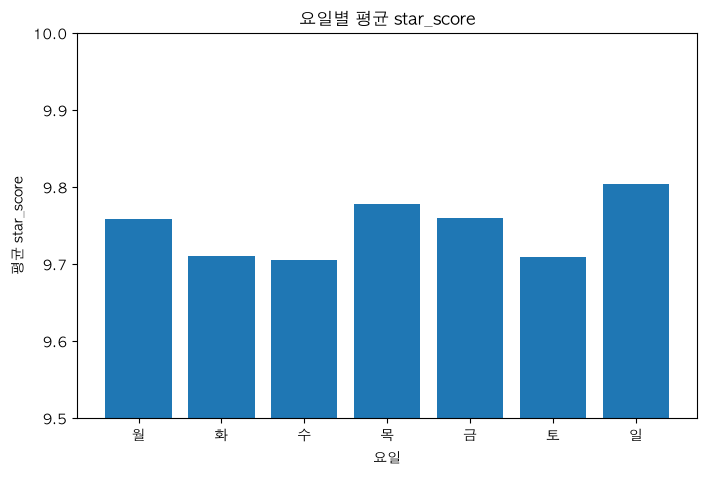

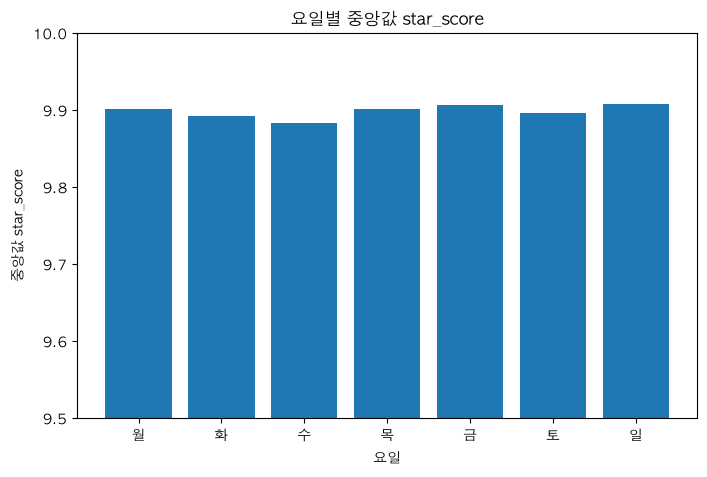

In [21]:
# ============================================================
# 13. 요일별 평균/중앙값 평점 시각화
# ============================================================

plt.figure(figsize=(8, 5))
plt.bar(weekday_score_summary.index, weekday_score_summary["mean"])
plt.title("요일별 평균 star_score")
plt.xlabel("요일")
plt.ylabel("평균 star_score")
plt.ylim(9.5, 10.0)
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(weekday_score_summary.index, weekday_score_summary["median"])
plt.title("요일별 중앙값 star_score")
plt.xlabel("요일")
plt.ylabel("중앙값 star_score")
plt.ylim(9.5, 10.0)
plt.show()

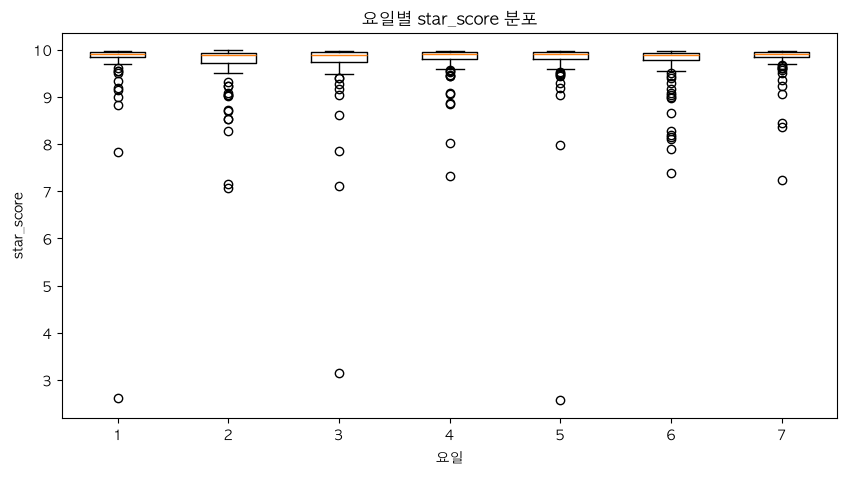

In [22]:
# ============================================================
# 14. 요일별 평점 분포 Boxplot
# ============================================================

data_by_weekday = [
    weekday_df.loc[weekday_df["weekday"] == day, "star_score"]
    for day in weekday_order
]

plt.figure(figsize=(10, 5))
plt.boxplot(data_by_weekday, label=[weekday_kor[x] for x in weekday_order])
plt.title("요일별 star_score 분포")
plt.xlabel("요일")
plt.ylabel("star_score")
plt.show()

In [23]:
# ============================================================
# 15. 요일별 평점 그룹 분포
# ============================================================
weekday_df = weekday_df.reset_index(drop=True)

weekday_score_group_table = pd.crosstab(
    weekday_df["weekday_kor"],
    weekday_df["score_group"],
    normalize="index"
)

# 요일 순서 정렬
weekday_score_group_table = weekday_score_group_table.reindex(
    [weekday_kor[x] for x in weekday_order]
)

display(weekday_score_group_table)

score_group,extreme_low(<5.0),low(8.0~9.0),normal(9.5~9.8),normal_high(>=9.8),very_low(5.0~8.0),watch(9.0~9.5)
weekday_kor,,,,,,
월,0.009434,0.018868,0.103774,0.820755,0.009434,0.037736
화,0.000000,0.045455,0.190909,0.681818,0.018182,0.063636
수,0.009804,0.009804,0.186275,0.705882,0.019608,0.068627
목,0.000000,0.030303,0.191919,0.717172,0.010101,0.050505
금,0.009174,0.000000,0.174312,0.743119,0.009174,0.064220
토,0.000000,0.064220,0.155963,0.706422,0.018349,0.055046
일,0.000000,0.020408,0.132653,0.806122,0.010204,0.030612


/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/4241271543.py:22: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  weekday_low_summary["clear_low_ratio"] = (
/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/4241

,total_count,clear_low_count,watch_count,normal_high_count,clear_low_ratio,watch_ratio,normal_high_ratio
월,106,4,4,87,0.037736,0.037736,0.820755
화,110,7,7,75,0.063636,0.063636,0.681818
수,102,4,7,72,0.039216,0.068627,0.705882
목,99,4,5,71,0.040404,0.050505,0.717172
금,109,2,7,81,0.018349,0.064220,0.743119
토,109,9,6,77,0.082569,0.055046,0.706422
일,98,3,3,79,0.030612,0.030612,0.806122


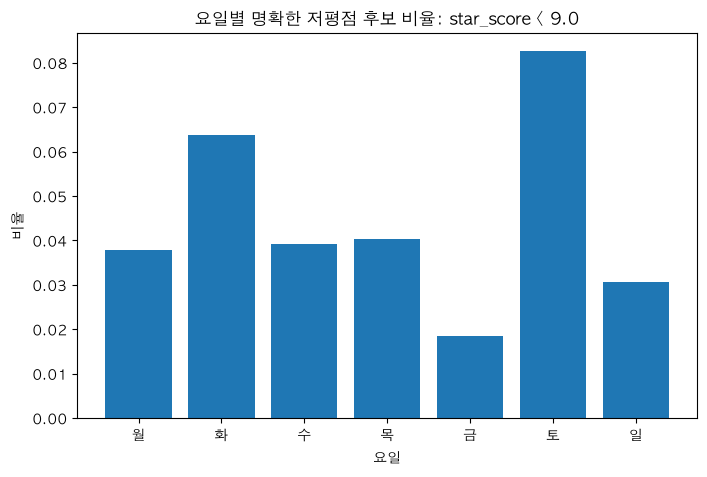

In [24]:
# ============================================================
# 16. 요일별 명확한 저평점 후보 비율
# ============================================================

weekday_low_summary = (
    weekday_df
    .assign(
        is_clear_low_score=weekday_df["star_score"] < 9.0,
        is_watch_score=(weekday_df["star_score"] >= 9.0) & (weekday_df["star_score"] < 9.5),
        is_normal_high=weekday_df["star_score"] >= 9.8
    )
    .groupby("weekday")
    .agg(
        total_count=("title_id", "count"),
        clear_low_count=("is_clear_low_score", "sum"),
        watch_count=("is_watch_score", "sum"),
        normal_high_count=("is_normal_high", "sum")
    )
    .reindex(weekday_order)
)

weekday_low_summary["clear_low_ratio"] = (
    weekday_low_summary["clear_low_count"] / weekday_low_summary["total_count"]
)

weekday_low_summary["watch_ratio"] = (
    weekday_low_summary["watch_count"] / weekday_low_summary["total_count"]
)

weekday_low_summary["normal_high_ratio"] = (
    weekday_low_summary["normal_high_count"] / weekday_low_summary["total_count"]
)

weekday_low_summary.index = [weekday_kor[x] for x in weekday_low_summary.index]

display(weekday_low_summary)

plt.figure(figsize=(8, 5))
plt.bar(weekday_low_summary.index, weekday_low_summary["clear_low_ratio"])
plt.title("요일별 명확한 저평점 후보 비율: star_score < 9.0")
plt.xlabel("요일")
plt.ylabel("비율")
plt.show()

/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/362155673.py:5: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  eda_df["weekday_count"] = eda_df["weekday_list"].str.split(",").apply(len)
/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7

,연재 유형,작품 수,비율
0,단일 요일,680,0.963173
1,복수 요일,26,0.036827


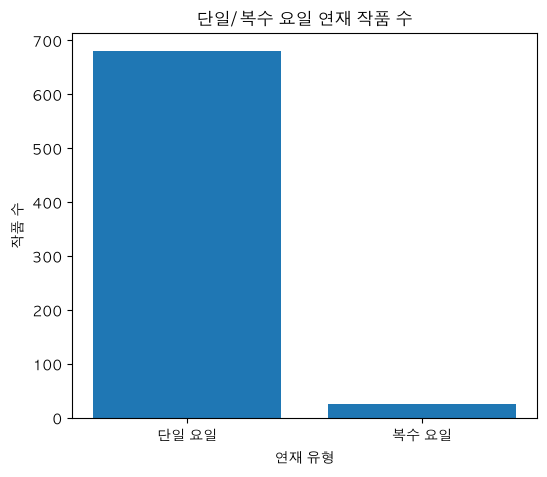

In [25]:
# ============================================================
# 17. 단일 요일 / 복수 요일 연재 여부 생성
# ============================================================

eda_df["weekday_count"] = eda_df["weekday_list"].str.split(",").apply(len)
eda_df["is_multi_weekday"] = eda_df["weekday_count"] >= 2

multi_counts = eda_df["is_multi_weekday"].value_counts().sort_index()

multi_table = pd.DataFrame({
    "연재 유형": ["단일 요일", "복수 요일"],
    "작품 수": [
        multi_counts.get(False, 0),
        multi_counts.get(True, 0)
    ]
})

multi_table["비율"] = multi_table["작품 수"] / len(eda_df)

display(multi_table)

plt.figure(figsize=(6, 5))
plt.bar(multi_table["연재 유형"], multi_table["작품 수"])
plt.title("단일/복수 요일 연재 작품 수")
plt.xlabel("연재 유형")
plt.ylabel("작품 수")
plt.show()

In [26]:
# ============================================================
# 18. 단일/복수 요일 연재별 평점 요약 통계
# ============================================================

multi_score_summary = (
    eda_df
    .groupby("is_multi_weekday")["star_score"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

multi_score_summary.index = ["단일 요일", "복수 요일"]

display(multi_score_summary)

,count,mean,median,std,min,max
단일 요일,680,9.738260,9.893635,0.610456,2.56687,9.98329
복수 요일,26,9.830549,9.923505,0.234292,9.06898,9.97648


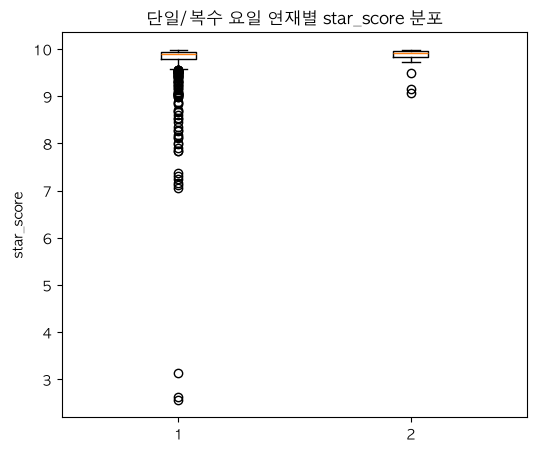

In [27]:
# ============================================================
# 19. 단일/복수 요일 연재별 평점 분포
# ============================================================

plt.figure(figsize=(6, 5))
plt.boxplot(
    [
        eda_df.loc[eda_df["is_multi_weekday"] == False, "star_score"],
        eda_df.loc[eda_df["is_multi_weekday"] == True, "star_score"]
    ],
    label=["단일 요일", "복수 요일"]
)
plt.title("단일/복수 요일 연재별 star_score 분포")
plt.ylabel("star_score")
plt.show()

In [28]:
# ============================================================
# 20. 단일/복수 요일 연재별 평점 그룹 분포
# ============================================================

multi_score_group_table = pd.crosstab(
    eda_df["is_multi_weekday"].map({False: "단일 요일", True: "복수 요일"}),
    eda_df["score_group"],
    normalize="index"
)

display(multi_score_group_table)

score_group,extreme_low(<5.0),low(8.0~9.0),normal(9.5~9.8),normal_high(>=9.8),very_low(5.0~8.0),watch(9.0~9.5)
is_multi_weekday,,,,,,
단일 요일,0.004412,0.029412,0.169118,0.733824,0.014706,0.048529
복수 요일,0.000000,0.000000,0.076923,0.807692,0.000000,0.115385


In [29]:
# ============================================================
# 21. 복수 요일 연재 작품 목록 확인
# ============================================================

multi_weekday_works = (
    eda_df.loc[
        eda_df["is_multi_weekday"],
        ["title_id", "title_name", "star_score", "is_new", "is_rest", "weekday_list", "weekday_count", "score_group"]
    ]
    .sort_values(["weekday_count", "star_score"], ascending=[False, False])
)

print("복수 요일 연재 작품 수:", len(multi_weekday_works))
display(multi_weekday_works)

복수 요일 연재 작품 수: 26


,title_id,title_name,star_score,is_new,is_rest,weekday_list,weekday_count,score_group
442,842647,용사파티만화,9.96264,False,False,"FRIDAY,SATURDAY,SUNDAY",3,normal_high(>=9.8)
144,817945,어린이집 다니는 구나,9.97648,False,False,"MONDAY,WEDNESDAY",2,normal_high(>=9.8)
94,804333,그냥 선생님,9.97122,False,False,"FRIDAY,TUESDAY",2,normal_high(>=9.8)
219,828292,개집사,9.97058,False,False,"FRIDAY,TUESDAY",2,normal_high(>=9.8)
113,812354,육아일기,9.96255,False,False,"SUNDAY,THURSDAY",2,normal_high(>=9.8)
516,845271,먹는 인생2,9.96253,False,False,"MONDAY,THURSDAY",2,normal_high(>=9.8)
476,843869,아가씨는 못말려,9.95573,False,False,"MONDAY,WEDNESDAY",2,normal_high(>=9.8)
408,841639,중대장은 실망했다,9.94052,False,False,"SATURDAY,WEDNESDAY",2,normal_high(>=9.8)
637,849676,생활의 참견 2 : 지금은 가족시절,9.93888,False,False,"FRIDAY,TUESDAY",2,normal_high(>=9.8)
187,823190,K학원 생존기,9.93849,False,False,"MONDAY,SATURDAY",2,normal_high(>=9.8)


/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/4256441973.py:15: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  new_table["비율"] = new_table["작품 수"] / len(eda_df)


,구분,작품 수,비율
0,기존작,668,0.946176
1,신작,38,0.053824


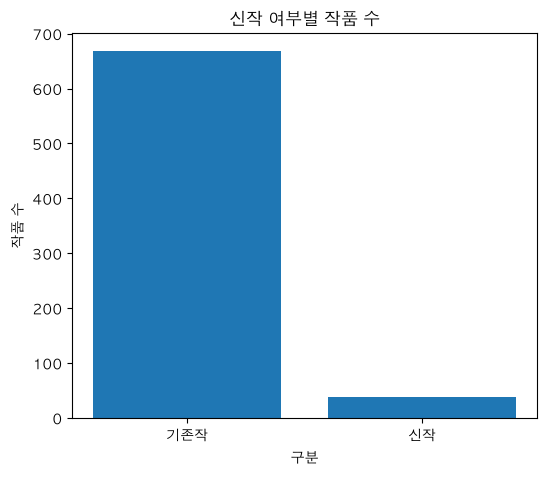

In [30]:
# ============================================================
# 22. 신작 여부별 작품 수
# ============================================================

new_counts = eda_df["is_new"].value_counts().sort_index()

new_table = pd.DataFrame({
    "구분": ["기존작", "신작"],
    "작품 수": [
        new_counts.get(False, 0),
        new_counts.get(True, 0)
    ]
})

new_table["비율"] = new_table["작품 수"] / len(eda_df)

display(new_table)

plt.figure(figsize=(6, 5))
plt.bar(new_table["구분"], new_table["작품 수"])
plt.title("신작 여부별 작품 수")
plt.xlabel("구분")
plt.ylabel("작품 수")
plt.show()

In [31]:
# ============================================================
# 23. 신작 여부별 평점 요약 통계
# ============================================================

new_score_summary = (
    eda_df
    .groupby("is_new")["star_score"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

new_score_summary.index = ["기존작", "신작"]

display(new_score_summary)

,count,mean,median,std,min,max
기존작,668,9.754680,9.898650,0.592710,2.56687,9.98329
신작,38,9.512748,9.846475,0.701237,7.06122,9.96260


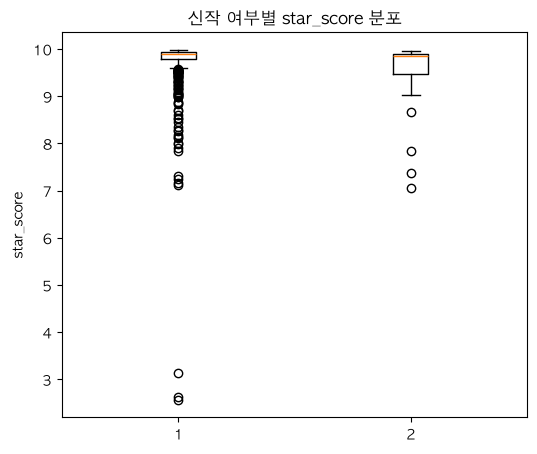

In [32]:
# ============================================================
# 24. 신작 여부별 평점 분포
# ============================================================

plt.figure(figsize=(6, 5))
plt.boxplot(
    [
        eda_df.loc[eda_df["is_new"] == False, "star_score"],
        eda_df.loc[eda_df["is_new"] == True, "star_score"]
    ],
    label=["기존작", "신작"]
)
plt.title("신작 여부별 star_score 분포")
plt.ylabel("star_score")
plt.show()

In [33]:
# ============================================================
# 25. 신작 여부별 평점 그룹 분포
# ============================================================

new_score_group_table = pd.crosstab(
    eda_df["is_new"].map({False: "기존작", True: "신작"}),
    eda_df["score_group"],
    normalize="index"
)

display(new_score_group_table)

score_group,extreme_low(<5.0),low(8.0~9.0),normal(9.5~9.8),normal_high(>=9.8),very_low(5.0~8.0),watch(9.0~9.5)
is_new,,,,,,
기존작,0.004491,0.028443,0.166168,0.747006,0.010479,0.043413
신작,0.000000,0.026316,0.157895,0.552632,0.078947,0.184211


/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/2313295234.py:15: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  weekday_new_summary["new_ratio"] = (


,total_count,new_count,new_ratio
월,106,4,0.037736
화,110,6,0.054545
수,102,7,0.068627
목,99,8,0.080808
금,109,5,0.045872
토,109,6,0.055046
일,98,5,0.051020


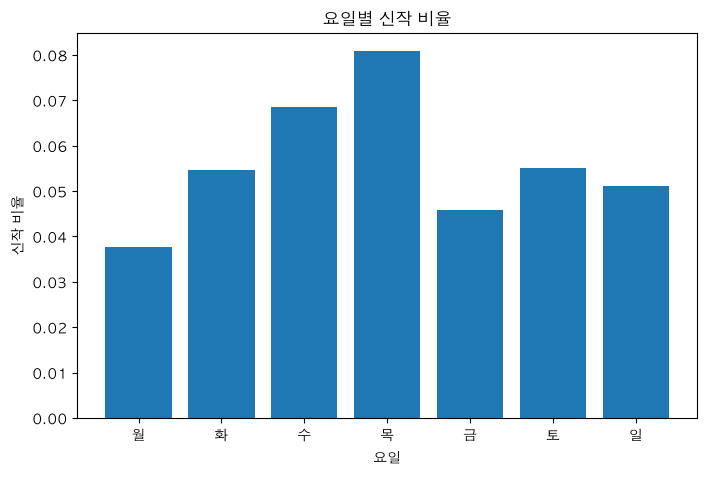

In [34]:
# ============================================================
# 26. 요일별 신작 수 및 비율
# ============================================================

weekday_new_summary = (
    weekday_df
    .groupby("weekday")
    .agg(
        total_count=("title_id", "count"),
        new_count=("is_new", "sum")
    )
    .reindex(weekday_order)
)

weekday_new_summary["new_ratio"] = (
    weekday_new_summary["new_count"] / weekday_new_summary["total_count"]
)

weekday_new_summary.index = [weekday_kor[x] for x in weekday_new_summary.index]

display(weekday_new_summary)

plt.figure(figsize=(8, 5))
plt.bar(weekday_new_summary.index, weekday_new_summary["new_ratio"])
plt.title("요일별 신작 비율")
plt.xlabel("요일")
plt.ylabel("신작 비율")
plt.show()

In [35]:
# ============================================================
# 27. 신작 목록 확인
# ============================================================

new_works = (
    eda_df.loc[
        eda_df["is_new"],
        ["title_id", "title_name", "star_score", "is_rest", "weekday_list", "weekday_count", "score_group"]
    ]
    .sort_values("star_score", ascending=False)
)

print("신작 수:", len(new_works))
display(new_works)

신작 수: 38


,title_id,title_name,star_score,is_rest,weekday_list,weekday_count,score_group
671,850546,맹종,9.96260,False,SUNDAY,1,normal_high(>=9.8)
687,850943,후키,9.95035,False,FRIDAY,1,normal_high(>=9.8)
692,850971,조상님이 보고계셔,9.93555,False,WEDNESDAY,1,normal_high(>=9.8)
690,850962,간병동맹,9.92852,False,THURSDAY,1,normal_high(>=9.8)
685,850928,같이 장볼래?,9.92043,False,"SUNDAY,THURSDAY",2,normal_high(>=9.8)
696,851264,쾌변일지,9.91240,False,WEDNESDAY,1,normal_high(>=9.8)
701,851503,동생 왔다,9.90952,False,"SATURDAY,TUESDAY",2,normal_high(>=9.8)
670,850505,드블리와 힐링합니다.,9.90866,False,SATURDAY,1,normal_high(>=9.8)
704,851705,밀실남녀,9.90714,False,SUNDAY,1,normal_high(>=9.8)
693,850976,만약은 없다,9.90545,False,FRIDAY,1,normal_high(>=9.8)


/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/4090978664.py:15: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  rest_table["비율"] = rest_table["작품 수"] / len(eda_df)


,구분,작품 수,비율
0,비휴재,668,0.946176
1,휴재,38,0.053824


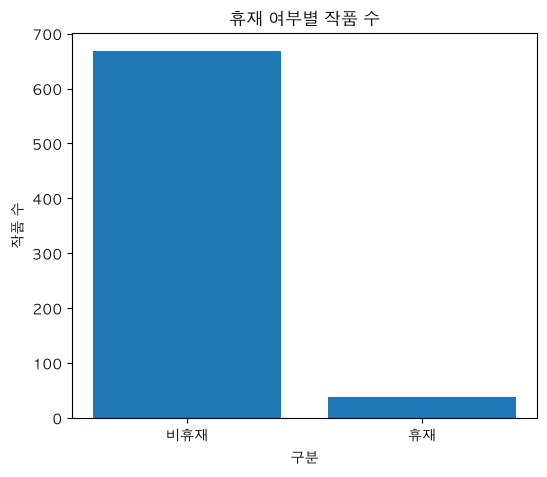

In [36]:
# ============================================================
# 28. 휴재 여부별 작품 수
# ============================================================

rest_counts = eda_df["is_rest"].value_counts().sort_index()

rest_table = pd.DataFrame({
    "구분": ["비휴재", "휴재"],
    "작품 수": [
        rest_counts.get(False, 0),
        rest_counts.get(True, 0)
    ]
})

rest_table["비율"] = rest_table["작품 수"] / len(eda_df)

display(rest_table)

plt.figure(figsize=(6, 5))
plt.bar(rest_table["구분"], rest_table["작품 수"])
plt.title("휴재 여부별 작품 수")
plt.xlabel("구분")
plt.ylabel("작품 수")
plt.show()

# Step 3. EDA 후 데이터 수집 코드

### 댓글 수집 객체

In [39]:
import time
from pathlib import Path
from typing import Any, Dict, List, Optional
from tqdm import tqdm

import pandas as pd
# import get_webtoon_weekly as gww

# 위의 객체를 상속받아 사용.
class NaverWebtoonCommentCollector(NaverWebtoonTitleCollector):
    def __init__(
        self,
        raw_dir: str = "data/raw",
        interim_dir: str = "data/interim/comments",
        log_dir: str = "data/logs",
        sleep_sec: float = 1.2, # ip 밴 당하지 않게 1.2초의 텀을 둔다.
        max_retries: int = 2,
    ):
        super().__init__(
            raw_dir=raw_dir,
            interim_dir=interim_dir,
            log_dir=log_dir,
            sleep_sec=sleep_sec,
            max_retries=max_retries
        )
        
    def get_episode_comments(self, title_id: int, no: int) -> Dict[str, Any]:
        """특정 회차(no)의 베스트 댓글(top-recent-posts)과 일반 댓글(posts)을 모두 요청하는 메서드"""
        
        page_id = f"webtoon_{title_id}_{no}"
        
        # 필수 인증(API Token 우회) 헤더 설정
        self.session.headers.update({
            "Referer": f"https://comic.naver.com/webtoon/detail?titleId={title_id}&no={no}",
            "service-ticket-id": "comic_webtoon",
            "service-type": "KW",
            "language": "KOREAN"
        })
        
        # 1. 베스트 댓글 (top-recent-posts) - v1 API 사용
        top_url = f"https://comic.naver.com/comment/api/community/v1/page/{page_id}/top-recent-posts"
        top_params = {
            "topCount": 15,
            "recentTopCount": 0,
            "pinRepresentation": "distinct"
        }
        
        # 2. 일반 댓글 (posts) - v2 API 사용 - 수집 제외 (프로젝트에서는 베스트 댓글만 수집 / 수집 시간도 배로 걸렸음..)
        posts_url = f"https://comic.naver.com/comment/api/community/v2/posts"
        posts_params = {
            "pageId": page_id,
            "categoryId": "",
            "pinRepresentation": "none",
            "pinType": "",
            "displayBlindCommentAsService": "false",
            "prevSize": 0,
            "nextSize": 20
        }
        
        # 각각 API 요청
        try:
            top_data = self.request_json(
                url=top_url,
                params=top_params,
                target=f"top_comment_{title_id}_{no}"
            )
        except Exception as e:
            print(f"[{title_id}-{no}] 베스트 댓글 요청 실패: {e}")
            top_data = {"error": str(e)}

        # 일반 댓글은 수집 제외(시간상/프로젝트 목적 상)
        # try:
        #     posts_data = self.request_json(
        #         url=posts_url,
        #         params=posts_params,
        #         target=f"posts_comment_{title_id}_{no}"
        #     )
        # except Exception as e:
        #     print(f"[{title_id}-{no}] 일반 댓글 요청 실패: {e}")
        #     posts_data = {"error": str(e)}
        
        # 두 개의 JSON을 하나의 딕셔너리로 묶어서 반환 -> 현재는 베스트 댓글만을 남김
        return {
            "top_recent_posts": top_data,
        }

    def get_latest_episode_no(self, title_id: int) -> Optional[int]:
        """해당 웹툰의 회차 목록 API를 호출하여 최신화(미리보기 포함) 번호(no)를 가져오기"""
        url = "https://comic.naver.com/api/article/list"
        params = {"titleId": title_id}
        
        try:
            data = self.request_json(url, params=params, target=f"article_list_{title_id}")
            article_list = data.get("articleList", [])
            charge_list = data.get("chargeFolderArticleList", [])
            
            all_articles = article_list + charge_list
            if all_articles:
                return max(article.get("no", 0) for article in all_articles)
        except Exception as e:
            print(f"[{title_id}] 최신화 번호를 가져오는 중 오류 발생: {e}")
        return None

    def collect_best_comments_for_title(self, title_id: int, max_episodes: Optional[int] = None) -> List[Dict[str, Any]]:
        """
        최신화 번호를 먼저 확인한 뒤, 1화부터 최신화까지 명확하게 순회하며 댓글을 수집.
        (중간에 결번이 있어도 에러 처리 후 건너뛰기)
        """
        latest_no = self.get_latest_episode_no(title_id)
        
        if not latest_no:
            print(f"[{title_id}] 최신화 번호를 찾을 수 없습니다. 수집을 종료합니다.")
            return []
            
        print(f"[{title_id}] 확인된 최신화 번호: {latest_no}")
        
        target_max_no = latest_no
        if max_episodes and max_episodes < latest_no: # 테스트를 위한 부분.. - 유료회차가 되는지 안되는지 검증
            target_max_no = max_episodes
            print(f"[{title_id}] 사용자가 지정한 최대 회차({max_episodes})까지만 수집합니다.")
            
        all_comments_data = []
        # target_max_no = max_episodes # 유료회차 되는지 테스트 하기 위해 추가
        
        for no in tqdm(range(1, target_max_no + 1), desc=f"[{title_id}] 댓글 수집", unit="화", leave=False):
            try:
                title_dir = self.raw_dir / str(title_id)
                comments_dir = title_dir / "comments"
                comments_dir.mkdir(parents=True, exist_ok=True)
                save_path = comments_dir / f"comments_{no}.json"
                
                # 이미 수집된 파일이 있는지 확인 - 단순 파일이 있는지 없는지만 확인하는 로직이라, 내용 오류는 여기서 체크 못함.
                if save_path.exists():
                    continue
                
                data = self.get_episode_comments(title_id, no)
                
                # API 응답 구조에 따라 데이터가 없는지 확인
                if not data or data.get("error"):
                    tqdm.write(f"[{title_id}] {no}화 데이터가 없습니다. 결번(삭제)이거나 에러입니다. 건너뜁니다.")
                    continue
                
                # 원본 JSON 저장
                self.save_json(data, save_path)
                
                all_comments_data.append({
                    "title_id": title_id,
                    "no": no,
                    "data": data
                })
                
            except Exception as e:
                tqdm.write(f"[{title_id}] {no}화 수집 중 오류 발생: {e}")
                tqdm.write(f"[{title_id}] 해당 회차를 건너뜁니다.")
                continue
                
        return all_comments_data

    def save_logs(self):
        path = self.log_dir / "comment_collection_log.json"
        self.save_json({"logs": self.logs}, path)


### 작가 정보 수집

In [40]:
import time
from pathlib import Path
from typing import Any, Dict, List

import pandas as pd
# import get_webtoon_weekly as gww


class NaverWebtoonInfoCollector(NaverWebtoonTitleCollector):
    def __init__(
        self,
        raw_dir: str = "data/raw",
        interim_dir: str = "data/interim/info",
        log_dir: str = "data/logs",
        sleep_sec: float = 1.0, # 수집하는 정보가 적어서 1초만 슬립..
        max_retries: int = 2,
    ):
        super().__init__(
            raw_dir=raw_dir,
            interim_dir=interim_dir,
            log_dir=log_dir,
            sleep_sec=sleep_sec,
            max_retries=max_retries
        )

    def get_webtoon_info(self, title_id: int) -> Dict[str, Any]:
        """웹툰의 기본 정보(작가, 소개, 태그)를 요청하는 메서드"""
        
        url = "https://comic.naver.com/api/article/list/info"
        params = {
            "titleId": title_id
        }
        
        self.session.headers.update({
            "Referer": f"https://comic.naver.com/webtoon/list?titleId={title_id}",
        })
        
        try:
            data = self.request_json(
                url=url,
                params=params,
                target=f"article_info_{title_id}"
            )
            return data
        except Exception as e:
            print(f"[{title_id}] 정보 요청 실패: {e}")
            return {"error": str(e)}

    def collect_info_for_title(self, title_id: int) -> pd.DataFrame:
        """
        웹툰 정보를 수집하여 DataFrame으로 반환한다
        - 시놉시스 정보 : 줄거리
        - 작가 정보 : 작가, 그림작가, 원작자 (요즘에는 여러 작가가 협업을 많이함 + 웹소설 원작도 꽤 많음)
        - 태그 정보 : 큐레이션 태그
        """
        info_data = self.get_webtoon_info(title_id)
        if not info_data or info_data.get("error"):
            print(f"[{title_id}] 데이터를 가져올 수 없습니다.")
            return pd.DataFrame()
            
        title_dir = self.raw_dir / str(title_id)
        info_dir = title_dir / "info"
        info_dir.mkdir(parents=True, exist_ok=True)
        self.save_json(info_data, info_dir / "info.json")
        
        # 정보 추출
        synopsis = info_data.get("synopsis", "")
        
        writers = []
        painters = []
        origin_authors = []
        
        artists = info_data.get("communityArtists", [])
        for artist in artists:
            name = artist.get("name", "")
            types = artist.get("artistTypeList", [])
            
            is_writer = False
            is_painter = False
            is_origin = False
            
            for t in types:
                t_upper = t.upper()
                if "WRITER" in t_upper and "ORIGIN" not in t_upper:
                    is_writer = True
                if "PAINTER" in t_upper:
                    is_painter = True
                if "ORIGIN" in t_upper:
                    is_origin = True
                    
            if is_writer:
                writers.append(name)
            if is_painter:
                painters.append(name)
            if is_origin:
                origin_authors.append(name)
                
        # 태그 추출
        tags = []
        curation_tags = info_data.get("curationTagList", [])
        for tag in curation_tags:
            tag_name = tag.get("tagName")
            if tag_name:
                tags.append(tag_name)
                
        row = {
            "title_id": title_id,
            "synopsis": synopsis,
            "writer": ", ".join(writers),
            "painter": ", ".join(painters),
            "origin_author": ", ".join(origin_authors),
            "tags": ", ".join(tags)
        }
        
        df = pd.DataFrame([row])
        return df

    def save_logs(self):
        path = self.log_dir / "info_collection_log.json"
        self.save_json({"logs": self.logs}, path)


### 별점 수집
- 각 회차별 별점 수집
- 각 회차별 독자의 반응(별점 참여 수, 좋아요 누른 수) 수집

In [41]:
import re
import time
from pathlib import Path
from typing import Any, Dict, List, Optional

import pandas as pd
from tqdm import tqdm
# import get_webtoon_weekly as gww


class NaverWebtoonStarCollector(NaverWebtoonTitleCollector):
    def __init__(
        self,
        raw_dir: str = "data/raw",
        interim_dir: str = "data/interim/stars",
        log_dir: str = "data/logs",
        sleep_sec: float = 1.0, 
        max_retries: int = 2,
    ):
        super().__init__(
            raw_dir=raw_dir,
            interim_dir=interim_dir,
            log_dir=log_dir,
            sleep_sec=sleep_sec,
            max_retries=max_retries
        )
        
    def get_episode_list_page(self, title_id: int, page: int) -> Dict[str, Any]:
        """특정 페이지(page)의 회차 목록을 요청하는 메서드"""
        
        url = "https://comic.naver.com/api/article/list"
        params = {
            "titleId": title_id,
            "page": page
        }
        
        self.session.headers.update({
            "Referer": f"https://comic.naver.com/webtoon/list?titleId={title_id}",
        })
        
        try:
            data = self.request_json(
                url=url,
                params=params,
                target=f"article_list_{title_id}_page_{page}"
            )
            return data
        except Exception as e:
            print(f"[{title_id}] 페이지 {page} 요청 실패: {e}")
            return {"error": str(e)}

    def collect_stars_for_title(self, title_id: int) -> List[Dict[str, Any]]:
        """
        해당 웹툰의 모든 회차 목록을 페이지별로 수집하여 -> 별점 원본 JSON으로 저장(1화부터 최신화까지)

        Returns
        -------
        list of dict
            articleList + chargeFolderArticleList 를 합친 전체 회차 dict 목록
        """
        all_articles = []
        all_pages_raw = []
        
        # 최신화가 몇화인지 알아내서 반복시키기
        first_page_data = self.get_episode_list_page(title_id, 1)
        if not first_page_data or first_page_data.get("error"):
            print(f"[{title_id}] 첫 페이지 데이터를 가져올 수 없습니다.")
            return []
            
        all_pages_raw.append(first_page_data)
        
        # 무료 회차 리스트
        article_list = first_page_data.get("articleList", [])
        # 미리보기(유료) 회차 리스트
        charge_folder_article_list = first_page_data.get("chargeFolderArticleList", [])
        
        all_articles.extend(article_list)
        all_articles.extend(charge_folder_article_list)
        
        page_info = first_page_data.get("pageInfo", {})
        total_pages = page_info.get("totalPages", 1)
        
        for page in tqdm(range(2, total_pages + 1), desc=f"[{title_id}] 회차 목록 수집"):
            page_data = self.get_episode_list_page(title_id, page)
            
            if not page_data or page_data.get("error"):
                print(f"[{title_id}] {page} 페이지 데이터가 없습니다.")
                continue
                
            all_pages_raw.append(page_data)
            
            all_articles.extend(page_data.get("articleList", []))
            all_articles.extend(page_data.get("chargeFolderArticleList", []))
            
        # 모든 페이지 데이터를 하나의 JSON 파일로 합쳐서 저장
        title_dir = self.raw_dir / str(title_id)
        stars_dir = title_dir / "stars"
        stars_dir.mkdir(parents=True, exist_ok=True)
        self.save_json({"pages": all_pages_raw}, stars_dir / "all_pages.json")
            
        if not all_articles:
            print(f"[{title_id}] 수집된 회차 정보가 없습니다.")
            return []
            
        return all_articles

    def get_episode_user_action(self, title_id: int, no: int) -> Dict[str, Any]:
        """
        특정 회차의 userAction 정보(좋아요 수, 별점 참여 인원 등)를 요청하는 함수.
        """
        url = "https://comic.naver.com/api/userAction/info"
        params = {
            "titleId": title_id,
            "no": no,
        }

        self.session.headers.update({
            "Referer": (
                f"https://comic.naver.com/webtoon/detail"
                f"?titleId={title_id}&no={no}"
            ),
        })

        try:
            data = self.request_json(
                url=url,
                params=params,
                target=f"user_action_{title_id}_no_{no}",
            )
            return data
        except Exception as e:
            return {"error": str(e)}

    def get_episode_like_count(self, title_id: int, no: int) -> int:
        """
        특정 회차의 좋아요 수를 가져오기.
        """
        url = "https://route-like.naver.com/v1/search/contents"
        params = {
            "suppress_response_codes": "true",
            "q": f"COMIC[{title_id}_{no}]",
            "isDuplication": "false",
            "cssIds": "BASIC_PC,COMIC_PC",
            "pool": "comic",
            "pq": f"COMIC[p_{title_id}]",
        }

        self.session.headers.update({
            "Referer": (
                f"https://comic.naver.com/webtoon/detail"
                f"?titleId={title_id}&no={no}"
            ),
            "Accept": "*/*",
            "Sec-Fetch-Dest": "script",
            "Sec-Fetch-Mode": "no-cors",
            "Sec-Fetch-Site": "same-site",
        })

        likes_dir = self.raw_dir / str(title_id) / "likes"
        likes_dir.mkdir(parents=True, exist_ok=True)

        try:
            resp = self.session.get(url, params=params, timeout=10)
            resp.raise_for_status()
            import json
            payload = json.loads(resp.text)
            # 원본 payload 저장
            # 구조: {"contents": [{"reactions": [{"reactionType": "like", "count": 123}]}]}
            contents = payload.get("contents", [])
            if contents:
                reactions = contents[0].get("reactions", [])
                for r in reactions:
                    if r.get("reactionType") == "like":
                        return int(r.get("count", 0))
            return 0
        except Exception as e: # 에러 메시지는 이번에는 출력 안함..
            return -1  # 실패 

    def collect_user_action_for_title(
        self,
        title_id: int,
        articles: Optional[List[Dict[str, Any]]] = None,
    ) -> List[Dict[str, Any]]:
        """
        지정한 웹툰의 모든 회차에 대해 userAction 정보(좋아요 수, 별점 참여 인원)를 수집
        """
        # 회차 목록이 없으면 새로 수집 - 단순 유무로 확인
        if articles is None:
            articles = self.collect_stars_for_title(title_id)

        if not articles:
            print(f"[{title_id}] 회차 목록이 비어 있어 userAction 수집을 건너뜁니다.")
            return []

        user_action_dir = self.raw_dir / str(title_id) / "user_action"
        user_action_dir.mkdir(parents=True, exist_ok=True)

        results: List[Dict[str, Any]] = []
        failed_nos: List[int] = []  # 실패한 회차 번호 누적

        for article in tqdm(articles, desc=f"[{title_id}] userAction 수집"):
            no = article.get("no")
            if no is None:
                continue

            data = self.get_episode_user_action(title_id, no)

            # userAction 실패 여부 체크
            ua_failed = bool(data.get("error"))

            # 핵심 필드만 추출해서 누적
            favorite_info = data.get("favoriteInfo") or {}
            star_info = data.get("starInfo") or {}

            # 좋아요 수: route-like.naver.com 엔드포인트에서 별도 요청
            like_count = self.get_episode_like_count(title_id, no)
            like_failed = like_count == -1 # 좋아요 수가 -1이면 실패로 간주 -> 아래의 조건문에서 걸림.

            if ua_failed or like_failed:
                failed_nos.append(no)

            row = {
                "title_id": title_id,
                "no": no,
                # 좋아요 수 (실패 시 None)
                "like_count": None if like_failed else like_count,
                # 관심웹툰 수: favoriteInfo.favoriteCount
                "interested_webtoon_count": favorite_info.get("favoriteCount"),
                # 별점 참여 인원: starInfo.starScoreCount
                "star_participant_count": star_info.get("starScoreCount"),
                "collected_at": time.strftime("%Y-%m-%d %H:%M:%S"),
            }
            results.append(row)

        # 수집 후 실패 회차 요약 출력
        if failed_nos:
            failed_sorted = sorted(failed_nos, reverse=True)
            print(f"[{title_id}] 요청 실패 회차 ({len(failed_nos)}개): {failed_sorted}")

        # 전체 결과를 하나의 JSON으로 저장
        self.save_json(
            {"title_id": title_id, "user_actions": results},
            user_action_dir / "all_user_actions.json",
        )

        return results

    def save_logs(self):
        path = self.log_dir / "star_collection_log.json"
        self.save_json({"logs": self.logs}, path)


### `works_base.csv`에서 웹툰 목록을 불러온 후 인원수 별로 파트를 분배하는 코드

In [42]:
import pandas as pd
import os

def get_my_webtoon_ids(num_parts: int, my_part: int, file_path: str = './data/works_base.csv') -> list:
    """
    CSV 파일에서 웹툰 id를 읽어 총 인원수대로 분배한 후,
    자신의 파트에 해당하는 웹툰 id 리스트를 반환
    (안 나눠 떨어지는 남은 분량은 마지막 사람에게 분배)
    
    :param num_parts: 몇 명이서 나눌 것인지 (총 인원수, int)
    :param my_part: 내가 몇 번째 파트인지 (1부터 시작하는 인덱스, int)
    :param file_path: 읽어올 csv 파일 경로 (기본값: './data/works_base.csv') <- 전체 웹툰 id가 들어있는 파일.
    :return: 내 파트에 할당된 웹툰 id 리스트
    """
    if not (1 <= my_part <= num_parts):
        raise ValueError("my_part는 1과 num_parts 사이의 값이어야 합니다.")
        
    # 파일이 없으면, 에러 출력
    if not os.path.exists(file_path): 
        raise FileNotFoundError(f"파일을 찾을 수 없습니다: {file_path}")

    # CSV 읽기
    df = pd.read_csv(file_path)
    
    # 웹툰 id 컬럼 식별 (title_id)
    if 'title_id' in df.columns:
        webtoon_ids = df['title_id'].tolist()
    else:
        # title_id가 없을 경우 가장 첫 번째 열을 id로 간주
        webtoon_ids = df.iloc[:, 0].tolist()
        
    total_webtoons = len(webtoon_ids)
    
    # 최대한 균등하게 나누기 위한 기본 몫
    base_count = total_webtoons // num_parts
    
    # 내 파트의 시작 인덱스
    start_idx = (my_part - 1) * base_count
    
    # 마지막 파트인 경우 남는 것(나머지)까지 모두 포함
    if my_part == num_parts:
        end_idx = total_webtoons
    else:
        end_idx = start_idx + base_count
        
    # 해당 인덱스의 아이디 리스트 반환
    return webtoon_ids[start_idx:end_idx]

### raw데이터로 수집한 파일 정제

In [43]:
import json
import re
import pandas as pd
from pathlib import Path
from typing import Union

ILLEGAL_EXCEL_CHARACTERS_RE = re.compile(r"[\x00-\x08\x0b-\x0c\x0e-\x1f]")


def clean_excel_value(value):
    if isinstance(value, str):
        return ILLEGAL_EXCEL_CHARACTERS_RE.sub("", value)
    return value


def clean_dataframe_for_excel(df: pd.DataFrame) -> pd.DataFrame:
    object_columns = df.select_dtypes(include=["object"]).columns
    if len(object_columns) == 0:
        return df

    df = df.copy()
    for column in object_columns:
        df[column] = df[column].map(clean_excel_value)
    return df


class NaverWebtoonDataParser:
    """
    수집된 JSON 원본 데이터(info, stars, comments)를 
    xlsx로 파싱하는 클래스
    """
    def __init__(self, raw_dir: str = "data/raw", interim_dir: str = "data/interim"):
        self.raw_dir = Path(raw_dir)
        self.interim_dir = Path(interim_dir)
        
        # 저장 디렉토리 세팅
        self.info_dir = self.interim_dir / "info"
        self.stars_dir = self.interim_dir / "stars"
        
        self.info_dir.mkdir(parents=True, exist_ok=True)
        self.stars_dir.mkdir(parents=True, exist_ok=True)

    def parse_info_to_excel(self, title_id: Union[str, int]) -> bool:
        """작품 정보 JSON 파일을 읽어 엑셀 파일로 저장"""
        title_id_str = str(title_id)
        json_path = self.raw_dir / title_id_str / "info" / "info.json"
        
        if not json_path.exists():
            return False
            
        with open(json_path, 'r', encoding='utf-8') as f:
            try:
                data = json.load(f)
            except json.JSONDecodeError:
                return False

        # 작가 정보 파싱
        writers = []
        painters = []
        origin_authors = []
        for artist in data.get("communityArtists", []):
            name = artist.get("name")
            types = artist.get("artistTypeList", [])
            if "ARTIST_WRITER" in types:
                writers.append(name)
            if "ARTIST_PAINTER" in types:
                painters.append(name)
            if "ARTIST_ORIGIN" in types:
                origin_authors.append(name)
                
        # 태그 및 장르 파싱
        gfp_param = data.get("gfpAdCustomParam", {})
        tags = gfp_param.get("tags", [])
        genres = gfp_param.get("genreTypes", [])
        
        row_data = {
            "title_id": int(title_id),
            "title_name": data.get("titleName", ""),
            "synopsis": data.get("synopsis", ""),
            "author_writer": ", ".join(writers) if writers else "None",
            "author_painter": ", ".join(painters) if painters else "None",
            "author_origin": ", ".join(origin_authors) if origin_authors else "None",
            "favorite_count": data.get("favoriteCount", 0),
            "age_rating": data.get("age", {}).get("description", "")
        }

        df = pd.DataFrame([row_data])
        df = clean_dataframe_for_excel(df)
        df.to_excel(self.info_dir / f"info_{title_id}.xlsx", index=False)
        
        if tags:
            df_tags = pd.DataFrame([{"title_id": int(title_id), "tag": tag} for tag in tags])
            df_tags = clean_dataframe_for_excel(df_tags)
            df_tags.to_excel(self.info_dir / f"info_tags_{title_id}.xlsx", index=False)
            
        if genres:
            df_genres = pd.DataFrame([{"title_id": int(title_id), "genre": genre} for genre in genres])
            df_genres = clean_dataframe_for_excel(df_genres)
            df_genres.to_excel(self.info_dir / f"info_genres_{title_id}.xlsx", index=False)

        return True

    def parse_stars_to_excel(self, title_id: Union[str, int]) -> int:
        """별점 JSON 파일을 읽어 하나의 엑셀 파일로 병합"""
        title_id_str = str(title_id)
        json_path = self.raw_dir / title_id_str / "stars" / "all_pages.json"
        
        if not json_path.exists():
            return 0
            
        with open(json_path, 'r', encoding='utf-8') as f:
            try:
                data = json.load(f)
            except json.JSONDecodeError:
                return 0

        all_extracted_data = []
        seen_no = set()

        for page_data in data.get("pages", []):
            articles = page_data.get("articleList", []) + page_data.get("chargeFolderArticleList", [])
            for article in articles:
                no = article.get("no")
                if no in seen_no:
                    continue
                seen_no.add(no)
                
                all_extracted_data.append({
                    "title_id": int(title_id),
                    "no": no,
                    "subtitle": article.get("subtitle", ""),
                    "star_score": article.get("starScore", 0.0),
                    "is_charge": article.get("charge", False),
                    "has_bgm": article.get("bgm", False),
                    "upload_date": article.get("serviceDateDescription", "")
                })

        if not all_extracted_data:
            return 0

        df = pd.DataFrame(all_extracted_data)
        df['upload_date'] = pd.to_datetime(df['upload_date'], format='%y.%m.%d', errors='coerce')
        df = df.sort_values(by='no', ascending=True)

        # user_action 데이터(좋아요 수, 별점 참여 인원, 별점 평균) 병합
        user_action_path = self.raw_dir / title_id_str / "user_action" / "all_user_actions.json"
        if user_action_path.exists():
            with open(user_action_path, 'r', encoding='utf-8') as f:
                try:
                    ua_data = json.load(f)
                except json.JSONDecodeError:
                    ua_data = {}

            ua_rows = ua_data.get("user_actions", [])
            if ua_rows:
                df_ua = pd.DataFrame(ua_rows)[[
                    "no", "like_count", "interested_webtoon_count", "star_participant_count"
                ]]
                df = df.merge(df_ua, on="no", how="left")

        df = clean_dataframe_for_excel(df)
        df.to_excel(self.stars_dir / f"stars_{title_id}.xlsx", index=False)
        return len(df)

    def parse_comments_to_excel(self, title_id: Union[str, int]) -> int:
        """여러 회차의 JSON 댓글 파일을 읽어 하나의 엑셀 파일로 병합"""
        title_id_str = str(title_id)
        folder_path = self.raw_dir / title_id_str / "comments"
        
        if not folder_path.exists():
            return 0
            
        # 개별 웹툰의 코멘트 저장 경로
        comments_output_dir = self.interim_dir / "comments" / title_id_str
        comments_output_dir.mkdir(parents=True, exist_ok=True)
        output_filename = comments_output_dir / f"webtoon_{title_id}_best_comments.xlsx"
        
        all_extracted_data = []

        for json_file in folder_path.glob("comments_*.json"):
            file_stem = json_file.stem
            try:
                ep_no = int(file_stem.split('_')[1])
            except ValueError:
                continue

            with open(json_file, 'r', encoding='utf-8') as f:
                try:
                    data = json.load(f)
                except json.JSONDecodeError:
                    continue
                    
            top_recent = data.get("top_recent_posts", {})
            if top_recent.get("status") != "success":
                continue
                
            result = top_recent.get("result", {})
            page_info = result.get("page", {})
            top_comments = result.get("tops", [])
            total_comments_in_ep = page_info.get("postCount", 0)

            for comment in top_comments:
                reactions = comment.get("reactions", [{}])[0].get("emotions", [])
                like_count = next((e["count"] for e in reactions if e["emotionId"] == "like"), 0)
                dislike_count = next((e["count"] for e in reactions if e["emotionId"] == "dislike"), 0)
                
                created_by = comment.get("createdBy", {})
                badge_list = created_by.get("badgeList", [])
                user_tier = badge_list[0].get("id") if badge_list else "NONE"
                
                all_extracted_data.append({
                    "title_id": int(title_id),
                    "no": ep_no,
                    "comment_id": comment.get("id"),
                    "user_masked_id": created_by.get("maskedUserId", "UNKNOWN"),
                    "user_tier": user_tier,
                    "body_text": comment.get("body", ""),
                    "like_count": like_count,
                    "dislike_count": dislike_count,
                    "reply_count": comment.get("activeChildPostCount", 0),
                    "created_at": comment.get("createdAt"),
                    "total_comments_in_ep": total_comments_in_ep
                })

        if not all_extracted_data:
            return 0

        df = pd.DataFrame(all_extracted_data)
        df['created_at'] = pd.to_datetime(df['created_at'], unit='ms') + pd.Timedelta(hours=9)
        df = df.sort_values(by=['no', 'like_count'], ascending=[True, False])
        
        df = clean_dataframe_for_excel(df)
        df.to_excel(output_filename, index=False)
        return len(df)
        
    def parse_all(self, title_id: Union[str, int]):
        """특정 웹툰의 모든 JSON 데이터를 파싱하고 요약 결과를 출력"""
        i_success = self.parse_info_to_excel(title_id)
        s_count = self.parse_stars_to_excel(title_id)  # user_action 병합 포함
        c_count = self.parse_comments_to_excel(title_id)

        print(
            f"[{title_id}] 정제 완료 - "
            f"정보: {'성공' if i_success else '실패'}, "
            f"별점(+userAction): {s_count}개, "
            f"댓글: {c_count}개"
        )


def save_webtoon_list_to_excel(title_id: Union[str, int]):
    parser = NaverWebtoonDataParser()
    parser.parse_all(title_id)



### 수집 일괄 실행 
#### 수집이 매우 오래걸리는 관계로 실제 실행 부분은 주석처리 하였습니다.(한번에 하면 며칠 소요) - 구글 드라이브에서 파일을 다운로드 받아주시면 감사하겠습니다.
실제 데이터 수집은 4명이서 나누어 작업을 하였습니다. 제출 코드는 혼자 돌릴때를 기준으로 수정하였습니다. (프로젝트에서는 아래의 예시처럼 사용합니다.)
```python
webtoon_ids = get_my_webtoon_ids(num_parts=4, my_part=1) # 4명이서 수집, 나는 첫 번째 파트...
```

In [ ]:
import sys
from pathlib import Path
from tqdm import tqdm

# 수집하고자 하는 웹툰 ID 리스트
webtoon_ids = get_my_webtoon_ids(num_parts=1, my_part=1) # 1명이 전체 파트를 수집 
# webtoon_ids = [837504]    # 테스트용

def main():
    
    print(f"총 {len(webtoon_ids)}개의 웹툰 데이터를 수집합니다.")
    print("=" * 50)
    
    # 각 수집기 객체 선언
    comment_collector = NaverWebtoonCommentCollector()
    star_collector = NaverWebtoonStarCollector()
    info_collector = NaverWebtoonInfoCollector()
    
    for title_id in tqdm(webtoon_ids, desc="전체 웹툰 수집 진행률", unit="웹툰"):
        print(f"\n>>> 웹툰 ID: {title_id} 수집 시작 <<<")
        
        # 1. 해당 웹툰의 댓글 수집
        print("\n[1/3] 댓글 수집 중...")
        try:
            collected_comments = comment_collector.collect_best_comments_for_title(title_id)
            print(f"[{title_id}] 총 {len(collected_comments)}개 회차의 댓글 수집 완료.")
        except Exception as e:
            print(f"[{title_id}] 댓글 수집 중 오류 발생: {e}")
            
        # 2. 해당 웹툰의 별점(회차 목록) 수집
        print("\n[2-1/3] 별점(회차 목록) 수집 중...")
        articles = []
        try:
            articles = star_collector.collect_stars_for_title(title_id)
            if articles:
                print(f"[{title_id}] 총 {len(articles)}개 회차의 별점 JSON 수집 완료")
            else:
                print(f"[{title_id}] 수집된 별점 데이터가 없습니다.")
        except Exception as e:
            print(f"[{title_id}] 별점 수집 중 오류 발생: {e}")

        # 2-2. 회차별 좋아요 수 & 별점 참여 인원 수집 (userAction)
        print("\n[2-2/3] 좋아요 수 & 별점 참여 인원 수집 중...")
        try:
            user_actions = star_collector.collect_user_action_for_title(
                title_id=title_id,
                articles=articles,  # 위에서 수집한 목록 재사용 (중복 요청 방지)
            )
            if user_actions:
                print(f"[{title_id}] 총 {len(user_actions)}개 회차의 좋아요·별점 참여 인원 수집 완료")
            else:
                print(f"[{title_id}] 수집된 userAction 데이터가 없습니다.")
        except Exception as e:
            print(f"[{title_id}] userAction 수집 중 오류 발생: {e}")
            
        # 3. 해당 웹툰의 작가/소개 정보 수집
        print("\n[3/3] 작가/소개, 작품 테그 정보 수집 중...")
        try:
            info_df = info_collector.collect_info_for_title(title_id)
            if not info_df.empty:
                interim_dir = Path("data/interim/info")
                interim_dir.mkdir(parents=True, exist_ok=True)
                csv_path = interim_dir / f"info_{title_id}.csv"
                info_df.to_csv(csv_path, index=False, encoding="utf-8-sig")
                print(f"[{title_id}] 작가/소개 정보 수집 완료 및 저장됨: {csv_path}")
            else:
                print(f"[{title_id}] 수집된 작가/소개 정보 데이터가 없습니다.")
        except Exception as e:
            print(f"[{title_id}] 작가/소개 정보 수집 중 오류 발생: {e}")
            
        print(f">>> 웹툰 ID: {title_id} 수집 완료 <<<\n")
        print("=" * 50)

    # 각 컬렉터별 로그 저장
    print("\n최종 수집 로그 저장 중...")
    comment_collector.save_logs()
    star_collector.save_logs()
    info_collector.save_logs()
    print("모든 수집 프로세스가 완료되었습니다.")

    # from tidyup_json import NaverWebtoonDataParser
    
    parser = NaverWebtoonDataParser()
    for title_id in webtoon_ids:
        parser.parse_all(title_id=title_id)
    
    print("데이터 정제 완료")

main() # 실제 수행시 주석 해제해주시면 됩니다.

총 1개의 웹툰 데이터를 수집합니다.


전체 웹툰 수집 진행률:   0%|          | 0/1 [00:00<?, ?웹툰/s]


>>> 웹툰 ID: 837504 수집 시작 <<<

[1/3] 댓글 수집 중...
[837504] 확인된 최신화 번호: 66


[837504] 총 66개 회차의 댓글 수집 완료.

[2-1/3] 별점(회차 목록) 수집 중...


[837504] 회차 목록 수집: 100%|██████████| 3/3 [00:03<00:00,  1.02s/it]


...

[837504] 요청 실패 회차 (3개): [66, 65, 64]
[837504] 총 66개 회차의 좋아요·별점 참여 인원 수집 완료

[3/3] 작가/소개, 작품 테그 정보 수집 중...


전체 웹툰 수집 진행률: 100%|██████████| 1/1 [02:45<00:00, 165.36s/웹툰]

[837504] 작가/소개 정보 수집 완료 및 저장됨: data/interim/info/info_837504.csv
>>> 웹툰 ID: 837504 수집 완료 <<<


최종 수집 로그 저장 중...
모든 수집 프로세스가 완료되었습니다.



/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/1113755658.py:23: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df[column] = df[column].map(clean_excel_value)
/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732

[837504] 정제 완료 - 정보: 성공, 별점(+userAction): 66개, 댓글: 976개
데이터 정제 완료


#### 수집 오류 대응
수집이 되게 길어서, 인터넷 문제로 인해서 혹시 제대로 받지 못한 데이터가 있을 수 있기 때문에 한번 확인을 하는 코드입니다.
##### 이 역시 최종 정제된 데이터를 받으시면 되기 때문에 실행 부분만 주석처리 해두었습니다.

In [46]:
import json
import sys
import argparse
from pathlib import Path
from typing import Any, Dict, List, Set

# from choose_webtoon_id import get_my_webtoon_ids

# 앞선 과정들이 전부 진행이 되고, `data/ 폴더 하에 raw, interim, works_base.csv`가 있어야 합니다.
# 수집한 데이터의 검증을 위한 부분입니다. (앞서서 수집할때, 회차 파일유무만 확인해서, 여기서는 내용을 한번 까보고, 빈 파일을 찾아 재수집을 합니다.)
PROJECT_ROOT = Path('./data')
DEFAULT_RAW_DIR = PROJECT_ROOT / "raw"
DEFAULT_INTERIM_DIR = PROJECT_ROOT / "interim"
DEFAULT_WORKS_BASE_PATH = PROJECT_ROOT / "works_base.csv"

REQUIRED_USER_ACTION_FIELDS = (
    "like_count",
    "interested_webtoon_count",
    "star_participant_count",
)


def load_json(path: Path) -> Dict[str, Any]:
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def save_json(data: Dict[str, Any], path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)


def get_free_episode_nos(webtoon_id: int, raw_dir: Path) -> List[int]:
    """
    저장된 회차 목록에서 무료 공개 회차(articleList)만 반환
    미리보기/유료 회차(chargeFolderArticleList)는 검증 대상에서 제외
    왜why? -> 미리보기 / 유료 회차는 API에서 요청응답을 제대로 주지 않는 경우를 확인
    => 무료분만을 분석에 활용하기로 함. 
    """
    stars_path = raw_dir / str(webtoon_id) / "stars" / "all_pages.json"
    data = load_json(stars_path)

    free_nos: Set[int] = set()
    for page in data.get("pages", []):
        for article in page.get("articleList", []):
            no = article.get("no")
            if isinstance(no, int):
                free_nos.add(no)

    return sorted(free_nos)


def is_valid_user_action(action: Dict[str, Any]) -> bool:
    if not action:
        return False

    for field in REQUIRED_USER_ACTION_FIELDS:
        if field not in action or action[field] is None:
            return False

    return True


def validate_user_actions(webtoon_id: int, free_nos: List[int], raw_dir: Path) -> Dict[str, List[int]]:
    user_action_path = raw_dir / str(webtoon_id) / "user_action" / "all_user_actions.json"
    if not user_action_path.exists():
        return {
            "missing": free_nos,
            "invalid": [],
        }

    try:
        data = load_json(user_action_path)
    except Exception:
        return {
            "missing": free_nos,
            "invalid": [],
        }

    actions_by_no = {
        action.get("no"): action
        for action in data.get("user_actions", [])
        if isinstance(action, dict) and isinstance(action.get("no"), int)
    }

    missing = []
    invalid = []
    for no in free_nos:
        action = actions_by_no.get(no)
        if action is None:
            missing.append(no)
        elif not is_valid_user_action(action):
            invalid.append(no)

    return {
        "missing": missing,
        "invalid": invalid,
    }


def is_valid_comment_file(path: Path) -> bool:
    if not path.exists():
        return False

    try:
        data = load_json(path)
    except Exception:
        return False

    top_recent_posts = data.get("top_recent_posts")
    if not isinstance(top_recent_posts, dict):
        return False

    if top_recent_posts.get("error"):
        return False

    return top_recent_posts.get("status") == "success"


def validate_comments(webtoon_id: int, free_nos: List[int], raw_dir: Path) -> Dict[str, List[int]]:
    comments_dir = raw_dir / str(webtoon_id) / "comments"

    missing = []
    invalid = []
    for no in free_nos:
        comment_path = comments_dir / f"comments_{no}.json"
        if not comment_path.exists():
            missing.append(no)
        elif not is_valid_comment_file(comment_path):
            invalid.append(no)

    return {
        "missing": missing,
        "invalid": invalid,
    }


def find_problem_episodes(webtoon_id: int, raw_dir: Path = DEFAULT_RAW_DIR) -> Dict[str, Any]:
    """
    미리보기를 제외한 무료 공개 회차 기준으로 episode-level 데이터 integrity 체크 (앞서 언급한 맥락과 같이 무료분만 확인)

    검증 대상:
    - stars/all_pages.json의 articleList에 포함된 무료 회차
    - user_action/all_user_actions.json 내 해당 회차 row와 핵심 필드
    - comments/comments_{no}.json 파일 존재와 정상 응답 상태
    """
    result: Dict[str, Any] = {
        "webtoon_id": webtoon_id,
        "free_episode_count": 0,
        "free_latest_no": None,
        "user_action": {"missing": [], "invalid": []},
        "comments": {"missing": [], "invalid": []},
        "blocked": [],
    }

    stars_path = raw_dir / str(webtoon_id) / "stars" / "all_pages.json"
    if not stars_path.exists():
        result["blocked"].append(f"회차 목록 파일 없음: {stars_path}")
        return result

    try:
        free_nos = get_free_episode_nos(webtoon_id, raw_dir)
    except Exception as e:
        result["blocked"].append(f"회차 목록 파일 읽기 오류: {e}")
        return result

    if not free_nos:
        result["blocked"].append("무료 공개 회차(articleList)를 찾을 수 없음")
        return result

    result["free_episode_count"] = len(free_nos)
    result["free_latest_no"] = max(free_nos)
    result["user_action"] = validate_user_actions(webtoon_id, free_nos, raw_dir)
    result["comments"] = validate_comments(webtoon_id, free_nos, raw_dir)

    return result


def get_retry_targets(result: Dict[str, Any]) -> Dict[str, List[int]]:
    user_action_targets = sorted(
        set(result["user_action"]["missing"]) | set(result["user_action"]["invalid"])
    )
    comment_targets = sorted(
        set(result["comments"]["missing"]) | set(result["comments"]["invalid"])
    )

    return {
        "user_action": user_action_targets,
        "comments": comment_targets,
    }


def has_problem(result: Dict[str, Any]) -> bool:
    targets = get_retry_targets(result)
    return bool(result["blocked"] or targets["user_action"] or targets["comments"])


def print_result(result: Dict[str, Any]) -> None:
    webtoon_id = result["webtoon_id"]
    print(f"=== 웹툰 ID: {webtoon_id} ===")

    if result["blocked"]:
        print("검증 불가:")
        for message in result["blocked"]:
            print(f"- {message}")
        return

    print(f"무료 최신화: {result['free_latest_no']}화")
    print(f"검증 대상 무료 회차 수: {result['free_episode_count']}개")

    user_action = result["user_action"]
    comments = result["comments"]

    if user_action["missing"]:
        print(f"user_action 누락 회차 ({len(user_action['missing'])}개): {user_action['missing']}")
    if user_action["invalid"]:
        print(f"user_action 오류/불완전 회차 ({len(user_action['invalid'])}개): {user_action['invalid']}")
    if comments["missing"]:
        print(f"댓글 누락 회차 ({len(comments['missing'])}개): {comments['missing']}")
    if comments["invalid"]:
        print(f"댓글 오류/불완전 회차 ({len(comments['invalid'])}개): {comments['invalid']}")

    if not has_problem(result):
        print("무료 공개 회차 기준으로 모든 episode-level 데이터가 정상 수집되어 있습니다.")


def retry_user_actions(webtoon_id: int, episode_nos: List[int], raw_dir: Path) -> None:
    from get_stars_webtoon import NaverWebtoonStarCollector

    if not episode_nos:
        return

    star_collector = NaverWebtoonStarCollector(raw_dir=str(raw_dir))
    articles = [{"no": no} for no in episode_nos]
    user_action_path = raw_dir / str(webtoon_id) / "user_action" / "all_user_actions.json"

    original_actions = []
    if user_action_path.exists():
        try:
            original_actions = load_json(user_action_path).get("user_actions", [])
        except Exception:
            original_actions = []

    new_actions = star_collector.collect_user_action_for_title(title_id=webtoon_id, articles=articles)

    action_by_no = {
        action.get("no"): action
        for action in original_actions + new_actions
        if isinstance(action, dict) and isinstance(action.get("no"), int)
    }
    merged_actions = [action_by_no[no] for no in sorted(action_by_no.keys())]
    save_json({"title_id": webtoon_id, "user_actions": merged_actions}, user_action_path)
    print(f"[{webtoon_id}] user_action 재수집/병합 완료: {episode_nos}")


def retry_comments(webtoon_id: int, episode_nos: List[int], raw_dir: Path) -> None:
    from get_comment_webtoon import NaverWebtoonCommentCollector

    if not episode_nos:
        return

    comment_collector = NaverWebtoonCommentCollector(raw_dir=str(raw_dir))
    comments_dir = raw_dir / str(webtoon_id) / "comments"
    comments_dir.mkdir(parents=True, exist_ok=True)

    failed = []
    for no in episode_nos:
        data = comment_collector.get_episode_comments(webtoon_id, no)
        save_path = comments_dir / f"comments_{no}.json"
        save_json(data, save_path)
        if not is_valid_comment_file(save_path):
            failed.append(no)

    if failed:
        print(f"[{webtoon_id}] 댓글 재수집 후에도 오류/불완전 회차: {failed}")
    else:
        print(f"[{webtoon_id}] 댓글 재수집 완료: {episode_nos}")


def has_interim_outputs(webtoon_id: int, interim_dir: Path) -> bool:
    title_id = str(webtoon_id)
    info_xlsx = interim_dir / "info" / f"info_{title_id}.xlsx"
    info_csv = interim_dir / "info" / f"info_{title_id}.csv"
    stars_xlsx = interim_dir / "stars" / f"stars_{title_id}.xlsx"
    comments_xlsx = interim_dir / "comments" / title_id / f"webtoon_{title_id}_best_comments.xlsx"

    return (info_xlsx.exists() or info_csv.exists()) and stars_xlsx.exists() and comments_xlsx.exists()


def update_interim_outputs(
    webtoon_ids: List[int],
    raw_dir: Path,
    interim_dir: Path,
    force_webtoon_ids: Set[int],
) -> None:
    from tidyup_json import NaverWebtoonDataParser

    target_ids = [
        webtoon_id
        for webtoon_id in webtoon_ids
        if webtoon_id in force_webtoon_ids or not has_interim_outputs(webtoon_id, interim_dir)
    ]

    if not target_ids:
        print("interim 정제 갱신 대상이 없습니다.")
        return

    parser = NaverWebtoonDataParser(raw_dir=str(raw_dir), interim_dir=str(interim_dir))
    failed = []

    print(f"interim 정제 파일 갱신 시작 ({len(target_ids)}개)")
    for webtoon_id in target_ids:
        try:
            parser.parse_all(title_id=webtoon_id)
        except Exception as e:
            failed.append(webtoon_id)
            print(f"[{webtoon_id}] interim 정제 실패: {e}")

    if failed:
        print(f"interim 정제 실패 웹툰 ({len(failed)}개): {failed}")
    else:
        print("interim 정제 파일 갱신 완료")


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(
        description="미리보기 회차를 제외하고 무료 공개 회차의 수집 무결성을 검증합니다."
    )
    parser.add_argument("webtoon_ids", nargs="*", type=int, help="검증할 웹툰 ID")
    parser.add_argument("--raw-dir", default=None, help="raw 데이터 디렉터리")
    parser.add_argument("--interim-dir", default=None, help="interim 데이터 디렉터리")
    parser.add_argument("--num-parts", type=int, default=4, help="분할 수")
    parser.add_argument("--my-part", type=int, default=1, help="검증할 분할 번호")
    parser.add_argument("--retry", action="store_true", help="문제가 있는 회차만 재수집")
    parser.add_argument(
        "--skip-interim-update",
        action="store_true",
        help="--retry 후 tidyup_json.py를 이용한 interim 갱신을 건너뜀",
    )
    if 'ipykernel' in sys.modules:
        # Jupyter 내부 인자를 무시하고, 기본값(default)들만 사용하여 파싱
        args, _ = parser.parse_known_args(args=[])
        return args
    else:
        # 터미널에서는 정상적으로 파싱
        return parser.parse_args()

def integrity_check(): # 이곳이 메인 루프
    args = parse_args()
    raw_dir = Path(args.raw_dir) if args.raw_dir else DEFAULT_RAW_DIR
    interim_dir = Path(args.interim_dir) if args.interim_dir else DEFAULT_INTERIM_DIR
    # webtoon_ids = args.webtoon_ids or get_my_webtoon_ids(
    #     num_parts=args.num_parts,
    #     my_part=args.my_part,
    #     file_path=str(DEFAULT_WORKS_BASE_PATH),
    # )

    problem_results = []
    for webtoon_id in webtoon_ids:
        result = find_problem_episodes(webtoon_id, raw_dir=raw_dir)
        print_result(result)
        if has_problem(result):
            problem_results.append(result)

    summary = {}
    for result in problem_results:
        if result["blocked"]:
            summary[result["webtoon_id"]] = {"blocked": result["blocked"]}
            continue
        targets = get_retry_targets(result)
        summary[result["webtoon_id"]] = targets

    print("문제 회차 요약:", summary)

    if args.retry:
        for result in problem_results:
            if result["blocked"]:
                print(f"[{result['webtoon_id']}] 검증 불가 상태라 재수집을 건너뜁니다.")
                continue
            targets = get_retry_targets(result)
            retry_user_actions(result["webtoon_id"], targets["user_action"], raw_dir)
            retry_comments(result["webtoon_id"], targets["comments"], raw_dir)

        if not args.skip_interim_update:
            retry_webtoon_ids = {
                result["webtoon_id"]
                for result in problem_results
                if not result["blocked"]
            }
            update_interim_outputs(webtoon_ids, raw_dir, interim_dir, retry_webtoon_ids)


integrity_check() # 메인 루프 실행 - 실제 실행시 주석 해제해주시면 됩니다. 

=== 웹툰 ID: 837504 ===
무료 최신화: 63화
검증 대상 무료 회차 수: 63개
무료 공개 회차 기준으로 모든 episode-level 데이터가 정상 수집되어 있습니다.
문제 회차 요약: {}


# Step 4. 수집한 데이터 정제
이 코드의 결과 역시 역시 구글 드라이브로 다운받으신 폴더 안에 결과물이 포함되어 있습니다.

In [47]:
from pathlib import Path
import json
import re
import warnings

import pandas as pd
from tqdm import tqdm


BASE_DIR = Path("./data")
INTERIM_DIR = BASE_DIR / "interim"
PROCESSED_DIR = BASE_DIR / "processed" # 이 안에 각 parquet 파일들을 저장
LOG_DIR = BASE_DIR / "logs"

COMMENTS_OUT_DIR = PROCESSED_DIR / "comments"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
COMMENTS_OUT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)


def read_excel_safe(path: Path) -> pd.DataFrame:
    try:
        return pd.read_excel(path)
    except Exception as e:
        warnings.warn(f"Failed to read {path}: {e}")
        return pd.DataFrame()


def normalize_title_id(s: pd.Series) -> pd.Series:
    return s.astype("string").str.strip()


def normalize_text_series(s: pd.Series) -> pd.Series:
    return s.astype("string").str.strip()


def to_numeric_series(s: pd.Series):
    return pd.to_numeric(s, errors="coerce")


def to_bool_series(s: pd.Series) -> pd.Series:
    """
    True/False, TRUE/FALSE, 1/0, 'true'/'false' 등을 최대한 boolean으로 변환.
    변환 불가 값은 pandas nullable boolean의 NA로 남김.
    """
    if s.dtype == bool:
        return s.astype("boolean")

    x = s.astype("string").str.strip().str.lower()

    mapping = {
        "true": True,
        "false": False,
        "1": True,
        "0": False,
        "yes": True,
        "no": False,
        "y": True,
        "n": False,
        "t": True,
        "f": False,
    }

    return x.map(mapping).astype("boolean")


def extract_title_id_from_filename(path: Path) -> str | None:
    m = re.search(r"(\d+)", path.stem)
    return m.group(1) if m else None


def save_log_csv(df: pd.DataFrame, filename: str):
    path = LOG_DIR / filename
    df.to_csv(path, index=False, encoding="utf-8-sig")


def build_works_base() -> pd.DataFrame:
    src = INTERIM_DIR / "works_base.csv"
    if not src.exists():
        raise FileNotFoundError(f"works_base.csv not found: {src}")

    df = pd.read_csv(src)

    if "title_id" not in df.columns:
        raise ValueError("works_base.csv must contain title_id column")

    before = len(df)

    df["title_id"] = normalize_title_id(df["title_id"])
    df = df[df["title_id"].notna()]
    df = df[df["title_id"] != ""]
    df = df[df["title_id"].str.lower() != "nan"]

    duplicated = df[df.duplicated(subset=["title_id"], keep=False)].copy()
    if len(duplicated) > 0:
        save_log_csv(duplicated, "works_base_duplicated_title_id.csv")

    df = df.drop_duplicates(subset=["title_id"], keep="first").copy()

    df.to_parquet(PROCESSED_DIR / "works_base.parquet", index=False)

    summary = {
        "works_base_raw_rows": before,
        "works_base_processed_rows": len(df),
        "works_base_removed_rows": before - len(df),
        "works_base_unique_title_ids": df["title_id"].nunique(),
    }

    return df, summary


def build_webtoon_info() -> tuple[pd.DataFrame, dict]:
    files = sorted((INTERIM_DIR / "info").glob("info_*.xlsx"))
    files = [
        f for f in files
        if not f.name.startswith("info_tags_") and not f.name.startswith("info_genres_")
    ]

    rows = []
    read_failed = []

    for path in tqdm(files, desc="webtoon_info"):
        df = read_excel_safe(path)
        if df.empty:
            read_failed.append({"file": str(path), "reason": "empty_or_read_failed"})
            continue

        file_title_id = extract_title_id_from_filename(path)

        if "title_id" not in df.columns:
            df["title_id"] = file_title_id

        if len(df) > 1:
            # info 파일은 원칙적으로 1 row여야 하므로 로그만 남기고 모두 유지
            pass

        rows.append(df)

    if rows:
        out = pd.concat(rows, ignore_index=True)
    else:
        out = pd.DataFrame()

    if not out.empty:
        out["title_id"] = normalize_title_id(out["title_id"])

        for col in ["title_name", "synopsis", "author_writer", "author_painter", "author_origin", "age_rating"]:
            if col in out.columns:
                out[col] = normalize_text_series(out[col])
                out[col] = out[col].replace({"None": pd.NA, "none": pd.NA, "": pd.NA})

        if "favorite_count" in out.columns:
            out["favorite_count"] = to_numeric_series(out["favorite_count"])

        duplicated = out[out.duplicated(subset=["title_id"], keep=False)].copy()
        if len(duplicated) > 0:
            save_log_csv(duplicated, "webtoon_info_duplicated_title_id.csv")

        out = out.drop_duplicates(subset=["title_id"], keep="first").copy()

    out.to_parquet(PROCESSED_DIR / "webtoon_info.parquet", index=False)

    if read_failed:
        save_log_csv(pd.DataFrame(read_failed), "webtoon_info_read_failed.csv")

    summary = {
        "webtoon_info_files": len(files),
        "webtoon_info_rows": len(out),
        "webtoon_info_unique_title_ids": out["title_id"].nunique() if "title_id" in out.columns else 0,
        "webtoon_info_read_failed_files": len(read_failed),
    }

    return out, summary


def build_webtoon_tags() -> tuple[pd.DataFrame, dict]:
    files = sorted((INTERIM_DIR / "info").glob("info_tags_*.xlsx"))
    rows = []
    read_failed = []

    for path in tqdm(files, desc="webtoon_tags"):
        df = read_excel_safe(path)
        if df.empty:
            read_failed.append({"file": str(path), "reason": "empty_or_read_failed"})
            continue

        file_title_id = extract_title_id_from_filename(path)
        if "title_id" not in df.columns:
            df["title_id"] = file_title_id

        rows.append(df)

    out = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

    if not out.empty:
        out["title_id"] = normalize_title_id(out["title_id"])

        if "tag" in out.columns:
            out["tag"] = normalize_text_series(out["tag"])
            out = out[out["tag"].notna()]
            out = out[out["tag"] != ""]
        else:
            raise ValueError("tag column not found in info_tags files")

        out = out.drop_duplicates(subset=["title_id", "tag"], keep="first").copy()

    out.to_parquet(PROCESSED_DIR / "webtoon_tags.parquet", index=False)

    if read_failed:
        save_log_csv(pd.DataFrame(read_failed), "webtoon_tags_read_failed.csv")

    summary = {
        "webtoon_tags_files": len(files),
        "webtoon_tags_rows": len(out),
        "webtoon_tags_unique_title_ids": out["title_id"].nunique() if "title_id" in out.columns else 0,
        "webtoon_tags_unique_tags": out["tag"].nunique() if "tag" in out.columns else 0,
        "webtoon_tags_read_failed_files": len(read_failed),
    }

    return out, summary


def build_webtoon_genres() -> tuple[pd.DataFrame, dict]:
    files = sorted((INTERIM_DIR / "info").glob("info_genres_*.xlsx"))
    rows = []
    read_failed = []

    for path in tqdm(files, desc="webtoon_genres"):
        df = read_excel_safe(path)
        if df.empty:
            read_failed.append({"file": str(path), "reason": "empty_or_read_failed"})
            continue

        file_title_id = extract_title_id_from_filename(path)
        if "title_id" not in df.columns:
            df["title_id"] = file_title_id

        rows.append(df)

    out = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

    if not out.empty:
        out["title_id"] = normalize_title_id(out["title_id"])

        if "genre" in out.columns:
            out["genre"] = normalize_text_series(out["genre"])
            out = out[out["genre"].notna()]
            out = out[out["genre"] != ""]
        else:
            raise ValueError("genre column not found in info_genres files")

        out = out.drop_duplicates(subset=["title_id", "genre"], keep="first").copy()

        genre_count = (
            out.groupby("title_id")["genre"]
            .nunique()
            .reset_index(name="genre_count")
        )
        multi_genre = genre_count[genre_count["genre_count"] > 1].copy()
        if len(multi_genre) > 0:
            save_log_csv(multi_genre, "webtoon_genres_multi_genre_title_ids.csv")

    out.to_parquet(PROCESSED_DIR / "webtoon_genres.parquet", index=False)

    if read_failed:
        save_log_csv(pd.DataFrame(read_failed), "webtoon_genres_read_failed.csv")

    summary = {
        "webtoon_genres_files": len(files),
        "webtoon_genres_rows": len(out),
        "webtoon_genres_unique_title_ids": out["title_id"].nunique() if "title_id" in out.columns else 0,
        "webtoon_genres_unique_genres": out["genre"].nunique() if "genre" in out.columns else 0,
        "webtoon_genres_read_failed_files": len(read_failed),
    }

    return out, summary


def build_episodes() -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    files = sorted((INTERIM_DIR / "stars").glob("stars_*.xlsx"))
    rows = []
    read_failed = []

    for path in tqdm(files, desc="episodes"):
        df = read_excel_safe(path)
        if df.empty:
            read_failed.append({"file": str(path), "reason": "empty_or_read_failed"})
            continue

        file_title_id = extract_title_id_from_filename(path)
        if "title_id" not in df.columns:
            df["title_id"] = file_title_id

        rows.append(df)

    raw = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

    if raw.empty:
        raw.to_parquet(PROCESSED_DIR / "episodes.parquet", index=False)
        return raw, raw, {"episodes_raw_rows": 0, "episodes_free_rows": 0}

    raw["title_id"] = normalize_title_id(raw["title_id"])

    if "no" in raw.columns:
        raw["no"] = pd.to_numeric(raw["no"], errors="coerce").astype("Int64")
    else:
        raise ValueError("no column not found in stars files")

    if "subtitle" in raw.columns:
        raw["subtitle"] = normalize_text_series(raw["subtitle"])

    for col in ["star_score", "like_count", "interested_webtoon_count", "star_participant_count"]:
        if col in raw.columns:
            raw[col] = to_numeric_series(raw[col])

    if "is_charge" in raw.columns:
        raw["is_charge"] = to_bool_series(raw["is_charge"])
    else:
        raise ValueError("is_charge column not found in stars files")

    if "has_bgm" in raw.columns:
        raw["has_bgm"] = to_bool_series(raw["has_bgm"])

    if "upload_date" in raw.columns:
        raw["upload_date"] = pd.to_datetime(raw["upload_date"], errors="coerce")

    duplicated = raw[raw.duplicated(subset=["title_id", "no"], keep=False)].copy()
    if len(duplicated) > 0:
        save_log_csv(duplicated, "episodes_duplicated_title_id_no.csv")

    # 같은 회차가 중복이면 우선 첫 번째 row 유지
    raw = raw.drop_duplicates(subset=["title_id", "no"], keep="first").copy()

    # 무료회차만 processed episodes에 저장
    free = raw[raw["is_charge"] == False].copy()
    free = free.sort_values(["title_id", "no"]).reset_index(drop=True)

    free.to_parquet(PROCESSED_DIR / "episodes.parquet", index=False)

    # 유료회차 제거 로그
    charge_removed = raw[raw["is_charge"] == True].copy()
    if len(charge_removed) > 0:
        save_log_csv(charge_removed[["title_id", "no", "is_charge"]], "episodes_charge_removed.csv")

    if read_failed:
        save_log_csv(pd.DataFrame(read_failed), "episodes_read_failed.csv")

    summary = {
        "episodes_files": len(files),
        "episodes_raw_rows": len(raw),
        "episodes_free_rows": len(free),
        "episodes_charge_rows": int((raw["is_charge"] == True).sum()),
        "episodes_unknown_charge_rows": int(raw["is_charge"].isna().sum()),
        "episodes_unique_title_ids_raw": raw["title_id"].nunique(),
        "episodes_unique_title_ids_free": free["title_id"].nunique(),
        "episodes_read_failed_files": len(read_failed),
    }

    return raw, free, summary


def build_comments_by_title(episodes_free: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    comments_root = INTERIM_DIR / "comments"
    files = sorted(comments_root.glob("*/webtoon_*_best_comments.xlsx"))

    if episodes_free.empty:
        free_keys = pd.DataFrame(columns=["title_id", "no"])
    else:
        free_keys = episodes_free[["title_id", "no"]].drop_duplicates().copy()

    status_rows = []
    read_failed = []
    missing_episode_key_rows = []

    total_raw_rows = 0
    total_after_filter_rows = 0
    total_removed_rows = 0

    for path in tqdm(files, desc="comments"):
        df = read_excel_safe(path)
        file_title_id = extract_title_id_from_filename(path)

        if df.empty:
            status_rows.append({
                "title_id": str(file_title_id),
                "comment_file": str(path),
                "raw_comment_rows": 0,
                "after_charge_filter_comment_rows": 0,
                "removed_comment_rows": 0,
                "status": "empty_or_read_failed",
            })
            read_failed.append({"file": str(path), "reason": "empty_or_read_failed"})
            continue

        if "title_id" not in df.columns:
            df["title_id"] = file_title_id

        df["title_id"] = normalize_title_id(df["title_id"])

        if "no" not in df.columns:
            raise ValueError(f"no column not found in {path}")

        df["no"] = pd.to_numeric(df["no"], errors="coerce").astype("Int64")

        if "comment_id" in df.columns:
            df["comment_id"] = normalize_text_series(df["comment_id"])
        else:
            raise ValueError(f"comment_id column not found in {path}")

        for col in ["user_masked_id", "user_tier", "body_text"]:
            if col in df.columns:
                df[col] = normalize_text_series(df[col])

        if "body_text" in df.columns:
            df = df[df["body_text"].notna()]
            df = df[df["body_text"] != ""]

        for col in ["like_count", "dislike_count", "reply_count", "total_comments_in_ep"]:
            if col in df.columns:
                df[col] = to_numeric_series(df[col])

        if "created_at" in df.columns:
            df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce")

        duplicated = df[df.duplicated(subset=["title_id", "no", "comment_id"], keep=False)].copy()
        if len(duplicated) > 0:
            dup_log_path = LOG_DIR / f"comments_duplicated_{file_title_id}.csv"
            duplicated.to_csv(dup_log_path, index=False, encoding="utf-8-sig")

        df = df.drop_duplicates(subset=["title_id", "no", "comment_id"], keep="first").copy()

        raw_rows = len(df)
        total_raw_rows += raw_rows

        # episodes_free에 존재하는 title_id + no만 유지
        filtered = df.merge(free_keys, on=["title_id", "no"], how="inner")

        removed = raw_rows - len(filtered)
        total_after_filter_rows += len(filtered)
        total_removed_rows += removed

        # 댓글에는 있지만 무료회차 episodes에는 없는 key 기록
        missing_key = (
            df[["title_id", "no"]]
            .drop_duplicates()
            .merge(free_keys, on=["title_id", "no"], how="left", indicator=True)
        )
        missing_key = missing_key[missing_key["_merge"] == "left_only"].drop(columns=["_merge"])
        if len(missing_key) > 0:
            missing_key["comment_file"] = str(path)
            missing_episode_key_rows.append(missing_key)

        # 출력 경로: processed/comments/<title_id>/webtoon_<title_id>_best_comments.parquet
        out_dir = COMMENTS_OUT_DIR / str(file_title_id)
        out_dir.mkdir(parents=True, exist_ok=True)

        out_path = out_dir / f"webtoon_{file_title_id}_best_comments.parquet"
        filtered.to_parquet(out_path, index=False)

        status_rows.append({
            "title_id": str(file_title_id),
            "comment_file": str(path),
            "raw_comment_rows": raw_rows,
            "after_charge_filter_comment_rows": len(filtered),
            "removed_comment_rows": removed,
            "status": "ok",
        })

    comment_status = pd.DataFrame(status_rows)
    comment_status.to_csv(LOG_DIR / "comments_filter_status.csv", index=False, encoding="utf-8-sig")

    if read_failed:
        save_log_csv(pd.DataFrame(read_failed), "comments_read_failed.csv")

    if missing_episode_key_rows:
        missing_all = pd.concat(missing_episode_key_rows, ignore_index=True)
        save_log_csv(missing_all, "comments_without_free_episode_key.csv")

    summary = {
        "comment_files": len(files),
        "comments_raw_rows": total_raw_rows,
        "comments_after_charge_filter_rows": total_after_filter_rows,
        "comments_removed_by_charge_filter_rows": total_removed_rows,
        "comments_read_failed_files": len(read_failed),
    }

    return comment_status, summary


def build_collection_status(
    works_base: pd.DataFrame,
    webtoon_info: pd.DataFrame,
    tags: pd.DataFrame,
    genres: pd.DataFrame,
    episodes_raw: pd.DataFrame,
    episodes_free: pd.DataFrame,
    comment_status: pd.DataFrame,
) -> tuple[pd.DataFrame, dict]:

    base = works_base[["title_id"]].drop_duplicates().copy()
    base["in_works_base"] = True

    def count_by_title(df: pd.DataFrame, count_col_name: str) -> pd.DataFrame:
        if df.empty or "title_id" not in df.columns:
            return pd.DataFrame(columns=["title_id", count_col_name])
        return df.groupby("title_id").size().reset_index(name=count_col_name)

    info_count = count_by_title(webtoon_info, "n_info_rows")
    tag_count = count_by_title(tags, "n_tag_rows")
    genre_count = count_by_title(genres, "n_genre_rows")
    episode_count_raw = count_by_title(episodes_raw, "n_episode_rows_raw")
    episode_count_free = count_by_title(episodes_free, "n_episode_rows")

    status = base.merge(info_count, on="title_id", how="left")
    status = status.merge(tag_count, on="title_id", how="left")
    status = status.merge(genre_count, on="title_id", how="left")
    status = status.merge(episode_count_raw, on="title_id", how="left")
    status = status.merge(episode_count_free, on="title_id", how="left")

    for col in ["n_info_rows", "n_tag_rows", "n_genre_rows", "n_episode_rows_raw", "n_episode_rows"]:
        status[col] = status[col].fillna(0).astype(int)

    if not episodes_raw.empty:
        ep_agg = episodes_raw.groupby("title_id").agg(
            min_episode_no=("no", "min"),
            max_episode_no=("no", "max"),
            min_upload_date=("upload_date", "min") if "upload_date" in episodes_raw.columns else ("no", "min"),
            max_upload_date=("upload_date", "max") if "upload_date" in episodes_raw.columns else ("no", "max"),
            n_charge_episode_rows=("is_charge", lambda x: int((x == True).sum())),
            n_free_episode_rows=("is_charge", lambda x: int((x == False).sum())),
        ).reset_index()
        status = status.merge(ep_agg, on="title_id", how="left")
    else:
        for col in ["min_episode_no", "max_episode_no", "min_upload_date", "max_upload_date", "n_charge_episode_rows", "n_free_episode_rows"]:
            status[col] = pd.NA

    if not comment_status.empty:
        cs = comment_status.groupby("title_id").agg(
            n_comments_before_charge_filter=("raw_comment_rows", "sum"),
            n_comments_after_charge_filter=("after_charge_filter_comment_rows", "sum"),
            n_comments_removed_by_charge_filter=("removed_comment_rows", "sum"),
        ).reset_index()
        status = status.merge(cs, on="title_id", how="left")
    else:
        for col in ["n_comments_before_charge_filter", "n_comments_after_charge_filter", "n_comments_removed_by_charge_filter"]:
            status[col] = 0

    for col in [
        "n_comments_before_charge_filter",
        "n_comments_after_charge_filter",
        "n_comments_removed_by_charge_filter",
        "n_charge_episode_rows",
        "n_free_episode_rows",
    ]:
        if col in status.columns:
            status[col] = status[col].fillna(0).astype(int)

    status["has_info"] = status["n_info_rows"] > 0
    status["has_tags"] = status["n_tag_rows"] > 0
    status["has_genres"] = status["n_genre_rows"] > 0
    status["has_stars"] = status["n_episode_rows_raw"] > 0
    status["has_comments"] = status["n_comments_before_charge_filter"] > 0
    status["empty_comments"] = status["has_stars"] & (status["n_comments_before_charge_filter"] == 0)
    status["has_charge_filter_issue"] = status["n_comments_removed_by_charge_filter"] > 0

    # 간단 status 부여
    def assign_status(row):
        if not row["has_info"]:
            return "missing_info"
        if not row["has_stars"]:
            return "missing_stars"
        if not row["has_comments"]:
            return "missing_comments"
        if not row["has_genres"]:
            return "missing_genres"
        if not row["has_tags"]:
            return "missing_tags"
        return "complete"

    status["status"] = status.apply(assign_status, axis=1)

    status.to_parquet(PROCESSED_DIR / "collection_status.parquet", index=False)

    summary = {
        "collection_status_rows": len(status),
        "collection_complete_count": int((status["status"] == "complete").sum()),
        "collection_missing_info_count": int((status["status"] == "missing_info").sum()),
        "collection_missing_stars_count": int((status["status"] == "missing_stars").sum()),
        "collection_missing_comments_count": int((status["status"] == "missing_comments").sum()),
        "collection_missing_genres_count": int((status["status"] == "missing_genres").sum()),
        "collection_missing_tags_count": int((status["status"] == "missing_tags").sum()),
    }

    return status, summary


def make_processed_parquet_datasets():
    all_summary = {}

    works_base, summary = build_works_base()
    all_summary.update(summary)

    webtoon_info, summary = build_webtoon_info()
    all_summary.update(summary)

    tags, summary = build_webtoon_tags()
    all_summary.update(summary)

    genres, summary = build_webtoon_genres()
    all_summary.update(summary)

    episodes_raw, episodes_free, summary = build_episodes()
    all_summary.update(summary)

    comment_status, summary = build_comments_by_title(episodes_free)
    all_summary.update(summary)

    collection_status, summary = build_collection_status(
        works_base=works_base,
        webtoon_info=webtoon_info,
        tags=tags,
        genres=genres,
        episodes_raw=episodes_raw,
        episodes_free=episodes_free,
        comment_status=comment_status,
    )
    all_summary.update(summary)

    summary_path = LOG_DIR / "processed_build_summary.json"
    with open(summary_path, "w", encoding="utf-8") as f:
        json.dump(all_summary, f, ensure_ascii=False, indent=2, default=str)

    print("\n" + "=" * 80)
    print("Processed dataset build complete")
    print("=" * 80)
    print(json.dumps(all_summary, ensure_ascii=False, indent=2, default=str))
    print(f"\nSummary saved to: {summary_path}")
    print(f"Processed saved to: {PROCESSED_DIR}")


make_processed_parquet_datasets() # 최종으로 분석에서 활용할 parquet 파일들을 생성 - 실제로 실행해보실때는 주석 해제 해주시면 됩니다.

/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/895853866.py:90: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df["title_id"] = normalize_title_id(df["title_id"])
webtoon_info: 100%|██████████| 1/1 [00:00<00:00, 305.06it/s]



Processed dataset build complete
{
  "works_base_raw_rows": 706,
  "works_base_processed_rows": 706,
  "works_base_removed_rows": 0,
  "works_base_unique_title_ids": 706,
  "webtoon_info_files": 1,
  "webtoon_info_rows": 1,
  "webtoon_info_unique_title_ids": 1,
  "webtoon_info_read_failed_files": 0,
  "webtoon_tags_files": 1,
  "webtoon_tags_rows": 9,
  "webtoon_tags_unique_title_ids": 1,
  "webtoon_tags_unique_tags": 9,
  "webtoon_tags_read_failed_files": 0,
  "webtoon_genres_files": 1,
  "webtoon_genres_rows": 1,
  "webtoon_genres_unique_title_ids": 1,
  "webtoon_genres_unique_genres": 1,
  "webtoon_genres_read_failed_files": 0,
  "episodes_files": 1,
  "episodes_raw_rows": 66,
  "episodes_free_rows": 63,
  "episodes_charge_rows": 3,
  "episodes_unknown_charge_rows": 0,
  "episodes_unique_title_ids_raw": 1,
  "episodes_unique_title_ids_free": 1,
  "episodes_read_failed_files": 0,
  "comment_files": 1,
  "comments_raw_rows": 976,
  "comments_after_charge_filter_rows": 931,
  "comment


/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_42732/895853866.py:522: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  status[col] = status[col].fillna(0).astype(int)
/var/folders/td/gc0r8mhx5mlg2jbgrhklgc7c0000gn/T/ipykernel_4273

# Step 5. 데이터 수집 검증 코드

In [17]:
from pathlib import Path
import json
import re

import pandas as pd
from tqdm import tqdm


BASE_DIR = Path("./data")
PROCESSED_DIR = BASE_DIR / "processed" # 이제 해당 폴더에 있는 parquet 파일들로 분석에 활용합니다.
LOG_DIR = BASE_DIR / "logs"

LOG_DIR.mkdir(parents=True, exist_ok=True)

In [18]:
def norm_title_id(s: pd.Series) -> pd.Series:
    return s.astype("string").str.strip()


def load_parquet(name: str) -> pd.DataFrame:
    path = PROCESSED_DIR / name
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")
    return pd.read_parquet(path)


def add_issue(issues, level, check, message, value=None):
    issues.append({
        "level": level,
        "check": check,
        "message": message,
        "value": value,
    })


def do_final_validation():
    issues = []
    report = {}
    
    # 핵심 파일 로드
    works = load_parquet("works_base.parquet")
    info = load_parquet("webtoon_info.parquet")
    tags = load_parquet("webtoon_tags.parquet")
    genres = load_parquet("webtoon_genres.parquet")
    episodes = load_parquet("episodes.parquet")
    collection = load_parquet("collection_status.parquet")

    tables = {
        "works_base": works,
        "webtoon_info": info,
        "webtoon_tags": tags,
        "webtoon_genres": genres,
        "episodes": episodes,
        "collection_status": collection,
    }

    for name, df in tables.items():
        report[f"{name}_rows"] = len(df)
        report[f"{name}_columns"] = list(df.columns)

    # title_id 노말라이즈
    for df in [works, info, tags, genres, episodes, collection]:
        if "title_id" in df.columns:
            df["title_id"] = norm_title_id(df["title_id"])

    if "no" in episodes.columns:
        episodes["no"] = pd.to_numeric(episodes["no"], errors="coerce").astype("Int64")

    # works_base에 기본키 컬럼 체크 
    if "title_id" not in works.columns:
        add_issue(issues, "ERROR", "works_base_pk", "works_base에 title_id 컬럼이 없습니다.")
    else:
        n_missing = works["title_id"].isna().sum()
        n_dup = works.duplicated(subset=["title_id"]).sum()
        report["works_base_title_id_missing"] = int(n_missing)
        report["works_base_title_id_duplicates"] = int(n_dup)
        report["works_base_unique_title_ids"] = int(works["title_id"].nunique())

        if n_missing > 0:
            add_issue(issues, "ERROR", "works_base_pk", "works_base.title_id 결측이 있습니다.", int(n_missing))
        if n_dup > 0:
            add_issue(issues, "ERROR", "works_base_pk", "works_base.title_id 중복이 있습니다.", int(n_dup))

    works_ids = set(works["title_id"].dropna().astype(str))

    # title_id subset 체크
    outside_rows = []

    for name, df in [
        ("webtoon_info", info),
        ("webtoon_tags", tags),
        ("webtoon_genres", genres),
        ("episodes", episodes),
    ]:
        if "title_id" not in df.columns:
            add_issue(issues, "ERROR", f"{name}_title_id", f"{name}에 title_id 컬럼이 없습니다.")
            continue

        ids = set(df["title_id"].dropna().astype(str))
        outside = sorted(ids - works_ids)
        report[f"{name}_unique_title_ids"] = len(ids)
        report[f"{name}_title_ids_outside_works_base"] = len(outside)

        if outside:
            add_issue(
                issues,
                "ERROR",
                f"{name}_title_id_subset",
                f"{name}에 works_base에 없는 title_id가 있습니다.",
                len(outside),
            )
            outside_rows.extend([{"table": name, "title_id": x} for x in outside])

    if outside_rows:
        pd.DataFrame(outside_rows).to_csv(
            LOG_DIR / "title_ids_outside_works_base.csv",
            index=False,
            encoding="utf-8-sig",
        )

    # 테이블 레벨에서의 중복 확인
    checks = [
        ("webtoon_info", info, ["title_id"]),
        ("webtoon_tags", tags, ["title_id", "tag"]),
        ("webtoon_genres", genres, ["title_id", "genre"]),
        ("episodes", episodes, ["title_id", "no"]),
    ]

    for name, df, keys in checks:
        if all(k in df.columns for k in keys):
            n_dup = df.duplicated(subset=keys).sum()
            report[f"{name}_duplicate_{'_'.join(keys)}"] = int(n_dup)
            if n_dup > 0:
                add_issue(
                    issues,
                    "WARN",
                    f"{name}_duplicates",
                    f"{name}에 key 기준 중복 row가 있습니다: {keys}",
                    int(n_dup),
                )
                dup = df[df.duplicated(subset=keys, keep=False)].copy()
                dup.to_csv(LOG_DIR / f"{name}_duplicates.csv", index=False, encoding="utf-8-sig")

    # 유료회차 제외 체크
    if "is_charge" in episodes.columns:
        charge_count = int((episodes["is_charge"] == True).sum())
        unknown_charge = int(episodes["is_charge"].isna().sum())
        report["episodes_remaining_charge_true_rows"] = charge_count
        report["episodes_unknown_is_charge_rows"] = unknown_charge

        if charge_count > 0:
            add_issue(
                issues,
                "ERROR",
                "paid_episode_filter",
                "episodes.parquet에 is_charge=True row가 남아 있습니다.",
                charge_count,
            )
        if unknown_charge > 0:
            add_issue(
                issues,
                "WARN",
                "paid_episode_filter",
                "episodes.parquet에 is_charge 결측 row가 있습니다.",
                unknown_charge,
            )
    else:
        add_issue(
            issues,
            "WARN",
            "paid_episode_filter",
            "episodes.parquet에 is_charge 컬럼이 없습니다. 유료회차 제거 검증이 제한됩니다.",
        )

    # episodes key
    episode_keys = episodes[["title_id", "no"]].dropna().drop_duplicates().copy()

    # 댓글 체크 - 댓글은 웹툰별로 파일이 나뉘어져 있음.
    comment_files = sorted((PROCESSED_DIR / "comments").rglob("*.parquet"))
    report["comment_parquet_files"] = len(comment_files)

    total_comment_rows = 0
    total_comment_dup = 0
    total_comment_missing_episode_key = 0
    total_comment_outside_works = 0
    total_blank_body = 0

    missing_episode_key_list = []
    comment_outside_title_id_list = []

    for path in tqdm(comment_files, desc="validating comments"):
        df = pd.read_parquet(path)

        if df.empty:
            continue

        if "title_id" not in df.columns or "no" not in df.columns:
            add_issue(
                issues,
                "ERROR",
                "comments_schema",
                f"comments 파일에 title_id 또는 no 컬럼이 없습니다: {path}",
            )
            continue

        df["title_id"] = norm_title_id(df["title_id"])
        df["no"] = pd.to_numeric(df["no"], errors="coerce").astype("Int64")

        total_comment_rows += len(df)

        # title_id subset check
        outside = sorted(set(df["title_id"].dropna().astype(str)) - works_ids)
        total_comment_outside_works += len(outside)
        if outside:
            for tid in outside:
                comment_outside_title_id_list.append({"file": str(path), "title_id": tid})

        # duplicate check
        if "comment_id" in df.columns:
            df["comment_id"] = df["comment_id"].astype("string").str.strip()
            n_dup = df.duplicated(subset=["title_id", "no", "comment_id"]).sum()
            total_comment_dup += int(n_dup)

        # body_text(댓글 본문) check
        if "body_text" in df.columns:
            blank = df["body_text"].astype("string").str.strip().isin(["", "<NA>"]).sum()
            total_blank_body += int(blank)

        # every comment key must exist in episodes
        key_check = df[["title_id", "no"]].drop_duplicates().merge(
            episode_keys,
            on=["title_id", "no"],
            how="left", # 레프트 조인으로 합치기
            indicator=True,
        )
        missing = key_check[key_check["_merge"] == "left_only"].drop(columns=["_merge"])
        if len(missing) > 0:
            total_comment_missing_episode_key += len(missing)
            missing["file"] = str(path)
            missing_episode_key_list.append(missing)

    report["comments_total_rows"] = int(total_comment_rows)
    report["comments_duplicate_title_no_comment_id"] = int(total_comment_dup)
    report["comments_keys_without_episode_key"] = int(total_comment_missing_episode_key)
    report["comments_title_ids_outside_works_base"] = int(total_comment_outside_works)
    report["comments_blank_body_rows"] = int(total_blank_body)

    if total_comment_dup > 0:
        add_issue(
            issues,
            "WARN",
            "comments_duplicates",
            "comments에 title_id + no + comment_id 기준 중복이 남아 있습니다.",
            int(total_comment_dup),
        )

    if total_comment_missing_episode_key > 0:
        add_issue(
            issues,
            "ERROR",
            "comments_episode_key",
            "comments에는 존재하지만 episodes 무료회차 key에는 없는 title_id + no가 있습니다.",
            int(total_comment_missing_episode_key),
        )
        pd.concat(missing_episode_key_list, ignore_index=True).to_csv(
            LOG_DIR / "validation_comments_without_episode_key.csv",
            index=False,
            encoding="utf-8-sig",
        )

    if total_comment_outside_works > 0:
        add_issue(
            issues,
            "ERROR",
            "comments_title_id_subset",
            "comments에 works_base에 없는 title_id가 있습니다.",
            int(total_comment_outside_works),
        )
        pd.DataFrame(comment_outside_title_id_list).to_csv(
            LOG_DIR / "validation_comments_title_ids_outside_works_base.csv",
            index=False,
            encoding="utf-8-sig",
        )

    # 혹시 모르는 성인 회차 정리
    adult_patterns = re.compile(r"19|성인|청소년|adult|restricted", re.IGNORECASE)

    adult_suspects = []

    for table_name, df in [("works_base", works), ("webtoon_info", info)]:
        candidate_cols = [
            c for c in df.columns
            if any(key in c.lower() for key in ["age", "rating", "adult", "grade"])
        ]

        report[f"{table_name}_adult_check_candidate_columns"] = candidate_cols

        for col in candidate_cols:
            values = df[col].astype("string")
            mask = values.str.contains(adult_patterns, na=False)
            n = int(mask.sum())
            report[f"{table_name}_{col}_adult_like_values"] = n

            if n > 0:
                subset = df.loc[mask, ["title_id", col]].copy()
                subset["table"] = table_name
                subset["column"] = col
                adult_suspects.append(subset)
                add_issue(
                    issues,
                    "ERROR",
                    "adult_content_filter",
                    f"{table_name}.{col}에서 19금/성인 관련 값이 발견되었습니다.",
                    n,
                )

    if adult_suspects:
        pd.concat(adult_suspects, ignore_index=True).to_csv(
            LOG_DIR / "validation_adult_rating_suspects.csv",
            index=False,
            encoding="utf-8-sig",
        )

    # 요약
    if "status" in collection.columns:
        status_counts = collection["status"].value_counts(dropna=False).to_dict()
        report["collection_status_counts"] = {str(k): int(v) for k, v in status_counts.items()}

    for col in [
        "n_charge_episode_rows",
        "n_free_episode_rows",
        "n_comments_before_charge_filter",
        "n_comments_after_charge_filter",
        "n_comments_removed_by_charge_filter",
        "n_comment_rows_without_episode_key",
    ]:
        if col in collection.columns:
            report[f"collection_sum_{col}"] = int(pd.to_numeric(collection[col], errors="coerce").fillna(0).sum())

    # 결과 저장
    issues_df = pd.DataFrame(issues, columns=["level", "check", "message", "value"])
    issues_df.to_csv(LOG_DIR / "validation_issues.csv", index=False, encoding="utf-8-sig")

    report["n_validation_issues"] = len(issues)
    report["n_error_issues"] = int((issues_df["level"] == "ERROR").sum()) if not issues_df.empty else 0
    report["n_warn_issues"] = int((issues_df["level"] == "WARN").sum()) if not issues_df.empty else 0

    with open(LOG_DIR / "validation_report.json", "w", encoding="utf-8") as f:
        json.dump(report, f, ensure_ascii=False, indent=2, default=str)

    print("=" * 80)
    print("Validation complete")
    print("=" * 80)
    print(json.dumps(report, ensure_ascii=False, indent=2, default=str))

    if issues:
        print("\nValidation issues:")
        print(issues_df)
    else:
        print("\nNo validation issues found.")


do_final_validation()

validating comments: 100%|██████████| 694/694 [00:33<00:00, 20.43it/s]


Validation complete
{
  "works_base_rows": 694,
  "works_base_columns": [
    "title_id",
    "title_name",
    "author_text",
    "is_adult",
    "is_rest",
    "is_new",
    "star_score",
    "weekday_list"
  ],
  "webtoon_info_rows": 694,
  "webtoon_info_columns": [
    "title_id",
    "title_name",
    "synopsis",
    "author_writer",
    "author_painter",
    "author_origin",
    "favorite_count",
    "age_rating"
  ],
  "webtoon_tags_rows": 6251,
  "webtoon_tags_columns": [
    "title_id",
    "tag"
  ],
  "webtoon_genres_rows": 694,
  "webtoon_genres_columns": [
    "title_id",
    "genre"
  ],
  "episodes_rows": 59991,
  "episodes_columns": [
    "title_id",
    "no",
    "subtitle",
    "star_score",
    "is_charge",
    "has_bgm",
    "upload_date",
    "like_count",
    "interested_webtoon_count",
    "star_participant_count"
  ],
  "collection_status_rows": 694,
  "collection_status_columns": [
    "title_id",
    "in_works_base",
    "n_info_rows",
    "n_tag_rows",
    "n

# Step 6. RQ1 코드

=== 구간(Bin)별 웹툰 개수 ===
episode_bin
0-19화       115
20-49화      210
50-99화      191
100-199화    115
200-499화     53
500-999화      8
1000화 이상      1
Name: count, dtype: int64

전체 웹툰 수: 694


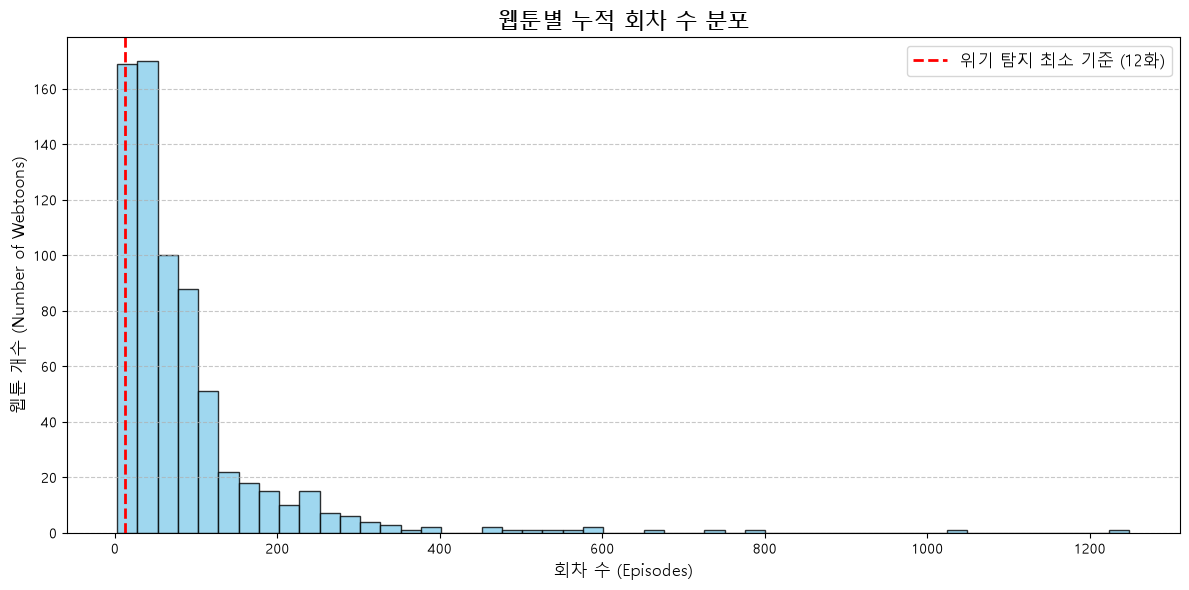

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# 한글 폰트 설정 (Mac/Windows 등 환경에 맞게 조정)
plt.rcParams['font.family'] = 'Malgun Gothic' # Windows의 경우 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 데이터 로드 (episodes.parquet 활용)
file_path = "./data/processed/episodes.parquet"
episodes = pd.read_parquet(file_path)

# 웹툰(title_id)별 누적 회차 수 계산
# no 컬럼을 카운트하거나, no의 최댓값을 구하는 방식 모두 가능합니다.
episode_counts = episodes.groupby('title_id')['no'].count().reset_index()
episode_counts.columns = ['title_id', 'episode_count']

# 판다스를 활용한 텍스트 기반 구간(Bin)별 빈도 확인
# 예: 0~20화, 20~50화, 50~100화, 100~200화, 200화 이상
bins = [0, 20, 50, 100, 200, 500, 1000, episode_counts['episode_count'].max()]
labels = ['0-19화', '20-49화', '50-99화', '100-199화', '200-499화', '500-999화', '1000화 이상']
episode_counts['episode_bin'] = pd.cut(episode_counts['episode_count'], bins=bins, labels=labels, right=False)

print("=== 구간(Bin)별 웹툰 개수 ===")
print(episode_counts['episode_bin'].value_counts().sort_index())
print("\n전체 웹툰 수:", len(episode_counts))

# 시각화 (히스토그램)
plt.figure(figsize=(12, 6))

# 히스토그램 그리기 (bin을 50개 정도로 쪼개어 세밀하게 확인)
counts, bins_plot, patches = plt.hist(
    episode_counts['episode_count'], 
    bins=50, 
    color='skyblue', 
    edgecolor='black',
    alpha=0.8
)

# 12화 기준선 표시 
plt.axvline(x=12, color='red', linestyle='--', linewidth=2, label='위기 탐지 최소 기준 (12화)')

plt.title('웹툰별 누적 회차 수 분포', fontsize=16)
plt.xlabel('회차 수 (Episodes)', fontsize=12)
plt.ylabel('웹툰 개수 (Number of Webtoons)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 레이블이 잘리지 않도록 레이아웃 조정
plt.tight_layout()
plt.show()

##### 분석용으로 테이블 생성

RQ1 - 위기 회차 탐지 기준 및 2회 연속 회복 조건이 반영된 위기 회차 테이블 생성 스크립트.

위기회차 탐지 기준:
((y >= 9.5) & (y <= ma5 - 0.15)) | ((y < 9.5) & (y <= ma5 - 0.05)) | (y < 9.0)

또한, 단기적인 1회성 반등(회복)을 방지하기 위해 다음 조건을 적용:
"2회 연속 위기에서 벗어나야 최종 회복된 것으로 판정"
즉, 위기 상태(True) 사이의 1화짜리 회복(False)은 위기 상태가 지속 중인 것으로 간주하여 다시 위기(True)로 변환 수행

신규 필터링 로직 추가 (12주 이하 연재 웹툰 제외):
- 웹툰 연재가 12주 이하라면 분석에서 제외
- 주1회 연재 웹툰의 경우 12화 이하 웹툰 제외.
- 주2회 연재 웹툰의 경우 24화 이하 웹툰 제외.
- 제외 기준 식: 연재 화수 <= (주당 연재 요일 수 * 12)
- 12주 이하 웹툰의 통계(개수, 전체 중 비율)를 터미널에 출력

출력물:
`./data/processed/rq1_crisis_episodes.parquet `(전체 웹툰 대상, 12주 이하 제외 필터 적용)

In [20]:
from __future__ import annotations

from pathlib import Path
import pandas as pd
import numpy as np

# 경로 설정
PROJECT_ROOT = Path("./data")
PROCESSED_DIR = PROJECT_ROOT / "processed"
OUTPUT_FULL = PROCESSED_DIR / "rq1_crisis_episodes.parquet"

def apply_crisis_and_recovery(group: pd.DataFrame) -> pd.DataFrame:
    """
    각 웹툰별로 위기 회차 탐지 및 2회 연속 회복 판정 로직을 적용
    """
    # 에피소드 정렬 보장
    group = group.sort_values(by="no").reset_index(drop=True)
    
    y = group["star_score"].to_numpy()
    ma5 = group["ma5"].to_numpy()
    
    # 1단계: 기본 위기 조건 적용
    # ((y >= 9.5) & (y <= ma5 - 0.15)) | ((y < 9.5) & (y <= ma5 - 0.05)) | (y < 9.0)
    is_crisis = (
        ((y >= 9.5) & (y <= ma5 - 0.15)) |
        ((y < 9.5) & (y <= ma5 - 0.05)) |
        (y < 9.0)
    )
    
    # numpy array로 변환하여 고속 루프 적용
    is_crisis_arr = is_crisis.astype(bool)
    n = len(is_crisis_arr)
    
    # 2단계: 2회 연속 회복 조건 적용
    # 1화짜리 일시적 회복(True -> False -> True)을 감지하여 다시 위기(True)로 변환
    if n >= 3:
        for i in range(1, n - 1):
            is_crisis_arr[i] = (is_crisis_arr[i-1] & is_crisis_arr[i+1]) | is_crisis_arr[i]
            
    group["is_crisis"] = is_crisis_arr
    return group

def main() -> None:
    print("=" * 30)
    print("위기 회차 테이블 생성 및 2회 연속 회복 로직 적용 작업을 시작합니다.")
    print("=" * 30)

    # 데이터 로드
    episodes_path = PROCESSED_DIR / "episodes.parquet"
    works_path = PROCESSED_DIR / "works_base.parquet"

    if not episodes_path.exists():
        raise FileNotFoundError(f"에피소드 데이터 파일을 찾을 수 없습니다: {episodes_path}")
    if not works_path.exists():
        raise FileNotFoundError(f"작품 기본 정보 파일을 찾을 수 없습니다: {works_path}")

    print("데이터 로드 중...")
    episodes = pd.read_parquet(episodes_path)
    works = pd.read_parquet(works_path)
    
    print(f"- works_base 작품 수: {works['title_id'].nunique()}개")
    print(f"- episodes 총 에피소드 수: {len(episodes)}개")

    # 12주 이하 연재 웹툰 분석 제외 대상 파악 및 통계 산출
    # 웹툰별 에피소드 개수 계산
    ep_counts = episodes.groupby("title_id").size()
    works["ep_count"] = works["title_id"].map(ep_counts).fillna(0)
    # 주당 연재 요일 수 계산 (weekday_list의 요일 수)
    works["n_days"] = works["weekday_list"].apply(lambda x: len(str(x).split(",")))
    # 12주 기준 threshold 계산 (주당 요일 수 * 12)
    works["threshold"] = works["n_days"] * 12

    # 제외 대상 마스크 생성 (연재 화수 <= threshold)
    excluded_mask = works["ep_count"] <= works["threshold"]
    num_excluded = int(excluded_mask.sum())
    total_works = len(works)
    pct_excluded = (num_excluded / total_works) * 100 if total_works > 0 else 0.0

    # 통계 정보를 터미널에 출력
    print("\n" + "=" * 50)
    print("  12주 이하 연재 웹툰 분석 제외 통계")
    print("=" * 50)
    print(f"- 제외 대상 웹툰 수 (12주 이하): {num_excluded}개")
    print(f"- 전체 중 비율: {pct_excluded:.2f}% (전체 {total_works}개 중)")
    print("=" * 50)

    # works_base 기준 필터링 (기본 매칭 대상 확보)
    valid_title_ids = set(works["title_id"])
    filtered_episodes = episodes[episodes["title_id"].isin(valid_title_ids)].copy()

    # 웹툰별 MA5 계산 및 위기/회복 로직 적용
    print("\n웹툰별 5화 이동평균(MA5) 계산 및 위기 조건 적용 중...")
    filtered_episodes = filtered_episodes.sort_values(by=["title_id", "no"]).reset_index(drop=True)
    filtered_episodes["ma5"] = filtered_episodes.groupby("title_id")["star_score"].transform(
        lambda x: x.rolling(window=5, min_periods=1).mean()
    )

    # 각 웹툰별 그룹으로 쪼개서 2회 연속 회복 조건 적용
    processed_groups = []
    grouped = filtered_episodes.groupby("title_id", group_keys=False)
    
    total_webtoons = len(grouped)
    for idx, (tid, group) in enumerate(grouped, 1):
        processed_group = apply_crisis_and_recovery(group)
        processed_groups.append(processed_group)
        if idx % 100 == 0 or idx == total_webtoons:
            print(f"- 웹툰 적용 진행도: {idx}/{total_webtoons}")

    all_processed_df = pd.concat(processed_groups, ignore_index=True)
    
    # 위기 회차 데이터만 필터링
    crisis_only_df = all_processed_df[all_processed_df["is_crisis"]].copy()

    # 최종 컬럼 구성 (원본 타입 및 값 보존)
    final_table = pd.DataFrame({
        "title_id": crisis_only_df["title_id"],
        "cirisis_no": crisis_only_df["no"],
        "star_score": crisis_only_df["star_score"]
    }).reset_index(drop=True)
    
    # 12주 이하 연재 웹툰 분석 제외 필터링 적용 (Full 버전용)
    excluded_title_ids = set(works[excluded_mask]["title_id"])
    final_table_filtered = final_table[~final_table["title_id"].isin(excluded_title_ids)].copy().reset_index(drop=True)

    # 저장
    print(f"\nFull 버전 저장 중 (12주 이하 연재 제외 필터 적용): {OUTPUT_FULL}")
    final_table_filtered.to_parquet(OUTPUT_FULL, index=False)
    print("- Full 버전 저장 완료!")

    # 통계 및 요약 보고서 출력
    print("\n" + "=" * 50)
    print("  위기 회차 탐지 결과 요약 (최종 분석용)")
    print("=" * 50)
    print("[Full 버전 통계 (12주 이하 제외 적용 완료)]")
    print(f"- 탐지된 총 위기 회차 수: {len(final_table_filtered)}개 (제외 전 {len(final_table)}개)")
    analyzed_works_cnt = works['title_id'].nunique() - num_excluded
    print(f"- 위기가 발생한 고유 웹툰 수: {final_table_filtered['title_id'].nunique()}개 (분석 대상 {analyzed_works_cnt}개 중 {final_table_filtered['title_id'].nunique()/analyzed_works_cnt*100:.1f}%)")
    print(f"- 위기 회차의 평균 별점: {final_table_filtered['star_score'].mean():.3f}")
    print(f"- 위기 회차의 최저 별점: {final_table_filtered['star_score'].min():.3f}")
    name_lookup = dict(zip(works["title_id"], works["title_name"]))
        
    print("\n[전체 위기 발생 빈도가 높은 웹툰 Top 5 (제외 적용)]")
    crisis_counts = final_table_filtered["title_id"].value_counts().head(5)
    for i, (tid, cnt) in enumerate(crisis_counts.items(), 1):
        name = name_lookup.get(tid, "알 수 없음")
        print(f"  {i}. {name} (ID: {tid}) - {cnt}회 발생")
    print("=" * 50)

main()


위기 회차 테이블 생성 및 2회 연속 회복 로직 적용 작업을 시작합니다.
데이터 로드 중...
- works_base 작품 수: 694개
- episodes 총 에피소드 수: 59991개

  12주 이하 연재 웹툰 분석 제외 통계
- 제외 대상 웹툰 수 (12주 이하): 71개
- 전체 중 비율: 10.23% (전체 694개 중)

웹툰별 5화 이동평균(MA5) 계산 및 위기 조건 적용 중...
- 웹툰 적용 진행도: 100/694
- 웹툰 적용 진행도: 200/694
- 웹툰 적용 진행도: 300/694
- 웹툰 적용 진행도: 400/694
- 웹툰 적용 진행도: 500/694
- 웹툰 적용 진행도: 600/694
- 웹툰 적용 진행도: 694/694

Full 버전 저장 중 (12주 이하 연재 제외 필터 적용): data\processed\rq1_crisis_episodes.parquet
- Full 버전 저장 완료!

  위기 회차 탐지 결과 요약 (최종 분석용)
[Full 버전 통계 (12주 이하 제외 적용 완료)]
- 탐지된 총 위기 회차 수: 4702개 (제외 전 4734개)
- 위기가 발생한 고유 웹툰 수: 377개 (분석 대상 623개 중 60.5%)
- 위기 회차의 평균 별점: 8.363
- 위기 회차의 최저 별점: 1.916

[전체 위기 발생 빈도가 높은 웹툰 Top 5 (제외 적용)]
  1. 최강전설 강해효 (ID: 570506) - 382회 발생
  2. 외모지상주의 (ID: 641253) - 169회 발생
  3. 천마는 평범하게 살 수 없다 (ID: 774358) - 154회 발생
  4. 유월의 소한 (ID: 796492) - 127회 발생
  5. 이매망량 (ID: 819506) - 108회 발생


RQ1 - 위기 회차의 강도를 측정하고 세분화된 severity_tier를 적용

다음 세 가지 축을 기준으로 위기 강도를 산출
1. 절대 점수 강도 (absolute_component): star_score의 절대적 평점 수준.
2. 흐름 대비 급락 강도 (drop_component): 직전 흐름(prev, rolling_median5) 또는 위기 직전 baseline(pre_median5) 대비 하락폭.
3. 작품 내부 상대 위치 (relative_component): 해당 작품 안에서의 percentile rank.

최종 계산식:
crisis_severity_score = 0.40 * absolute_component + 0.45 * drop_component + 0.15 * relative_component

세분화된 severity_tier:
- < 0.25: mild
- 0.25 ~ 0.50: moderate
- 0.50 ~ 0.75: severe
- \>= 0.75: extreme

출력물: `rq1_crisis_severity.parquet`

In [21]:
from __future__ import annotations

from pathlib import Path
import pandas as pd
import numpy as np

# 경로 설정
PROJECT_ROOT = Path("./data")
PROCESSED_DIR = PROJECT_ROOT / "processed"
OUTPUT_SEVERITY = PROCESSED_DIR / "rq1_crisis_severity.parquet"

def apply_crisis_detection(group: pd.DataFrame) -> pd.DataFrame:
    """
    각 웹툰별로 위기 회차 탐지 및 2회 연속 회복 판정 로직을 적용
    """
    group = group.copy()
    if "title_id" not in group.columns:
        group["title_id"] = group.name
    group = group.sort_values(by="no").reset_index(drop=True)
    y = group["star_score"].to_numpy()
    ma5 = group["ma5"].to_numpy()
    
    # 기본 위기 조건 적용
    is_crisis = (
        ((y >= 9.5) & (y <= ma5 - 0.15)) |
        ((y < 9.5) & (y <= ma5 - 0.05)) |
        (y < 9.0)
    )
    is_crisis = is_crisis & (~np.isnan(y)) & (~np.isnan(ma5))
    is_crisis_arr = is_crisis.astype(bool)
    n = len(is_crisis_arr)
    
    # 2회 연속 회복 조건 적용
    if n >= 3:
        for i in range(1, n - 1):
            is_crisis_arr[i] = (is_crisis_arr[i-1] & is_crisis_arr[i+1]) | is_crisis_arr[i]
            
    group["is_crisis"] = is_crisis_arr
    return group

def process_webtoon_metrics(group: pd.DataFrame) -> pd.DataFrame:
    """
    각 웹툰별로 이전 평점, rolling median, 위기 직전 baseline(pre_median_5), 백분위수 등을 계산
    """
    group = group.copy()
    if "title_id" not in group.columns:
        group["title_id"] = group.name
    group = group.sort_values("no").reset_index(drop=True)
    y = group["star_score"].to_numpy()
    n = len(group)
    
    # 이전 평점 (score_prev) - 첫 화의 경우 8.0 가정
    score_prev = group["star_score"].shift(1).to_numpy()
    score_prev[0] = 8.0
    group["score_prev"] = score_prev
    
    # 직전 5화 rolling median (rolling_median_5_prev) - 첫 화의 경우 8.0 가정
    rolling_median_5_prev = group["star_score"].rolling(window=5, min_periods=1).median().shift(1).to_numpy()
    rolling_median_5_prev[0] = 8.0
    group["rolling_median_5_prev"] = rolling_median_5_prev
    
    # 위기 직전 baseline (pre_median_5) - 첫 화가 세그먼트 시작인 경우 8.0 가정
    is_crisis_arr = group["is_crisis"].to_numpy()
    pre_median_5 = np.full(n, np.nan)
    
    in_segment = False
    segment_start = -1
    
    for i in range(n):
        if is_crisis_arr[i]:
            if not in_segment:
                in_segment = True
                segment_start = i
        else:
            if in_segment:
                # 위기 세그먼트 종료
                if segment_start > 0:
                    pre_window = y[max(0, segment_start - 5) : segment_start]
                    pre_window = pre_window[~np.isnan(pre_window)]
                    seg_median = np.median(pre_window) if len(pre_window) > 0 else np.nan
                else:
                    seg_median = 8.0
                pre_median_5[segment_start : i] = seg_median
                in_segment = False
                
    if in_segment:
        if segment_start > 0:
            pre_window = y[max(0, segment_start - 5) : segment_start]
            pre_window = pre_window[~np.isnan(pre_window)]
            seg_median = np.median(pre_window) if len(pre_window) > 0 else np.nan
        else:
            seg_median = 8.0
        pre_median_5[segment_start : n] = seg_median
        
    group["pre_median_5"] = pre_median_5
    
    # 작품 내 relative percentile (within_title_percentile)
    group["within_title_percentile"] = group["star_score"].rank(pct=True, method="average")
    
    return group

def main():
    print("=" * 30)
    print("위기 회차 강도(Severity) 측정 및 테이블 생성을 시작합니다.")
    print("=" * 30)

    # 데이터 로딩
    episodes_path = PROCESSED_DIR / "episodes.parquet"
    crisis_path = PROCESSED_DIR / "rq1_crisis_episodes.parquet"
    works_path = PROCESSED_DIR / "works_base.parquet"

    print("데이터 로딩 중...")
    episodes = pd.read_parquet(episodes_path)
    crisis_episodes = pd.read_parquet(crisis_path)
    works = pd.read_parquet(works_path)
    
    print(f"- episodes 총 레코드: {len(episodes)}개")
    print(f"- 기존 crisis_episodes 레코드: {len(crisis_episodes)}개")
    print(f"- works_base 작품 수: {works['title_id'].nunique()}개")

    # MA5 계산 및 위기 탐지
    print("웹툰별 MA5 및 위기 조건 재탐지 중...")
    episodes = episodes.sort_values(by=["title_id", "no"]).reset_index(drop=True)
    episodes["ma5"] = episodes.groupby("title_id")["star_score"].transform(
        lambda x: x.rolling(window=5, min_periods=1).mean()
    )
    
    episodes = pd.concat(
        [apply_crisis_detection(group) for _, group in episodes.groupby("title_id", group_keys=False)],
        ignore_index=True,
    )

    # 그룹별 통계 및 baseline 계산
    print("웹툰별 흐름 및 위기 직전 baseline(pre_median_5) 계산 중...")
    episodes = pd.concat(
        [process_webtoon_metrics(group) for _, group in episodes.groupby("title_id", group_keys=False)],
        ignore_index=True,
    )

    # 세부 컴포넌트 계산
    print("위기 강도 컴포넌트 점수화 진행 중...")
    
    # (1) Absolute Component
    star_score = episodes["star_score"].to_numpy()
    conds_abs = [
        star_score >= 9.5,
        (star_score >= 9.0) & (star_score < 9.5),
        (star_score >= 8.0) & (star_score < 9.0),
        (star_score >= 7.0) & (star_score < 8.0),
        (star_score >= 5.0) & (star_score < 7.0),
        (star_score >= 3.0) & (star_score < 5.0),
        star_score < 3.0
    ]
    choices_abs = [0.00, 0.05, 0.20, 0.40, 0.65, 0.90, 1.00]
    episodes["absolute_component"] = np.select(conds_abs, choices_abs, default=np.nan)

    # (2) Drop Component
    episodes["score_drop_from_prev"] = episodes["score_prev"] - episodes["star_score"]
    episodes["score_drop_from_rolling_median5"] = episodes["rolling_median_5_prev"] - episodes["star_score"]
    episodes["score_drop_from_pre_median5"] = episodes["pre_median_5"] - episodes["star_score"]

    drops_df = episodes[[
        "score_drop_from_prev",
        "score_drop_from_rolling_median5",
        "score_drop_from_pre_median5"
    ]].rename(columns={
        "score_drop_from_prev": "prev",
        "score_drop_from_rolling_median5": "rolling_median5",
        "score_drop_from_pre_median5": "pre_median5"
    })

    # 최대 하락폭 (음수/NaN 처리 포함)
    max_drop = drops_df.max(axis=1)
    episodes["max_context_drop"] = np.maximum(0.0, max_drop.fillna(0.0))
    episodes["max_context_drop_source"] = drops_df.idxmax(axis=1).fillna("none")

    max_context_drop = episodes["max_context_drop"].to_numpy()
    conds_drop = [
        max_context_drop < 0.3,
        (max_context_drop >= 0.3) & (max_context_drop < 0.5),
        (max_context_drop >= 0.5) & (max_context_drop < 1.0),
        (max_context_drop >= 1.0) & (max_context_drop < 2.0),
        (max_context_drop >= 2.0) & (max_context_drop < 4.0),
        max_context_drop >= 4.0
    ]
    choices_drop = [0.00, 0.15, 0.50, 0.75, 0.85, 1.00]
    episodes["drop_component"] = np.select(conds_drop, choices_drop, default=np.nan)

    # (3) Relative Component
    within_title_percentile = episodes["within_title_percentile"].to_numpy()
    conds_rel = [
        within_title_percentile > 0.40,
        (within_title_percentile > 0.30) & (within_title_percentile <= 0.40),
        (within_title_percentile > 0.20) & (within_title_percentile <= 0.30),
        (within_title_percentile > 0.10) & (within_title_percentile <= 0.20),
        (within_title_percentile > 0.05) & (within_title_percentile <= 0.10),
        (within_title_percentile > 0.01) & (within_title_percentile <= 0.05),
        within_title_percentile <= 0.01
    ]
    choices_rel = [0.00, 0.01, 0.10, 0.25, 0.60, 0.80, 1.00]
    episodes["relative_component"] = np.select(conds_rel, choices_rel, default=np.nan)

    # (4) 최종 crisis_severity_score
    episodes["crisis_severity_score"] = (
        0.40 * episodes["absolute_component"] +
        0.45 * episodes["drop_component"] +
        0.15 * episodes["relative_component"]
    )

    # (5) severity_tier 맵핑
    crisis_severity_score = episodes["crisis_severity_score"].to_numpy()
    conds_tier = [
        crisis_severity_score < 0.25,
        (crisis_severity_score >= 0.25) & (crisis_severity_score < 0.50),
        (crisis_severity_score >= 0.50) & (crisis_severity_score < 0.75),
        crisis_severity_score >= 0.75
    ]
    choices_tier = ["mild", "moderate", "severe", "extreme"]
    episodes["severity_tier"] = np.select(conds_tier, choices_tier, default="none")

    # 5. 기존 crisis_episodes.parquet 테이블에 맵핑
    print("\n기존 crisis_episodes 테이블과 병합 중...")
    
    metrics_cols = [
        "title_id", "no", "absolute_component",
        "score_prev", "rolling_median_5_prev", "pre_median_5",
        "score_drop_from_prev", "score_drop_from_rolling_median5", "score_drop_from_pre_median5",
        "max_context_drop", "max_context_drop_source", "drop_component",
        "within_title_percentile", "relative_component",
        "crisis_severity_score", "severity_tier"
    ]
    metrics_df = episodes[metrics_cols].copy().rename(columns={"no": "cirisis_no"})
    
    crisis_severity_df = pd.merge(crisis_episodes, metrics_df, on=["title_id", "cirisis_no"], how="inner")
    
    # 결과 저장
    print(f"새로운 parquet 테이블 저장 중: {OUTPUT_SEVERITY}")
    crisis_severity_df.to_parquet(OUTPUT_SEVERITY, index=False)
    print("저장 완료!")

    # 통계 보고서 출력
    total_crisis = len(crisis_severity_df)
    
    print("\n" + "=" * 60)
    print("  위기 회차 강도(Severity Tier) 분포 및 통계")
    print("=" * 60)
    tier_counts = crisis_severity_df["severity_tier"].value_counts()
    tier_means = crisis_severity_df.groupby("severity_tier")["crisis_severity_score"].mean()
    
    for tier in ["mild", "moderate", "severe", "extreme"]:
        count = tier_counts.get(tier, 0)
        pct = (count / total_crisis) * 100 if total_crisis > 0 else 0
        mean_score = tier_means.get(tier, 0.0)
        print(f"- {tier:<10} : {count:>5}개 ({pct:>6.2f}%) | 평균 강도 점수: {mean_score:.4f}")
    print("-" * 60)
    print(f"전체 위기 회차 수: {total_crisis}개")
    print(f"평균 위기 강도 점수: {crisis_severity_df['crisis_severity_score'].mean():.4f}")
    
    # Drop Component Source 통계 출력
    print("\n" + "=" * 60)
    print("  급락 강도(Drop Component) 결정 요인(Source) 통계")
    print("=" * 60)
    # 급락 강도가 0.0보다 큰(즉, 하락이 감지된) 회차에 대해 어떤 소스가 최대 하락폭을 제공했는지 분석
    active_drops = crisis_severity_df[crisis_severity_df["max_context_drop"] > 0.0]
    source_counts = active_drops["max_context_drop_source"].value_counts()
    total_active = len(active_drops)
    
    source_labels = {
        "prev": "score_prev - star_score (직전 회차 대비)",
        "rolling_median5": "rolling_median_5_prev - star_score (직전 5화 median 대비)",
        "pre_median5": "pre_median_5 - star_score (위기 직전 baseline 대비)"
    }
    
    for src_key, src_label in source_labels.items():
        count = source_counts.get(src_key, 0)
        pct = (count / total_active) * 100 if total_active > 0 else 0
        print(f"- {src_label:<60} : {count:>5}개 ({pct:>6.2f}%)")
    print("-" * 60)
    print(f"하락이 감지된 위기 회차 수: {total_active}개 (전체 {total_crisis}개 중 {total_active/total_crisis*100:.1f}%)")
    print("=" * 60)


main()


위기 회차 강도(Severity) 측정 및 테이블 생성을 시작합니다.
데이터 로딩 중...
- episodes 총 레코드: 59991개
- 기존 crisis_episodes 레코드: 4702개
- works_base 작품 수: 694개
웹툰별 MA5 및 위기 조건 재탐지 중...
웹툰별 흐름 및 위기 직전 baseline(pre_median_5) 계산 중...
위기 강도 컴포넌트 점수화 진행 중...

기존 crisis_episodes 테이블과 병합 중...
새로운 parquet 테이블 저장 중: data\processed\rq1_crisis_severity.parquet
저장 완료!

  위기 회차 강도(Severity Tier) 분포 및 통계
- mild       :  2105개 ( 44.77%) | 평균 강도 점수: 0.1058
- moderate   :  1240개 ( 26.37%) | 평균 강도 점수: 0.3640
- severe     :   909개 ( 19.33%) | 평균 강도 점수: 0.5897
- extreme    :   448개 (  9.53%) | 평균 강도 점수: 0.8272
------------------------------------------------------------
전체 위기 회차 수: 4702개
평균 위기 강도 점수: 0.3362

  급락 강도(Drop Component) 결정 요인(Source) 통계
- score_prev - star_score (직전 회차 대비)                           :  1101개 ( 24.55%)
- rolling_median_5_prev - star_score (직전 5화 median 대비)         :  1037개 ( 23.12%)
- pre_median_5 - star_score (위기 직전 baseline 대비)                :  2347개 ( 52.33%)
-------------------------------------------

RQ1 - 위기 회차들을 연속성 기준으로 묶고, 장기 위기(size > 10)에 대해 구조적 분할(split)을 실행하는 v2 스크립트.

(divisor=10.0, weights=[0.6, 0.3, 0.1])을 유지하면서, 다음 구조적 분할 로직을 적용:

1. 분할 대상: cluster_size > 10 인 클러스터
2. 분할 조건: 대표 회차 R 이전 구간과 이후 구간의 평점 평균 차이가 1.5 초과
   | Mean(star_score_before) - Mean(star_score_after) | > 1.5
3. 분할 경계 결정: 대표 회차 R의 별점(S_R)이 이전/이후 구간 평균 중 어디에 더 가까운지에 따라 편입 결정
   - CASE 1 (이전 평균과 가깝다면): R을 A로 편입 -> A: [Start, R], B: [R+1, End]
   - CASE 2 (이후 평균과 가깝거나 같다면): R을 B로 편입 -> A: [Start, R-1], B: [R, End]

In [22]:
from __future__ import annotations

from pathlib import Path
import pandas as pd
import numpy as np

# 경로 설정
PROJECT_ROOT = Path("./data")
PROCESSED_DIR = PROJECT_ROOT / "processed"
OUTPUT_CLUSTER_V2 = PROCESSED_DIR / "rq1_crisis_cluster_v2.parquet"

def group_clusters(df: pd.DataFrame) -> pd.DataFrame:
    """
    동일 웹툰 내에서 연속된 위기 회차를 하나의 클러스터로 그룹화한다
    """
    df = df.copy()
    if "title_id" not in df.columns:
        df["title_id"] = df.name
    df = df.sort_values("cirisis_no").reset_index(drop=True)
    # 직전 회차와의 차이가 1이 아니면 새로운 클러스터로 정의 (첫 회차는 NaN이므로 999로 채워 True가 되도록 함)
    is_new = df["cirisis_no"].diff().fillna(999) != 1
    df["crisis_cluster_id"] = is_new.cumsum()
    return df

def get_representative_no_and_reason(cluster_df: pd.DataFrame) -> tuple[int, str]:
    """
    4단계 우선순위(Severity -> Star Score -> Max Drop -> Earliest No)로 클러스터 대표 회차를 선정
    """
    best_rows = cluster_df.copy()
    
    # highest severity
    max_sev = best_rows["crisis_severity_score"].max()
    best_rows_1 = best_rows[best_rows["crisis_severity_score"] == max_sev]
    if len(best_rows_1) == 1:
        return int(best_rows_1["cirisis_no"].iloc[0]), "highest_episode_severity"
        
    # lowest score
    min_score = best_rows_1["star_score"].min()
    best_rows_2 = best_rows_1[best_rows_1["star_score"] == min_score]
    if len(best_rows_2) == 1:
        return int(best_rows_2["cirisis_no"].iloc[0]), "lowest_score"
        
    # largest drop
    max_drop = best_rows_2["max_context_drop"].max()
    best_rows_3 = best_rows_2[best_rows_2["max_context_drop"] == max_drop]
    if len(best_rows_3) == 1:
        return int(best_rows_3["cirisis_no"].iloc[0]), "largest_drop"
        
    # earliest no
    best_rows_4 = best_rows_3.sort_values("cirisis_no", ascending=True)
    return int(best_rows_4["cirisis_no"].iloc[0]), "earliest_no"

def main() -> None:
    print("=" * 30)
    print("클러스터 수준 위기 테이블 V2(rq1_crisis_cluster_v2.parquet) 생성을 시작합니다.")
    print("=" * 30)

    # 데이터 로딩
    episodes_path = PROCESSED_DIR / "episodes.parquet"
    severity_path = PROCESSED_DIR / "rq1_crisis_severity.parquet"
    works_path = PROCESSED_DIR / "works_base.parquet"

    print("데이터 로딩 중...")
    episodes = pd.read_parquet(episodes_path)
    crisis_severity = pd.read_parquet(severity_path)
    works = pd.read_parquet(works_path)

    print(f"- episodes 총 레코드: {len(episodes)}개")
    print(f"- crisis_severity 총 레코드: {len(crisis_severity)}개")

    # 클러스터 아이디 할당 (웹툰별로 묶음)
    print("웹툰별 위기 회차 연속 그룹화(초기 Cluster ID 부여) 중...")
    crisis_severity = pd.concat(
        [group_clusters(group) for _, group in crisis_severity.groupby("title_id", group_keys=False)],
        ignore_index=True,
    )

    # title_id별로 정리
    episodes_by_title = {
        tid: grp.sort_values("no").reset_index(drop=True) 
        for tid, grp in episodes.groupby("title_id")
    }

    # 클러스터별 분할 및 집계 작업 진행
    final_clusters_dfs = []
    
    # title_id 와 crisis_cluster_id 기준으로 그룹화
    grouped = crisis_severity.groupby(["title_id", "crisis_cluster_id"])
    
    print(f"초기 생성된 {len(grouped)}개의 위기 클러스터에 대해 분할(Split) 조건 검사 중...")
    
    split_count = 0
    
    for (title_id, cluster_id), cluster_df in grouped:
        cluster_df = cluster_df.sort_values("cirisis_no").reset_index(drop=True)
        cluster_size = len(cluster_df)
        cluster_start_no = int(cluster_df["cirisis_no"].min())
        cluster_end_no = int(cluster_df["cirisis_no"].max())
        
        has_split = False
        
        if cluster_size > 10:
            # 대표 회차 계산
            rep_no, _ = get_representative_no_and_reason(cluster_df)
            
            # 대표 회차가 시작점이나 끝점에 걸쳐있지 않아야 분할 구간이 비어있지 않음
            if rep_no > cluster_start_no and rep_no < cluster_end_no:
                df_before = cluster_df[cluster_df["cirisis_no"] < rep_no]
                df_after = cluster_df[cluster_df["cirisis_no"] > rep_no]
                
                mean_before = df_before["star_score"].mean()
                mean_after = df_after["star_score"].mean()
                
                # 평점 평균 차이가 1.5 초과인 경우 구조적 분할 진행
                if np.abs(mean_before - mean_after) > 1.5:
                    s_r = cluster_df[cluster_df["cirisis_no"] == rep_no]["star_score"].iloc[0]
                    
                    # R이 어디에 편입될지 결정
                    if np.abs(s_r - mean_before) < np.abs(s_r - mean_after):
                        # CASE 1: R이 이전 구간 평균과 더 가까운 경우 (Cluster A에 포함)
                        cluster_a = cluster_df[cluster_df["cirisis_no"] <= rep_no].copy()
                        cluster_b = cluster_df[cluster_df["cirisis_no"] > rep_no].copy()
                    else:
                        # CASE 2: R이 이후 구간 평균과 더 가깝거나 같은 경우 (Cluster B에 포함)
                        cluster_a = cluster_df[cluster_df["cirisis_no"] < rep_no].copy()
                        cluster_b = cluster_df[cluster_df["cirisis_no"] >= rep_no].copy()
                        
                    final_clusters_dfs.append(cluster_a)
                    final_clusters_dfs.append(cluster_b)
                    has_split = True
                    split_count += 1
                    
        if not has_split:
            final_clusters_dfs.append(cluster_df)

    print(f"분할(Split) 작업 완료: 총 {split_count}개의 클러스터가 각각 2개로 분할되었습니다.")

    # 각 최종 클러스터별 통계 계산
    cluster_records = []
    
    for idx, c_df in enumerate(final_clusters_dfs):
        c_df = c_df.sort_values("cirisis_no").reset_index(drop=True)
        title_id = c_df["title_id"].iloc[0]
        
        cluster_start_no = int(c_df["cirisis_no"].min())
        cluster_end_no = int(c_df["cirisis_no"].max())
        cluster_size = len(c_df)
        
        cluster_mean = float(c_df["star_score"].mean())
        cluster_min_score = float(c_df["star_score"].min())
        cluster_peak_drop = float(c_df["max_context_drop"].max())
        cluster_peak_episode_severity_score = float(c_df["crisis_severity_score"].max())
        
        # (1) pre_cluster_baseline 계산 (시작 회차 이전 5화의 median)
        title_grp = episodes_by_title.get(title_id)
        if title_grp is not None:
            pre_window = title_grp[title_grp["no"] < cluster_start_no].tail(5)
            if len(pre_window) > 0:
                pre_cluster_baseline = float(pre_window["star_score"].median())
            else:
                pre_cluster_baseline = None
        else:
            pre_cluster_baseline = None
            
        # (2) 누적 위기 손상량 계산 (cluster_cumulative_deficit)
        star_scores_arr = c_df["star_score"].to_numpy()
        abs_deficit_9 = np.maximum(0.0, 9.0 - star_scores_arr)
        cluster_abs_deficit_9 = float(np.sum(abs_deficit_9))
        
        if pre_cluster_baseline is not None and not np.isnan(pre_cluster_baseline):
            baseline_deficit = np.maximum(0.0, pre_cluster_baseline - star_scores_arr)
            cluster_baseline_deficit = float(np.sum(baseline_deficit))
            cluster_cumulative_deficit = max(cluster_abs_deficit_9, cluster_baseline_deficit)
        else:
            cluster_cumulative_deficit = cluster_abs_deficit_9

        # (3) 대표 회차 및 사유 재선정 (분할에 의해 최적 대표 회차가 달라질 수 있으므로 다시 선정)
        cluster_representative_no, cluster_representative_reason = get_representative_no_and_reason(c_df)

        # (4) Cluster-level severity score 계산 (V2 변경 사유 적용)
        peak_component = cluster_peak_episode_severity_score
        cumulative_component = min(1.0, cluster_cumulative_deficit / 10.0) # V2 분모 10.0으로 조정
        duration_component = min(1.0, (cluster_size - 1) / 4.0)
        
        cluster_level_crisis_severity_score = (
            0.60 * peak_component +
            0.30 * cumulative_component +
            0.10 * duration_component # V2 가중치 0.6 / 0.3 / 0.1 조정
        )
        
        # (5) Cluster-level severity tier 설정
        if cluster_level_crisis_severity_score < 0.25:
            cluster_level_severity_tier = "mild_cluster"
        elif cluster_level_crisis_severity_score < 0.50:
            cluster_level_severity_tier = "moderate_cluster"
        elif cluster_level_crisis_severity_score < 0.75:
            cluster_level_severity_tier = "severe_cluster"
        else:
            cluster_level_severity_tier = "extreme_cluster"
            
        cluster_records.append({
            "title_id": title_id,
            "cluster_start_no": cluster_start_no,
            "cluster_end_no": cluster_end_no,
            "cluster_size": cluster_size,
            "cluster_representative_no": cluster_representative_no,
            "cluster_representative_reason": cluster_representative_reason,
            "cluster_mean": cluster_mean,
            "cluster_min_score": cluster_min_score,
            "cluster_peak_drop": cluster_peak_drop,
            "cluster_peak_episode_severity_score": cluster_peak_episode_severity_score,
            "cluster_cumulative_deficit": cluster_cumulative_deficit,
            "cluster_level_crisis_severity_score": cluster_level_crisis_severity_score,
            "cluster_level_severity_tier": cluster_level_severity_tier
        })

    # 최종 정렬 및 crisis_cluster_id 재부여
    v2_df = pd.DataFrame(cluster_records)
    v2_df = v2_df.sort_values(by=["title_id", "cluster_start_no"]).reset_index(drop=True)
    
    # 각 작품별로 정렬된 순서에 따라 1, 2, 3, ... 순차적 ID 부여
    v2_df["crisis_cluster_id"] = v2_df.groupby("title_id").cumcount() + 1
    
    # 컬럼 순서 정렬
    cols_order = [
        "title_id", "crisis_cluster_id", "cluster_start_no", "cluster_end_no", 
        "cluster_size", "cluster_representative_no", "cluster_representative_reason",
        "cluster_mean", "cluster_min_score", "cluster_peak_drop", 
        "cluster_peak_episode_severity_score", "cluster_cumulative_deficit",
        "cluster_level_crisis_severity_score", "cluster_level_severity_tier"
    ]
    v2_df = v2_df[cols_order]
    
    # 타입 명시
    v2_df = v2_df.astype({
        "title_id": str,
        "crisis_cluster_id": int,
        "cluster_start_no": int,
        "cluster_end_no": int,
        "cluster_size": int,
        "cluster_representative_no": int,
        "cluster_representative_reason": str,
        "cluster_mean": float,
        "cluster_min_score": float,
        "cluster_peak_drop": float,
        "cluster_peak_episode_severity_score": float,
        "cluster_cumulative_deficit": float,
        "cluster_level_crisis_severity_score": float,
        "cluster_level_severity_tier": str
    })
    
    # 저장
    v2_df.to_parquet(OUTPUT_CLUSTER_V2, index=False)
    print(f"저장 완료! 경로: {OUTPUT_CLUSTER_V2}")

    # 통계 보고서 출력
    total_clusters = len(v2_df)
    print("\n" + "=" * 60)
    print("  클러스터 수준 위기 강도 V2(Cluster Severity Tier V2) 분포 및 통계")
    print("=" * 60)
    tier_counts = v2_df["cluster_level_severity_tier"].value_counts()
    tier_means = v2_df.groupby("cluster_level_severity_tier")["cluster_level_crisis_severity_score"].mean()
    
    for tier in ["mild_cluster", "moderate_cluster", "severe_cluster", "extreme_cluster"]:
        count = tier_counts.get(tier, 0)
        pct = (count / total_clusters) * 100 if total_clusters > 0 else 0.0
        mean_score = tier_means.get(tier, 0.0)
        print(f"- {tier:<18} : {count:>5}개 ({pct:>6.2f}%) | 평균 클러스터 점수: {mean_score:.4f}")
    print("-" * 60)
    print(f"전체 V2 위기 클러스터 수: {total_clusters}개 (분할에 의해 기존 대비 {total_clusters - 1612}개 증가)")
    print(f"평균 V2 클러스터 강도 점수: {v2_df['cluster_level_crisis_severity_score'].mean():.4f}")
    
    # 대표 회차 선정 사유 통계 출력
    print("\n" + "=" * 60)
    print("  V2 대표 회차 선정 사유(Representative Reason) 통계")
    print("=" * 60)
    reason_counts = v2_df["cluster_representative_reason"].value_counts()
    
    reasons = ["highest_episode_severity", "lowest_score", "largest_drop", "earliest_no"]
    for r in reasons:
        count = reason_counts.get(r, 0)
        pct = (count / total_clusters) * 100 if total_clusters > 0 else 0.0
        print(f"- {r:<30} : {count:>5}개 ({pct:>6.2f}%)")
    print("=" * 60)


main()


클러스터 수준 위기 테이블 V2(rq1_crisis_cluster_v2.parquet) 생성을 시작합니다.
데이터 로딩 중...
- episodes 총 레코드: 59991개
- crisis_severity 총 레코드: 4702개
웹툰별 위기 회차 연속 그룹화(초기 Cluster ID 부여) 중...
초기 생성된 1612개의 위기 클러스터에 대해 분할(Split) 조건 검사 중...
분할(Split) 작업 완료: 총 5개의 클러스터가 각각 2개로 분할되었습니다.
저장 완료! 경로: data\processed\rq1_crisis_cluster_v2.parquet

  클러스터 수준 위기 강도 V2(Cluster Severity Tier V2) 분포 및 통계
- mild_cluster       :   984개 ( 60.85%) | 평균 클러스터 점수: 0.1124
- moderate_cluster   :   427개 ( 26.41%) | 평균 클러스터 점수: 0.3518
- severe_cluster     :   121개 (  7.48%) | 평균 클러스터 점수: 0.5983
- extreme_cluster    :    85개 (  5.26%) | 평균 클러스터 점수: 0.8671
------------------------------------------------------------
전체 V2 위기 클러스터 수: 1617개 (분할에 의해 기존 대비 5개 증가)
평균 V2 클러스터 강도 점수: 0.2517

  V2 대표 회차 선정 사유(Representative Reason) 통계
- highest_episode_severity       :  1499개 ( 92.70%)
- lowest_score                   :   118개 (  7.30%)
- largest_drop                   :     0개 (  0.00%)
- earliest_no                    :     0개 (  0.00%)


### 시각화

In [23]:
from __future__ import annotations

from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

PROJECT_ROOT = Path('./data')
PROCESSED = PROJECT_ROOT / "processed"
OUT_DIR = PROJECT_ROOT / "plots" / "RQ1_baseline_viz"
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_IDS = [
    "650305", "769209", "803792",
    "809618", "811721", "822556", "827335", "570506",
    "641253", "774358", "796492", "819506"
]


def setup_korean_font() -> None:
    for cand in ("Malgun Gothic", "NanumGothic", "AppleGothic", "Noto Sans CJK KR"):
        if any(cand == f.name for f in font_manager.fontManager.ttflist):
            matplotlib.rcParams["font.family"] = cand
            break
    matplotlib.rcParams["axes.unicode_minus"] = False


def load_data() -> tuple[pd.DataFrame, pd.DataFrame]:
    episodes = pd.read_parquet(PROCESSED / "episodes.parquet")
    works = pd.read_parquet(PROCESSED / "works_base.parquet")
    return episodes, works


def plot_one(ax: plt.Axes, ep_df: pd.DataFrame, title_name: str, title_id: str) -> None:
    ep_df = ep_df.sort_values("no").reset_index(drop=True)
    x = ep_df["no"].to_numpy()
    y = ep_df["star_score"].to_numpy()

    # 5화 이동평균 (MA5) 계산
    ma5 = ep_df["star_score"].rolling(window=5, min_periods=1).mean().to_numpy()

    # 위기 회차 탐지 조건: 별점 <= 9.5 OR 별점 <= MA5
    is_crisis = ((y >= 9.5) & (y <= ma5 - 0.15)) | ((y < 9.5) & (y <= ma5 - 0.05)) | (y < 9.0)
    # 결측치 제외
    is_crisis = is_crisis & (~np.isnan(y)) & (~np.isnan(ma5))
    
    temp_crisis = is_crisis.copy()
    
    # 2회 연속 위기 회복해야 회복 판정
    for i in range(1, len(is_crisis) - 2):
        is_crisis[i] = is_crisis[i-1] & is_crisis[i+1] | is_crisis[i]
    
    temp_crisis = ~temp_crisis & is_crisis

    # 1. 메인: 일반 회차 별점
    ax.plot(x, y, color="#555555", lw=0.9, alpha=0.35, zorder=1)
    ax.scatter(x[~is_crisis], y[~is_crisis], s=12, color="#444444", alpha=0.6, zorder=2, label="일반 회차")

    # 2. 5화 이동평균 (MA5): 파란색, 투명도 50%
    ax.plot(x, ma5, color="#1f77b4", lw=1.8, alpha=0.5, label="5화 이동평균 (MA5)", zorder=3)

    # 3. 별점 9.5 가로 기준선
    ax.axhline(9.5, color="#ff7f0e", ls="--", lw=1.2, alpha=0.8, label="기준 별점 9.5", zorder=2)

    # 4. 위기 회차 마커: 빨간색
    ax.scatter(x[is_crisis], y[is_crisis], s=25, color="#e31a1c", edgecolor="#800000", lw=0.5, zorder=4, label="위기 회차")
    
    ax.scatter(x[temp_crisis], y[temp_crisis], s=25, color="#671313", edgecolor="#800000", lw=0.5, zorder=4, label="2회 연속 회복하지 못한 회차")

    ymin = min(np.nanmin(y), 9.5) - 0.2
    ymax = max(np.nanmax(y), 9.5) + 0.15
    ax.set_ylim(ymin, ymax)
    ax.set_xlim(x.min() - 1, x.max() + 1)
    ax.set_xlabel("회차 번호 (no)")
    ax.set_ylabel("별점 (star_score)")
    ax.set_title(f"{title_name}  (title_id={title_id}, n={len(ep_df)})", fontsize=11)
    ax.grid(True, axis="y", alpha=0.25)
    ax.legend(fontsize=8, loc="lower left", ncol=2, framealpha=0.85)


def main() -> None:
    setup_korean_font()
    episodes, works = load_data()
    name_lookup = dict(zip(works["title_id"], works["title_name"]))

    summary_rows = []

    # 개별 플롯 생성
    for tid in TARGET_IDS:
        ep_df = episodes[episodes["title_id"] == tid].copy()
        title_name = name_lookup.get(tid, "(works_base에 없음)")
        if ep_df.empty:
            print(f"[skip] title_id={tid} ({title_name}) - 회차 데이터 없음")
            summary_rows.append({"title_id": tid, "title_name": title_name, "n_episodes": 0, "n_crisis": 0})
            continue

        fig, ax = plt.subplots(figsize=(12, 5))
        plot_one(ax, ep_df, title_name, tid)
        fig.tight_layout()
        out = OUT_DIR / f"rq1_crisis_detection_{tid}.png"
        fig.savefig(out, dpi=150)
        plt.close(fig)
        print(f"[ok]   title_id={tid} ({title_name}) -> {out.name}")

        # 통계 계산
        y = ep_df["star_score"].to_numpy()
        ma5 = ep_df["star_score"].rolling(window=5, min_periods=1).mean().to_numpy()
        is_crisis = ((y >= 9.5) & (y <= ma5 - 0.15)) | ((y < 9.5) & (y <= ma5 - 0.05)) | (y < 9.0)
        is_crisis = is_crisis & (~np.isnan(y)) & (~np.isnan(ma5))
        n_crisis = int(np.sum(is_crisis))

        summary_rows.append({
            "title_id": tid,
            "title_name": title_name,
            "n_episodes": len(ep_df),
            "n_crisis": n_crisis,
            "crisis_ratio": round(n_crisis / len(ep_df) * 100, 2) if len(ep_df) > 0 else 0.0,
            "min_score": round(float(np.nanmin(y)), 3) if len(ep_df) > 0 else np.nan,
            "mean_score": round(float(np.nanmean(y)), 3) if len(ep_df) > 0 else np.nan,
        })

    # 9개 패널 합본 생성
    avail = [tid for tid in TARGET_IDS if not episodes[episodes["title_id"] == tid].empty]
    n = len(avail)
    if n:
        ncols = 3
        nrows = int(np.ceil(n / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 3.8 * nrows))
        axes = np.array(axes).reshape(-1)
        for ax, tid in zip(axes, avail):
            ep_df = episodes[episodes["title_id"] == tid].copy()
            plot_one(ax, ep_df, name_lookup.get(tid, "?"), tid)
            ax.legend().set_visible(False)
        for ax in axes[n:]:
            ax.axis("off")
        
        # 공통 범례 추가
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="lower center", ncol=4,
                   bbox_to_anchor=(0.5, -0.01), fontsize=10, framealpha=0.9)
        fig.suptitle("회차별 별점 + 신규 위기 회차 탐지 기준 (((y >= 9.5) & (y <= ma5 - 0.15)) | ((y < 9.5) & (y <= ma5 - 0.05)) | (y < 9.0))", fontsize=14, y=1.0)
        fig.tight_layout(rect=(0, 0.03, 1, 0.99))
        out = OUT_DIR / "rq1_crisis_detection_grid_all.png"
        fig.savefig(out, dpi=150, bbox_inches="tight")
        plt.close(fig)
        print(f"[ok]   합본 -> {out.name}")

    summary = pd.DataFrame(summary_rows)
    summary_path = OUT_DIR / "rq1_crisis_summary.csv"
    summary.to_csv(summary_path, index=False, encoding="utf-8-sig")
    print(f"[ok]   요약 -> {summary_path.name}")
    print(summary.to_string(index=False))

main()


[ok]   title_id=650305 (호랑이형님) -> rq1_crisis_detection_650305.png
[ok]   title_id=769209 (화산귀환) -> rq1_crisis_detection_769209.png
[ok]   title_id=803792 (연애의 기록) -> rq1_crisis_detection_803792.png
[ok]   title_id=809618 (신과함께 돌아온 기사왕님) -> rq1_crisis_detection_809618.png
[ok]   title_id=811721 (무직백수 계백순) -> rq1_crisis_detection_811721.png
[ok]   title_id=822556 (유부 감자) -> rq1_crisis_detection_822556.png
[ok]   title_id=827335 (소년교도소) -> rq1_crisis_detection_827335.png
[ok]   title_id=570506 (최강전설 강해효) -> rq1_crisis_detection_570506.png
[ok]   title_id=641253 (외모지상주의) -> rq1_crisis_detection_641253.png
[ok]   title_id=774358 (천마는 평범하게 살 수 없다) -> rq1_crisis_detection_774358.png
[ok]   title_id=796492 (유월의 소한) -> rq1_crisis_detection_796492.png
[ok]   title_id=819506 (이매망량) -> rq1_crisis_detection_819506.png
[ok]   합본 -> rq1_crisis_detection_grid_all.png
[ok]   요약 -> rq1_crisis_summary.csv
title_id      title_name  n_episodes  n_crisis  crisis_ratio  min_score  mean_score
  650305        

In [24]:
from __future__ import annotations

from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

# 경로 설정
PROJECT_ROOT = Path('./data')
PROCESSED_DIR = PROJECT_ROOT / "processed"
OUT_DIR = PROJECT_ROOT / "plots" / "RQ1_baseline_viz"
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_IDS = [
    "650305", "769209", "803792",
    "809618", "811721", "822556", "827335", "570506",
    "641253", "774358", "796492", "819506"
]

TIER_STYLES = {
    "mild": {"color": "#ffd32a", "size": 35, "label": "Mild (약한 위기)"},
    "moderate": {"color": "#ff9f43", "size": 65, "label": "Moderate (명확한 위기)"},
    "severe": {"color": "#ff4757", "size": 100, "label": "Severe (강한 위기)"},
    "extreme": {"color": "#8b1e3f", "size": 150, "label": "Extreme (극단적 위기)"}
}

def setup_korean_font() -> None:
    for cand in ("Malgun Gothic", "NanumGothic", "AppleGothic", "Noto Sans CJK KR"):
        if any(cand == f.name for f in font_manager.fontManager.ttflist):
            matplotlib.rcParams["font.family"] = cand
            break
    matplotlib.rcParams["axes.unicode_minus"] = False

def load_data() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    episodes = pd.read_parquet(PROCESSED_DIR / "episodes.parquet")
    crisis_severity = pd.read_parquet(PROCESSED_DIR / "rq1_crisis_severity.parquet")
    works = pd.read_parquet(PROCESSED_DIR / "works_base.parquet")
    return episodes, crisis_severity, works

def plot_one(ax: plt.Axes, ep_df: pd.DataFrame, severity_df: pd.DataFrame, title_name: str, title_id: str, is_grid: bool = False) -> None:
    # 데이터 병합 (no 기준)
    merged = pd.merge(ep_df, severity_df[["cirisis_no", "crisis_severity_score", "severity_tier"]], 
                      left_on="no", right_on="cirisis_no", how="left")
    merged = merged.sort_values("no").reset_index(drop=True)
    
    x = merged["no"].to_numpy()
    y = merged["star_score"].to_numpy()
    
    # 5화 이동평균(MA5) 계산
    ma5 = merged["star_score"].rolling(window=5, min_periods=1).mean().to_numpy()
    
    # 1. 배경 흐름: 전체 회차 별점 꺾은선
    ax.plot(x, y, color="#555555", lw=0.9, alpha=0.3, zorder=1)
    
    # 2. 일반 회차 산점도 (위기가 아닌 회차)
    is_normal = merged["severity_tier"].isna()
    ax.scatter(x[is_normal], y[is_normal], s=12, color="#7f8c8d", alpha=0.5, label="일반 회차", zorder=2)
    
    # 3. 5화 이동평균선 (MA5)
    ax.plot(x, ma5, color="#1f77b4", lw=1.6, alpha=0.45, label="5화 이동평균 (MA5)", zorder=3)
    
    # 4. 기준선 별점 9.5
    ax.axhline(9.5, color="#ff7f0e", ls="--", lw=1.0, alpha=0.6, label="기준 별점 9.5", zorder=2)
    
    # 5. 위기 회차 severity_tier별 시각화
    for tier, style in TIER_STYLES.items():
        mask = merged["severity_tier"] == tier
        if mask.any():
            ax.scatter(
                x[mask], y[mask],
                s=style["size"],
                color=style["color"],
                edgecolor="#2c3e50",
                lw=0.7,
                zorder=4,
                label=style["label"]
            )
            
    # 축 범위 및 타이틀 설정
    ymin = min(np.nanmin(y), 9.5) - 0.2 if len(merged) > 0 else 5.0
    ymax = max(np.nanmax(y), 9.5) + 0.15 if len(merged) > 0 else 10.15
    ax.set_ylim(max(ymin, 0.0), 10.15)
    ax.set_xlim(x.min() - 1, x.max() + 1)
    ax.set_xlabel("회차 번호 (no)", fontsize=8 if is_grid else 10)
    ax.set_ylabel("별점 (star_score)", fontsize=8 if is_grid else 10)
    
    ax.set_title(f"{title_name} (ID: {title_id}, n={len(merged)})", fontsize=10 if is_grid else 12, fontweight="bold")
    ax.grid(True, axis="y", alpha=0.25)
    
    if not is_grid:
        ax.legend(fontsize=9, loc="lower left", ncol=2, framealpha=0.85)

def main() -> None:
    setup_korean_font()
    episodes, crisis_severity, works = load_data()
    name_lookup = dict(zip(works["title_id"], works["title_name"]))

    print("=" * 30)
    print("위기 회차 강도 시각화 이미지 생성을 시작합니다.")
    print("=" * 30)

    # 1. 개별 웹툰 시각화 진행
    for tid in TARGET_IDS:
        ep_df = episodes[episodes["title_id"] == tid].copy()
        severity_df = crisis_severity[crisis_severity["title_id"] == tid].copy()
        title_name = name_lookup.get(tid, "알 수 없음")
        
        if ep_df.empty:
            print(f"[skip] title_id={tid} ({title_name}) - 회차 데이터 없음")
            continue
            
        fig, ax = plt.subplots(figsize=(12, 5.5))
        plot_one(ax, ep_df, severity_df, title_name, tid, is_grid=False)
        fig.tight_layout()
        
        out_path = OUT_DIR / f"rq1_crisis_severity_{tid}.png"
        fig.savefig(out_path, dpi=150)
        plt.close(fig)
        print(f"[ok]   개별 플롯 -> {out_path.name}")

    # 2. 14개 웹툰 합본 Grid 플롯 생성 (5행 3열 구조)
    avail_tids = [tid for tid in TARGET_IDS if not episodes[episodes["title_id"] == tid].empty]
    n_plots = len(avail_tids)
    
    if n_plots > 0:
        ncols = 3
        nrows = int(np.ceil(n_plots / ncols))
        
        fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 4.2 * nrows))
        axes = np.array(axes).reshape(-1)
        
        for ax, tid in zip(axes, avail_tids):
            ep_df = episodes[episodes["title_id"] == tid].copy()
            severity_df = crisis_severity[crisis_severity["title_id"] == tid].copy()
            title_name = name_lookup.get(tid, "?")
            plot_one(ax, ep_df, severity_df, title_name, tid, is_grid=True)
            # 그리드 플롯에서는 개별 범례 숨김
            ax.legend().set_visible(False)
            
        # 남은 서브플롯은 비활성화
        for ax in axes[n_plots:]:
            ax.axis("off")
            
        # 공통 범례 추가
        handles, labels = axes[0].get_legend_handles_labels()
        # 범례 순서 (일반 회차, MA5, 기준선 9.5, Mild, Moderate, Severe, Extreme)
        sorted_indices = [0, 1, 2, 3, 4, 5, 6]
        # 실제 존재하는 레벨만 가져오기
        sorted_handles = [handles[i] for i in sorted_indices if i < len(handles)]
        sorted_labels = [labels[i] for i in sorted_indices if i < len(labels)]
        
        fig.legend(sorted_handles, sorted_labels, loc="lower center", ncol=4,
                   bbox_to_anchor=(0.5, -0.01), fontsize=10, framealpha=0.9)
        
        fig.suptitle("대상 웹툰별 회차 평점 추이 및 위기 강도(Severity Tier) 시각화", fontsize=15, fontweight="bold", y=1.0)
        fig.tight_layout(rect=(0, 0.03, 1, 0.99))
        
        grid_out = OUT_DIR / "rq1_crisis_severity_grid_all.png"
        fig.savefig(grid_out, dpi=150, bbox_inches="tight")
        plt.close(fig)
        print(f"[ok]   합본 Grid 플롯 -> {grid_out.name}")

main()


위기 회차 강도 시각화 이미지 생성을 시작합니다.
[ok]   개별 플롯 -> rq1_crisis_severity_650305.png
[ok]   개별 플롯 -> rq1_crisis_severity_769209.png
[ok]   개별 플롯 -> rq1_crisis_severity_803792.png
[ok]   개별 플롯 -> rq1_crisis_severity_809618.png
[ok]   개별 플롯 -> rq1_crisis_severity_811721.png
[ok]   개별 플롯 -> rq1_crisis_severity_822556.png
[ok]   개별 플롯 -> rq1_crisis_severity_827335.png
[ok]   개별 플롯 -> rq1_crisis_severity_570506.png
[ok]   개별 플롯 -> rq1_crisis_severity_641253.png
[ok]   개별 플롯 -> rq1_crisis_severity_774358.png
[ok]   개별 플롯 -> rq1_crisis_severity_796492.png
[ok]   개별 플롯 -> rq1_crisis_severity_819506.png
[ok]   합본 Grid 플롯 -> rq1_crisis_severity_grid_all.png


In [25]:
from __future__ import annotations

from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager

# 경로 설정
PROJECT_ROOT = Path('./data')
PROCESSED_DIR = PROJECT_ROOT / "processed"
OUT_DIR = PROJECT_ROOT / "plots" / "RQ1_baseline_viz" 
OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_IDS = [
    "650305", "769209", "803792",
    "809618", "811721", "822556", "827335", "570506",
    "641253", "774358", "796492", "819506"
]

CLUSTER_COLORS = ["#54a0ff", "#1dd1a1", "#9c88ff", "#00d2d3"]

REP_STYLES = {
    "mild_cluster": {"color": "#ffd32a", "size": 50, "label": "Mild (약한 위기 클러스터)"},
    "moderate_cluster": {"color": "#ff9f43", "size": 50, "label": "Moderate (명확한 위기 클러스터)"},
    "severe_cluster": {"color": "#ff4757", "size": 50, "label": "Severe (강한 위기 클러스터)"},
    "extreme_cluster": {"color": "#8b1e3f", "size": 50, "label": "Extreme (극단적 위기 클러스터)"}
}

def setup_korean_font() -> None:
    for cand in ("Malgun Gothic", "NanumGothic", "AppleGothic", "Noto Sans CJK KR"):
        if any(cand == f.name for f in font_manager.fontManager.ttflist):
            matplotlib.rcParams["font.family"] = cand
            break
    matplotlib.rcParams["axes.unicode_minus"] = False

def load_data() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    episodes = pd.read_parquet(PROCESSED_DIR / "episodes.parquet")
    crisis_cluster_v2 = pd.read_parquet(PROCESSED_DIR / "rq1_crisis_cluster_v2.parquet")
    works = pd.read_parquet(PROCESSED_DIR / "works_base.parquet")
    return episodes, crisis_cluster_v2, works

def plot_one_cluster_v2(
    ax: plt.Axes, 
    ep_df: pd.DataFrame, 
    title_clusters: pd.DataFrame, 
    title_name: str, 
    title_id: str,
    is_grid: bool = False
) -> None:
    ep_df = ep_df.sort_values("no").reset_index(drop=True)
    
    # 에피소드 데이터프레임에 V2 클러스터 속성 매핑
    ep_df["crisis_cluster_id"] = np.nan
    ep_df["cluster_representative_no"] = np.nan
    ep_df["cluster_level_severity_tier"] = None
    
    for _, row in title_clusters.iterrows():
        cid = row["crisis_cluster_id"]
        start = row["cluster_start_no"]
        end = row["cluster_end_no"]
        rep = row["cluster_representative_no"]
        tier = row["cluster_level_severity_tier"]
        
        mask = (ep_df["no"] >= start) & (ep_df["no"] <= end)
        ep_df.loc[mask, "crisis_cluster_id"] = cid
        ep_df.loc[mask, "cluster_representative_no"] = rep
        ep_df.loc[mask, "cluster_level_severity_tier"] = tier

    x = ep_df["no"].to_numpy()
    y = ep_df["star_score"].to_numpy()
    
    # 1. 배경 흐름선
    ax.plot(x, y, color="#555555", lw=0.9, alpha=0.25, zorder=1)
    
    # 2. 일반 에피소드
    is_normal = ep_df["crisis_cluster_id"].isna()
    ax.scatter(x[is_normal], y[is_normal], s=12, color="#7f8c8d", alpha=0.35, label="일반 회차", zorder=2)
    
    # 3. 클러스터별 선 연결 및 점 표시 (색상 순환)
    unique_cluster_ids = ep_df["crisis_cluster_id"].dropna().unique()
    for cid in unique_cluster_ids:
        c_eps = ep_df[ep_df["crisis_cluster_id"] == cid].sort_values("no")
        c_color = CLUSTER_COLORS[int(cid - 1) % len(CLUSTER_COLORS)]
        
        # 선 연결
        ax.plot(c_eps["no"], c_eps["star_score"], color=c_color, lw=2.2, alpha=0.75, zorder=3)
        # 점 그리기
        ax.scatter(c_eps["no"], c_eps["star_score"], s=22, color=c_color, alpha=0.85, zorder=3)

    # 4. 클러스터별 대표 회차 다이아몬드 강조
    reps_df = ep_df[ep_df["no"] == ep_df["cluster_representative_no"]].drop_duplicates("no")
    for _, row in reps_df.iterrows():
        tier = row["cluster_level_severity_tier"]
        style = REP_STYLES.get(tier, {"color": "#7f8c8d", "size": 50, "label": "기타"})
        
        ax.scatter(
            row["no"], row["star_score"],
            s=style["size"],
            color=style["color"],
            marker="D",
            edgecolor="#1e272e",
            lw=1.2,
            zorder=5,
            label=style["label"]
        )

    # 축 설정
    ymin = min(np.nanmin(y), 9.5) - 0.25 if len(ep_df) > 0 else 5.0
    ymax = max(np.nanmax(y), 9.5) + 0.15 if len(ep_df) > 0 else 10.15
    ax.set_ylim(max(ymin, 0.0), 10.15)
    ax.set_xlim(x.min() - 1, x.max() + 1)
    ax.set_xlabel("회차 번호 (no)", fontsize=8 if is_grid else 10)
    ax.set_ylabel("별점 (star_score)", fontsize=8 if is_grid else 10)
    
    ax.set_title(f"{title_name} (ID: {title_id}, n={len(ep_df)})", fontsize=10 if is_grid else 12, fontweight="bold")
    ax.grid(True, axis="y", alpha=0.2)

def main() -> None:
    setup_korean_font()
    episodes, crisis_cluster_v2, works = load_data()
    name_lookup = dict(zip(works["title_id"], works["title_name"]))

    print("=" * 30)
    print("클러스터 V2 수준 시각화 이미지 생성을 시작합니다.")
    print("=" * 30)

    # 1. 개별 웹툰 시각화 진행
    for tid in TARGET_IDS:
        ep_df = episodes[episodes["title_id"] == tid].copy()
        title_clusters = crisis_cluster_v2[crisis_cluster_v2["title_id"] == tid].copy()
        title_name = name_lookup.get(tid, "알 수 없음")
        
        if ep_df.empty:
            print(f"[skip] title_id={tid} ({title_name}) - 회차 데이터 없음")
            continue
            
        fig, ax = plt.subplots(figsize=(12, 5.5))
        plot_one_cluster_v2(ax, ep_df, title_clusters, title_name, tid, is_grid=False)
        
        # 범례 중복 제거
        handles, labels = ax.get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        ax.legend(by_label.values(), by_label.keys(), fontsize=9, loc="lower left", ncol=2, framealpha=0.85)
        
        fig.tight_layout()
        
        out_path = OUT_DIR / f"rq1_crisis_cluster_v2_{tid}.png"
        fig.savefig(out_path, dpi=150)
        plt.close(fig)
        print(f"[ok]   개별 V2 클러스터 플롯 -> {out_path.name}")

    # 2. 합본 Grid 플롯 생성
    avail_tids = [tid for tid in TARGET_IDS if not episodes[episodes["title_id"] == tid].empty]
    n_plots = len(avail_tids)
    
    if n_plots > 0:
        ncols = 3
        nrows = int(np.ceil(n_plots / ncols))
        
        fig, axes = plt.subplots(nrows, ncols, figsize=(6.8 * ncols, 4.4 * nrows))
        axes = np.array(axes).reshape(-1)
        
        for ax, tid in zip(axes, avail_tids):
            ep_df = episodes[episodes["title_id"] == tid].copy()
            title_clusters = crisis_cluster_v2[crisis_cluster_v2["title_id"] == tid].copy()
            title_name = name_lookup.get(tid, "?")
            
            plot_one_cluster_v2(ax, ep_df, title_clusters, title_name, tid, is_grid=True)
            ax.legend().set_visible(False)
            
        for ax in axes[n_plots:]:
            ax.axis("off")
            
        # 공통 범례
        all_handles = []
        all_labels = []
        seen = set()
        
        for ax in axes[:n_plots]:
            h, l = ax.get_legend_handles_labels()
            for handle, label in zip(h, l):
                if label not in seen:
                    seen.add(label)
                    all_handles.append(handle)
                    all_labels.append(label)
                    
        desired_order = [
            "일반 회차", 
            "Mild (약한 위기 클러스터)", 
            "Moderate (명확한 위기 클러스터)", 
            "Severe (강한 위기 클러스터)", 
            "Extreme (극단적 위기 클러스터)"
        ]
        sorted_handles = []
        sorted_labels = []
        for d_lbl in desired_order:
            if d_lbl in seen:
                idx = all_labels.index(d_lbl)
                sorted_handles.append(all_handles[idx])
                sorted_labels.append(all_labels[idx])
                
        fig.legend(sorted_handles, sorted_labels, loc="lower center", ncol=5,
                   bbox_to_anchor=(0.5, -0.01), fontsize=10, framealpha=0.9)
        
        fig.suptitle("대상 웹툰별 위기 클러스터 V2(분할 적용) 및 클러스터 대표점 시각화", fontsize=15, fontweight="bold", y=1.0)
        fig.tight_layout(rect=(0, 0.03, 1, 0.99))
        
        grid_out = OUT_DIR / "rq1_crisis_cluster_v2_grid_all.png"
        fig.savefig(grid_out, dpi=150, bbox_inches="tight")
        plt.close(fig)
        print(f"[ok]   합본 V2 Grid 플롯 -> {grid_out.name}")


main()


클러스터 V2 수준 시각화 이미지 생성을 시작합니다.
[ok]   개별 V2 클러스터 플롯 -> rq1_crisis_cluster_v2_650305.png
[ok]   개별 V2 클러스터 플롯 -> rq1_crisis_cluster_v2_769209.png
[ok]   개별 V2 클러스터 플롯 -> rq1_crisis_cluster_v2_803792.png
[ok]   개별 V2 클러스터 플롯 -> rq1_crisis_cluster_v2_809618.png
[ok]   개별 V2 클러스터 플롯 -> rq1_crisis_cluster_v2_811721.png
[ok]   개별 V2 클러스터 플롯 -> rq1_crisis_cluster_v2_822556.png
[ok]   개별 V2 클러스터 플롯 -> rq1_crisis_cluster_v2_827335.png
[ok]   개별 V2 클러스터 플롯 -> rq1_crisis_cluster_v2_570506.png
[ok]   개별 V2 클러스터 플롯 -> rq1_crisis_cluster_v2_641253.png
[ok]   개별 V2 클러스터 플롯 -> rq1_crisis_cluster_v2_774358.png
[ok]   개별 V2 클러스터 플롯 -> rq1_crisis_cluster_v2_796492.png
[ok]   개별 V2 클러스터 플롯 -> rq1_crisis_cluster_v2_819506.png
[ok]   합본 V2 Grid 플롯 -> rq1_crisis_cluster_v2_grid_all.png


# Step 7. RQ2 코드

`./data/processed` 폴더 아래에 rq1_crisis_episodes.parquet 라는 파일이 있어야 합니다. - RQ1에서 생성

In [26]:
import pandas as pd
import os
from pathlib import Path

# RQ1에서 만든 위기회차를 가져옴.
def load_crisis_comments_all(crisis_df, comments_base_dir):
    """
    위기 회차 정보가 담긴 DataFrame을 기반으로,
    분산된 댓글 parquet 파일들을 순회하며 해당 회차의 '모든' 베스트 댓글을 추출하는 함수
    """
    comments_base_dir = Path(comments_base_dir)
    all_comments_list = []
    
    # title_id 기준으로 그룹화하여 순회
    grouped_crises = crisis_df.groupby('title_id')
    
    print(f"총 {len(grouped_crises)}개 작품의 위기 회차 댓글을 탐색합니다...")
    
    for title_id, group in grouped_crises:
        title_id_str = str(title_id)
        
        # 댓글 파일 경로 설정
        comment_file = comments_base_dir / title_id_str / f"webtoon_{title_id_str}_best_comments.parquet"
        
        if not comment_file.exists():
            print(f"[경고] {title_id_str}의 댓글 파일을 찾을 수 없습니다. (경로: {comment_file})")
            continue
            
        try:
            df_comments = pd.read_parquet(comment_file, engine='fastparquet')
            crisis_episodes = group['crisis_no'].tolist()
            
            # 위기 회차에 해당하는 댓글만 필터링
            filtered_comments = df_comments[df_comments['no'].isin(crisis_episodes)].copy()
            
            # 회차(no)별로 좋아요(like_count) 기준 내림차순 정렬
            all_crisis_comments = filtered_comments.sort_values(by=['no', 'like_count'], ascending=[True, False])
            
            # 병합을 위해 위기 당시 평점(star_score)도 댓글 데이터에 붙여주기
            all_crisis_comments = all_crisis_comments.merge(
                group[['crisis_no', 'star_score']], 
                left_on='no', 
                right_on='crisis_no', 
                how='left'
            )
            
            all_comments_list.append(all_crisis_comments)
            
        except Exception as e:
            print(f"[에러] {title_id_str} 데이터 로드 중 문제 발생: {e}")
            
    # 전체 리스트를 하나의 DataFrame으로 병합
    if all_comments_list:
        final_df = pd.concat(all_comments_list, ignore_index=True)
        print(f"성공: 총 {len(final_df)}개의 위기 회차 전체 댓글을 추출했습니다.")
        return final_df
    else:
        print("추출된 댓글이 없습니다.")
        return pd.DataFrame()

# 위기 데이터 추출 및 저장
def extract_crisis_comments():
    # 파일 경로 설정 
    COMMENTS_DIR = "./data/processed/comments" 
    RQ1_FILE = "./data/processed/rq1_crisis_episodes.parquet"  
    OUTPUT_FILE = "./data/processed/rq2_crisis_comment_full.parquet"
    
    print("--- RQ1 데이터 로드 ---")
    try:
        crisis_df = pd.read_parquet(RQ1_FILE, engine='fastparquet')
        
        if 'cirisis_no' in crisis_df.columns:
            crisis_df = crisis_df.rename(columns={'cirisis_no': 'crisis_no'})
            
        print(f"총 {len(crisis_df)}개의 위기 회차가 감지되었습니다.")
        
    except FileNotFoundError:
        print(f"[에러] {RQ1_FILE} 파일을 찾을 수 없습니다. 경로를 확인해주세요.")
        exit()

    print("\n--- 분산된 댓글 데이터 탐색 및 전체 추출 시작 ---")
    
    # 데이터로더
    crisis_comments_full = load_crisis_comments_all(
        crisis_df=crisis_df, 
        comments_base_dir=COMMENTS_DIR
    )
    
    # 추출 완료 후 저장
    if not crisis_comments_full.empty:
        display_cols = ['title_id', 'no', 'body_text']
        
        print("\n--- 추출된 최종 댓글 샘플 (head) ---")
        print(crisis_comments_full[display_cols].head())
        
        # 결과를 Parquet 파일로 저장
        crisis_comments_full.to_parquet(OUTPUT_FILE, engine='fastparquet')
        print(f"\n최종 파일 저장 완료: {OUTPUT_FILE}")

extract_crisis_comments()

--- RQ1 데이터 로드 ---
총 4702개의 위기 회차가 감지되었습니다.

--- 분산된 댓글 데이터 탐색 및 전체 추출 시작 ---
총 377개 작품의 위기 회차 댓글을 탐색합니다...
성공: 총 46815개의 위기 회차 전체 댓글을 추출했습니다.

--- 추출된 최종 댓글 샘플 (head) ---
  title_id   no                                          body_text
0   131385  487                     그니까 브릴리스의 첫사랑은 마루나였다는거잖아 ㅁㅊ...
1   131385  487                  저 여캐 단역이라기엔 비중 너무커서 뭘까했는데 역시 브릴이네
2   131385  487  ㅁㅊ 마루나 짝사랑하고 인류의 발전에 이바지하던 태초인간이 나중에는 아그니의 혼약자...
3   131385  487  태브릴이니까 보자마자 마루나 죽이려고 한 거지... 브라흐마 말 듣고 죽은 거면 마...
4   131385  487  와 원한 가진 인간들은 싹 소멸시키고 있던 거야?차라리 칼리가 빼돌려서 타라카족 만...

최종 파일 저장 완료: ./data/processed/rq2_crisis_comment_full.parquet


필요한 부분만 가져오기

In [27]:
import pandas as pd

# 전체 위기 회차 댓글 데이터 불러오기
df_full = pd.read_parquet("./data/processed/rq2_crisis_comment_full.parquet", engine='fastparquet')

# 필요한 원본 컬럼만 선택
export_cols = ['title_id', 'no', 'body_text']
df_export = df_full[export_cols].copy()

# 라벨링 및 수동 검토를 위한 빈 컬럼 일괄 추가
# 새로 추가할 컬럼 목록
new_cols = [
    'cause_labels', 
    'primary_cause', 
    'complex_cause_flag', 
    'sentiment', 
    'needs_human_review', 
    'review_reason'
]

for col in new_cols:
    df_export[col] = ""

# 최종 파일로 저장
excel_filename = "./data/processed/rq2_crisis_comments_full_labeling.xlsx"
parquet_filename = "./data/processed/rq2_crisis_comments_full_labeling.parquet"

df_export.to_excel(excel_filename, index=False)
df_export.to_parquet(parquet_filename, engine='pyarrow')

print(f"총 {len(df_export)}개의 전체 위기 댓글 데이터가 준비되었습니다.")
print(f"확인용 엑셀: {excel_filename}")
print(f"작업용 parquet: {parquet_filename}")

총 46815개의 전체 위기 댓글 데이터가 준비되었습니다.
확인용 엑셀: ./data/processed/rq2_crisis_comments_full_labeling.xlsx
작업용 parquet: ./data/processed/rq2_crisis_comments_full_labeling.parquet


팀원간의 krippendorff 알파값 계산

In [28]:
datapath = './data/팀원별 라벨링/'

In [29]:
import pandas as pd

# doc_list = ['서진', '승원', '정원', '동균']
doc_list = ['서진 최종', '승원 최종', '정원 최종', '동균 최종'] # 최종버전으로 실행하도록 해두었습니다. - 초기값을 보려면 위의 행을 활성화 하시면 됩니다.
join_keys = ['title_id', 'no', 'body_text']
df_list = []

for name in doc_list:
    # data/팀원별 라벨링/groundtruth - 서진 최종.xlsx - 예시 경로
    df = pd.read_excel(f'{datapath}groundtruth - {name}.xlsx')
    
    df_clean = df[join_keys + ['원인라벨', '대표원인', '감성분석']].copy()
    
    df_clean = df_clean.rename(
        columns={
            '원인라벨': f'원인라벨_{name}',
            '대표원인': f'대표원인_{name}',
            '감성분석': f'감성분석_{name}'
        }
    )
    df_list.append(df_clean)

documents = df_list[0]

# left 조인 걸기
for df_other in df_list[1:]:
    documents = pd.merge(documents, df_other, on=join_keys, how='left')


print(f"머지 완료: 총 {len(documents)}행")
print(documents.columns.tolist())

documents.to_excel(datapath + "groundtruth_merged.xlsx", index=False)

머지 완료: 총 100행
['title_id', 'no', 'body_text', '원인라벨_서진 최종', '대표원인_서진 최종', '감성분석_서진 최종', '원인라벨_승원 최종', '대표원인_승원 최종', '감성분석_승원 최종', '원인라벨_정원 최종', '대표원인_정원 최종', '감성분석_정원 최종', '원인라벨_동균 최종', '대표원인_동균 최종', '감성분석_동균 최종']


In [30]:
import pandas as pd
import numpy as np
import krippendorff

def calculate_single_label_alpha(df, rater_cols):
    """
    단일 라벨(대표원인, 감성분석)의 크립펜도르프 알파를 계산하는 함수
    - 대소문자 및 앞뒤 공백으로 인한 불일치를 방지하기 위해 정규화 수행
    """
    # 고유 라벨 식별을 위한 데이터 정규화
    all_labels = []
    for col in rater_cols:
        for val in df[col]:
            if pd.notna(val):
                all_labels.append(str(val).strip().upper())
                
    unique_labels = list(set(all_labels))
    label_to_id = {label: i for i, label in enumerate(unique_labels)}
    
    # 평가자-아이템 매트릭스 생성
    matrix = []
    for rater in rater_cols:
        numeric_ratings = []
        for val in df[rater]:
            if pd.isna(val):
                numeric_ratings.append(np.nan)
            else:
                clean_val = str(val).strip().upper()
                numeric_ratings.append(label_to_id[clean_val])
        matrix.append(numeric_ratings)
        
    matrix = np.array(matrix)
    
    # 알파값 계산
    alpha = krippendorff.alpha(reliability_data=matrix, level_of_measurement='nominal')
    return alpha

def calculate_multi_label_alpha(df, rater_cols, all_possible_labels):
    """
    다중 라벨(원인라벨)의 각 세부 라벨별 크립펜도르프 알파를 계산하는 함수
    - 콤마(,)로 구분된 텍스트를 리스트로 변환하여 정확히 일치하는지 확인 (엑셀파일에서 여러 원인들이 콤마로 구분되어 있음)
    """
    alphas = {}
    
    for label in all_possible_labels:
        target_label = str(label).strip().upper()
        matrix = []
        
        for rater in rater_cols:
            binary_ratings = []
            for val in df[rater]:
                if pd.isna(val):
                    binary_ratings.append(np.nan)
                else:
                    # 콤마 기준으로 쪼개고 앞뒤 공백 제거 및 대문자 변환
                    parsed_items = [item.strip().upper() for item in str(val).split(',')]
                    
                    if target_label in parsed_items:
                        binary_ratings.append(1)
                    else:
                        binary_ratings.append(0)
                        
            matrix.append(binary_ratings)
            
        matrix = np.array(matrix)
        
        try:
            alpha = krippendorff.alpha(reliability_data=matrix, level_of_measurement='nominal')
            alphas[label] = alpha
        except ValueError:
            alphas[label] = "계산불가 (분산 없음 - 모든 평가자가 동일하게 평가함)"
            
    return alphas


# 검증 수행
def validate_alpha():

    file_path = datapath + "groundtruth_merged.xlsx"
    
    try:
        df = pd.read_excel(file_path)
    except FileNotFoundError as e:
        print(f"파일을 찾을 수 없습니다: {file_path}")
        raise e

    # 2. 분석할 컬럼명 지정 
    cause_multi_cols = [f'원인라벨_{name}' for name in doc_list]
    primary_cause_cols = [f'대표원인_{name}' for name in doc_list]
    sentiment_cols = [f'감성분석_{name}' for name in doc_list]

    # 3. 우리가 사전에 정의한 Taxonomy의 '원인 라벨' 전체 목록
    taxonomy_causes = [
    "STORY_PACING",
    "PLOT_LOGIC",
    "CHARACTER",
    "ART_STYLE",
    "PRODUCTION_QUALITY",
    "CONTENT_DISCOMFORT",
    "GENRE_EXPECTATION",
    "AUTHOR_PREVIOUS_WORK",
    "AUTHOR_EXTERNAL_ISSUE",
    "AI_AUTOMATION",
    "TRANSLATION_LOCALIZATION",
    "CENSORSHIP_PLATFORM",
    "PAYMENT_VALUE",
    "NO_CLEAR_CAUSE",
]

    print("--- 1. 단일 라벨 일치도 (Krippendorff's Alpha) ---")
    
    alpha_primary = calculate_single_label_alpha(df, primary_cause_cols)
    print(f"대표원인 알파값: {alpha_primary:.3f}")
    
    alpha_sentiment = calculate_single_label_alpha(df, sentiment_cols)
    print(f"감성분석 알파값: {alpha_sentiment:.3f}")
    
    print("\n--- 2. 다중 라벨(원인라벨) 세부 항목별 일치도 ---")
    
    multi_alphas = calculate_multi_label_alpha(df, cause_multi_cols, taxonomy_causes)
    
    for label, alpha_val in multi_alphas.items():
        if isinstance(alpha_val, float):
            print(f" - [{label}] 알파값: {alpha_val:.3f}")
        else:
            print(f" - [{label}] 알파값: {alpha_val}")

validate_alpha()

--- 1. 단일 라벨 일치도 (Krippendorff's Alpha) ---
대표원인 알파값: 0.936
감성분석 알파값: 0.828

--- 2. 다중 라벨(원인라벨) 세부 항목별 일치도 ---
 - [STORY_PACING] 알파값: 0.949
 - [PLOT_LOGIC] 알파값: 0.870
 - [CHARACTER] 알파값: 0.749
 - [ART_STYLE] 알파값: 1.000
 - [PRODUCTION_QUALITY] 알파값: 0.848
 - [CONTENT_DISCOMFORT] 알파값: 계산불가 (분산 없음 - 모든 평가자가 동일하게 평가함)
 - [GENRE_EXPECTATION] 알파값: 1.000
 - [AUTHOR_PREVIOUS_WORK] 알파값: 계산불가 (분산 없음 - 모든 평가자가 동일하게 평가함)
 - [AUTHOR_EXTERNAL_ISSUE] 알파값: 계산불가 (분산 없음 - 모든 평가자가 동일하게 평가함)
 - [AI_AUTOMATION] 알파값: 계산불가 (분산 없음 - 모든 평가자가 동일하게 평가함)
 - [TRANSLATION_LOCALIZATION] 알파값: 계산불가 (분산 없음 - 모든 평가자가 동일하게 평가함)
 - [CENSORSHIP_PLATFORM] 알파값: 1.000
 - [PAYMENT_VALUE] 알파값: 1.000
 - [NO_CLEAR_CAUSE] 알파값: 0.945


### 프롬프트


 
너는 네이버웹툰의 독자 반응(베스트 댓글)을 분석하여, 별점 하락(위기)의 핵심 원인과 독자의 행동 패턴을 분류하는 데이터 사이언티스트야.
내가 지금부터 독자들의 댓글 데이터(여러 줄, 엑셀파일)를 줄 텐데, 아래의 [라벨링 체계]와 [출력 형식]에 따라 각 댓글을 분류해 줘.
[라벨링 체계 (Taxonomy)]
[동일 회차 문맥 참고 규칙]
댓글 단독으로 감성이나 원인 판단이 애매한 경우, 같은 입력 데이터 안에 있는 동일 title_id와 no의 다른 댓글들을 먼저 참고한다.
특히 같은 title_id와 no 안에서 특정 표현이나 밈이 반복되면, 개별 댓글만 보지 말고 해당 회차의 전체 댓글 흐름을 기준으로 해석한다.
예:
- 같은 회차에서 갈비찜/돼지갈비찜/레시피 댓글이 반복되면, "레시피 개웃기네ㅋㅋ", "갈비찜 보러 옴ㅋㅋ"처럼 웃음 표현이 있어도 작품/댓글창 조롱 맥락으로 보고 negative로 분류한다.
- 같은 회차에서 별점테러/별테/레시피 올리는 독자를 비판하며 작품을 옹호하는 댓글은 positive로 분류한다.
- 같은 회차 댓글들이 작화, 분량, 전개 불만으로 모여 있으면 짧은 "이게 뭐임?", "진짜 심하네" 같은 댓글도 그 흐름을 참고해 negative로 판단한다.
동일 title_id와 no의 다른 댓글 문맥을 참고하되, 해당 댓글 자체의 표현이 명확한 경우에는 댓글 자체의 직접적 의미를 우선한다.
[1. 원인 라벨 (Cause) - 다중 선택 가능, 최대 3개]
STORY_PACING: 스토리/전개 흐름 문제.
고구마, 질질 끔, 급전개, 노잼, 내용 없음, 전개 방식 불만, 너무 빠르다, 설명 없이 전환됐다, 진도가 안 나간다.
PLOT_LOGIC: 개연성 부족, 스토리 붕괴 - 말이 안 된다, 설정상 불가능하다, 앞뒤가 안 맞다, “왜 가능함?”, “설정상 말이 안 됨”이 있음
PLOT_LOGIC은 사건, 설정, 능력, 세계관, 인과관계가 명시적으로 말이 안 된다는 불만일 때 선택한다. 단순히 장면이 웃기다, 이상해 보인다, 개그 같다, 어색하다는 감상만으로는 PLOT_LOGIC을 선택하지 않는다.
CHARACTER: 인물의 성격, 행동, 판단, 매력, 관계성에 대한 명시적 불만.
주인공이 답답하다, 캐릭터가 이해 안 된다, 캐붕이다, 인물이 비호감이다, 특정 캐릭터를 보기 싫다는 반응, 특정 인물을 보기 위해 결제한 것이 아니라는 소비 불만을 포함한다.
선택하는 경우:
- "여주 왜 이렇게 멍청하게 행동함?"
- "남주 너무 답답하다"
- "주인공 판단이 이해가 안 됨"
- "얘네 보려고 쿠키쓴 게 아닌데"
- "이 캐릭터 보기 싫다"
선택하지 않는 경우:
- 캐릭터 이름/지칭어가 있어도 명시적 비판어 없이 단순 몰입, 놀람, 걱정, 감탄, 질문에 가까운 경우
- "여주 왜저래?ㅠㅠ", "남주 어떡해", "얘 진짜 어쩌냐", "어머니 그러시면 안 되죠", "남말은 듣지도 않네"처럼 장면에 몰입해 인물에게 반응하는 말투
단, 인물 행동이 세계관 설정, 능력치, 사건 구조와 충돌해서 말이 안 된다는 의미가 강하면 PLOT_LOGIC도 함께 선택한다.
그림체나 얼굴 작화에 대한 불만은 ART_STYLE로 분류한다.
인물 관계나 장면에 대한 가벼운 감상, 놀림, 농담은 CHARACTER로 분류하지 않는다.
"안 맞아 보인다", "뭐 부부겠지", "비위 좋다", "간절함이 있었구나"처럼 인물에 대한 서술이나 감상일 뿐 명시적 불만이 없으면 NO_CLEAR_CAUSE로 둔다.
ART_STYLE: 작화/그림체 문제 - 그림체, 작화 퀄리티, 인체, 컷 구성, 그림작가 불만
PRODUCTION_QUALITY:
제작물의 물리적/관리적 품질 저하가 구체적으로 지적될 때 선택한다.
단순히 재미없다, 몰입이 안 된다, 전개가 불만이라는 이유만으로는 선택하지 않는다.
선택하는 경우:
- 분량이 짧음, 스크롤이 짧음, 컷이 적음
- 복붙 컷
- 배경 누락
- 채색 미완성
- 대사 수준이 낮음
- 컷/연출이 성의 없어 보임
- 업로드 지각/제작 관리 문제
- "끝?", "내가 읽는 속도가 빨라진 건가?", "한 게 없다"처럼 한 회차의 제공량 부족을 비꼬는 경우
ART_STYLE과 함께 선택하는 경우:
- 작화 문제 중에서도 단순한 그림체 취향이나 인체 불만이 아니라, 채색 미완성, 배경 누락, 대충 처리, 브러쉬/복붙/누끼 느낌, 성의 부족처럼 제작 완성도 저하가 드러나는 경우
선택하지 않는 경우:
- 단순히 재미없다
- 전개가 별로다
- 캐릭터가 답답하다
- 몰입이 안 된다
- 스토리가 산으로 간다
"내용이 없다", "얼굴만 있다", "스토리가 없다"는 전개 내용 부족이면 STORY_PACING으로 분류하고, PRODUCTION_QUALITY를 추가하지 않는다.
PRODUCTION_QUALITY는 분량, 컷 수, 스크롤, 배경/채색 미완성, 복붙, 날림, 지각처럼 제작물의 제공량 또는 완성도 문제가 구체적으로 드러날 때만 선택한다.
CONTENT_DISCOMFORT: 소재에 대한 윤리적/정서적 거부감, 불쾌함 - 역겹다, 불쾌하다, 보기 힘들다
GENRE_EXPECTATION:
독자가 기대한 장르 문법, 클리셰, 사이다/복수/로맨스/피폐/헌터물 등 장르적 전개 방식과 다르게 흘러간다는 불만.
다음 중 하나가 명시될 때만 선택한다.
1. 장르명 언급: 로판, 헌터물, 사이다물, 복수물, 피폐물 등
2. 장르 문법 언급: 클리셰, 국룰, 이 장르면 보통, 원래 이런 맛
3. 기대한 방향성 언급: 사이다 기대했는데 고구마, 로맨스 기대했는데 정치만 함
댓글에 "클리셰", "국룰", "이 장르면", "보통 이런 전개", "원래 이런 맛"이 직접 등장하면 PLOT_LOGIC보다 GENRE_EXPECTATION을 우선 고려한다.
특히 "왜 클리셰대로 안 함?", "이 장르면 보통 이렇게 해야지"는 사건의 논리 문제가 아니라 장르 기대 위반이다.
단, 단순히 한 장면이 마음에 들지 않거나 개인이 원하는 전개가 아니라는 이유만으로는 GENRE_EXPECTATION을 선택하지 않는다.
예:
"왜 저렇게 안 함? 답답하네" → CHARACTER 또는 STORY_PACING, GENRE_EXPECTATION 아님
"전개가 내가 원한 방향이 아니네" → STORY_PACING, GENRE_EXPECTATION 아님
AUTHOR_PREVIOUS_WORK: 작가의 전작 관련 불만 및 전작 유기 - 전작 결말, 전작 유기, 독자 비하, 전작에서의 실망이 신작 평가에 영향
AUTHOR_EXTERNAL_ISSUE: 작가의 과거 발언, SNS, 사상, 특정 커뮤니티 용어 등 외적 논란
AI_AUTOMATION: AI 생성형 기술 사용 의혹 - AI 그림, AI 말투, GPT 느낌, 딸깍, 자동 생성 의혹, 트레이싱
TRANSLATION_LOCALIZATION: 번역 문제, 로컬라이징/정서 차이
CENSORSHIP_PLATFORM: 과도한 모자이크, 검열, 플랫폼 정책, 공지/운영 방식, 요일 변경, 서비스 관리 등에 대한 불만.
단, 플랫폼 공지 형식을 빌려 웹툰의 지각/분량/제작 관리 문제를 비꼬는 경우에는 CENSORSHIP_PLATFORM을 보조 라벨로 둘 수 있으나, 핵심 불만이 제작 품질이면 PRODUCTION_QUALITY를 primary_cause로 선택한다.
PAYMENT_VALUE:
독자의 결제/쿠키/소장/유료 감상 가치에 대한 불만.
쿠키 아까움, 돈 아까움, 환불 요구, 유료분 불만, 돈 내고 볼 가치 없음, 가격 대비 불만을 포함한다.
선택하는 경우:
- 쿠키가 아깝다, 돈이 아깝다, 환불해달라
- 쿠키 3개는 비싸다, 쿠키 수를 줄여야 한다, 쿠키값이 과하다
- 200원도 아깝다, 이걸 돈 받고 파냐, 유료분 퀄리티가 아니다
- 소장/결제/미리보기/유료분을 그만 보겠다, 결제할 가치가 없다
- 쿠키를 썼는데 분량이 짧거나 전개/작화/퀄리티가 기대 이하라는 불만
선택하지 않는 경우:
- 작품 속 돈, 가격, 재화, 협찬, 수익, 광고비에 대한 이야기
- 캐릭터가 돈을 번다/쓴다, 설정상 비용이 비싸다는 내용 잡담
- 단순히 “무료로 봤다”, “쿠키 구웠다”처럼 결제 사실만 언급하고 불만이 없는 경우
예:
"쿠키 3개는 너무 비싸다" → PAYMENT_VALUE / negative
"이 분량에 쿠키 3개는 에바" → PAYMENT_VALUE, PRODUCTION_QUALITY / PAYMENT_VALUE / negative
"200원도 아깝다" → PAYMENT_VALUE / negative
"쿠키 줄이자 이 퀄리티에 3개는 아니다" → PAYMENT_VALUE, PRODUCTION_QUALITY / PAYMENT_VALUE / negative
"쿠키 아까워서 하차함" → PAYMENT_VALUE / negative
"마법가루 비싸다는 게 왜 나옴?" → PLOT_LOGIC 또는 NO_CLEAR_CAUSE, PAYMENT_VALUE 아님
NO_CLEAR_CAUSE:
작품에 대한 구체적 원인 없이 단순 비난, 감탄, 잡담, 몰입, 질문만 있는 경우.
예: 노잼, 망했네, 별로다, 평점 왜 이럼, ㅋㅋㅋ, 누구랑 이어짐?
단, 기존 원인 라벨로 설명할 수 있는 구체적 불만이 있으면 NO_CLEAR_CAUSE가 아니라 해당 원인 라벨을 선택한다.
AD_PLACEMENT: 작품 내 광고, PPL, 협찬, 콜라보, 홍보성 삽입, 광고 배너/홍보 노출이 작품 감상, 몰입, 전개, 작화, 분량, 작품 가치에 부정적 영향을 준다는 불만.
선택하는 경우:
광고/PPL/협찬/콜라보가 뜬금없다, 노골적이다, 몰입을 깬다, 보기 싫다, 작품을 망친다는 불만
광고나 홍보 때문에 전개, 분량, 작화, 작품성이 희생된다는 불만
특정 광고/콜라보 에피소드가 길거나 작품 본편을 잡아먹는다는 불만
광고 배너, 홍보 노출, 외부 작품/상품 홍보가 작품 평가 하락의 원인으로 언급되는 경우
선택하지 않는 경우:
“광고”라는 단어가 단순 비유, 농담, 회상, 작품 속 설정, 세계관 설명으로 쓰인 경우
광고/협찬/광고주가 작품 속 인물의 직업, 설정, 돈벌이, 사건 설명에 등장할 뿐 작품 외적 광고 삽입에 대한 불만이 아닌 경우
“광고 카피가 생각난다”, “광고 수준으로 웃기다”, “협찬으로 돈 벌었을 텐데”처럼 장면 반응이나 내용 잡담인 경우
작품 홍보를 보고 들어왔다는 단순 언급
광고라는 단어가 있어도 핵심 불만이 작화, 개연성, 전개, 플랫폼 문제라면 해당 기존 라벨을 primary_cause로 선택한다.
AD_PLACEMENT는 광고/PPL/협찬 삽입 자체가 불만의 대상일 때만 선택한다.
“광고”, “협찬”, “광고주”가 작품 속 설정, 비유, 회상, 농담, 설명으로 등장한 경우에는 선택하지 않는다.
광고/협찬 언급이 있어도 댓글의 핵심이 개연성, 작화, 전개, 플랫폼, 캐릭터 문제라면 해당 라벨을 우선 선택한다. 단, 광고/PPL/협찬 삽입 자체도 명시적인 불만 대상이면 AD_PLACEMENT를 함께 선택할 수 있다.
COMMENT_MANIPULATION: 댓글, 베스트댓글, 좋아요, 평점, 여론, 알바, 관계자, 댓글 삭제/숨김/물갈이 등 독자 반응이 인위적으로 조작되고 있다는 의혹이나 불만.
선택하는 경우:
댓글알바, 알바, 관계자 댓글, 댓글조작, 여론조작, 여론몰이, 평점조작, 별점조작, 베댓조작, 베댓 삭제, 댓글 물갈이, 천안문, 댓글창 조작 등의 의혹
비판 댓글이 사라졌거나 특정 여론만 남았다는 불만
작가/플랫폼/관계자가 댓글이나 평점을 조작한다고 주장하는 경우
10점 알바, 1점 원정대, 억지 10점, 댓글창을 알바가 먹었다는 반응
선택하지 않는 경우:
단순히 “평점 왜 이럼?”, “별점 왜 낮음?”처럼 조작 의혹 없이 평점에 의문만 제기하는 경우
독자 수준이 낮다, 무지성 억까다, 독자들이 급하다처럼 타 독자를 비판하지만 조작/알바/여론몰이 의혹이 없는 경우
댓글 반응이 마음에 안 든다는 일반 불만이지만 인위적 조작 의혹이 없는 경우
COMMENT_MANIPULATION은 “알바”, “조작”, “여론몰이”, “베댓 삭제”, “댓글 물갈이”, “관계자”처럼 인위적 개입 의혹이 명시될 때만 선택한다.
단순한 평점/댓글 반응 의문이나 독자 비판은 COMMENT_MANIPULATION으로 분류하지 않는다.
[라벨 경계 규칙]
1. CHARACTER vs NO_CLEAR_CAUSE
- 캐릭터 이름/지칭어가 있어도 명시적인 비판이 없으면 CHARACTER를 선택하지 않는다.
- 단순 몰입, 걱정, 놀람, 질문은 NO_CLEAR_CAUSE로 둔다.
- "멍청하다", "답답하다", "이해 안 된다", "노답", "비호감", "캐붕"처럼 캐릭터 행동/성격에 대한 명시적 평가가 있을 때 CHARACTER를 선택한다.
예:
"여주 왜저래?ㅠㅠ" → NO_CLEAR_CAUSE / ambiguous
"여주 왜 이렇게 멍청하게 행동함?" → CHARACTER / negative
2. STORY_PACING vs PLOT_LOGIC:
- STORY_PACING은 사건이 말이 안 된다는 불만이 아니라, 전개 흐름·속도·구성 방식에 대한 불만이다.
- 전개 속도, 질질 끔, 급전개, 고구마, 내용 없음, 한 회차가 별 내용 없이 끝남, 진도가 안 나감, 떡밥만 던지고 해결이 없음, 너무 루즈함은 STORY_PACING.
- "내용이 없다", "한 게 없다", "진도가 없다"는 분량/컷 수 문제가 아니라 전개 내용 부족이면 STORY_PACING.
- "분량이 짧다", "스크롤이 짧다", "컷이 적다"는 PRODUCTION_QUALITY.
- 말이 안 됨, 설정 붕괴, 개연성 부족, 납득 불가, 사건 자체가 불가능해 보이는 경우는 PLOT_LOGIC.
- "갑자기"만 있고 단순히 전개가 빠르다는 불만이면 STORY_PACING.
- "갑자기 뭔 내용?", "갑자기 이게 왜 나옴?", "갑자기 총이 왜 나옴?"처럼 사건 자체가 납득되지 않는다는 반응이면 PLOT_LOGIC.
- 특정 캐릭터나 대사/연출을 비판하더라도 "구간", "계속", "언제까지", "몰입 방해", "난잡하다", "질질 끈다", "흐름이 끊긴다"처럼 회차의 전개 흐름이나 반복 구성을 문제 삼으면 STORY_PACING도 함께 선택한다.
3. NO_CLEAR_CAUSE 사용 제한
NO_CLEAR_CAUSE는 기존 원인 라벨로 설명할 수 있는 구체적 불만이 없을 때만 사용한다.
댓글이 짧거나 질문형/감탄형이어도 스토리, 전개, 개연성, 작화, 그림체, 분량, 캐릭터, 결제 가치 등 기존 원인 라벨에 해당하는 문제 제기나 불만 단서가 드러나면 NO_CLEAR_CAUSE가 아니라 해당 원인 라벨을 선택한다.
예:
"작화 왜 이럼?" → ART_STYLE / negative
"그림체 뭐임?" → ART_STYLE / negative
"전개 뭐임?" → STORY_PACING / negative
"내용이 왜 이래?" → STORY_PACING / negative
"갑자기 뭔 내용?" → PLOT_LOGIC / negative
"분량 실화?" → PRODUCTION_QUALITY / negative
"이게 말이 됨?" → PLOT_LOGIC / negative
반대로 작품 품질에 대한 불만이 아니라 장면 몰입, 인물 반응, 농담, 잡담이면 NO_CLEAR_CAUSE로 둔다.
예:
"여주 왜저래?ㅠㅠ" → NO_CLEAR_CAUSE / ambiguous
"아무리 봐도 참 안 맞아 둘이ㅋㅋ" → NO_CLEAR_CAUSE / neutral
"회전축진 저거 실물로 보면 개그일 것 같은데" → NO_CLEAR_CAUSE / neutral
[2. 대표 원인 (Primary Cause) - 단일 선택]
원인 라벨 중 가장 비중이 크거나 핵심이 되는 1개만 선택한다.
대표 원인은 댓글에서 가장 강하게 표현된 핵심 불만을 선택한다.
아래 우선순위표는 여러 원인이 비슷한 강도로 나타나 대표 원인을 고르기 어려울 때만 적용한다.
AUTHOR_EXTERNAL_ISSUE
> AUTHOR_PREVIOUS_WORK
> COMMENT_MANIPULATION
> AI_AUTOMATION
> AD_PLACEMENT
> PAYMENT_VALUE
> CONTENT_DISCOMFORT
> CENSORSHIP_PLATFORM
> GENRE_EXPECTATION
> PLOT_LOGIC
> CHARACTER
> STORY_PACING
> ART_STYLE
> PRODUCTION_QUALITY
> TRANSLATION_LOCALIZATION
> NO_CLEAR_CAUSE
광고/PPL/협찬 삽입이 직접적인 불만으로 언급되었더라도, 댓글의 최종 비판 초점이 작화·개연성·전개·플랫폼·캐릭터 문제라면 그 라벨을 primary_cause로 선택하고 AD_PLACEMENT는 보조 라벨로 둔다. AD_PLACEMENT는 광고/PPL/협찬 삽입 자체가 핵심 불만일 때만 primary_cause로 선택한다.
쿠키 수, 결제 금액, 유료분 가치, 환불, 돈 아까움이 명시되면 PAYMENT_VALUE를 primary_cause로 우선 고려한다.
단, 결제 언급이 없고 작품 속 돈/가격/재화 이야기일 뿐이면 PAYMENT_VALUE를 선택하지 않는다.
[3. 복합 원인 여부 (Complex Cause Flag)]
원인 라벨이 2개 이상이면 1, 1개 이하면 0
[4. 감성 분석 (Sentiment) - 단일 선택]
positive:
작품과 관련된 대상에 대한 명시적인 긍정적 반응.
neutral:
작품 내용에 대한 토론, 일반적인 서술, 비꼬는 것이 아닌 텍스트, 명시적인 긍부정이 없는 작품 몰입 댓글.
작품 내용이나 캐릭터 상황에 대한 단순 감상, 서술, 발견, 장면 반응은 명시적 칭찬/불만이 없으면 neutral로 분류한다.
예: "웃기네", "비위 좋다", "간절함이 있었구나", "홈런으로 장식하면..."처럼 장면에 대한 반응이지만 작품 평가가 명확하지 않으면 neutral.
negative:
작품과 관련된 대상에 대한 명시적인 부정적 반응.
작품의 스토리, 전개, 개연성, 작화, 그림체, 분량, 캐릭터, 결제 가치 등에 대한 문제 제기나 불만이 드러나면 문장이 짧거나 질문형이어도 negative로 분류한다.
겉으로는 질문이나 제안처럼 보이더라도, 웹툰의 분량 부족, 지각, 퀄리티 저하, 전개 문제를 비꼬는 맥락이면 negative로 분류한다.
예:
"작화 왜 이럼?" → negative
"전개 뭐임?" → negative
"분량 실화?" → negative
"이게 말이 됨?" → negative
"내용이 왜 이래?" → negative
"내가 읽는 속도가 빨라진건가?" → negative
"이렇게 공지해야 할 듯..." → negative
mixed:
긍정과 부정에 대한 반응이 섞인 경우.
예: 아쉽지만 나는 괜찮음, 전개는 느리지만 앞으로가 기대됨.
ambiguous:
댓글 단독으로 positive/neutral/negative/mixed 중 하나를 판단하기 어려운 경우.
단순 질문이나 일반적인 몰입 댓글은 기본적으로 neutral로 둔다.
단, 캐릭터 반응형 몰입 댓글 중 비판인지 걱정/몰입인지 판단이 어려운 경우는 ambiguous로 둘 수 있다.
평점, 분량, 외모, 캐릭터 반응에 대한 짧은 감탄/질문이 긍정인지 부정인지 명확하지 않으면 성급히 positive/negative로 확정하지 말고 ambiguous로 둔다.
예: "여주 왜저래?ㅠㅠ" → NO_CLEAR_CAUSE / ambiguous
[평점/별점 반응 감성 규칙]
“평점 왜 이럼?”, “별점 왜 낮음?”처럼 평점/별점에 대한 의문만 있고 작품에 대한 평가가 없으면 sentiment는 ambiguous로 둔다.
작품을 옹호하거나 긍정하면서 평점이 낮은 것을 의아해하는 경우는 positive로 분류한다.
 예:
 “이번 편 괜찮은데 별점 왜 이럼” → positive
 “개웃긴데 별점 왜이러지” → positive
 “나만 재밌나 별점 왜 이래” → positive
 “분량 괜찮은데 별점 왜 이럼” → positive 또는 ambiguous, 문맥상 옹호가 분명하면 positive
평점이 높다고 비판하거나, 점수를 낮춰야 한다고 말하면 negative로 분류한다.
 예:
 “별점 왜케 높음? 3점대여야지” → negative
 “평점 왜케 높음? 1점 줘야지” → negative
 “별점 왜 6점이냐 빨리 2점대로 내려라” → negative
타 독자를 비판하면서 작품의 전개/내용을 옹호하는 경우는 작품에 대한 반응을 기준으로 positive로 분류한다.
 예:
 “전개 그렇게 끄는 것도 아니구만 다들 왜 이렇게 급해” → positive
 “쉬어가는 화도 있어야지” → positive
[무관 댓글/레시피성 조롱 규칙 보완]
위기회차/베스트댓글 맥락에서 레시피, 갈비찜, 돼지갈비찜, 잡문, 복붙성 장문이 작품/작가/댓글창/베댓 상태를 비꼬는 용도로 쓰이면 기본적으로 negative로 분류한다.
단, 댓글이 레시피를 올린 독자나 별점테러를 한 독자를 비판하면서 작품을 옹호하는 맥락이면 작품에 대한 sentiment는 positive로 분류한다.
이 경우 cause_labels는 보통 [NO_CLEAR_CAUSE]로 둔다.
COMMENT_MANIPULATION은 알바, 조작, 관계자, 여론조작 등 인위적 개입 의혹이 명시될 때만 선택하고, 단순 별점테러/별테/레시피 업로드 독자 비판만으로는 선택하지 않는다.
예:
"레시피 개웃기네ㅋㅋㅋㅋ" → NO_CLEAR_CAUSE / negative
"갈비찜 레시피 보러 왔다ㅋㅋ" → NO_CLEAR_CAUSE / negative
"작품보다 갈비찜 레시피가 더 알차네" → STORY_PACING / negative
"진지하게 이게 짧은 분량임? 원하는 장면 안 나왔다고 별테하고 레시피 올리는 게 독자냐?" → NO_CLEAR_CAUSE / positive
"별점테러하고 레시피 올리는 애들 진짜 왜 그러냐, 이번 화 괜찮은데" → NO_CLEAR_CAUSE / positive
[5. 인간 검토 필요 여부 (Needs Human Review)]
먼저 댓글 단독 표현과 동일 title_id, no의 다른 댓글 문맥을 함께 참고해 sentiment와 cause_labels를 판단한다.
동일 회차 문맥을 참고해도 positive/neutral/negative/mixed 중 하나를 정하기 어렵거나, 은유/반어법/밈 사용이 심해 모델 스스로 확신이 없으면 needs_human_review를 1로 표기한다.
동일 회차 문맥을 통해 판단이 가능하면 needs_human_review를 0으로 표기한다.
[6. 검토 사유 (Review Reason)]
위 검토 필요 여부가 1일 경우, 왜 헷갈렸는지 아주 짧게 기재. 0일 경우 '-'만 기재.
[7. 코드북 외 원인 여부 (Out of Taxonomy Flag)]
out_of_taxonomy_flag는 댓글에 별점 하락 또는 부정 반응의 구체적 원인이 드러나지만, 현재 제공된 원인 라벨 중 어느 것도 그 원인을 적절히 설명하지 못할 때만 1로 표시한다.
out_of_taxonomy_flag는 매우 신중하게 사용한다. 기존 라벨 중 하나라도 합리적으로 적용 가능하면 out_of_taxonomy_flag는 0으로 둔다. 100개 댓글 중 극소수만 1이 되는 것이 정상이다.
out_of_taxonomy_flag를 1로 표시하는 경우:
댓글의 불만 원인이 명확하다.
그러나 기존 원인 라벨로는 설명하기 어렵다.
향후 새로운 원인 유형으로 축적할 가치가 있다.
out_of_taxonomy_flag를 1로 표시하지 않는 경우:
단순 비난, 감탄, 잡담, 몰입, 질문 → NO_CLEAR_CAUSE
기존 라벨 중 하나로 충분히 설명 가능한 경우
감성만 모호한 경우 → needs_human_review 사용
원인은 있지만 세부 표현이 조금 애매한 정도
단순히 판단이 어렵거나 댓글이 짧은 경우
out_of_taxonomy_flag가 1이어도 cause_labels와 primary_cause에는 반드시 기존 원인 라벨 중 하나를 넣는다.
 기존 라벨 중 가장 가까운 라벨이 있으면 그것을 사용하고, 정말 가까운 라벨도 없으면 NO_CLEAR_CAUSE를 사용한다.
 OTHER_CAUSE, UNKNOWN, OUT_OF_TAXONOMY 같은 새 라벨명은 cause_labels나 primary_cause에 절대 넣지 않는다.
out_of_taxonomy_flag가 1이면:
out_of_taxonomy_reason에 기존 코드북으로 설명하기 어려운 이유를 아주 짧게 적는다.
suggested_new_cause에 가능한 새 라벨 후보를 영어 대문자 스네이크 케이스로 적는다.
needs_human_review도 1로 표기한다.
out_of_taxonomy_flag가 0이면:
out_of_taxonomy_reason은 "-"로 적는다.
suggested_new_cause는 "-"로 적는다.
단, needs_human_review가 1이라고 해서 반드시 out_of_taxonomy_flag가 1인 것은 아니다.
out_of_taxonomy_flag는 NO_CLEAR_CAUSE의 대체물이 아니다. 댓글에 명확한 불만 원인이 있지만 코드북에 없는 경우에만 사용한다. 단순히 원인을 판단하기 어렵거나 표현이 짧은 경우는 out_of_taxonomy_flag=0으로 둔다.
AD_PLACEMENT와 COMMENT_MANIPULATION은 이제 정식 원인 라벨이므로, 광고/PPL/협찬 삽입 불만이나 댓글/여론/평점 조작 의혹은 out_of_taxonomy_flag=1로 처리하지 않는다. 또한 out_of_taxonomy_flag는 이 두 유형 이외의 새로운 반복 원인이 발견될 때만 사용한다.
 해당 원인이 드러나면 cause_labels에 AD_PLACEMENT 또는 COMMENT_MANIPULATION을 포함하고, out_of_taxonomy_flag는 0으로 둔다.
out_of_taxonomy_flag는 기존 라벨로는 설명 불가능한 새로운 원인 유형을 발견하기 위한 보조 필드다.
일반적인 라벨링에서는 대부분 0이어야 하며, 기존 라벨 중 하나라도 적용 가능하면 반드시 0으로 둔다.
[few-shot 예시 안내]
일반 few-shot 예시는 정답 데이터 기준의 cause_labels, primary_cause, complex_cause_flag, sentiment를 중심으로 제공한다.
 needs_human_review와 review_reason은 실제 출력 시 모델이 판단하여 추가한다.

 최종 출력은 반드시 아래 [분석 지시사항]의 JSON 키를 모두 포함해야 한다.
...?뭐 다 하고..다른 사람 만나..?ㅠ
NO_CLEAR_CAUSE
NO_CLEAR_CAUSE
0
neutral
불만이나 칭잔이라기 보다는 단순 내용에 대한 잡담


평점왜아랴?
NO_CLEAR_CAUSE
NO_CLEAR_CAUSE
0
ambiguous
평점과는 반대되는 의견, 긍정인지 부정인지 모름

평점 왜 낮아요? 재밌는데	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	positive	재밌다는 명시적 긍정 반응
평점 왜 낮음?	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	ambiguous	평점에 대한 반응만 있어 작품 긍부정 판단이 어려움
평점 왜 이럼ㅋㅋ	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	ambiguous	평점에 대한 비꼼인지 긍정/부정인지 판단이 어려움
채색이 너무 단조롭고 명암도 없고 색 채우기 같음	ART_STYLE, PRODUCTION_QUALITY	ART_STYLE	1	negative	작화 문제이면서 채색 완성도/성의 부족을 지적함
아니 왜 권속으로 안하는거죠? 
 여기사가 큭 차라리 죽여라 하면 무시하고 권속으로 만드는게 클리셰인데.... 
 이 웹툰은 망했어요
CHARACTER, STORY_PACING, GENRE_EXPECTATION
GENRE_EXPECTATION
1
negative
등장인물의 행동에 대해서 이야기 하는데, 해당 장르의 기대성을 어기고 다른 전개를 진행함.
갑자기 총이여? 총? 내가 아는 총? 깡총말고 총?
PLOT_LOGIC
PLOT_LOGIC
0
negative
갑자기? 라는 식의 개연성에 대한 의문을 품음
이제 윤아 노답 구간 시작인가요
CHARACTER, STORY_PACING
STORY_PACING
1
negative
윤아'라는 캐릭터가 노답이다 라는 평가 + 노답 구간이 시작된다에서 스토리에 대한 불만 함께 표현
갑자기 뭔 내용?
PLOT_LOGIC
PLOT_LOGIC
0
negative
갑자기 뭔 내용? 이라는 부분에서 개연성에 대한 불만이 있음을 알 수 있음.
널 죽이려고 한건 잊었니?
 하녀 죽을까봐 물에 뛰어드는 거야?
 이해가 안되네.
 사신님 아니었음 여주 너 죽었다니까.
 답답하네 진짜.
CHARACTER
CHARACTER
0
negative
캐릭터 답답함
그러니까 손가락에 칼 3개를 끼워서 던졌는데 그게 성벽에 박힌다음 저렇게 거어어업나 커져서 탁탁탁 밟고 올라갔다는거죠??
PLOT_LOGIC
PLOT_LOGIC
0
negative
개연성 문제
하...내가 얘네 볼려고 쿠키쓴게아닌데
PAYMENT_VALUE, CHARACTER, STORY_PACING
PAYMENT_VALUE
1
negative
쿠키 아까움
작가님 오유림 동정론 적당히하세오...ㅠ 나리 착한거 알겠으니까 제발 그만..
CHARACTER, STORY_PACING
CHARACTER
1
negative
캐릭터에 대한 불만
마지막 토끼는 꿈인가 뭐지 근데 전개가 좀 터무니없긴하다..
PLOT_LOGIC
PLOT_LOGIC
0
negative
전개 불만


작화 이상함 와인잔이 무슨 누끼 잘못딴 것 마냥 우글우글하고 드레스도 우글우글 하고 채색도 하다 만 느낌 특히 레이스는 레이스 모양 브러쉬로 대충 찍은 느낌이고
ART_STYLE, PRODUCTION_QUALITY
ART_STYLE
1
negative


채색이너무 단조로워지는데.. 명암도 없고 색 채우기같음
ART_STYLE, PRODUCTION_QUALITY
ART_STYLE
1
negative


좀 적긴한거 같은데 막 심하진 않아서 이정둔 쏘쏘한데...?
 나만그런가?
PRODUCTION_QUALITY
PRODUCTION_QUALITY
0
mixed


남편분 얼굴 사이에 배경 칠이 안됐어용.. 🫢
ART_STYLE, PRODUCTION_QUALITY
ART_STYLE
1
negative


내가 읽는 속도가 빨라진건가?
PRODUCTION_QUALITY
PRODUCTION_QUALITY
0
negative


옛날에는 분량도 길고 쉬원쉬원하게 나가는 게 이 웹툰 매력이었는데
 요즘은 왜이리 질질 끄냐 ㅋㅋ
PRODUCTION_QUALITY, STORY_PACING
STORY_PACING
1
negative


작가님 작붕 심한데요?
 힘드시면 어시 구하셔야할듯요
ART_STYLE, PRODUCTION_QUALITY
ART_STYLE
1
negative


요약 당가주 행차.....
 끝?
PRODUCTION_QUALITY
PRODUCTION_QUALITY
0
negative
분량문제
작가님.. 너무 짧아요 ㅠㅠㅠㅠㅠㅠ
PRODUCTION_QUALITY
PRODUCTION_QUALITY
0
negative
너무 짧아요
내가 우습나? 모르겠다. 그냥 패버리자. 
 누군가를 잃는 경험은 한 번으로 충분해....
 
 대사가 수준이 너무 낮음
PRODUCTION_QUALITY, STORY_PACING
PRODUCTION_QUALITY
1
negative
대사가 수준이 너무 낮음
관리자
 [ 킬더킹이 금요웹툰으로 변경되었으니 양해 부탁드립니다.]
 
 이렇게 되야할 듯...
PRODUCTION_QUALITY, CENSORSHIP_PLATFORM
PRODUCTION_QUALITY
1
negative
공지 형식을 빌려 웹툰 지각/제작 관리 문제를 비꼰 댓글
나도 여기서 하차해야겠다 2개보다 퀄리티나 재미가 떨어지네
STORY_PACING, PRODUCTION_QUALITY
STORY_PACING
1
negative
퀄리티 하락, 노잼
저놈의 캬아아아좀.. 몰입 무쟈게방해하네 ㄹㅇ 난잡하고
STORY_PACING, PRODUCTION_QUALITY
STORY_PACING
1
negative
대사에 대한 불만


36-53화 
 뱀 언제까지 잡음?
STORY_PACING
STORY_PACING
0
negative


아..확실히 내용이 많이 짤렸네요 ㅠㅠ감정선이나 스토리가 휙! 휙! 급하게 진행되는 느낌...
STORY_PACING
STORY_PACING
0
negative


작화.....표정이 넘 모에해졌음.... 강한느낌이 사라짐
ART_STYLE
ART_STYLE
0
negative


전투 줄이고 메인 스토리좀 풀어주셨으면...
STORY_PACING
STORY_PACING
0
negative
스토리 전개 문제
떡밥 회수해가는 그 시간이 너무 길지만 고고희가 어떤 사람인지 알게 되는 순간이 너무 재밌을것 같아
STORY_PACING
STORY_PACING
0
mixed
전개가 답답하지만 앞으로가 기대됨
전형적인 고구마전개네
STORY_PACING
STORY_PACING
0
negative
고구마 전개

이거 광고 너무 노골적으로 끼워넣는 거 아님?	AD_PLACEMENT	AD_PLACEMENT	0	negative	광고 삽입 자체에 대한 불만
댓글창 여론 조작하는 것 같은데?	COMMENT_MANIPULATION	COMMENT_MANIPULATION	0	negative	댓글 여론 조작 의혹
삽가능 광고 좀 이제 내려도 되지 않나...	AD_PLACEMENT	AD_PLACEMENT	0	negative	광고 지속 노출에 대한 불만
알바 풀었음? 왜 여론조작하고 있음?	COMMENT_MANIPULATION	COMMENT_MANIPULATION	0	negative	댓글/여론 조작 의혹
광고 카피가 생각납니다	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	neutral	광고라는 단어가 있지만 광고 삽입 불만은 아님
협찬으로 돈 많이 벌었을 텐데 언니는 왜 알바함?	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	neutral	협찬 언급이 있지만 작품 속 설정/내용 잡담
ppl 개뜬금포고 자연스럽게 로고 보여주는 것도 아니고 대놓고 말하는 거 개노잼	AD_PLACEMENT, STORY_PACING	AD_PLACEMENT	1	negative	광고 삽입이 부자연스럽고 전개 재미를 해친다는 불만
회전축진 저거 실물로 보면 완잔 개그일것 같운데	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	neutral	장면에 대한 가벼운 감상이며 개연성 불만이 명시되지 않음
아무리봐도 참 안맞아 둘이...ㅋㅋ 그러니까 뭐 부부겠지ㅋㅋㅋ	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	neutral	인물 관계에 대한 잡담/몰입 반응이며 명시적 불만이 아님
내용은 없고..재하 얼굴만 있네	STORY_PACING	STORY_PACING	0	negative	전개 내용 부족 불만이며 제작 품질 문제는 아님
액스도 나름의 간절함과 노력이라는게 있었구나	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	neutral	인물 상황에 대한 발견/서술이며 명시적 긍정 평가는 아님
이 분량에 쿠키 3개는 너무 비싸다	PAYMENT_VALUE, PRODUCTION_QUALITY	PAYMENT_VALUE	1	negative	쿠키 수와 분량 대비 가치 불만
200원도 아깝다 진짜	PAYMENT_VALUE	PAYMENT_VALUE	0	negative	돈을 내고 볼 가치가 없다는 불만
작가님 갈비찜 레시피 받고싶으세요?	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	negative	작가/작품을 겨냥한 레시피성 조롱 댓글
돼지갈비찜 레시피가 베댓인 게 이 웹툰 현실임	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	negative	작품/댓글창 상태를 비꼬는 무관 댓글 언급
레시피 개웃기네ㅋㅋㅋㅋ	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	negative	위기회차/베댓 맥락에서 레시피 언급은 작품/댓글창 조롱으로 해석
갈비찜 레시피 보러 왔다ㅋㅋ	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	negative	작품보다 무관 댓글을 보러 왔다는 조롱성 반응
작품보다 갈비찜 레시피가 더 알차네	STORY_PACING	STORY_PACING	0	negative	작품 내용 부족을 레시피와 비교해 비꼰 댓글
내용이 없어서 돼지갈비찜 레시피나 보고 감	STORY_PACING	STORY_PACING	0	negative	내용 부족/전개 부실을 레시피와 비교해 비꼰 댓글
분량보다 레시피가 더 길다	PRODUCTION_QUALITY	PRODUCTION_QUALITY	0	negative	분량 부족을 레시피와 비교해 비꼰 댓글
진지하게 이게 짧은 분량임..? 그냥 니들 원하는 장면 안나왔다고 별점테러하는게 독자냐? 졸만 맘에 안들면 별테하고 레시피 올리고 ㅋㅋ	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	positive	별점테러/레시피 업로드를 하는 독자를 비판하며 작품을 옹호하는 반응
별점테러하고 레시피 올리는 애들 진짜 왜 그러냐 이번 화 괜찮은데	NO_CLEAR_CAUSE	NO_CLEAR_CAUSE	0	positive	레시피를 올리는 독자를 비판하고 작품을 긍정하는 반응
[분석 지시사항]
은어나 반어법을 주의 깊게 파악해. (예: "전개 참 시원시원하네요^^" -> STORY_PACING, NEGATIVE)
출력 라벨은 반드시 영어 라벨명을 그대로 사용해.
cause_labels는 최대 3개까지만 선택한다. 여러 원인이 보이면 댓글에서 "가장 직접적이고 강한 원인 3개만" 선택해.
출력은 반드시 올바른 JSON 배열(Array of Objects) 형식으로만 작성해.
각 댓글에 대해 아래의 키(Key)를 갖는 JSON 객체를 생성해:
"title_id":원본 텍스트
"no":원본 텍스트
"body_text": 원본 텍스트
"cause_labels": [원인 라벨 리스트]
"primary_cause": "대표 원인"
"complex_cause_flag": 복합 원인 여부 (0 또는 1, 숫자형)
"sentiment": "감성"
"needs_human_review": 인간 검토 필요 (0 또는 1, 숫자형)
"review_reason": "검토 사유" (없을 경우 "-")
"out_of_taxonomy_flag": 코드북 외 원인 여부 (0 또는 1, 숫자형)
"out_of_taxonomy_reason": 코드북 외 원인이라고 판단한 이유. 0일 경우 "-"
"suggested_new_cause": 가능한 신규 원인 라벨 후보. 0일 경우 "-"
JSON 형식의 텍스트 외에 다른 부연 설명이나 코드 블록 문법(```json)은 절대 쓰지 마.

 나에게는 다운받을 수 있는 JSON으로 만들어줘. 출력 파일 명은 'labeling_result_codex.json’으로 지정해.


준비되었으면 "준비 완료! 위기회차 엑셀파일을 첨부하여 주세요."라고 대답해 줘.


### 최종 데이터 생성 후 아래의 컬럼만으로 정제
- title_id
- no
- body_text
- cause_labels
- primary_cause
- complex_cause_flag
- sentiment

In [31]:
import pandas as pd
import ast
import re

datapath = './data/processed/'
INPUT_XLSX = datapath + "labeling_result_codex_final.xlsx"
OUTPUT_PARQUET = datapath + "rq2_labeling_result.parquet"

In [32]:
# 데이터 로드
df = pd.read_excel(INPUT_XLSX)
print('1. 엑셀 파일 로드 완료')

# 사람용 컬럼은 제거.
drop_cols = [
    "out_of_taxonomy_flag",
    "out_of_taxonomy_reason",
    "suggested_new_cause",
    "needs_human_review",
    "review_reason",
]

df = df.drop(columns=[c for c in drop_cols if c in df.columns])

# RQ3에 필요한 컬럼들 작성
rq3_cols = [
    "title_id",
    "no",
    "body_text",
    "cause_labels",
    "primary_cause",
    "complex_cause_flag",
    "sentiment"
]

df = df[[c for c in rq3_cols if c in df.columns]]
print('2. 컬럼 설정 완료')


# 레이블 노말라이즈
def normalize_label(x):
    if pd.isna(x):
        return None
    return str(x).strip().upper()

df["primary_cause"] = df["primary_cause"].apply(normalize_label)
df["sentiment"] = df["sentiment"].apply(lambda x: str(x).strip().lower() if pd.notna(x) else None)

# cause_labels 리스트로 변환 (여러 원인 라벨이 들어있기 때문에 나중을 위해서 리스트로 저장)
def parse_cause_labels(x):
    if pd.isna(x):
        return []

    if isinstance(x, list):
        return [str(v).strip().upper() for v in x if str(v).strip()]

    s = str(x).strip()

    if not s:
        return []

    if s.startswith("[") and s.endswith("]"): 
        try:
            parsed = ast.literal_eval(s)
            if isinstance(parsed, list):
                return [str(v).strip().upper() for v in parsed if str(v).strip()]
        except Exception:
            pass

    return [
        item.strip().upper().replace('"', "").replace("'", "")
        for item in re.split(r"[,/|]", s)
        if item.strip()
    ]

df["cause_labels"] = df["cause_labels"].apply(parse_cause_labels)

# 수치형 플래그 컬럼 정제
if "complex_cause_flag" in df.columns:
    df["complex_cause_flag"] = df["complex_cause_flag"].fillna(0).astype(int)


# parquet 저장
df.to_parquet(OUTPUT_PARQUET, index=False)

print(f"Saved: {OUTPUT_PARQUET}")
print(df.shape)
print(df.dtypes)

1. 엑셀 파일 로드 완료
2. 컬럼 설정 완료
Saved: ./data/processed/rq2_labeling_result.parquet
(46815, 7)
title_id               int64
no                     int64
body_text             object
cause_labels          object
primary_cause         object
complex_cause_flag     int64
sentiment             object
dtype: object


# Step 8. RQ3 코드

In [33]:
# RQ3 Step 1. 위기 클러스터 단위 resilience_base와 진단 CSV를 생성한다.

import pandas as pd
import numpy as np
from pathlib import Path

# 0. Paths
PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLOTS_DIR = PROJECT_ROOT / "data" / "plots"
RQ3_PLOTS_DIR = PLOTS_DIR / "RQ3_analysis"
RQ3_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

try:
    display
except NameError:
    def display(obj):
        if hasattr(obj, "head"):
            print(obj.head().to_string(index=False))
        else:
            print(obj)

EPISODES_PATH = PROCESSED_DIR / "episodes.parquet"
CLUSTER_PATH = PROCESSED_DIR / "rq1_crisis_cluster_v2.parquet"

RESILIENCE_BASE_PATH = PROCESSED_DIR / "rq3_resilience_base.parquet"
RESILIENCE_BASE_CSV_PATH = PROCESSED_DIR / "rq3_resilience_base.csv"

# 1. 데이터 로드
episodes = pd.read_parquet(EPISODES_PATH, engine="fastparquet")
clusters = pd.read_parquet(CLUSTER_PATH, engine="fastparquet")

print("episodes shape:", episodes.shape)
print("clusters shape:", clusters.shape)

display(episodes.head())
display(clusters.head())

# 2. 기본 컬럼 확인 및 정리
required_episode_cols = ["title_id", "no", "star_score"]
required_cluster_cols = [
    "title_id",
    "crisis_cluster_id",
    "cluster_start_no",
    "cluster_end_no",
    "cluster_representative_no",
    "cluster_size",
    "cluster_min_score",
    "cluster_level_crisis_severity_score",
    "cluster_level_severity_tier"
]

missing_episode_cols = [c for c in required_episode_cols if c not in episodes.columns]
missing_cluster_cols = [c for c in required_cluster_cols if c not in clusters.columns]

if missing_episode_cols:
    raise ValueError(f"episodes.parquet에 필요한 컬럼이 없습니다: {missing_episode_cols}")

if missing_cluster_cols:
    raise ValueError(f"crisis_cluster_v2.parquet에 필요한 컬럼이 없습니다: {missing_cluster_cols}")

# crisis 탐지 기준과 맞추기 위해 무료 회차만 사용한다.
FILTER_FREE_ONLY = True

if FILTER_FREE_ONLY and "is_charge" in episodes.columns:
    before = len(episodes)
    episodes = episodes[episodes["is_charge"] == False].copy()
    after = len(episodes)
    print(f"is_charge=False 필터 적용: {before} -> {after}")

episodes = episodes.copy()
clusters = clusters.copy()

episodes["title_id"] = episodes["title_id"].astype(int)
episodes["no"] = episodes["no"].astype(int)
episodes["star_score"] = episodes["star_score"].astype(float)

clusters["title_id"] = clusters["title_id"].astype(int)
clusters["cluster_start_no"] = clusters["cluster_start_no"].astype(int)
clusters["cluster_end_no"] = clusters["cluster_end_no"].astype(int)
clusters["cluster_representative_no"] = clusters["cluster_representative_no"].astype(int)

episodes = episodes.sort_values(["title_id", "no"]).reset_index(drop=True)
clusters = clusters.sort_values(["title_id", "cluster_start_no", "cluster_end_no"]).reset_index(drop=True)

print("정리 완료")

# 3. 작품별 episode lookup 생성
episode_groups = {
    title_id: g.sort_values("no").reset_index(drop=True)
    for title_id, g in episodes.groupby("title_id")
}

# 작품별 기본 시계열 요약.
title_episode_summary = (
    episodes
    .groupby("title_id")
    .agg(
        n_episodes=("no", "count"),
        max_no=("no", "max"),
        title_mean_score=("star_score", "mean"),
        title_median_score=("star_score", "median"),
        title_min_score=("star_score", "min")
    )
    .reset_index()
)

first5_rows = []

for title_id, g in episode_groups.items():
    first5 = g.sort_values("no").head(5)
    first10 = g.sort_values("no").head(10)
    last5 = g.sort_values("no").tail(5)
    
    first5_rows.append({
        "title_id": title_id,
        "first_5_mean": first5["star_score"].mean(),
        "first_5_median": first5["star_score"].median(),
        "first_10_mean": first10["star_score"].mean(),
        "first_10_median": first10["star_score"].median(),
        "last_5_mean": last5["star_score"].mean(),
        "last_5_median": last5["star_score"].median()
    })

title_early_summary = pd.DataFrame(first5_rows)

title_episode_summary = title_episode_summary.merge(
    title_early_summary,
    on="title_id",
    how="left"
)

display(title_episode_summary.head())

# 4. cluster별 pre/post window feature 계산 함수
def get_window_features(row, episode_groups):
    title_id = row["title_id"]
    start_no = row["cluster_start_no"]
    end_no = row["cluster_end_no"]

    if title_id not in episode_groups:
        return pd.Series({
            "pre_n_5": 0,
            "post_n_5": 0,
            "post_n_10": 0,
            "pre_baseline_median_5": np.nan,
            "pre_baseline_mean_5": np.nan,
            "post_mean_5": np.nan,
            "post_mean_10": np.nan,
            "post_max_10": np.nan,
            "post_std_10": np.nan,
            "has_pre_5": False,
            "has_post_5": False,
            "has_post_10": False
        })

    g = episode_groups[title_id]

    # 위기 전 baseline window.
    pre_5 = g[(g["no"] >= start_no - 5) & (g["no"] <= start_no - 1)]

    # 위기 후 단기 회복 window.
    post_5 = g[(g["no"] >= end_no + 1) & (g["no"] <= end_no + 5)]
    post_10 = g[(g["no"] >= end_no + 1) & (g["no"] <= end_no + 10)]

    return pd.Series({
        "pre_n_5": len(pre_5),
        "post_n_5": len(post_5),
        "post_n_10": len(post_10),

        "pre_baseline_median_5": pre_5["star_score"].median() if len(pre_5) > 0 else np.nan,
        "pre_baseline_mean_5": pre_5["star_score"].mean() if len(pre_5) > 0 else np.nan,

        "post_mean_5": post_5["star_score"].mean() if len(post_5) > 0 else np.nan,
        "post_mean_10": post_10["star_score"].mean() if len(post_10) > 0 else np.nan,
        "post_max_10": post_10["star_score"].max() if len(post_10) > 0 else np.nan,
        "post_std_10": post_10["star_score"].std() if len(post_10) > 1 else 0.0 if len(post_10) == 1 else np.nan,

        "has_pre_5": len(pre_5) >= 5,
        "has_post_5": len(post_5) >= 5,
        "has_post_10": len(post_10) >= 10
    })

# 5. cluster table에 pre/post feature 부착
window_features = clusters.apply(
    lambda row: get_window_features(row, episode_groups),
    axis=1
)

resilience_base = pd.concat(
    [clusters.reset_index(drop=True), window_features.reset_index(drop=True)],
    axis=1
)

resilience_base = resilience_base.merge(
    title_episode_summary,
    on="title_id",
    how="left"
)

print("resilience_base shape:", resilience_base.shape)
display(resilience_base.head())

# 6. sample type 분류
# 초반 진입 실패형 후보.
resilience_base["is_early_cluster"] = (
    (resilience_base["cluster_start_no"] <= 5)
    |
    (
        (resilience_base["cluster_start_no"] <= 10)
        & (resilience_base["first_5_mean"] < 9.0)
    )
)

resilience_base["is_low_baseline_cluster"] = (
    (resilience_base["has_pre_5"])
    & (resilience_base["pre_baseline_median_5"] < 9.0)
)

# RQ3 메인 회복탄력성 분석 대상.
resilience_base["rq3_main_eligible"] = (
    (resilience_base["has_pre_5"])
    & (resilience_base["has_post_10"])
    & (~resilience_base["is_early_cluster"])
    & (resilience_base["pre_baseline_median_5"] >= 9.0)
)

def assign_sample_type(row):
    if row["rq3_main_eligible"]:
        return "main_recovery_sample"
    elif row["is_early_cluster"]:
        return "early_entry_failure"
    elif row["is_low_baseline_cluster"]:
        return "low_baseline_persistent"
    elif not row["has_post_5"]:
        return "insufficient_post_window"
    elif not row["has_post_10"]:
        return "short_post_window"
    else:
        return "review_needed"

resilience_base["sample_type"] = resilience_base.apply(assign_sample_type, axis=1)

sample_type_summary = (
    resilience_base["sample_type"]
    .value_counts()
    .rename_axis("sample_type")
    .reset_index(name="count")
)

sample_type_summary["ratio"] = sample_type_summary["count"] / len(resilience_base)

display(sample_type_summary)

# 7. 주요 컬럼만 확인
check_cols = [
    "title_id",
    "crisis_cluster_id",
    "cluster_start_no",
    "cluster_end_no",
    "cluster_representative_no",
    "cluster_size",
    "cluster_min_score",
    "cluster_level_crisis_severity_score",
    "cluster_level_severity_tier",
    "pre_baseline_median_5",
    "post_mean_5",
    "post_mean_10",
    "has_pre_5",
    "has_post_5",
    "has_post_10",
    "first_5_mean",
    "is_early_cluster",
    "is_low_baseline_cluster",
    "rq3_main_eligible",
    "sample_type"
]

display(
    resilience_base[check_cols]
    .sort_values(["sample_type", "title_id", "cluster_start_no"])
    .head(30)
)

# 8. 저장
resilience_base.to_parquet(RESILIENCE_BASE_PATH, index=False)
resilience_base.to_csv(RESILIENCE_BASE_CSV_PATH, index=False, encoding="utf-8-sig")

print(f"Saved: {RESILIENCE_BASE_PATH}")
print(f"Saved: {RESILIENCE_BASE_CSV_PATH}")
print("shape:", resilience_base.shape)

# 9. Step 1 진단 테이블 저장
# Step 1 산출물과 함께 확인용 CSV를 저장한다.

DIAGNOSTICS_DIR = RQ3_PLOTS_DIR / "rq3_step1_diagnostics"
DIAGNOSTICS_DIR.mkdir(parents=True, exist_ok=True)

COLUMN_LIST_PATH = DIAGNOSTICS_DIR / "rq3_column_list.csv"
MISSING_SUMMARY_PATH = DIAGNOSTICS_DIR / "rq3_key_column_missing_summary.csv"
SAMPLE_TYPE_SUMMARY_PATH = DIAGNOSTICS_DIR / "rq3_sample_type_distribution.csv"
FLAG_SUMMARY_PATH = DIAGNOSTICS_DIR / "rq3_flag_distribution.csv"
SAMPLE_TYPE_DETAIL_PATH = DIAGNOSTICS_DIR / "rq3_sample_type_detail_summary.csv"
SEVERITY_SUMMARY_PATH = DIAGNOSTICS_DIR / "rq3_cluster_severity_tier_distribution.csv"
SAMPLE_TYPE_SEVERITY_CROSSTAB_PATH = DIAGNOSTICS_DIR / "rq3_sample_type_x_severity_crosstab.csv"
NUMERIC_SUMMARY_PATH = DIAGNOSTICS_DIR / "rq3_numeric_feature_summary.csv"
MAIN_SAMPLE_OVERVIEW_PATH = DIAGNOSTICS_DIR / "rq3_main_recovery_sample_overview.csv"
MAIN_NUMERIC_SUMMARY_PATH = DIAGNOSTICS_DIR / "rq3_main_sample_numeric_summary.csv"
MAIN_SEVERITY_SUMMARY_PATH = DIAGNOSTICS_DIR / "rq3_main_sample_severity_distribution.csv"
SAMPLE_ROWS_PATH = DIAGNOSTICS_DIR / "rq3_sample_rows_by_sample_type.csv"


def safe_cols(df, cols):
    return [c for c in cols if c in df.columns]


def save_csv(df, path):
    df.to_csv(path, index=False, encoding="utf-8-sig")
    print("Saved:", path)


column_list = pd.DataFrame({
    "column_order": range(1, len(resilience_base.columns) + 1),
    "column": resilience_base.columns.tolist(),
})
save_csv(column_list, COLUMN_LIST_PATH)

key_cols = [
    "title_id",
    "crisis_cluster_id",
    "cluster_start_no",
    "cluster_end_no",
    "cluster_representative_no",
    "cluster_size",
    "cluster_min_score",
    "cluster_level_crisis_severity_score",
    "cluster_level_severity_tier",
    "pre_baseline_median_5",
    "post_mean_5",
    "post_mean_10",
    "has_pre_5",
    "has_post_5",
    "has_post_10",
    "first_5_mean",
    "is_early_cluster",
    "is_low_baseline_cluster",
    "rq3_main_eligible",
    "sample_type",
]
existing_key_cols = safe_cols(resilience_base, key_cols)
missing_summary = (
    resilience_base[existing_key_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)
missing_summary["missing_ratio"] = missing_summary["missing_count"] / max(len(resilience_base), 1)
save_csv(missing_summary.reset_index().rename(columns={"index": "column"}), MISSING_SUMMARY_PATH)

if "sample_type" in resilience_base.columns:
    diagnostic_sample_type_summary = (
        resilience_base["sample_type"]
        .value_counts(dropna=False)
        .rename_axis("sample_type")
        .reset_index(name="count")
    )
    diagnostic_sample_type_summary["ratio"] = diagnostic_sample_type_summary["count"] / max(len(resilience_base), 1)
    save_csv(diagnostic_sample_type_summary, SAMPLE_TYPE_SUMMARY_PATH)

flag_cols = [
    "has_pre_5",
    "has_post_5",
    "has_post_10",
    "is_early_cluster",
    "is_low_baseline_cluster",
    "rq3_main_eligible",
]
flag_rows = []
for col in flag_cols:
    if col in resilience_base.columns:
        vc = resilience_base[col].value_counts(dropna=False)
        for val, cnt in vc.items():
            flag_rows.append({
                "flag": col,
                "value": val,
                "count": int(cnt),
                "ratio": float(cnt / max(len(resilience_base), 1)),
            })
if flag_rows:
    save_csv(pd.DataFrame(flag_rows), FLAG_SUMMARY_PATH)

if "sample_type" in resilience_base.columns:
    agg_dict = {}
    for col in ["has_pre_5", "has_post_5", "has_post_10", "is_early_cluster", "is_low_baseline_cluster", "rq3_main_eligible"]:
        if col in resilience_base.columns:
            agg_dict[col + "_rate"] = (col, "mean")
    for col in ["pre_baseline_median_5", "post_mean_5", "post_mean_10", "cluster_min_score", "cluster_size"]:
        if col in resilience_base.columns:
            agg_dict[col + "_mean"] = (col, "mean")
    if agg_dict:
        sample_type_detail = (
            resilience_base
            .groupby("sample_type")
            .agg(count=("title_id", "count"), **agg_dict)
            .reset_index()
            .sort_values("count", ascending=False)
        )
        save_csv(sample_type_detail, SAMPLE_TYPE_DETAIL_PATH)

if "cluster_level_severity_tier" in resilience_base.columns:
    severity_summary = (
        resilience_base["cluster_level_severity_tier"]
        .value_counts(dropna=False)
        .rename_axis("cluster_level_severity_tier")
        .reset_index(name="count")
    )
    severity_summary["ratio"] = severity_summary["count"] / max(len(resilience_base), 1)
    save_csv(severity_summary, SEVERITY_SUMMARY_PATH)

if {"sample_type", "cluster_level_severity_tier"}.issubset(resilience_base.columns):
    cross = pd.crosstab(
        resilience_base["sample_type"],
        resilience_base["cluster_level_severity_tier"],
        margins=True,
    ).reset_index()
    save_csv(cross, SAMPLE_TYPE_SEVERITY_CROSSTAB_PATH)

numeric_cols = safe_cols(resilience_base, [
    "cluster_size",
    "cluster_min_score",
    "cluster_mean",
    "cluster_peak_drop",
    "cluster_cumulative_deficit",
    "cluster_level_crisis_severity_score",
    "pre_baseline_median_5",
    "pre_baseline_mean_5",
    "first_5_mean",
    "first_10_mean",
    "post_mean_5",
    "post_mean_10",
    "post_max_10",
    "post_std_10",
])
if numeric_cols:
    desc = resilience_base[numeric_cols].describe(
        percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    ).T.reset_index().rename(columns={"index": "feature"})
    save_csv(desc, NUMERIC_SUMMARY_PATH)

if "sample_type" in resilience_base.columns:
    main_df = resilience_base[resilience_base["sample_type"] == "main_recovery_sample"].copy()
    main_overview = pd.DataFrame([
        {"metric": "main_recovery_sample_count", "value": len(main_df)},
        {"metric": "main_recovery_sample_title_count", "value": main_df["title_id"].nunique() if "title_id" in main_df.columns else np.nan},
    ])
    save_csv(main_overview, MAIN_SAMPLE_OVERVIEW_PATH)

    if len(main_df) > 0:
        main_numeric_cols = safe_cols(main_df, [
            "cluster_size",
            "cluster_min_score",
            "cluster_peak_drop",
            "cluster_cumulative_deficit",
            "cluster_level_crisis_severity_score",
            "pre_baseline_median_5",
            "post_mean_5",
            "post_mean_10",
            "post_max_10",
            "post_std_10",
        ])
        if main_numeric_cols:
            main_desc = main_df[main_numeric_cols].describe(
                percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
            ).T.reset_index().rename(columns={"index": "feature"})
            save_csv(main_desc, MAIN_NUMERIC_SUMMARY_PATH)

        if "cluster_level_severity_tier" in main_df.columns:
            main_sev = (
                main_df["cluster_level_severity_tier"]
                .value_counts(dropna=False)
                .rename_axis("cluster_level_severity_tier")
                .reset_index(name="count")
            )
            main_sev["ratio"] = main_sev["count"] / max(len(main_df), 1)
            save_csv(main_sev, MAIN_SEVERITY_SUMMARY_PATH)

preview_cols = safe_cols(resilience_base, [
    "title_id",
    "crisis_cluster_id",
    "cluster_start_no",
    "cluster_end_no",
    "cluster_representative_no",
    "cluster_size",
    "cluster_min_score",
    "cluster_level_crisis_severity_score",
    "cluster_level_severity_tier",
    "pre_baseline_median_5",
    "post_mean_5",
    "post_mean_10",
    "has_pre_5",
    "has_post_10",
    "first_5_mean",
    "is_early_cluster",
    "is_low_baseline_cluster",
    "rq3_main_eligible",
    "sample_type",
])
if "sample_type" in resilience_base.columns and preview_cols:
    sample_rows = []
    for stype in resilience_base["sample_type"].dropna().unique():
        temp = (
            resilience_base[resilience_base["sample_type"] == stype][preview_cols]
            .sort_values([c for c in ["title_id", "cluster_start_no"] if c in preview_cols])
            .head(5)
            .copy()
        )
        temp.insert(0, "preview_sample_type", stype)
        sample_rows.append(temp)
    if sample_rows:
        save_csv(pd.concat(sample_rows, ignore_index=True), SAMPLE_ROWS_PATH)

print("Done. Diagnostic tables saved to:", DIAGNOSTICS_DIR)



episodes shape: (59991, 10)
clusters shape: (1617, 14)


,title_id,no,subtitle,star_score,is_charge,has_bgm,upload_date,like_count,interested_webtoon_count,star_participant_count
0,131385,1,예고편,9.92747,False,False,2010-02-07,21461,485783.0,52900.0
1,131385,2,1화,9.92819,False,False,2010-02-14,17123,485783.0,41956.0
2,131385,3,2화,9.95591,False,False,2010-02-21,14321,485783.0,39422.0
3,131385,4,3화,9.95878,False,False,2010-02-28,13498,485783.0,37314.0
4,131385,5,4화,9.96115,False,False,2010-03-07,13230,485783.0,36110.0


,title_id,crisis_cluster_id,cluster_start_no,cluster_end_no,cluster_size,cluster_representative_no,cluster_representative_reason,cluster_mean,cluster_min_score,cluster_peak_drop,cluster_peak_episode_severity_score,cluster_cumulative_deficit,cluster_level_crisis_severity_score,cluster_level_severity_tier
0,131385,1,487,487,1,487,highest_episode_severity,9.50563,9.50563,0.46890,0.2175,0.46890,0.144567,mild_cluster
1,21815,1,118,118,1,118,highest_episode_severity,9.55490,9.55490,0.38795,0.1050,0.38795,0.074638,mild_cluster
2,21815,2,298,298,1,298,highest_episode_severity,9.11847,9.11847,0.84138,0.3350,0.83432,0.226030,mild_cluster
3,21815,3,564,564,1,564,highest_episode_severity,9.54121,9.54121,0.43264,0.1575,0.43264,0.107479,mild_cluster
4,21815,4,817,817,1,817,highest_episode_severity,9.63754,9.63754,0.26365,0.0375,0.26250,0.030375,mild_cluster


is_charge=False 필터 적용: 59991 -> 59991
정리 완료


,title_id,n_episodes,max_no,title_mean_score,title_median_score,title_min_score,first_5_mean,first_5_median,first_10_mean,first_10_median,last_5_mean,last_5_median
0,21815,1025,1026,9.768118,9.960420,6.11530,9.914418,9.92099,9.927404,9.934310,8.200264,8.18896
1,64997,797,798,9.878289,9.942320,7.99417,9.905434,9.93490,9.928214,9.944640,9.919566,9.92839
2,131385,744,744,9.962475,9.966015,9.50563,9.946300,9.95591,9.954431,9.960620,9.886686,9.90350
3,400739,586,586,9.877044,9.921920,8.52628,9.834876,9.82703,9.870826,9.886910,9.860440,9.85008
4,570506,658,658,8.808610,8.990645,5.38636,9.874202,9.89660,9.862885,9.900295,8.017768,8.11950


resilience_base shape: (1617, 37)


,title_id,crisis_cluster_id,cluster_start_no,cluster_end_no,cluster_size,cluster_representative_no,cluster_representative_reason,cluster_mean,cluster_min_score,cluster_peak_drop,...,max_no,title_mean_score,title_median_score,title_min_score,first_5_mean,first_5_median,first_10_mean,first_10_median,last_5_mean,last_5_median
0,21815,1,118,118,1,118,highest_episode_severity,9.55490,9.55490,0.38795,...,1026,9.768118,9.96042,6.1153,9.914418,9.92099,9.927404,9.93431,8.200264,8.18896
1,21815,2,298,298,1,298,highest_episode_severity,9.11847,9.11847,0.84138,...,1026,9.768118,9.96042,6.1153,9.914418,9.92099,9.927404,9.93431,8.200264,8.18896
2,21815,3,564,564,1,564,highest_episode_severity,9.54121,9.54121,0.43264,...,1026,9.768118,9.96042,6.1153,9.914418,9.92099,9.927404,9.93431,8.200264,8.18896
3,21815,4,817,817,1,817,highest_episode_severity,9.63754,9.63754,0.26365,...,1026,9.768118,9.96042,6.1153,9.914418,9.92099,9.927404,9.93431,8.200264,8.18896
4,21815,5,834,834,1,834,highest_episode_severity,9.59078,9.59078,0.36230,...,1026,9.768118,9.96042,6.1153,9.914418,9.92099,9.927404,9.93431,8.200264,8.18896


,sample_type,count,ratio
0,main_recovery_sample,1226,0.758194
1,insufficient_post_window,170,0.105133
2,short_post_window,104,0.064317
3,early_entry_failure,88,0.054422
4,low_baseline_persistent,29,0.017934


,title_id,crisis_cluster_id,cluster_start_no,cluster_end_no,cluster_representative_no,cluster_size,cluster_min_score,cluster_level_crisis_severity_score,cluster_level_severity_tier,pre_baseline_median_5,post_mean_5,post_mean_10,has_pre_5,has_post_5,has_post_10,first_5_mean,is_early_cluster,is_low_baseline_cluster,rq3_main_eligible,sample_type
422,758037,1,3,3,3,1,9.55127,0.079234,mild_cluster,9.792400,9.838646,9.850911,False,True,True,9.736722,True,False,False,early_entry_failure
542,777830,1,3,3,3,1,9.41097,0.072227,mild_cluster,9.618535,9.545486,9.628008,False,True,True,9.592984,True,False,False,early_entry_failure
596,791126,1,1,1,1,1,8.56073,0.151178,mild_cluster,NaN,9.702116,9.808635,False,True,True,9.436662,True,False,False,early_entry_failure
660,803792,1,1,1,1,1,8.80751,0.054675,mild_cluster,NaN,9.546454,9.604912,False,True,True,9.367208,True,False,False,early_entry_failure
698,806888,1,1,1,1,1,7.90009,0.218997,mild_cluster,NaN,9.370552,9.580744,False,True,True,9.009082,True,False,False,early_entry_failure
723,808508,1,5,5,5,1,9.58034,0.006317,mild_cluster,9.790890,9.783954,9.829797,False,True,True,9.748874,True,False,False,early_entry_failure
732,809618,1,1,21,1,21,3.58662,0.976000,extreme_cluster,NaN,9.120234,9.216324,False,True,True,5.731872,True,False,False,early_entry_failure
733,809625,1,5,7,7,3,9.23846,0.215980,mild_cluster,9.586695,9.669296,9.683861,False,True,True,9.549416,True,False,False,early_entry_failure
750,812156,1,1,1,1,1,8.84965,0.142510,mild_cluster,NaN,9.621150,9.720113,False,True,True,9.443892,True,False,False,early_entry_failure
782,814039,1,1,1,1,1,8.96710,0.049887,mild_cluster,NaN,9.720820,9.710532,False,True,True,9.553662,True,False,False,early_entry_failure


Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq3_resilience_base.parquet
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq3_resilience_base.csv
shape: (1617, 41)
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step1_diagnostics\rq3_column_list.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step1_diagnostics\rq3_key_column_missing_summary.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step1_diagnostics\rq3_sample_type_distribution.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step1_diagnostics\rq3_flag_distribution.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step1_diagnostics\rq3_sample_type_detail_summary.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step1_diagnostics\rq3_cluster_severity_tier_distribution.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step1_diagnostics

In [34]:
# RQ3 Step 2. 회차 시계열에서 normal/crisis segment와 crisis transition base를 만든다.

import pandas as pd
import numpy as np
from pathlib import Path

# 0. Paths
PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLOTS_DIR = PROJECT_ROOT / "data" / "plots"
RQ3_PLOTS_DIR = PLOTS_DIR / "RQ3_analysis"
RQ3_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

EPISODES_PATH = PROCESSED_DIR / "episodes.parquet"
CLUSTER_PATH = PROCESSED_DIR / "rq1_crisis_cluster_v2.parquet"
CRISIS_EPISODES_PATH = PROCESSED_DIR / "rq1_crisis_episodes.parquet"
RESILIENCE_BASE_PATH = PROCESSED_DIR / "rq3_resilience_base.parquet"

STATE_SEGMENTS_PATH = PROCESSED_DIR / "rq3_state_segments.parquet"
TRANSITION_BASE_PATH = PROCESSED_DIR / "rq3_cluster_transition_base.parquet"
TRANSITION_DIAGNOSTICS_DIR = RQ3_PLOTS_DIR / "rq3_step2_transition_diagnostics"
TRANSITION_DIAGNOSTICS_DIR.mkdir(parents=True, exist_ok=True)

FILTER_FREE_ONLY = True


def main():
    # 1. 데이터 로드
    for path in [EPISODES_PATH, CLUSTER_PATH, CRISIS_EPISODES_PATH, RESILIENCE_BASE_PATH]:
        if not path.exists():
            raise FileNotFoundError(f"필요한 input 파일이 없습니다: {path}")

    episodes = pd.read_parquet(EPISODES_PATH)
    clusters = pd.read_parquet(CLUSTER_PATH)
    crisis_episodes = pd.read_parquet(CRISIS_EPISODES_PATH)
    resilience_base = pd.read_parquet(RESILIENCE_BASE_PATH)

    print("episodes shape:", episodes.shape)
    print("clusters shape:", clusters.shape)
    print("crisis_episodes shape:", crisis_episodes.shape)
    print("resilience_base shape:", resilience_base.shape)

    # 2. 필수 컬럼 확인 및 표준화
    required_episode_cols = ["title_id", "no", "star_score"]
    required_cluster_cols = [
        "title_id", "crisis_cluster_id", "cluster_start_no", "cluster_end_no",
        "cluster_size", "cluster_representative_no", "cluster_min_score",
        "cluster_level_crisis_severity_score", "cluster_level_severity_tier",
    ]
    required_base_cols = ["title_id", "crisis_cluster_id", "sample_type", "rq3_main_eligible"]

    missing_episode_cols = [c for c in required_episode_cols if c not in episodes.columns]
    missing_cluster_cols = [c for c in required_cluster_cols if c not in clusters.columns]
    missing_base_cols = [c for c in required_base_cols if c not in resilience_base.columns]

    if missing_episode_cols:
        raise ValueError(f"episodes.parquet에 필요한 컬럼이 없습니다: {missing_episode_cols}")
    if missing_cluster_cols:
        raise ValueError(f"crisis_cluster_v2.parquet에 필요한 컬럼이 없습니다: {missing_cluster_cols}")
    if missing_base_cols:
        raise ValueError(f"resilience_base.parquet에 필요한 컬럼이 없습니다: {missing_base_cols}")

    if "crisis_no" in crisis_episodes.columns:
        crisis_no_col = "crisis_no"
    elif "cirisis_no" in crisis_episodes.columns:
        crisis_no_col = "cirisis_no"
    else:
        raise ValueError("crisis_episodes.parquet에 crisis_no 또는 cirisis_no 컬럼이 필요합니다.")
    crisis_episodes = crisis_episodes.rename(columns={crisis_no_col: "crisis_no_std"})

    # 3. 기본 전처리
    episodes = episodes.copy()
    clusters = clusters.copy()
    crisis_episodes = crisis_episodes.copy()
    resilience_base = resilience_base.copy()

    if FILTER_FREE_ONLY and "is_charge" in episodes.columns:
        before = len(episodes)
        episodes = episodes[episodes["is_charge"] == False].copy()
        after = len(episodes)
        print(f"is_charge=False 필터 적용: {before} -> {after}")

    episodes["title_id"] = episodes["title_id"].astype(int)
    episodes["no"] = episodes["no"].astype(int)
    episodes["star_score"] = episodes["star_score"].astype(float)

    clusters["title_id"] = clusters["title_id"].astype(int)
    clusters["crisis_cluster_id"] = clusters["crisis_cluster_id"].astype(int)
    clusters["cluster_start_no"] = clusters["cluster_start_no"].astype(int)
    clusters["cluster_end_no"] = clusters["cluster_end_no"].astype(int)
    clusters["cluster_representative_no"] = clusters["cluster_representative_no"].astype(int)

    crisis_episodes["title_id"] = crisis_episodes["title_id"].astype(int)
    crisis_episodes["crisis_no_std"] = crisis_episodes["crisis_no_std"].astype(int)

    resilience_base["title_id"] = resilience_base["title_id"].astype(int)
    resilience_base["crisis_cluster_id"] = resilience_base["crisis_cluster_id"].astype(int)

    episodes = episodes.sort_values(["title_id", "no"]).reset_index(drop=True)
    clusters = clusters.sort_values(["title_id", "cluster_start_no", "cluster_end_no"]).reset_index(drop=True)
    crisis_episodes = crisis_episodes.sort_values(["title_id", "crisis_no_std"]).reset_index(drop=True)

    base_attach_cols = ["title_id", "crisis_cluster_id", "sample_type", "rq3_main_eligible"]
    optional_base_cols = [
        "pre_baseline_median_5", "pre_baseline_mean_5", "has_pre_5", "has_post_5",
        "has_post_10", "first_5_mean", "first_10_mean", "last_5_mean", "n_episodes",
    ]
    base_attach_cols += [c for c in optional_base_cols if c in resilience_base.columns]

    clusters = clusters.merge(
        resilience_base[base_attach_cols].drop_duplicates(["title_id", "crisis_cluster_id"]),
        on=["title_id", "crisis_cluster_id"], how="left", suffixes=("", "_from_base"),
    )

    episode_groups = {
        title_id: g.sort_values("no").reset_index(drop=True)
        for title_id, g in episodes.groupby("title_id")
    }
    cluster_groups = {
        title_id: g.sort_values(["cluster_start_no", "cluster_end_no"]).reset_index(drop=True)
        for title_id, g in clusters.groupby("title_id")
    }
    crisis_episode_set = set(
        zip(crisis_episodes["title_id"].astype(int), crisis_episodes["crisis_no_std"].astype(int))
    )

    # 4. 구간 통계 계산 함수
    def get_interval_rows(g, start_no, end_no):
        if pd.isna(start_no) or pd.isna(end_no) or start_no > end_no:
            return g.iloc[0:0].copy()
        return g[(g["no"] >= start_no) & (g["no"] <= end_no)].copy()

    def get_segment_stats(g, start_no, end_no):
        seg = get_interval_rows(g, start_no, end_no)
        if len(seg) == 0:
            return {
                "segment_len": 0, "segment_mean_score": np.nan, "segment_median_score": np.nan,
                "segment_min_score": np.nan, "segment_max_score": np.nan,
            }
        return {
            "segment_len": len(seg),
            "segment_mean_score": seg["star_score"].mean(),
            "segment_median_score": seg["star_score"].median(),
            "segment_min_score": seg["star_score"].min(),
            "segment_max_score": seg["star_score"].max(),
        }

    def median_first_k(g, start_no, end_no, k):
        seg = get_interval_rows(g, start_no, end_no).sort_values("no").head(k)
        return np.nan if len(seg) == 0 else seg["star_score"].median()

    def median_last_k(g, start_no, end_no, k):
        seg = get_interval_rows(g, start_no, end_no).sort_values("no").tail(k)
        return np.nan if len(seg) == 0 else seg["star_score"].median()

    def mean_first_k(g, start_no, end_no, k):
        seg = get_interval_rows(g, start_no, end_no).sort_values("no").head(k)
        return np.nan if len(seg) == 0 else seg["star_score"].mean()

    def mean_last_k(g, start_no, end_no, k):
        seg = get_interval_rows(g, start_no, end_no).sort_values("no").tail(k)
        return np.nan if len(seg) == 0 else seg["star_score"].mean()

    # 5. state segment table 생성
    state_rows = []
    for title_id, g in episode_groups.items():
        if title_id not in cluster_groups:
            continue
        cdf = cluster_groups[title_id].sort_values(["cluster_start_no", "cluster_end_no"]).reset_index(drop=True)
        if len(cdf) == 0:
            continue
        min_no = int(g["no"].min())
        max_no = int(g["no"].max())
        state_order = 1
        cursor = min_no
        for _, c in cdf.iterrows():
            c_start = int(c["cluster_start_no"])
            c_end = int(c["cluster_end_no"])
            normal_start = cursor
            normal_end = c_start - 1
            if normal_start <= normal_end:
                stats = get_segment_stats(g, normal_start, normal_end)
                if stats["segment_len"] > 0:
                    state_rows.append({
                        "title_id": title_id, "state_order": state_order, "state_type": "normal",
                        "segment_start_no": int(normal_start), "segment_end_no": int(normal_end),
                        "crisis_cluster_id": np.nan, "cluster_representative_no": np.nan,
                        "cluster_level_crisis_severity_score": np.nan, "cluster_level_severity_tier": np.nan,
                        "cluster_min_score": np.nan, **stats,
                    })
                    state_order += 1
            stats = get_segment_stats(g, c_start, c_end)
            state_rows.append({
                "title_id": title_id, "state_order": state_order, "state_type": "crisis",
                "segment_start_no": c_start, "segment_end_no": c_end,
                "crisis_cluster_id": int(c["crisis_cluster_id"]),
                "cluster_representative_no": int(c["cluster_representative_no"]),
                "cluster_level_crisis_severity_score": c.get("cluster_level_crisis_severity_score", np.nan),
                "cluster_level_severity_tier": c.get("cluster_level_severity_tier", np.nan),
                "cluster_min_score": c.get("cluster_min_score", np.nan), **stats,
            })
            state_order += 1
            cursor = c_end + 1
        if cursor <= max_no:
            stats = get_segment_stats(g, cursor, max_no)
            if stats["segment_len"] > 0:
                state_rows.append({
                    "title_id": title_id, "state_order": state_order, "state_type": "normal",
                    "segment_start_no": int(cursor), "segment_end_no": int(max_no),
                    "crisis_cluster_id": np.nan, "cluster_representative_no": np.nan,
                    "cluster_level_crisis_severity_score": np.nan, "cluster_level_severity_tier": np.nan,
                    "cluster_min_score": np.nan, **stats,
                })
    state_segments = pd.DataFrame(state_rows)

    # 6. cluster transition base 생성
    transition_rows = []
    for title_id, cdf in cluster_groups.items():
        if title_id not in episode_groups:
            continue
        g = episode_groups[title_id]
        cdf = cdf.sort_values(["cluster_start_no", "cluster_end_no"]).reset_index(drop=True)
        min_no = int(g["no"].min())
        max_no = int(g["no"].max())
        n_clusters = len(cdf)
        max_sev = cdf["cluster_level_crisis_severity_score"].max() if "cluster_level_crisis_severity_score" in cdf.columns else np.nan
        for i, c in cdf.iterrows():
            c_start = int(c["cluster_start_no"])
            c_end = int(c["cluster_end_no"])
            prev_c = cdf.iloc[i - 1] if i > 0 else None
            next_c = cdf.iloc[i + 1] if i < n_clusters - 1 else None
            if prev_c is None:
                prev_normal_start, prev_normal_end = min_no, c_start - 1
            else:
                prev_normal_start, prev_normal_end = int(prev_c["cluster_end_no"]) + 1, c_start - 1
            if next_c is None:
                next_normal_start, next_normal_end = c_end + 1, max_no
            else:
                next_normal_start, next_normal_end = c_end + 1, int(next_c["cluster_start_no"]) - 1

            prev_stats = get_segment_stats(g, prev_normal_start, prev_normal_end)
            next_stats = get_segment_stats(g, next_normal_start, next_normal_end)
            prev_len = prev_stats["segment_len"]
            next_len = next_stats["segment_len"]

            prev_normal_median_3 = median_last_k(g, prev_normal_start, prev_normal_end, 3)
            prev_normal_median_5 = median_last_k(g, prev_normal_start, prev_normal_end, 5)
            prev_normal_mean_5 = mean_last_k(g, prev_normal_start, prev_normal_end, 5)
            next_normal_median_3 = median_first_k(g, next_normal_start, next_normal_end, 3)
            next_normal_median_5 = median_first_k(g, next_normal_start, next_normal_end, 5)
            next_normal_mean_5 = mean_first_k(g, next_normal_start, next_normal_end, 5)

            if next_c is not None:
                next_crisis_cluster_id = int(next_c["crisis_cluster_id"])
                next_crisis_start_no = int(next_c["cluster_start_no"])
                next_crisis_end_no = int(next_c["cluster_end_no"])
                next_crisis_size = int(next_c["cluster_size"])
                next_crisis_severity_score = next_c.get("cluster_level_crisis_severity_score", np.nan)
                next_crisis_severity_tier = next_c.get("cluster_level_severity_tier", np.nan)
                next_crisis_min_score = next_c.get("cluster_min_score", np.nan)
                gap_to_next_crisis = int(next_crisis_start_no - c_end - 1)
            else:
                next_crisis_cluster_id = np.nan
                next_crisis_start_no = np.nan
                next_crisis_end_no = np.nan
                next_crisis_size = np.nan
                next_crisis_severity_score = np.nan
                next_crisis_severity_tier = np.nan
                next_crisis_min_score = np.nan
                gap_to_next_crisis = np.nan

            if next_c is None and next_len > 0:
                next_relation_type = "to_tail_normal"
            elif next_c is None and next_len == 0:
                next_relation_type = "terminal_no_followup"
            elif next_c is not None and next_len == 0:
                next_relation_type = "direct_crisis_to_crisis"
            elif next_c is not None and next_len > 0:
                next_relation_type = "normal_gap_then_next_crisis"
            else:
                next_relation_type = "unknown"

            current_sev = c.get("cluster_level_crisis_severity_score", np.nan)
            is_title_peak = pd.notna(current_sev) and pd.notna(max_sev) and np.isclose(current_sev, max_sev)
            row = c.to_dict()
            row.update({
                "n_clusters_in_title": n_clusters,
                "cluster_order_in_title": i + 1,
                "is_title_peak_severity_cluster": bool(is_title_peak),
                "prev_normal_start_no": prev_normal_start if prev_len > 0 else np.nan,
                "prev_normal_end_no": prev_normal_end if prev_len > 0 else np.nan,
                "prev_normal_len": prev_len,
                "prev_normal_median_3": prev_normal_median_3,
                "prev_normal_median_5": prev_normal_median_5,
                "prev_normal_mean_5": prev_normal_mean_5,
                "prev_normal_median_all": prev_stats["segment_median_score"],
                "prev_normal_mean_all": prev_stats["segment_mean_score"],
                "prev_normal_min_score": prev_stats["segment_min_score"],
                "prev_normal_max_score": prev_stats["segment_max_score"],
                "next_normal_start_no": next_normal_start if next_len > 0 else np.nan,
                "next_normal_end_no": next_normal_end if next_len > 0 else np.nan,
                "next_normal_len": next_len,
                "next_normal_median_3": next_normal_median_3,
                "next_normal_median_5": next_normal_median_5,
                "next_normal_mean_5": next_normal_mean_5,
                "next_normal_median_all": next_stats["segment_median_score"],
                "next_normal_mean_all": next_stats["segment_mean_score"],
                "next_normal_min_score": next_stats["segment_min_score"],
                "next_normal_max_score": next_stats["segment_max_score"],
                "next_crisis_cluster_id": next_crisis_cluster_id,
                "next_crisis_start_no": next_crisis_start_no,
                "next_crisis_end_no": next_crisis_end_no,
                "next_crisis_size": next_crisis_size,
                "next_crisis_severity_score": next_crisis_severity_score,
                "next_crisis_severity_tier": next_crisis_severity_tier,
                "next_crisis_min_score": next_crisis_min_score,
                "gap_to_next_crisis": gap_to_next_crisis,
                "next_relation_type": next_relation_type,
            })
            transition_rows.append(row)
    cluster_transition_base = pd.DataFrame(transition_rows)

    # 7. sanity check용 정보 추가
    cluster_transition_base["has_prev_normal"] = cluster_transition_base["prev_normal_len"] > 0
    cluster_transition_base["has_next_normal"] = cluster_transition_base["next_normal_len"] > 0
    cluster_transition_base["has_next_crisis"] = cluster_transition_base["next_crisis_cluster_id"].notna()
    cluster_transition_base["representative_in_crisis_episodes"] = cluster_transition_base.apply(
        lambda r: (int(r["title_id"]), int(r["cluster_representative_no"])) in crisis_episode_set,
        axis=1,
    )

    def count_crisis_episodes_in_cluster(row):
        tid = int(row["title_id"])
        start_no = int(row["cluster_start_no"])
        end_no = int(row["cluster_end_no"])
        return sum(1 for (t, no) in crisis_episode_set if t == tid and start_no <= no <= end_no)

    cluster_transition_base["n_crisis_episodes_in_cluster_range"] = cluster_transition_base.apply(
        count_crisis_episodes_in_cluster, axis=1
    )

    # 8. 저장
    state_segments.to_parquet(STATE_SEGMENTS_PATH, index=False)
    cluster_transition_base.to_parquet(TRANSITION_BASE_PATH, index=False)
    print(f"Saved: {STATE_SEGMENTS_PATH}")
    print(f"Saved: {TRANSITION_BASE_PATH}")
    print("state_segments shape:", state_segments.shape)
    print("cluster_transition_base shape:", cluster_transition_base.shape)

    # 9. 확인용 진단 테이블 저장
    def save_diag_table(name, table):
        path = TRANSITION_DIAGNOSTICS_DIR / f"rq3_{name}.csv"
        table.to_csv(path, index=False, encoding="utf-8-sig")
        print("Saved:", path)

    overview = pd.DataFrame([
        {"metric": "episodes_rows", "value": len(episodes)},
        {"metric": "clusters_rows", "value": len(clusters)},
        {"metric": "crisis_episodes_rows", "value": len(crisis_episodes)},
        {"metric": "resilience_base_rows", "value": len(resilience_base)},
        {"metric": "state_segments_rows", "value": len(state_segments)},
        {"metric": "cluster_transition_base_rows", "value": len(cluster_transition_base)},
        {"metric": "episodes_unique_titles", "value": episodes["title_id"].nunique()},
        {"metric": "clusters_unique_titles", "value": clusters["title_id"].nunique()},
        {"metric": "state_segments_unique_titles", "value": state_segments["title_id"].nunique()},
        {"metric": "transition_base_unique_titles", "value": cluster_transition_base["title_id"].nunique()},
    ])
    save_diag_table("overview", overview)

    state_type_summary = state_segments["state_type"].value_counts(dropna=False).rename_axis("state_type").reset_index(name="count")
    state_type_summary["ratio"] = state_type_summary["count"] / max(len(state_segments), 1)
    save_diag_table("state_type_distribution", state_type_summary)

    state_len_summary = state_segments.groupby("state_type").agg(
        count=("title_id", "count"),
        mean_len=("segment_len", "mean"),
        median_len=("segment_len", "median"),
        min_len=("segment_len", "min"),
        max_len=("segment_len", "max"),
        mean_score=("segment_mean_score", "mean"),
        median_score=("segment_median_score", "median"),
    ).reset_index()
    save_diag_table("state_segment_length_score_summary", state_len_summary)

    relation_summary = cluster_transition_base["next_relation_type"].value_counts(dropna=False).rename_axis("next_relation_type").reset_index(name="count")
    relation_summary["ratio"] = relation_summary["count"] / max(len(cluster_transition_base), 1)
    save_diag_table("next_relation_type_distribution", relation_summary)

    flag_cols = ["has_prev_normal", "has_next_normal", "has_next_crisis", "representative_in_crisis_episodes", "is_title_peak_severity_cluster"]
    flag_rows = []
    for col in flag_cols:
        if col not in cluster_transition_base.columns:
            continue
        vc = cluster_transition_base[col].value_counts(dropna=False)
        for val, cnt in vc.items():
            flag_rows.append({"flag": col, "value": val, "count": int(cnt), "ratio": float(cnt / max(len(cluster_transition_base), 1))})
    save_diag_table("transition_base_flag_distribution", pd.DataFrame(flag_rows))

    if "sample_type" in cluster_transition_base.columns:
        sample_type_summary = cluster_transition_base["sample_type"].value_counts(dropna=False).rename_axis("sample_type").reset_index(name="count")
        sample_type_summary["ratio"] = sample_type_summary["count"] / max(len(cluster_transition_base), 1)
        save_diag_table("sample_type_distribution", sample_type_summary)

    if "cluster_level_severity_tier" in cluster_transition_base.columns:
        sev_summary = cluster_transition_base["cluster_level_severity_tier"].value_counts(dropna=False).rename_axis("cluster_level_severity_tier").reset_index(name="count")
        sev_summary["ratio"] = sev_summary["count"] / max(len(cluster_transition_base), 1)
        save_diag_table("cluster_severity_tier_distribution", sev_summary)

    if {"next_relation_type", "cluster_level_severity_tier"}.issubset(cluster_transition_base.columns):
        relation_x_sev = pd.crosstab(cluster_transition_base["next_relation_type"], cluster_transition_base["cluster_level_severity_tier"], margins=True).reset_index()
        save_diag_table("next_relation_type_x_cluster_severity_tier", relation_x_sev)

    numeric_cols = [
        "cluster_size", "cluster_min_score", "cluster_mean", "cluster_peak_drop", "cluster_cumulative_deficit",
        "cluster_level_crisis_severity_score", "prev_normal_len", "prev_normal_median_5", "next_normal_len",
        "next_normal_median_3", "next_normal_median_5", "gap_to_next_crisis", "next_crisis_severity_score",
        "next_crisis_min_score", "n_clusters_in_title", "n_crisis_episodes_in_cluster_range",
    ]
    numeric_cols = [c for c in numeric_cols if c in cluster_transition_base.columns]
    if numeric_cols:
        numeric_summary = cluster_transition_base[numeric_cols].describe(
            percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
        ).T.reset_index().rename(columns={"index": "feature"})
        save_diag_table("numeric_feature_summary", numeric_summary)

    if "n_crisis_episodes_in_cluster_range" in cluster_transition_base.columns:
        cluster_size_diff = cluster_transition_base["cluster_size"] - cluster_transition_base["n_crisis_episodes_in_cluster_range"]
        diff_summary = cluster_size_diff.value_counts(dropna=False).sort_index().rename_axis("cluster_size_diff").reset_index(name="count")
        diff_summary["ratio"] = diff_summary["count"] / max(len(cluster_transition_base), 1)
        save_diag_table("cluster_size_diff_summary", diff_summary)

    next_normal_bucket = pd.cut(cluster_transition_base["next_normal_len"], bins=[-1, 0, 1, 2, 4, 9, 999999], labels=["0", "1", "2", "3-4", "5-9", "10+"])
    next_normal_len_summary = next_normal_bucket.value_counts(dropna=False).sort_index().rename_axis("next_normal_len_bucket").reset_index(name="count")
    next_normal_len_summary["ratio"] = next_normal_len_summary["count"] / max(len(cluster_transition_base), 1)
    save_diag_table("next_normal_len_bucket_distribution", next_normal_len_summary)

    gap_valid = cluster_transition_base["gap_to_next_crisis"].dropna()
    if len(gap_valid) > 0:
        gap_bucket = pd.cut(gap_valid, bins=[-1, 0, 1, 2, 4, 9, 999999], labels=["0", "1", "2", "3-4", "5-9", "10+"])
        gap_summary = gap_bucket.value_counts(dropna=False).sort_index().rename_axis("gap_to_next_crisis_bucket").reset_index(name="count")
        gap_summary["ratio"] = gap_summary["count"] / max(len(gap_valid), 1)
        save_diag_table("gap_to_next_crisis_bucket_distribution", gap_summary)

    preview_cols = [
        "title_id", "crisis_cluster_id", "cluster_start_no", "cluster_end_no", "cluster_representative_no",
        "cluster_size", "cluster_min_score", "cluster_level_crisis_severity_score", "cluster_level_severity_tier",
        "prev_normal_len", "prev_normal_median_5", "next_normal_len", "next_normal_median_5",
        "next_crisis_cluster_id", "next_crisis_start_no", "next_crisis_severity_score",
        "gap_to_next_crisis", "next_relation_type", "sample_type",
    ]
    preview_cols = [c for c in preview_cols if c in cluster_transition_base.columns]
    example_rows = cluster_transition_base[preview_cols].sort_values(["title_id", "cluster_start_no"]).head(30)
    save_diag_table("transition_base_preview_rows", example_rows)

    top_cluster_titles = cluster_transition_base.groupby("title_id").agg(
        n_clusters=("crisis_cluster_id", "count"),
        max_cluster_severity=("cluster_level_crisis_severity_score", "max"),
        mean_cluster_severity=("cluster_level_crisis_severity_score", "mean"),
    ).reset_index().sort_values("n_clusters", ascending=False).head(20)
    save_diag_table("top_titles_by_crisis_cluster_count", top_cluster_titles)



if __name__ == "__main__":
    main()


episodes shape: (59991, 10)
clusters shape: (1617, 14)
crisis_episodes shape: (4702, 3)
resilience_base shape: (1617, 41)
is_charge=False 필터 적용: 59991 -> 59991
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq3_state_segments.parquet
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq3_cluster_transition_base.parquet
state_segments shape: (3493, 15)
cluster_transition_base shape: (1617, 62)
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step2_transition_diagnostics\rq3_overview.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step2_transition_diagnostics\rq3_state_type_distribution.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step2_transition_diagnostics\rq3_state_segment_length_score_summary.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step2_transition_diagnostics\rq3_next_relation_type_distribution.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\

In [35]:
# RQ3 Step 2.5. 구조적 전이 유형별 샘플을 뽑아 segmentation을 시각적으로 점검한다.

import math
from pathlib import Path

import matplotlib
matplotlib.use("Agg")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


# 0. Paths
PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLOTS_DIR = PROJECT_ROOT / "data" / "plots"
RQ3_PLOTS_DIR = PLOTS_DIR / "RQ3_analysis"
RQ3_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

EPISODES_PATH = PROCESSED_DIR / "episodes.parquet"
STATE_SEGMENTS_PATH = PROCESSED_DIR / "rq3_state_segments.parquet"
TRANSITION_BASE_PATH = PROCESSED_DIR / "rq3_cluster_transition_base.parquet"

WEBTOON_INFO_PATH = PROCESSED_DIR / "webtoon_info.parquet"
WORKS_BASE_PATH = PROCESSED_DIR / "works_base.parquet"

OUTPUT_DIR = RQ3_PLOTS_DIR / "rq3_segmentation_sanity_structural"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_CASES_PATH = OUTPUT_DIR / "rq3_structural_transition_sample_cases.csv"
RELATION_SUMMARY_PATH = OUTPUT_DIR / "rq3_structural_transition_relation_summary.csv"
TYPE_LEGEND_PATH = OUTPUT_DIR / "rq3_structural_transition_type_legend.csv"
SAMPLE_REASON_SUMMARY_PATH = OUTPUT_DIR / "rq3_structural_transition_sample_reason_summary.csv"
FIGURE_INDEX_PATH = OUTPUT_DIR / "rq3_structural_transition_figure_index.csv"

FILTER_FREE_ONLY = True

N_PER_RELATION_GRID = 12
N_COLS = 3

CONTEXT_BEFORE = 25
CONTEXT_AFTER = 45

TIER_COLOR = {
    "mild_cluster": "#f6c85f",
    "moderate_cluster": "#f08a4b",
    "severe_cluster": "#d9534f",
    "extreme_cluster": "#7b1f29",
}
DEFAULT_CRISIS_COLOR = "#d9534f"

# 구조적 전이 유형 설명.
RELATION_DESCRIPTIONS = {
    "normal_gap_then_next_crisis": (
        "현재 위기 클러스터 이후 비위기 구간이 나타난 뒤, 다시 다음 위기 클러스터가 발생한 경우. "
        "즉, crisis A -> non-crisis gap -> crisis B 구조이다."
    ),
    "to_tail_normal": (
        "현재 위기 클러스터 이후 비위기 tail이 관측되고, 데이터 수집 범위 안에서는 더 이상 다음 위기가 없는 경우. "
        "관측 범위 내 회복으로 볼 수 있지만, 수집 이후 재위기 여부는 알 수 없다."
    ),
    "terminal_no_followup": (
        "현재 위기 클러스터 이후 비위기 구간도 다음 위기도 관측되지 않고 데이터가 끝나는 경우. "
        "회복 실패가 아니라 right-censored, 즉 회복 여부 관찰 불가로 해석해야 한다."
    ),
    "direct_crisis_to_crisis": (
        "현재 위기 클러스터 바로 다음에 다른 위기 클러스터가 이어지는 경우. "
        "중간 비위기 구간이 없는 매우 드문 구조이다."
    ),
    "brief_normal_then_next_crisis": (
        "구조적으로는 normal_gap_then_next_crisis에 속하지만, 위기 사이 비위기 구간이 1~2화뿐인 경우. "
        "짧은 회복을 무조건 실패로 단정하지 않기 위해 별도로 확인한다."
    ),
}

SAMPLE_REASON_DESCRIPTIONS = {
    "relation_normal_gap_then_next_crisis": "구조적 전이 유형: crisis -> non-crisis gap -> next crisis",
    "relation_to_tail_normal": "구조적 전이 유형: crisis -> observed non-crisis tail -> collection end",
    "relation_terminal_no_followup": "구조적 전이 유형: crisis -> collection end; no recovery window observed",
    "relation_direct_crisis_to_crisis": "구조적 전이 유형: crisis -> next crisis without normal gap",
    "relation_brief_normal_then_next_crisis": "파생 유형: crisis -> 1~2 episode non-crisis gap -> next crisis",
}


# 1. 폰트 / 유틸 함수
KOREAN_FONT_CANDIDATES = [
    Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf"),
    Path("/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc"),
    Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"),
]

for fp in KOREAN_FONT_CANDIDATES:
    if fp.exists():
        try:
            font_manager.fontManager.addfont(str(fp))
            plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(fp)).get_name()
            break
        except Exception:
            pass

plt.rcParams["axes.unicode_minus"] = False


def safe_read_parquet(path, required=True):
    if not path.exists():
        if required:
            raise FileNotFoundError(f"필요한 파일이 없습니다: {path}")
        return None
    return pd.read_parquet(path)


def make_title_name_map():
    title_map = {}

    for path in [WEBTOON_INFO_PATH, WORKS_BASE_PATH]:
        df = safe_read_parquet(path, required=False)
        if df is None:
            continue
        if "title_id" not in df.columns:
            continue

        title_col = None
        for c in ["title_name", "title", "name"]:
            if c in df.columns:
                title_col = c
                break

        if title_col is None:
            continue

        temp = df[["title_id", title_col]].dropna().drop_duplicates("title_id")
        title_map.update(dict(zip(temp["title_id"].astype(int), temp[title_col].astype(str))))

    return title_map


def get_title_label(title_id, title_name_map):
    name = title_name_map.get(int(title_id), "")
    if name:
        return f"{name} ({int(title_id)})"
    return str(int(title_id))


def format_float(x, digits=3):
    if pd.isna(x):
        return "NA"
    try:
        return f"{float(x):.{digits}f}"
    except Exception:
        return str(x)


def severity_sort_key(tier):
    order = {
        "extreme_cluster": 4,
        "severe_cluster": 3,
        "moderate_cluster": 2,
        "mild_cluster": 1,
    }
    return order.get(str(tier), 0)


def select_relation_samples(transition_base, relation_type, n=N_PER_RELATION_GRID):
    # 구조적 전이 유형별 대표 sample cluster를 뽑는다.
    #
    # 원칙:
    # - relation_type별로 해당 cluster를 필터링한다.
    # - severity가 높은 cluster를 우선한다.
    # - 같은 title이 너무 많이 반복되지 않도록 title_id 기준으로 중복을 줄인다.
    # - direct_crisis_to_crisis처럼 sample이 적으면 가능한 만큼만 반환한다.
    if relation_type == "brief_normal_then_next_crisis":
        df = transition_base[
            (transition_base["next_normal_len"].between(1, 2))
            & (transition_base["has_next_crisis"] == True)
        ].copy()
    else:
        df = transition_base[transition_base["next_relation_type"] == relation_type].copy()

    if len(df) == 0:
        return df

    # severity tier rank를 보조 정렬에 사용
    df["severity_rank_for_sort"] = df["cluster_level_severity_tier"].apply(severity_sort_key)

    sort_cols = [
        "cluster_level_crisis_severity_score",
        "severity_rank_for_sort",
        "cluster_size",
    ]
    sort_cols = [c for c in sort_cols if c in df.columns]

    df = df.sort_values(sort_cols, ascending=[False] * len(sort_cols))

    # 같은 title이 너무 많이 반복되는 것을 줄이기 위해 먼저 title_id 중복 제거
    unique_title_df = df.drop_duplicates("title_id", keep="first")

    if len(unique_title_df) >= n:
        return unique_title_df.head(n).copy()

    # sample이 부족하면 원본 df에서 추가
    selected_keys = set(zip(unique_title_df["title_id"], unique_title_df["crisis_cluster_id"]))
    remaining = df[
        ~df.apply(lambda r: (r["title_id"], r["crisis_cluster_id"]) in selected_keys, axis=1)
    ]
    out = pd.concat([unique_title_df, remaining], ignore_index=True).head(n)
    return out.copy()


def build_sample_case_table(transition_base, title_name_map):
    # 모든 구조적 전이 유형별 sample cluster table을 만든다.
    sample_parts = []

    relation_types = [
        "normal_gap_then_next_crisis",
        "to_tail_normal",
        "terminal_no_followup",
        "direct_crisis_to_crisis",
        "brief_normal_then_next_crisis",
    ]

    for relation_type in relation_types:
        samples = select_relation_samples(transition_base, relation_type)
        if len(samples) == 0:
            continue

        samples = samples.copy()
        samples["structural_sample_type"] = relation_type
        samples["sample_reason"] = "relation_" + relation_type
        samples["sample_reason_description"] = SAMPLE_REASON_DESCRIPTIONS.get(
            "relation_" + relation_type, RELATION_DESCRIPTIONS.get(relation_type, "")
        )
        sample_parts.append(samples)

    if not sample_parts:
        return pd.DataFrame()

    sample_cases = pd.concat(sample_parts, ignore_index=True)
    sample_cases["title_name"] = sample_cases["title_id"].map(title_name_map).fillna("")
    sample_cases["sample_case_key"] = (
        sample_cases["title_id"].astype(str)
        + "_cluster_"
        + sample_cases["crisis_cluster_id"].astype(str)
        + "_"
        + sample_cases["structural_sample_type"].astype(str)
    )

    keep_cols = [
        "sample_case_key",
        "structural_sample_type",
        "sample_reason",
        "sample_reason_description",
        "title_id",
        "title_name",
        "crisis_cluster_id",
        "cluster_start_no",
        "cluster_end_no",
        "cluster_size",
        "cluster_min_score",
        "cluster_level_crisis_severity_score",
        "cluster_level_severity_tier",
        "next_relation_type",
        "next_normal_len",
        "next_normal_median_5",
        "next_crisis_cluster_id",
        "next_crisis_start_no",
        "next_crisis_end_no",
        "next_crisis_severity_score",
        "next_crisis_severity_tier",
        "gap_to_next_crisis",
        "sample_type",
    ]
    keep_cols = [c for c in keep_cols if c in sample_cases.columns]
    return sample_cases[keep_cols].copy()


def determine_plot_window(row, title_episodes):
    # focus cluster와 다음 상태를 잘 볼 수 있도록 plot window를 정한다.
    # 긴 연재작에서는 전체를 그리면 relation 구조가 잘 안 보이기 때문에,
    # focus cluster 주변으로 확대한다.
    min_no = int(title_episodes["no"].min())
    max_no = int(title_episodes["no"].max())

    start = int(row["cluster_start_no"])
    end = int(row["cluster_end_no"])

    right = end + CONTEXT_AFTER

    if pd.notna(row.get("next_crisis_end_no", np.nan)):
        try:
            right = max(right, int(row["next_crisis_end_no"]) + 10)
        except Exception:
            pass

    left = max(min_no, start - CONTEXT_BEFORE)
    right = min(max_no, right)

    return left, right


def shade_crisis_clusters(ax, cdf_window, focus_cluster_id=None, next_cluster_id=None):
    # crisis cluster 음영 표시.
    # - 모든 crisis cluster: severity tier 색상으로 연하게 표시
    # - focus cluster: 검은 테두리로 강조
    # - next crisis cluster: 파란 점선 테두리로 강조
    for _, c in cdf_window.iterrows():
        tier = c.get("cluster_level_severity_tier", None)
        color = TIER_COLOR.get(tier, DEFAULT_CRISIS_COLOR)

        start = float(c["cluster_start_no"])
        end = float(c["cluster_end_no"])

        cid = int(c["crisis_cluster_id"])
        is_focus = focus_cluster_id is not None and cid == int(focus_cluster_id)
        is_next = next_cluster_id is not None and pd.notna(next_cluster_id) and cid == int(next_cluster_id)

        alpha = 0.20
        if is_focus:
            alpha = 0.34
        elif is_next:
            alpha = 0.26

        ax.axvspan(start - 0.5, end + 0.5, color=color, alpha=alpha, linewidth=0)

        if is_focus:
            ax.axvline(start - 0.5, color="black", linewidth=1.8)
            ax.axvline(end + 0.5, color="black", linewidth=1.8)
        if is_next:
            ax.axvline(start - 0.5, color="#1f77b4", linestyle="--", linewidth=1.8)
            ax.axvline(end + 0.5, color="#1f77b4", linestyle="--", linewidth=1.8)


def add_global_legend(fig):
    # 전체 grid에 범례를 추가한다.
    handles = [
        Line2D([0], [0], color="black", marker="o", linewidth=1.4, markersize=4, label="Episode star_score"),
        Line2D([0], [0], color="gray", linestyle="--", linewidth=1.0, label="9.0 reference line"),
        Line2D([0], [0], color="gray", linestyle=":", linewidth=1.0, label="9.5 reference line"),
        Patch(facecolor=TIER_COLOR["mild_cluster"], alpha=0.25, label="mild crisis cluster"),
        Patch(facecolor=TIER_COLOR["moderate_cluster"], alpha=0.25, label="moderate crisis cluster"),
        Patch(facecolor=TIER_COLOR["severe_cluster"], alpha=0.25, label="severe crisis cluster"),
        Patch(facecolor=TIER_COLOR["extreme_cluster"], alpha=0.25, label="extreme crisis cluster"),
        Line2D([0], [0], color="black", linewidth=1.8, label="Focused current cluster boundary"),
        Line2D([0], [0], color="#1f77b4", linestyle="--", linewidth=1.8, label="Next crisis cluster boundary"),
        Line2D([0], [0], color="black", marker="*", linestyle="None", markersize=9, label="Minimum score in focused cluster"),
    ]
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=9, frameon=False)


def plot_relation_grid(sample_cases, relation_type, episodes, transition_base, title_name_map):
    # 구조적 전이 유형별 sample grid plot 생성.
    sub = sample_cases[sample_cases["structural_sample_type"] == relation_type].copy()
    if len(sub) == 0:
        return None

    sub = sub.head(N_PER_RELATION_GRID)
    n = len(sub)
    n_cols = min(N_COLS, n)
    n_rows = math.ceil(n / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(6.8 * n_cols, 4.4 * n_rows + 1.2),
        squeeze=False,
    )
    axes_flat = axes.flatten()

    for ax in axes_flat:
        ax.axis("off")

    for ax_idx, (_, row) in enumerate(sub.iterrows()):
        ax = axes_flat[ax_idx]
        ax.axis("on")

        title_id = int(row["title_id"])
        cluster_id = int(row["crisis_cluster_id"])
        next_cluster_id = row.get("next_crisis_cluster_id", np.nan)

        g_all = episodes[episodes["title_id"] == title_id].sort_values("no").copy()
        cdf_all = transition_base[transition_base["title_id"] == title_id].sort_values("cluster_start_no").copy()

        if len(g_all) == 0:
            ax.text(0.5, 0.5, f"No episodes for {title_id}", ha="center")
            continue

        left, right = determine_plot_window(row, g_all)
        g = g_all[(g_all["no"] >= left) & (g_all["no"] <= right)].copy()
        cdf = cdf_all[
            (cdf_all["cluster_end_no"] >= left)
            & (cdf_all["cluster_start_no"] <= right)
        ].copy()

        shade_crisis_clusters(ax, cdf, focus_cluster_id=cluster_id, next_cluster_id=next_cluster_id)

        ax.plot(g["no"], g["star_score"], linewidth=1.4, marker="o", markersize=2.5, color="black")

        ax.axhline(9.0, linestyle="--", linewidth=1.0, color="gray", alpha=0.65)
        ax.axhline(9.5, linestyle=":", linewidth=1.0, color="gray", alpha=0.65)

        # focus cluster minimum point
        focus = g_all[
            (g_all["no"] >= int(row["cluster_start_no"]))
            & (g_all["no"] <= int(row["cluster_end_no"]))
        ]
        if len(focus) > 0:
            min_row = focus.loc[focus["star_score"].idxmin()]
            ax.scatter([min_row["no"]], [min_row["star_score"]], s=85, color="black", marker="*", zorder=7)

        title_label = get_title_label(title_id, title_name_map)
        ax.set_title(
            f"{title_label}\n"
            f"{relation_type} | C{cluster_id}: {int(row['cluster_start_no'])}-{int(row['cluster_end_no'])} "
            f"| sev={format_float(row.get('cluster_level_crisis_severity_score'), 2)} "
            f"| gap={row.get('gap_to_next_crisis', 'NA')} "
            f"| nextN={row.get('next_normal_len', 'NA')}",
            fontsize=9,
        )

        ax.set_xlabel("Episode no")
        ax.set_ylabel("Star score")
        ymin = max(0, min(7.0, float(g["star_score"].min()) - 0.4))
        ax.set_ylim(ymin, 10.05)
        ax.grid(True, alpha=0.20)

    fig.suptitle(
        f"Structural transition sanity: {relation_type}\n{RELATION_DESCRIPTIONS.get(relation_type, '')}",
        fontsize=14,
        y=0.995,
    )
    add_global_legend(fig)

    fig.tight_layout(rect=[0, 0.08, 1, 0.94])

    out_path = OUTPUT_DIR / f"rq3_segmentation_relation_{relation_type}.png"
    fig.savefig(out_path, dpi=180, bbox_inches="tight")
    plt.close(fig)
    return out_path


# 2. 데이터 로드
episodes = safe_read_parquet(EPISODES_PATH, required=True)
state_segments = safe_read_parquet(STATE_SEGMENTS_PATH, required=True)
transition_base = safe_read_parquet(TRANSITION_BASE_PATH, required=True)

if FILTER_FREE_ONLY and "is_charge" in episodes.columns:
    before = len(episodes)
    episodes = episodes[episodes["is_charge"] == False].copy()
    after = len(episodes)
    print(f"is_charge=False filter applied: {before} -> {after}")

episodes["title_id"] = episodes["title_id"].astype(int)
episodes["no"] = episodes["no"].astype(int)
episodes["star_score"] = pd.to_numeric(episodes["star_score"], errors="coerce")

state_segments["title_id"] = state_segments["title_id"].astype(int)
transition_base["title_id"] = transition_base["title_id"].astype(int)
transition_base["crisis_cluster_id"] = transition_base["crisis_cluster_id"].astype(int)

if "has_next_crisis" not in transition_base.columns:
    transition_base["has_next_crisis"] = transition_base["next_crisis_cluster_id"].notna()

title_name_map = make_title_name_map()


# 3. 구조적 전이 유형 확인용 테이블 저장
print("=" * 110)
print("RQ3 Step 2.5 Structural Transition Type Sanity Check")
print("=" * 110)
print(f"episodes shape: {episodes.shape}")
print(f"state_segments shape: {state_segments.shape}")
print(f"transition_base shape: {transition_base.shape}")
print(f"unique titles in transition_base: {transition_base['title_id'].nunique()}")

relation_summary = (
    transition_base["next_relation_type"]
    .value_counts(dropna=False)
    .rename_axis("next_relation_type")
    .reset_index(name="count")
)
relation_summary["ratio"] = relation_summary["count"] / max(len(transition_base), 1)
relation_summary["description"] = relation_summary["next_relation_type"].map(RELATION_DESCRIPTIONS)
relation_summary.to_csv(RELATION_SUMMARY_PATH, index=False, encoding="utf-8-sig")
print("Saved:", RELATION_SUMMARY_PATH)

desc_df = pd.DataFrame([
    {"structural_type": k, "description": v}
    for k, v in RELATION_DESCRIPTIONS.items()
])
desc_df.to_csv(TYPE_LEGEND_PATH, index=False, encoding="utf-8-sig")
print("Saved:", TYPE_LEGEND_PATH)

# 4. 샘플 사례 테이블 생성
sample_cases = build_sample_case_table(transition_base, title_name_map)
sample_cases.to_csv(SAMPLE_CASES_PATH, index=False, encoding="utf-8-sig")
print("Saved:", SAMPLE_CASES_PATH)

reason_summary = (
    sample_cases[["sample_reason", "sample_reason_description"]]
    .drop_duplicates()
    .reset_index(drop=True)
)
reason_summary.to_csv(SAMPLE_REASON_SUMMARY_PATH, index=False, encoding="utf-8-sig")
print("Saved:", SAMPLE_REASON_SUMMARY_PATH)


# 5. 구조적 전이 유형별 grid 생성
figure_outputs = []

for relation_type in [
    "normal_gap_then_next_crisis",
    "to_tail_normal",
    "terminal_no_followup",
    "direct_crisis_to_crisis",
    "brief_normal_then_next_crisis",
]:
    out = plot_relation_grid(
        sample_cases=sample_cases,
        relation_type=relation_type,
        episodes=episodes,
        transition_base=transition_base,
        title_name_map=title_name_map,
    )
    if out:
        figure_outputs.append(out)

figure_index = pd.DataFrame({"figure_path": [str(p) for p in figure_outputs]})
figure_index.to_csv(FIGURE_INDEX_PATH, index=False, encoding="utf-8-sig")

print("\n" + "=" * 110)
print(f"Sample cases saved to: {SAMPLE_CASES_PATH}")
print(f"Figure index saved to: {FIGURE_INDEX_PATH}")
print("Generated figures:")
for p in figure_outputs:
    print(" -", p)
print("=" * 110)


is_charge=False filter applied: 59991 -> 59991
RQ3 Step 2.5 Structural Transition Type Sanity Check
episodes shape: (59991, 10)
state_segments shape: (3493, 15)
transition_base shape: (1617, 62)
unique titles in transition_base: 377
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_segmentation_sanity_structural\rq3_structural_transition_relation_summary.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_segmentation_sanity_structural\rq3_structural_transition_type_legend.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_segmentation_sanity_structural\rq3_structural_transition_sample_cases.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_segmentation_sanity_structural\rq3_structural_transition_sample_reason_summary.csv

Sample cases saved to: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_segmentation_sanity_structural\rq3_structural_transition_sample_cases.csv
Figure index 

In [36]:
# RQ3 Step 3. 위기 클러스터별 회복 강도, 지속성, 다음 위기 방향 지표를 계산한다.

import numpy as np
import pandas as pd
from pathlib import Path


# 0. Paths
PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLOTS_DIR = PROJECT_ROOT / "data" / "plots"
RQ3_PLOTS_DIR = PLOTS_DIR / "RQ3_analysis"
RQ3_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = PROCESSED_DIR / "rq3_cluster_transition_base.parquet"

METRICS_PATH = PROCESSED_DIR / "rq3_cluster_transition_metrics.parquet"

RECOVERY_SUMMARY_PATH = RQ3_PLOTS_DIR / "rq3_step3_recovery_strength_summary.csv"
DIRECTION_SUMMARY_PATH = RQ3_PLOTS_DIR / "rq3_step3_transition_direction_summary.csv"
DIAGNOSTICS_DIR = RQ3_PLOTS_DIR / "rq3_step3_transition_metrics_diagnostics"
DIAGNOSTICS_DIR.mkdir(parents=True, exist_ok=True)

# 1. 분석 파라미터
# 하락폭이 너무 작을 때 회복 ratio가 과도하게 튀는 것을 막는다.
MIN_EFFECTIVE_DEPTH = 0.50

# baseline 대비 1점 하락을 큰 결손으로 본다.
BASELINE_DEFICIT_SCALE = 1.00

# 다음 위기의 강도 변화 판정 기준.
SEVERITY_DELTA_THRESHOLD = 0.10

# 장기 위기 구간 판정 기준.
LONG_CRISIS_CLUSTER_SIZE = 20

# 반복 위기가 많은 title은 별도 flag로 남긴다.
REPEATED_CRISIS_TITLE_N = 10
HEAVILY_REPEATED_CRISIS_TITLE_N = 20


# 2. 유틸 함수
def clip01(x):
    # 0~1 범위로 제한하고 결측은 유지한다.
    if pd.isna(x):
        return np.nan
    return float(np.clip(x, 0.0, 1.0))


def coalesce_values(*values):
    # 앞에서부터 결측이 아닌 첫 값을 반환한다.
    # baseline 계산에서 prev_normal_median_5가 없으면 pre_baseline_median_5,
    # 그것도 없으면 prev_normal_median_all을 사용하는 식으로 활용한다.
    for v in values:
        if not pd.isna(v):
            return v
    return np.nan


def assign_baseline_quality(prev_normal_len):
    # baseline이 얼마나 안정적인 구간에서 계산되었는지 표시한다.
    #
    # high    : 이전 비위기 구간이 5화 이상
    # medium  : 이전 비위기 구간이 3~4화
    # low     : 이전 비위기 구간이 1~2화
    # missing : 이전 비위기 구간이 없거나 결측
    if pd.isna(prev_normal_len) or prev_normal_len <= 0:
        return "missing"
    if prev_normal_len >= 5:
        return "high"
    if prev_normal_len >= 3:
        return "medium"
    return "low"


def assign_recovery_strength_tier(score):
    # 회복 강도 점수를 범주화한다.
    #
    # recovery_strength_score는 다음 두 요소를 결합한다.
    # - partial_rebound_score: 위기 최저점 대비 얼마나 올라왔는가
    # - baseline_closeness_score: 위기 전 baseline에 얼마나 가까운가
    if pd.isna(score):
        return "not_calculable"
    if score < 0.25:
        return "weak_or_no_recovery"
    if score < 0.50:
        return "partial_recovery"
    if score < 0.75:
        return "substantial_recovery"
    return "strong_recovery"


def assign_recovery_persistence_tier(n):
    # 회복 지속성을 next_normal_len 기준으로 범주화한다.
    #
    # 여기서 normal은 완전한 정상 상태가 아니라 RQ1 기준 비위기 구간이다.
    # 짧은 normal segment가 곧바로 회복 실패를 뜻하는 것은 아니다.
    # 회복 강도와 별개로, 회복 상태가 얼마나 오래 관측되었는지를 나타낸다.
    if pd.isna(n):
        return "unknown"
    if n <= 0:
        return "no_non_crisis_interval"
    if n <= 2:
        return "brief_recovery"
    if n <= 4:
        return "short_recovery"
    if n <= 9:
        return "sustained_recovery"
    return "long_recovery"


def assign_terminal_cluster_status(row):
    # 마지막 위기 클러스터의 right-censoring 상태를 구분한다.
    #
    # not_last_cluster:
    #     해당 title의 마지막 위기 cluster가 아니므로 이후 cluster가 더 있다.
    #
    # observed_tail_recovery_censored:
    #     마지막 위기 cluster이지만 뒤에 비위기 tail이 관측되었다.
    #     관측 범위 안에서는 회복을 계산할 수 있지만, 수집 이후 재위기 여부는 알 수 없다.
    #
    # terminal_crisis_unresolved:
    #     마지막 위기 cluster이고 뒤에 비위기 구간이 없다.
    #     이는 회복 실패가 아니라, 회복 여부가 관찰되지 않은 right-censored case다.
    is_last = bool(row["is_last_cluster_in_title"])
    next_normal_len = row.get("next_normal_len", np.nan)

    if not is_last:
        return "not_last_cluster"

    if pd.notna(next_normal_len) and next_normal_len > 0:
        return "observed_tail_recovery_censored"

    return "terminal_crisis_unresolved"


def assign_recovery_observation_status(row):
    # 회복 관찰 상태를 분류한다.
    # recovery_strength_score를 계산할 수 있는지, 혹은 right-censored인지 판단하는 보조 컬럼이다.
    terminal_status = row.get("terminal_cluster_status", None)
    next_normal_len = row.get("next_normal_len", np.nan)
    has_next_crisis = bool(row.get("has_next_crisis", False))

    if terminal_status == "terminal_crisis_unresolved":
        return "right_censored_unresolved"

    if pd.notna(next_normal_len) and next_normal_len > 0:
        return "observed_non_crisis_interval"

    if has_next_crisis:
        return "direct_to_next_crisis"

    return "insufficient_information"


def assign_next_crisis_direction(row):
    # 다음 위기 cluster가 현재 위기보다 강해졌는지/약해졌는지 분류한다.
    #
    # 주의:
    # 다음 위기가 있다고 해서 곧바로 현재 위기의 회복 실패로 해석하지 않는다.
    # 다음 위기는 다른 원인에 의해 발생한 새로운 위기일 수 있다.
    # Step 4에서 RQ2 cause label을 붙인 뒤 current cause와 next cause의 변화까지 확인해야 한다.
    has_next_crisis = bool(row.get("has_next_crisis", False))
    delta = row.get("severity_delta_next", np.nan)

    if not has_next_crisis or pd.isna(delta):
        return "no_next_crisis_observed"

    if delta > SEVERITY_DELTA_THRESHOLD:
        return "stronger_next_crisis"
    if delta < -SEVERITY_DELTA_THRESHOLD:
        return "weaker_next_crisis"
    return "similar_next_crisis"


# 3. 데이터 로드 및 필수 컬럼 확인
if not INPUT_PATH.exists():
    raise FileNotFoundError(f"입력 파일을 찾을 수 없습니다: {INPUT_PATH}")

df = pd.read_parquet(INPUT_PATH)
print("Loaded:", INPUT_PATH)
print("shape:", df.shape)

required_cols = [
    "title_id",
    "crisis_cluster_id",
    "cluster_order_in_title",
    "n_clusters_in_title",
    "cluster_start_no",
    "cluster_end_no",
    "cluster_representative_no",
    "cluster_size",
    "cluster_min_score",
    "cluster_level_crisis_severity_score",
    "cluster_level_severity_tier",
    "prev_normal_len",
    "prev_normal_median_5",
    "prev_normal_median_all",
    "next_normal_len",
    "next_normal_median_5",
    "next_crisis_cluster_id",
    "next_crisis_severity_score",
    "next_crisis_min_score",
    "has_next_crisis",
]

missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"rq3_cluster_transition_base.parquet에 필요한 컬럼이 없습니다: {missing}")

# Step 1에서 붙어 있을 수 있는 보조 baseline 컬럼.
# 없으면 prev_normal_median_5 / prev_normal_median_all만 사용한다.
if "pre_baseline_median_5" not in df.columns:
    df["pre_baseline_median_5"] = np.nan


# 4. 기본 타입 정리
df = df.copy()

int_like_cols = [
    "title_id",
    "crisis_cluster_id",
    "cluster_order_in_title",
    "n_clusters_in_title",
    "cluster_start_no",
    "cluster_end_no",
    "cluster_representative_no",
    "cluster_size",
]

for col in int_like_cols:
    if col in df.columns:
        df[col] = df[col].astype(int)

float_like_cols = [
    "cluster_min_score",
    "cluster_level_crisis_severity_score",
    "prev_normal_len",
    "prev_normal_median_5",
    "prev_normal_median_all",
    "pre_baseline_median_5",
    "next_normal_len",
    "next_normal_median_5",
    "next_crisis_severity_score",
    "next_crisis_min_score",
]

for col in float_like_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")


# 5. 회복 강도 계산
# 5-1. baseline 설정
# 우선순위:
#   1) prev_normal_median_5: 현재 위기 직전 비위기 구간의 마지막 최대 5화 중앙값
#   2) pre_baseline_median_5: Step 1에서 계산된 cluster_start 이전 5화 중앙값
#   3) prev_normal_median_all: 이전 비위기 구간 전체 중앙값
df["pre_baseline"] = df.apply(
    lambda r: coalesce_values(
        r.get("prev_normal_median_5", np.nan),
        r.get("pre_baseline_median_5", np.nan),
        r.get("prev_normal_median_all", np.nan),
    ),
    axis=1,
)

df["baseline_quality_tier"] = df["prev_normal_len"].apply(assign_baseline_quality)

# 5-2. 위기 최저점 및 위기 깊이
df["crisis_bottom"] = df["cluster_min_score"]

df["crisis_depth"] = df.apply(
    lambda r: max(0.0, r["pre_baseline"] - r["crisis_bottom"])
    if pd.notna(r["pre_baseline"]) and pd.notna(r["crisis_bottom"])
    else np.nan,
    axis=1,
)

df["effective_depth"] = df["crisis_depth"].apply(
    lambda x: max(x, MIN_EFFECTIVE_DEPTH) if pd.notna(x) else np.nan
)

# 5-3. next normal segment의 앞쪽 최대 5화 중앙값
# Step 2에서 next_normal_median_5는 이미 "다음 normal segment 앞쪽 최대 5화 median"으로 계산되었다.
df["next_normal_used_n"] = df["next_normal_len"].apply(
    lambda x: int(min(x, 5)) if pd.notna(x) and x > 0 else 0
)

df["next_normal_median_upto5"] = df["next_normal_median_5"]

# 5-4. partial rebound
# 위기 최저점 대비 얼마나 반등했는지.
df["partial_rebound_score"] = df.apply(
    lambda r: clip01(
        (r["next_normal_median_upto5"] - r["crisis_bottom"]) / r["effective_depth"]
    )
    if (
        pd.notna(r["next_normal_median_upto5"])
        and pd.notna(r["crisis_bottom"])
        and pd.notna(r["effective_depth"])
        and r["effective_depth"] > 0
    )
    else np.nan,
    axis=1,
)

# 5-5. baseline closeness
# 위기 이후 비위기 구간이 위기 전 baseline에 얼마나 가까워졌는지.
df["residual_deficit"] = df.apply(
    lambda r: max(0.0, r["pre_baseline"] - r["next_normal_median_upto5"])
    if pd.notna(r["pre_baseline"]) and pd.notna(r["next_normal_median_upto5"])
    else np.nan,
    axis=1,
)

df["baseline_closeness_score"] = df["residual_deficit"].apply(
    lambda x: clip01(1.0 - (x / BASELINE_DEFICIT_SCALE)) if pd.notna(x) else np.nan
)

# 5-6. 절대 기준 9.0 회복 여부
# 이 값은 점수에 직접 넣지 않고 해석 보조용으로 사용한다.
df["absolute_recovered_to_9"] = df["next_normal_median_upto5"].apply(
    lambda x: bool(x >= 9.0) if pd.notna(x) else np.nan
)

# 5-7. 회복 강도 score
# persistence는 여기에 넣지 않는다.
# 이유: 짧은 비위기 구간이라도 그 자체로는 강한 회복일 수 있기 때문.
df["recovery_strength_score"] = df.apply(
    lambda r: (
        0.55 * r["partial_rebound_score"]
        + 0.45 * r["baseline_closeness_score"]
    )
    if pd.notna(r["partial_rebound_score"]) and pd.notna(r["baseline_closeness_score"])
    else np.nan,
    axis=1,
)

df["recovery_strength_tier"] = df["recovery_strength_score"].apply(assign_recovery_strength_tier)


# 6. 회복 지속성 계산
df["recovery_persistence_len"] = df["next_normal_len"]
df["recovery_persistence_tier"] = df["recovery_persistence_len"].apply(assign_recovery_persistence_tier)


# 7. 마지막 클러스터 / right-censoring 처리
df["is_last_cluster_in_title"] = df["cluster_order_in_title"] == df["n_clusters_in_title"]

df["terminal_cluster_status"] = df.apply(assign_terminal_cluster_status, axis=1)

df["recovery_observation_status"] = df.apply(assign_recovery_observation_status, axis=1)

# 회복 강도 분석에 포함 가능한지 여부.
# terminal_crisis_unresolved는 회복 실패가 아니라 회복 관찰 불가이므로 제외한다.
# next_normal_len > 0이고 baseline/score가 유효할 때만 recovery_strength 분석에 포함한다.
df["rq3_recovery_strength_eligible"] = (
    (df["next_normal_len"] > 0)
    & (df["terminal_cluster_status"] != "terminal_crisis_unresolved")
    & df["pre_baseline"].notna()
    & df["crisis_bottom"].notna()
    & df["next_normal_median_upto5"].notna()
    & df["recovery_strength_score"].notna()
)


# 8. 다음 위기 방향 계산
df["severity_delta_next"] = df.apply(
    lambda r: r["next_crisis_severity_score"] - r["cluster_level_crisis_severity_score"]
    if pd.notna(r["next_crisis_severity_score"]) and pd.notna(r["cluster_level_crisis_severity_score"])
    else np.nan,
    axis=1,
)

df["min_score_delta_next"] = df.apply(
    lambda r: r["next_crisis_min_score"] - r["cluster_min_score"]
    if pd.notna(r["next_crisis_min_score"]) and pd.notna(r["cluster_min_score"])
    else np.nan,
    axis=1,
)

df["next_crisis_direction"] = df.apply(assign_next_crisis_direction, axis=1)

# deescalation_score:
# 현재 위기보다 다음 위기가 약해진 경우만 양수.
df["deescalation_score"] = df.apply(
    lambda r: clip01(
        (r["cluster_level_crisis_severity_score"] - r["next_crisis_severity_score"]) / 0.5
    )
    if pd.notna(r["next_crisis_severity_score"]) and pd.notna(r["cluster_level_crisis_severity_score"])
    else np.nan,
    axis=1,
)

# escalation_score:
# 현재 위기보다 다음 위기가 강해진 경우만 양수.
df["escalation_score"] = df.apply(
    lambda r: clip01(
        (r["next_crisis_severity_score"] - r["cluster_level_crisis_severity_score"]) / 0.5
    )
    if pd.notna(r["next_crisis_severity_score"]) and pd.notna(r["cluster_level_crisis_severity_score"])
    else np.nan,
    axis=1,
)


# 9. 장기 위기 / 반복 위기 flag
df["is_long_crisis_cluster"] = df["cluster_size"] >= LONG_CRISIS_CLUSTER_SIZE
df["is_repeated_crisis_title"] = df["n_clusters_in_title"] >= REPEATED_CRISIS_TITLE_N
df["is_heavily_repeated_crisis_title"] = df["n_clusters_in_title"] >= HEAVILY_REPEATED_CRISIS_TITLE_N


# 10. 저장
df.to_parquet(METRICS_PATH, index=False)
print("Saved:", METRICS_PATH)
print("shape:", df.shape)


# 11. 요약표 저장
# 회복 강도 summary
eligible = df[df["rq3_recovery_strength_eligible"]].copy()

recovery_summary = (
    eligible
    .groupby("recovery_strength_tier")
    .agg(
        count=("title_id", "count"),
        mean_recovery_strength=("recovery_strength_score", "mean"),
        median_recovery_strength=("recovery_strength_score", "median"),
        mean_partial_rebound=("partial_rebound_score", "mean"),
        mean_baseline_closeness=("baseline_closeness_score", "mean"),
        absolute_recovered_to_9_rate=("absolute_recovered_to_9", "mean"),
    )
    .reset_index()
    .sort_values("mean_recovery_strength")
)

recovery_summary.to_csv(RECOVERY_SUMMARY_PATH, index=False, encoding="utf-8-sig")

# 다음 위기 방향 summary
direction_summary = (
    df
    .groupby("next_crisis_direction")
    .agg(
        count=("title_id", "count"),
        mean_current_severity=("cluster_level_crisis_severity_score", "mean"),
        mean_next_severity=("next_crisis_severity_score", "mean"),
        mean_severity_delta=("severity_delta_next", "mean"),
        mean_min_score_delta=("min_score_delta_next", "mean"),
        mean_deescalation_score=("deescalation_score", "mean"),
        mean_escalation_score=("escalation_score", "mean"),
    )
    .reset_index()
    .sort_values("count", ascending=False)
)

direction_summary.to_csv(DIRECTION_SUMMARY_PATH, index=False, encoding="utf-8-sig")


# 12. 확인용 진단 테이블 저장
def save_diag_table(name, table):
    path = DIAGNOSTICS_DIR / f"rq3_{name}.csv"
    table.to_csv(path, index=False, encoding="utf-8-sig")
    print("Saved:", path)

overview = pd.DataFrame([
    {"metric": "total_rows", "value": len(df)},
    {"metric": "unique_titles", "value": df["title_id"].nunique()},
    {"metric": "total_crisis_clusters", "value": len(df)},
    {"metric": "rq3_recovery_strength_eligible_count", "value": int(df["rq3_recovery_strength_eligible"].sum())},
    {"metric": "rq3_recovery_strength_eligible_ratio", "value": float(df["rq3_recovery_strength_eligible"].mean())},
])
save_diag_table("overview", overview)

terminal_status_summary = (
    df["terminal_cluster_status"]
    .value_counts(dropna=False)
    .rename_axis("terminal_cluster_status")
    .reset_index(name="count")
)
terminal_status_summary["ratio"] = terminal_status_summary["count"] / max(len(df), 1)
save_diag_table("terminal_cluster_status_distribution", terminal_status_summary)

obs_status_summary = (
    df["recovery_observation_status"]
    .value_counts(dropna=False)
    .rename_axis("recovery_observation_status")
    .reset_index(name="count")
)
obs_status_summary["ratio"] = obs_status_summary["count"] / max(len(df), 1)
save_diag_table("recovery_observation_status_distribution", obs_status_summary)

strength_summary = (
    df["recovery_strength_tier"]
    .value_counts(dropna=False)
    .rename_axis("recovery_strength_tier")
    .reset_index(name="count")
)
strength_summary["ratio_all"] = strength_summary["count"] / max(len(df), 1)
strength_summary["ratio_eligible_denominator"] = strength_summary["count"] / max(df["rq3_recovery_strength_eligible"].sum(), 1)
save_diag_table("recovery_strength_tier_distribution_all", strength_summary)

strength_summary_eligible = (
    eligible["recovery_strength_tier"]
    .value_counts(dropna=False)
    .rename_axis("recovery_strength_tier")
    .reset_index(name="count")
)
strength_summary_eligible["ratio"] = strength_summary_eligible["count"] / max(len(eligible), 1)
save_diag_table("recovery_strength_tier_distribution_eligible", strength_summary_eligible)

persistence_summary = (
    df["recovery_persistence_tier"]
    .value_counts(dropna=False)
    .rename_axis("recovery_persistence_tier")
    .reset_index(name="count")
)
persistence_summary["ratio"] = persistence_summary["count"] / max(len(df), 1)
save_diag_table("recovery_persistence_tier_distribution", persistence_summary)

if len(eligible) > 0:
    ctab_strength_persistence = pd.crosstab(
        eligible["recovery_strength_tier"],
        eligible["recovery_persistence_tier"],
        margins=True,
    ).reset_index()
    save_diag_table("recovery_strength_x_persistence_eligible", ctab_strength_persistence)

next_direction_summary = (
    df["next_crisis_direction"]
    .value_counts(dropna=False)
    .rename_axis("next_crisis_direction")
    .reset_index(name="count")
)
next_direction_summary["ratio"] = next_direction_summary["count"] / max(len(df), 1)
save_diag_table("next_crisis_direction_distribution", next_direction_summary)

if "cluster_level_severity_tier" in df.columns:
    terminal_x_sev = pd.crosstab(
        df["terminal_cluster_status"],
        df["cluster_level_severity_tier"],
        margins=True,
    ).reset_index()
    save_diag_table("terminal_status_x_cluster_severity", terminal_x_sev)

    direction_x_sev = pd.crosstab(
        df["next_crisis_direction"],
        df["cluster_level_severity_tier"],
        margins=True,
    ).reset_index()
    save_diag_table("next_crisis_direction_x_cluster_severity", direction_x_sev)

    recovery_by_sev = (
        eligible
        .groupby("cluster_level_severity_tier")
        .agg(
            count=("title_id", "count"),
            mean_recovery_strength=("recovery_strength_score", "mean"),
            median_recovery_strength=("recovery_strength_score", "median"),
            mean_partial_rebound=("partial_rebound_score", "mean"),
            mean_baseline_closeness=("baseline_closeness_score", "mean"),
            absolute_recovered_to_9_rate=("absolute_recovered_to_9", "mean"),
            mean_recovery_persistence_len=("recovery_persistence_len", "mean"),
        )
        .reset_index()
        .sort_values("mean_recovery_strength", ascending=False)
    )
    save_diag_table("recovery_strength_by_severity_eligible", recovery_by_sev)

baseline_quality_summary = (
    df["baseline_quality_tier"]
    .value_counts(dropna=False)
    .rename_axis("baseline_quality_tier")
    .reset_index(name="count")
)
baseline_quality_summary["ratio"] = baseline_quality_summary["count"] / max(len(df), 1)
save_diag_table("baseline_quality_tier_distribution", baseline_quality_summary)

if len(eligible) > 0:
    baseline_quality_x_strength = pd.crosstab(
        eligible["baseline_quality_tier"],
        eligible["recovery_strength_tier"],
        margins=True,
    ).reset_index()
    save_diag_table("baseline_quality_x_recovery_strength_eligible", baseline_quality_x_strength)

flag_cols = [
    "is_long_crisis_cluster",
    "is_repeated_crisis_title",
    "is_heavily_repeated_crisis_title",
    "is_title_peak_severity_cluster",
    "rq3_recovery_strength_eligible",
]
flag_rows = []
for col in flag_cols:
    if col not in df.columns:
        continue
    vc = df[col].value_counts(dropna=False)
    for val, cnt in vc.items():
        flag_rows.append({
            "flag": col,
            "value": val,
            "count": int(cnt),
            "ratio": float(cnt / max(len(df), 1)),
        })
flag_summary = pd.DataFrame(flag_rows)
save_diag_table("flag_distribution", flag_summary)

numeric_cols = [
    "pre_baseline",
    "crisis_bottom",
    "crisis_depth",
    "effective_depth",
    "next_normal_used_n",
    "next_normal_median_upto5",
    "partial_rebound_score",
    "residual_deficit",
    "baseline_closeness_score",
    "recovery_strength_score",
    "recovery_persistence_len",
    "cluster_level_crisis_severity_score",
    "next_crisis_severity_score",
    "severity_delta_next",
    "min_score_delta_next",
    "deescalation_score",
    "escalation_score",
    "cluster_size",
    "n_clusters_in_title",
]
numeric_cols = [c for c in numeric_cols if c in df.columns]
if numeric_cols:
    numeric_summary_all = df[numeric_cols].describe(
        percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    ).T.reset_index().rename(columns={"index": "feature"})
    save_diag_table("numeric_feature_summary_all", numeric_summary_all)

    if len(eligible) > 0:
        numeric_summary_eligible = eligible[numeric_cols].describe(
            percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
        ).T.reset_index().rename(columns={"index": "feature"})
        save_diag_table("numeric_feature_summary_recovery_eligible", numeric_summary_eligible)

preview_cols = [
    "title_id",
    "crisis_cluster_id",
    "cluster_order_in_title",
    "n_clusters_in_title",
    "cluster_start_no",
    "cluster_end_no",
    "cluster_size",
    "cluster_min_score",
    "cluster_level_crisis_severity_score",
    "cluster_level_severity_tier",
    "pre_baseline",
    "baseline_quality_tier",
    "next_normal_len",
    "next_normal_median_upto5",
    "recovery_strength_score",
    "recovery_strength_tier",
    "recovery_persistence_tier",
    "terminal_cluster_status",
    "recovery_observation_status",
    "next_crisis_direction",
    "severity_delta_next",
    "rq3_recovery_strength_eligible",
    "sample_type",
]
preview_cols = [c for c in preview_cols if c in df.columns]
preview_rows = (
    df[preview_cols]
    .sort_values(["title_id", "cluster_start_no", "cluster_end_no"])
    .head(40)
)
save_diag_table("preview_rows", preview_rows)

low_recovery_examples = (
    eligible[preview_cols]
    .sort_values("recovery_strength_score", ascending=True)
    .head(20)
)
save_diag_table("lowest_recovery_strength_examples", low_recovery_examples)

high_recovery_examples = (
    eligible[preview_cols]
    .sort_values("recovery_strength_score", ascending=False)
    .head(20)
)
save_diag_table("highest_recovery_strength_examples", high_recovery_examples)

print("Saved:", RECOVERY_SUMMARY_PATH)
print("Saved:", DIRECTION_SUMMARY_PATH)
print("Saved diagnostics to:", DIAGNOSTICS_DIR)


Loaded: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq3_cluster_transition_base.parquet
shape: (1617, 62)
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq3_cluster_transition_metrics.parquet
shape: (1617, 89)
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step3_transition_metrics_diagnostics\rq3_overview.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step3_transition_metrics_diagnostics\rq3_terminal_cluster_status_distribution.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step3_transition_metrics_diagnostics\rq3_recovery_observation_status_distribution.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step3_transition_metrics_diagnostics\rq3_recovery_strength_tier_distribution_all.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step3_transition_metrics_diagnostics\rq3_recovery_strength_tier_distribution_eligible.csv
Saved: c:\Users\user

In [37]:
# RQ3 Step 4. RQ2 댓글 라벨을 위기 클러스터 단위 feature로 결합한다.

import ast
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd


# 0. Paths
PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLOTS_DIR = PROJECT_ROOT / "data" / "plots"
RQ3_PLOTS_DIR = PLOTS_DIR / "RQ3_analysis"
RQ3_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

TRANSITION_METRICS_PATH = PROCESSED_DIR / "rq3_cluster_transition_metrics.parquet"
RQ2_LABEL_PATH = PROCESSED_DIR / "rq2_labeling_result.parquet"

OUTPUT_PATH = PROCESSED_DIR / "rq3_transition_with_cause.parquet"

EPISODE_LABEL_FEATURES_PATH = PROCESSED_DIR / "rq3_episode_label_features.parquet"
CLUSTER_INTERVAL_LABEL_FEATURES_PATH = PROCESSED_DIR / "rq3_cluster_interval_label_features.parquet"

CAUSE_GROUP_SUMMARY_PATH = RQ3_PLOTS_DIR / "rq3_step4_cause_group_summary.csv"
CAUSE_SHIFT_SUMMARY_PATH = RQ3_PLOTS_DIR / "rq3_step4_cause_shift_summary.csv"
LABEL_COVERAGE_SUMMARY_PATH = RQ3_PLOTS_DIR / "rq3_step4_label_coverage_summary.csv"
DIAGNOSTICS_DIR = RQ3_PLOTS_DIR / "rq3_step4_cause_join_diagnostics"
DIAGNOSTICS_DIR.mkdir(parents=True, exist_ok=True)

# 1. 라벨 체계 정의
# RQ2 세부 라벨은 상위 그룹 분석과 별개로 비율 컬럼에 보존한다.

CAUSE_LABELS = [
    "STORY_PACING",
    "PLOT_LOGIC",
    "CHARACTER",
    "ART_STYLE",
    "PRODUCTION_QUALITY",
    "CONTENT_DISCOMFORT",
    "GENRE_EXPECTATION",
    "AUTHOR_PREVIOUS_WORK",
    "AUTHOR_EXTERNAL_ISSUE",
    "AI_AUTOMATION",
    "TRANSLATION_LOCALIZATION",
    "CENSORSHIP_PLATFORM",
    "PAYMENT_VALUE",
    "AD_PLACEMENT",
    "COMMENT_MANIPULATION",
    "NO_CLEAR_CAUSE",
]

# RQ3 분석용 상위 원인 그룹.
# 메인 분석은 이 그룹 단위로 진행한다.
CAUSE_TO_GROUP = {
    # 작품 내부 원인
    "STORY_PACING": "content_internal",
    "PLOT_LOGIC": "content_internal",
    "CHARACTER": "content_internal",
    "ART_STYLE": "content_internal",
    "PRODUCTION_QUALITY": "content_internal",
    "CONTENT_DISCOMFORT": "content_internal",
    "GENRE_EXPECTATION": "content_internal",

    # 작가/전작/AI/댓글조작 등 신뢰 이슈
    "AUTHOR_PREVIOUS_WORK": "external_trust_issue",
    "AUTHOR_EXTERNAL_ISSUE": "external_trust_issue",
    "AI_AUTOMATION": "external_trust_issue",
    "COMMENT_MANIPULATION": "external_trust_issue",

    # 플랫폼/번역/결제/광고 이슈
    "TRANSLATION_LOCALIZATION": "platform_value_issue",
    "CENSORSHIP_PLATFORM": "platform_value_issue",
    "PAYMENT_VALUE": "platform_value_issue",
    "AD_PLACEMENT": "platform_value_issue",

    # 명확한 원인이 드러나지 않은 경우
    "NO_CLEAR_CAUSE": "no_clear",
}

CAUSE_GROUPS = [
    "content_internal",
    "external_trust_issue",
    "platform_value_issue",
    "no_clear",
]

# sentiment 값은 실제 데이터에 따라 더 있을 수 있지만, 기본적으로 아래를 기대한다.
EXPECTED_SENTIMENTS = [
    "negative",
    "neutral",
    "positive",
    "mixed",
    "ambiguous",
]


# 2. 분석 파라미터
# final cause 결정에서 representative 원인을 신뢰할 최소 share.
REP_STRONG_SHARE_THRESHOLD = 0.30

# representative가 약할 때, cluster interval 원인을 신뢰할 최소 share.
CLUSTER_INTERVAL_SHARE_THRESHOLD = 0.25

# no_clear를 제외한 원인군이 이 count 이상이면 no_clear보다 우선할 수 있다.
NON_NO_CLEAR_MIN_COUNT = 2

# final_cause_confidence 기준.
HIGH_CONF_MIN_COMMENTS = 3
HIGH_CONF_MIN_SHARE = 0.50
MEDIUM_CONF_MIN_COMMENTS = 2
MEDIUM_CONF_MIN_SHARE = 0.30

# 텍스트 예시를 저장할 최대 개수.
N_EXAMPLE_COMMENTS_EPISODE = 3
N_EXAMPLE_COMMENTS_CLUSTER = 5


# 3. 유틸 함수
def normalize_label(x):
    # 라벨 문자열을 표준화한다.
    if pd.isna(x):
        return "MISSING"
    s = str(x).strip()
    if not s:
        return "MISSING"
    return s


def parse_cause_labels(x):
    # cause_labels 컬럼을 list[str] 형태로 표준화한다.
    #
    # 가능한 입력:
    # - 실제 list
    # - "['STORY_PACING', 'CHARACTER']"
    # - "STORY_PACING"
    # - "STORY_PACING, CHARACTER"
    # - 결측
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return ["NO_CLEAR_CAUSE"]

    if isinstance(x, list):
        labels = x
    else:
        s = str(x).strip()
        if not s:
            return ["NO_CLEAR_CAUSE"]

        # 문자열화된 list인 경우
        if s.startswith("[") and s.endswith("]"):
            try:
                parsed = ast.literal_eval(s)
                if isinstance(parsed, list):
                    labels = parsed
                else:
                    labels = [str(parsed)]
            except Exception:
                labels = re.split(r"[,\|;/]+", s.strip("[]"))
        else:
            # 쉼표/파이프/세미콜론 등으로 분리
            labels = re.split(r"[,\|;/]+", s)

    cleaned = []
    for lab in labels:
        lab = str(lab).strip().strip("'").strip('"')
        if lab in CAUSE_LABELS:
            cleaned.append(lab)

    if not cleaned:
        return ["NO_CLEAR_CAUSE"]

    # 중복 제거, 순서 유지
    seen = set()
    unique = []
    for lab in cleaned:
        if lab not in seen:
            unique.append(lab)
            seen.add(lab)

    # NO_CLEAR_CAUSE는 다른 substantive label과 함께 쓰지 않도록 정리
    if len(unique) > 1 and "NO_CLEAR_CAUSE" in unique:
        unique = [lab for lab in unique if lab != "NO_CLEAR_CAUSE"]

    return unique


def label_to_group(label):
    # 세부 cause label을 상위 cause group으로 변환한다.
    return CAUSE_TO_GROUP.get(label, "unknown")


def labels_to_groups(labels):
    # cause_labels list를 상위 group list로 변환한다.
    groups = []
    for lab in labels:
        grp = label_to_group(lab)
        if grp not in groups:
            groups.append(grp)
    if not groups:
        groups = ["no_clear"]
    return groups


def safe_json(obj):
    # dict/list를 ensure_ascii=False JSON 문자열로 변환한다.
    try:
        return json.dumps(obj, ensure_ascii=False)
    except Exception:
        return "{}"


def format_comment_examples(rows, n=3):
    # 댓글 원문 예시를 저장한다.
    # 너무 긴 텍스트가 많을 수 있으므로 앞뒤 공백만 정리하고, 최대 n개만 보존한다.
    texts = []
    for _, r in rows.head(n).iterrows():
        body = str(r.get("body_text", "")).replace("\n", " ").strip()
        primary = str(r.get("primary_cause", ""))
        sentiment = str(r.get("sentiment", ""))
        if body:
            texts.append(f"[{primary}/{sentiment}] {body}")
    return " || ".join(texts)


def decide_dominant_from_counts(counts, total_count):
    # 원인 group 또는 primary_cause의 dominant 값을 결정한다.
    #
    # 핵심 규칙:
    # - NO_CLEAR_CAUSE / no_clear가 많더라도, non-no-clear 원인이 일정 이상 있으면
    #   non-no-clear 원인을 우선한다.
    # - 이유: 위기 회차 댓글에는 긍정/잡담/밈/내용토론이 섞일 수 있으므로,
    #   no_clear가 전체 최빈값이라고 해서 위기 원인이 반드시 없다고 볼 수 없다.
    if total_count <= 0 or not counts:
        return "missing", 0.0, 0

    counts = {k: int(v) for k, v in counts.items() if k is not None}

    # 전체 최빈값
    top_label = max(counts.items(), key=lambda kv: kv[1])[0]
    top_count = counts[top_label]
    top_share = top_count / total_count

    # no_clear 계열 이름
    no_clear_keys = {"NO_CLEAR_CAUSE", "no_clear"}

    # no_clear 제외 최빈값
    non_clear_counts = {k: v for k, v in counts.items() if k not in no_clear_keys}
    if non_clear_counts:
        nc_label, nc_count = max(non_clear_counts.items(), key=lambda kv: kv[1])
        nc_share = nc_count / total_count

        # non-clear 원인이 충분히 보이면 no_clear보다 우선
        if nc_count >= NON_NO_CLEAR_MIN_COUNT or nc_share >= CLUSTER_INTERVAL_SHARE_THRESHOLD:
            return nc_label, nc_share, nc_count

    return top_label, top_share, top_count


def aggregate_label_features(group, prefix):
    # 댓글 라벨 dataframe을 episode 또는 cluster 단위로 집계한다.
    #
    # Parameters
    # ----------
    # group : pd.DataFrame
    #     같은 episode 또는 같은 cluster 구간에 속한 RQ2 댓글들
    # prefix : str
    #     출력 컬럼 prefix. 예: episode, rep, cluster
    #
    # Returns
    # -------
    # dict
    #     집계 feature dictionary
    out = {}

    n = len(group)
    out[f"{prefix}_n_labeled_comments"] = n

    if n == 0:
        # 대표 원인
        out[f"{prefix}_dominant_primary_cause"] = "missing"
        out[f"{prefix}_dominant_primary_cause_share"] = np.nan
        out[f"{prefix}_dominant_primary_cause_count"] = 0

        out[f"{prefix}_dominant_cause_group"] = "missing"
        out[f"{prefix}_dominant_cause_group_share"] = np.nan
        out[f"{prefix}_dominant_cause_group_count"] = 0

        # 분포 JSON
        out[f"{prefix}_primary_cause_counts_json"] = "{}"
        out[f"{prefix}_cause_group_counts_json"] = "{}"

        # 감성
        for s in EXPECTED_SENTIMENTS:
            out[f"{prefix}_{s}_ratio"] = np.nan

        # multi-label 원인군
        for grp in CAUSE_GROUPS:
            out[f"{prefix}_{grp}_ratio"] = np.nan

        # 세부 라벨
        for lab in CAUSE_LABELS:
            out[f"{prefix}_label_ratio_{lab.lower()}"] = np.nan

        out[f"{prefix}_complex_cause_ratio"] = np.nan
        out[f"{prefix}_comment_examples"] = ""
        return out

    # primary_cause dominant
    primary_counts = group["primary_cause"].value_counts(dropna=False).to_dict()
    dom_primary, dom_primary_share, dom_primary_count = decide_dominant_from_counts(primary_counts, n)
    out[f"{prefix}_dominant_primary_cause"] = dom_primary
    out[f"{prefix}_dominant_primary_cause_share"] = dom_primary_share
    out[f"{prefix}_dominant_primary_cause_count"] = dom_primary_count
    out[f"{prefix}_primary_cause_counts_json"] = safe_json(primary_counts)

    # cause_group dominant
    group_counts = group["primary_cause_group"].value_counts(dropna=False).to_dict()
    dom_group, dom_group_share, dom_group_count = decide_dominant_from_counts(group_counts, n)
    out[f"{prefix}_dominant_cause_group"] = dom_group
    out[f"{prefix}_dominant_cause_group_share"] = dom_group_share
    out[f"{prefix}_dominant_cause_group_count"] = dom_group_count
    out[f"{prefix}_cause_group_counts_json"] = safe_json(group_counts)

    # complex cause
    out[f"{prefix}_complex_cause_ratio"] = group["complex_cause_flag"].mean()

    # sentiment ratio
    sentiments_in_data = sorted(set(group["sentiment"].dropna().astype(str).unique().tolist()))
    all_sentiments = sorted(set(EXPECTED_SENTIMENTS + sentiments_in_data))
    for s in all_sentiments:
        out[f"{prefix}_{s}_ratio"] = (group["sentiment"] == s).mean()

    # group ratio based on multi-label cause_labels
    # 댓글 하나에 여러 원인군이 동시에 있을 수 있으므로 합이 1이 아닐 수 있음.
    for grp in CAUSE_GROUPS:
        col = f"has_{grp}"
        out[f"{prefix}_{grp}_ratio"] = group[col].mean() if col in group.columns else np.nan

    # detailed label ratio
    for lab in CAUSE_LABELS:
        col = f"has_label_{lab}"
        out[f"{prefix}_label_ratio_{lab.lower()}"] = group[col].mean() if col in group.columns else np.nan

    # 댓글 원문 예시
    out[f"{prefix}_comment_examples"] = format_comment_examples(group, n=N_EXAMPLE_COMMENTS_EPISODE if prefix in ["episode", "rep"] else N_EXAMPLE_COMMENTS_CLUSTER)

    return out


def choose_final_cause(row):
    # 대표 회차 원인과 cluster interval 원인을 결합해 최종 원인을 결정한다.
    #
    # 우선순위:
    # 1. representative 원인이 no_clear/missing이 아니고 share가 충분하면 대표 회차 사용
    # 2. cluster interval 원인이 no_clear/missing이 아니고 share가 충분하면 cluster interval 사용
    # 3. representative 원인이 존재하면 weak representative로 사용
    # 4. cluster interval 원인이 존재하면 weak cluster interval 사용
    # 5. 그 외 missing
    rep_group = row.get("rep_dominant_cause_group", "missing")
    rep_primary = row.get("rep_dominant_primary_cause", "missing")
    rep_share = row.get("rep_dominant_cause_group_share", np.nan)
    rep_n = row.get("rep_n_labeled_comments", 0)

    cl_group = row.get("cluster_dominant_cause_group", "missing")
    cl_primary = row.get("cluster_dominant_primary_cause", "missing")
    cl_share = row.get("cluster_dominant_cause_group_share", np.nan)
    cl_n = row.get("cluster_n_labeled_comments", 0)

    def valid_nonclear(group_value):
        return group_value not in ["missing", "no_clear", None, np.nan]

    # 1. representative strong
    if valid_nonclear(rep_group) and pd.notna(rep_share) and rep_share >= REP_STRONG_SHARE_THRESHOLD:
        return pd.Series({
            "final_dominant_cause_group": rep_group,
            "final_dominant_primary_cause": rep_primary,
            "final_dominant_cause_share": rep_share,
            "final_n_labeled_comments": rep_n,
            "final_cause_source": "representative",
        })

    # 2. cluster interval strong
    if valid_nonclear(cl_group) and pd.notna(cl_share) and cl_share >= CLUSTER_INTERVAL_SHARE_THRESHOLD:
        return pd.Series({
            "final_dominant_cause_group": cl_group,
            "final_dominant_primary_cause": cl_primary,
            "final_dominant_cause_share": cl_share,
            "final_n_labeled_comments": cl_n,
            "final_cause_source": "cluster_interval",
        })

    # 3. representative weak
    if rep_n > 0 and rep_group != "missing":
        return pd.Series({
            "final_dominant_cause_group": rep_group,
            "final_dominant_primary_cause": rep_primary,
            "final_dominant_cause_share": rep_share,
            "final_n_labeled_comments": rep_n,
            "final_cause_source": "representative_weak",
        })

    # 4. cluster weak
    if cl_n > 0 and cl_group != "missing":
        return pd.Series({
            "final_dominant_cause_group": cl_group,
            "final_dominant_primary_cause": cl_primary,
            "final_dominant_cause_share": cl_share,
            "final_n_labeled_comments": cl_n,
            "final_cause_source": "cluster_interval_weak",
        })

    # 5. missing
    return pd.Series({
        "final_dominant_cause_group": "missing",
        "final_dominant_primary_cause": "missing",
        "final_dominant_cause_share": np.nan,
        "final_n_labeled_comments": 0,
        "final_cause_source": "missing",
    })


def assign_final_confidence(row):
    # 최종 원인 결정의 신뢰도.
    #
    # high:
    #   - 댓글 수 충분
    #   - dominant share 높음
    #   - no_clear/missing 아님
    #
    # medium:
    #   - 댓글 수와 share가 어느 정도 있음
    #
    # low:
    #   - 라벨은 있지만 no_clear 중심이거나 share가 낮음
    #
    # missing:
    #   - 라벨이 없음
    group = row.get("final_dominant_cause_group", "missing")
    n = row.get("final_n_labeled_comments", 0)
    share = row.get("final_dominant_cause_share", np.nan)

    if group == "missing" or n == 0 or pd.isna(share):
        return "missing"

    if group != "no_clear" and n >= HIGH_CONF_MIN_COMMENTS and share >= HIGH_CONF_MIN_SHARE:
        return "high"

    if group != "missing" and n >= MEDIUM_CONF_MIN_COMMENTS and share >= MEDIUM_CONF_MIN_SHARE:
        return "medium"

    return "low"


def select_final_ratio(row, ratio_name):
    # final source에 따라 rep_* 또는 cluster_* ratio를 선택한다.
    # 예: ratio_name="negative_ratio"이면
    #     representative source → rep_negative_ratio
    #     cluster_interval source → cluster_negative_ratio
    src = row.get("final_cause_source", "missing")

    if src.startswith("representative"):
        return row.get(f"rep_{ratio_name}", np.nan)
    if src.startswith("cluster_interval"):
        return row.get(f"cluster_{ratio_name}", np.nan)
    return np.nan


def assign_cause_shift(row):
    # 현재 위기 클러스터와 다음 위기 클러스터의 원인 group 관계를 정의한다.
    has_next = bool(row.get("has_next_crisis", False))

    if not has_next:
        return "no_next_crisis"

    current = row.get("final_dominant_cause_group", "missing")
    nxt = row.get("next_final_dominant_cause_group", "missing")

    if current == "missing" or nxt == "missing":
        return "missing_next_cause"

    if current == "no_clear" or nxt == "no_clear":
        return "current_or_next_unclear"

    if current == nxt:
        return "same_cause_group"

    return "cause_shift"


# 4. 데이터 로드
if not TRANSITION_METRICS_PATH.exists():
    raise FileNotFoundError(f"Step 3 output이 없습니다: {TRANSITION_METRICS_PATH}")

if not RQ2_LABEL_PATH.exists():
    raise FileNotFoundError(f"RQ2 label 파일이 없습니다: {RQ2_LABEL_PATH}")

transition = pd.read_parquet(TRANSITION_METRICS_PATH)
labels = pd.read_parquet(RQ2_LABEL_PATH)

print("transition shape:", transition.shape)
print("labels shape:", labels.shape)


# 5. 필수 컬럼 확인
required_transition_cols = [
    "title_id",
    "crisis_cluster_id",
    "cluster_start_no",
    "cluster_end_no",
    "cluster_representative_no",
    "next_crisis_cluster_id",
    "has_next_crisis",
]

required_label_cols = [
    "title_id",
    "no",
    "body_text",
    "cause_labels",
    "primary_cause",
    "complex_cause_flag",
    "sentiment",
]

missing_transition = [c for c in required_transition_cols if c not in transition.columns]
missing_labels = [c for c in required_label_cols if c not in labels.columns]

if missing_transition:
    raise ValueError(f"transition metrics에 필요한 컬럼이 없습니다: {missing_transition}")

if missing_labels:
    raise ValueError(f"RQ2 label 파일에 필요한 컬럼이 없습니다: {missing_labels}")


# 6. RQ2 라벨 전처리
labels = labels.copy()
transition = transition.copy()

labels["title_id"] = labels["title_id"].astype(int)
labels["no"] = labels["no"].astype(int)
labels["body_text"] = labels["body_text"].fillna("").astype(str)

labels["primary_cause"] = labels["primary_cause"].apply(normalize_label)
labels.loc[~labels["primary_cause"].isin(CAUSE_LABELS), "primary_cause"] = "NO_CLEAR_CAUSE"

labels["primary_cause_group"] = labels["primary_cause"].map(CAUSE_TO_GROUP).fillna("unknown")

labels["cause_labels_parsed"] = labels["cause_labels"].apply(parse_cause_labels)
labels["cause_groups_parsed"] = labels["cause_labels_parsed"].apply(labels_to_groups)

labels["complex_cause_flag"] = pd.to_numeric(labels["complex_cause_flag"], errors="coerce").fillna(0).astype(int)

labels["sentiment"] = labels["sentiment"].fillna("ambiguous").astype(str).str.strip().str.lower()
labels.loc[labels["sentiment"] == "", "sentiment"] = "ambiguous"

# 원인군 multi-label flag
for grp in CAUSE_GROUPS:
    labels[f"has_{grp}"] = labels["cause_groups_parsed"].apply(lambda xs: int(grp in xs))

# 세부 라벨 flag
for lab in CAUSE_LABELS:
    labels[f"has_label_{lab}"] = labels["cause_labels_parsed"].apply(lambda xs: int(lab in xs))


# 7. 회차 단위 label feature 생성
episode_feature_rows = []

for (title_id, no), g in labels.groupby(["title_id", "no"], sort=True):
    feats = aggregate_label_features(g, prefix="episode")
    feats.update({
        "title_id": int(title_id),
        "no": int(no),
    })
    episode_feature_rows.append(feats)

episode_label_features = pd.DataFrame(episode_feature_rows)

# 저장: Step 4 중간 산출물
episode_label_features.to_parquet(EPISODE_LABEL_FEATURES_PATH, index=False)
print("Saved:", EPISODE_LABEL_FEATURES_PATH)
print("episode_label_features shape:", episode_label_features.shape)


# 8. 대표 회차 기준 label 결합
# episode feature에 rep_ prefix를 붙인다.
rep_features = episode_label_features.rename(columns={"no": "cluster_representative_no"}).copy()
rep_rename = {}
for col in rep_features.columns:
    if col not in ["title_id", "cluster_representative_no"]:
        if col.startswith("episode_"):
            rep_rename[col] = "rep_" + col[len("episode_"):]
        else:
            rep_rename[col] = "rep_" + col
rep_features = rep_features.rename(columns=rep_rename)

transition["title_id"] = transition["title_id"].astype(int)
transition["crisis_cluster_id"] = transition["crisis_cluster_id"].astype(int)
transition["cluster_representative_no"] = transition["cluster_representative_no"].astype(int)

out = transition.merge(
    rep_features,
    on=["title_id", "cluster_representative_no"],
    how="left",
)

# 대표 회차 라벨 결측 처리
if "rep_n_labeled_comments" not in out.columns:
    out["rep_n_labeled_comments"] = 0

out["rep_n_labeled_comments"] = out["rep_n_labeled_comments"].fillna(0).astype(int)


# 9. 클러스터 구간 전체 label feature 생성
cluster_feature_rows = []

# 빠른 접근을 위해 title별 label dataframe을 dict로 저장
label_groups_by_title = {
    tid: g.sort_values("no").reset_index(drop=True)
    for tid, g in labels.groupby("title_id")
}

for _, row in transition.iterrows():
    title_id = int(row["title_id"])
    cluster_id = int(row["crisis_cluster_id"])
    start_no = int(row["cluster_start_no"])
    end_no = int(row["cluster_end_no"])

    if title_id not in label_groups_by_title:
        g_interval = labels.iloc[0:0].copy()
    else:
        g_title = label_groups_by_title[title_id]
        g_interval = g_title[(g_title["no"] >= start_no) & (g_title["no"] <= end_no)].copy()

    feats = aggregate_label_features(g_interval, prefix="cluster")
    feats.update({
        "title_id": title_id,
        "crisis_cluster_id": cluster_id,
    })
    cluster_feature_rows.append(feats)

cluster_interval_features = pd.DataFrame(cluster_feature_rows)

cluster_interval_features.to_parquet(CLUSTER_INTERVAL_LABEL_FEATURES_PATH, index=False)
print("Saved:", CLUSTER_INTERVAL_LABEL_FEATURES_PATH)
print("cluster_interval_features shape:", cluster_interval_features.shape)

out = out.merge(
    cluster_interval_features,
    on=["title_id", "crisis_cluster_id"],
    how="left",
)

# 결측 처리
for col in ["cluster_n_labeled_comments"]:
    if col in out.columns:
        out[col] = out[col].fillna(0).astype(int)


# 10. final cause 결정
final_cause_df = out.apply(choose_final_cause, axis=1)
out = pd.concat([out, final_cause_df], axis=1)

out["final_cause_confidence"] = out.apply(assign_final_confidence, axis=1)

# final source에 따라 ratio feature 선택
ratio_names = [
    "complex_cause_ratio",
    "negative_ratio",
    "positive_ratio",
    "mixed_ratio",
    "neutral_ratio",
    "ambiguous_ratio",
    "content_internal_ratio",
    "external_trust_issue_ratio",
    "platform_value_issue_ratio",
    "no_clear_ratio",
]

for rn in ratio_names:
    out[f"final_{rn}"] = out.apply(lambda r, name=rn: select_final_ratio(r, name), axis=1)

# 세부 라벨 ratio도 final source 기준으로 보존
for lab in CAUSE_LABELS:
    rn = f"label_ratio_{lab.lower()}"
    out[f"final_{rn}"] = out.apply(lambda r, name=rn: select_final_ratio(r, name), axis=1)

# 댓글 원문 예시도 final source 기준으로 선택
def choose_comment_examples(row):
    src = row.get("final_cause_source", "missing")
    if src.startswith("representative"):
        return row.get("rep_comment_examples", "")
    if src.startswith("cluster_interval"):
        return row.get("cluster_comment_examples", "")
    return ""

out["final_comment_examples"] = out.apply(choose_comment_examples, axis=1)

# 최종 coverage
out["has_final_cause"] = out["final_dominant_cause_group"] != "missing"
out["final_is_no_clear"] = out["final_dominant_cause_group"] == "no_clear"


# 11. 다음 위기 클러스터 원인 self-merge
next_cols = [
    "title_id",
    "crisis_cluster_id",
    "final_dominant_primary_cause",
    "final_dominant_cause_group",
    "final_dominant_cause_share",
    "final_cause_confidence",
    "final_cause_source",
]

next_lookup = out[next_cols].copy()
next_lookup = next_lookup.rename(columns={
    "crisis_cluster_id": "next_crisis_cluster_id",
    "final_dominant_primary_cause": "next_final_dominant_primary_cause",
    "final_dominant_cause_group": "next_final_dominant_cause_group",
    "final_dominant_cause_share": "next_final_dominant_cause_share",
    "final_cause_confidence": "next_final_cause_confidence",
    "final_cause_source": "next_final_cause_source",
})

# next_crisis_cluster_id는 결측이 있을 수 있으므로 nullable 처리
# merge는 결측을 자동으로 매칭하지 않음.
out = out.merge(
    next_lookup,
    on=["title_id", "next_crisis_cluster_id"],
    how="left",
)

out["cause_shift_to_next_crisis"] = out.apply(assign_cause_shift, axis=1)

def make_transition_pair(row):
    current = row.get("final_dominant_cause_group", "missing")
    nxt = row.get("next_final_dominant_cause_group", "missing")
    if not bool(row.get("has_next_crisis", False)):
        return "no_next_crisis"
    if current == "missing" or pd.isna(current) or nxt == "missing" or pd.isna(nxt):
        return "missing"
    return f"{current}->{nxt}"

out["cause_transition_pair"] = out.apply(make_transition_pair, axis=1)


# 12. 저장
out.to_parquet(OUTPUT_PATH, index=False)
print("Saved:", OUTPUT_PATH)
print("output shape:", out.shape)


# 13. 요약 CSV 저장
# Label coverage
coverage_rows = []

coverage_rows.append({
    "metric": "total_clusters",
    "count": len(out),
    "ratio": 1.0,
})

coverage_rows.append({
    "metric": "rep_label_coverage",
    "count": int((out["rep_n_labeled_comments"].fillna(0) > 0).sum()),
    "ratio": float((out["rep_n_labeled_comments"].fillna(0) > 0).mean()),
})

coverage_rows.append({
    "metric": "cluster_interval_label_coverage",
    "count": int((out["cluster_n_labeled_comments"].fillna(0) > 0).sum()),
    "ratio": float((out["cluster_n_labeled_comments"].fillna(0) > 0).mean()),
})

coverage_rows.append({
    "metric": "final_cause_coverage",
    "count": int(out["has_final_cause"].sum()),
    "ratio": float(out["has_final_cause"].mean()),
})

coverage_rows.append({
    "metric": "final_no_clear_ratio",
    "count": int(out["final_is_no_clear"].sum()),
    "ratio": float(out["final_is_no_clear"].mean()),
})

has_next = out["has_next_crisis"].astype("boolean").fillna(False).astype(bool)
next_cause_covered = has_next & out["next_final_dominant_cause_group"].notna() & (out["next_final_dominant_cause_group"] != "missing")

coverage_rows.append({
    "metric": "next_cause_coverage_among_has_next_crisis",
    "count": int(next_cause_covered.sum()),
    "ratio": float(next_cause_covered.sum() / max(has_next.sum(), 1)),
})

coverage_summary = pd.DataFrame(coverage_rows)
coverage_summary.to_csv(LABEL_COVERAGE_SUMMARY_PATH, index=False, encoding="utf-8-sig")

# Cause group summary
cause_group_summary = (
    out
    .groupby("final_dominant_cause_group", dropna=False)
    .agg(
        count=("title_id", "count"),
        mean_recovery_strength=("recovery_strength_score", "mean"),
        median_recovery_strength=("recovery_strength_score", "median"),
        mean_partial_rebound=("partial_rebound_score", "mean"),
        mean_baseline_closeness=("baseline_closeness_score", "mean"),
        mean_final_negative_ratio=("final_negative_ratio", "mean"),
        mean_final_positive_ratio=("final_positive_ratio", "mean"),
        mean_final_complex_cause_ratio=("final_complex_cause_ratio", "mean"),
    )
    .reset_index()
    .sort_values("count", ascending=False)
)
cause_group_summary.to_csv(CAUSE_GROUP_SUMMARY_PATH, index=False, encoding="utf-8-sig")

# Cause shift summary
cause_shift_summary = (
    out
    .groupby("cause_shift_to_next_crisis", dropna=False)
    .agg(
        count=("title_id", "count"),
        mean_current_severity=("cluster_level_crisis_severity_score", "mean"),
        mean_recovery_strength=("recovery_strength_score", "mean"),
        mean_severity_delta_next=("severity_delta_next", "mean"),
    )
    .reset_index()
    .sort_values("count", ascending=False)
)
cause_shift_summary.to_csv(CAUSE_SHIFT_SUMMARY_PATH, index=False, encoding="utf-8-sig")


# 14. 확인용 진단 테이블 저장
def save_diag_table(name, table):
    path = DIAGNOSTICS_DIR / f"rq3_{name}.csv"
    table.to_csv(path, index=False, encoding="utf-8-sig")
    print("Saved:", path)

overview = pd.DataFrame([
    {"metric": "output_rows", "value": len(out)},
    {"metric": "unique_titles", "value": out["title_id"].nunique()},
    {"metric": "total_clusters", "value": len(out)},
])
save_diag_table("overview", overview)

final_group_dist = (
    out["final_dominant_cause_group"]
    .value_counts(dropna=False)
    .rename_axis("final_dominant_cause_group")
    .reset_index(name="count")
)
final_group_dist["ratio"] = final_group_dist["count"] / max(len(out), 1)
save_diag_table("final_dominant_cause_group_distribution", final_group_dist)

final_primary_dist = (
    out["final_dominant_primary_cause"]
    .value_counts(dropna=False)
    .rename_axis("final_dominant_primary_cause")
    .reset_index(name="count")
)
final_primary_dist["ratio"] = final_primary_dist["count"] / max(len(out), 1)
save_diag_table("final_dominant_primary_cause_distribution", final_primary_dist)

source_dist = (
    out["final_cause_source"]
    .value_counts(dropna=False)
    .rename_axis("final_cause_source")
    .reset_index(name="count")
)
source_dist["ratio"] = source_dist["count"] / max(len(out), 1)
save_diag_table("final_cause_source_distribution", source_dist)

conf_dist = (
    out["final_cause_confidence"]
    .value_counts(dropna=False)
    .rename_axis("final_cause_confidence")
    .reset_index(name="count")
)
conf_dist["ratio"] = conf_dist["count"] / max(len(out), 1)
save_diag_table("final_cause_confidence_distribution", conf_dist)

no_clear_summary = pd.DataFrame([
    {
        "metric": "final_no_clear_count",
        "value": int(out["final_is_no_clear"].sum()),
        "ratio": float(out["final_is_no_clear"].mean()),
    },
    {
        "metric": "rep_no_clear_count",
        "value": int((out.get("rep_dominant_cause_group") == "no_clear").sum()),
        "ratio": float((out.get("rep_dominant_cause_group") == "no_clear").mean()),
    },
    {
        "metric": "cluster_interval_no_clear_count",
        "value": int((out.get("cluster_dominant_cause_group") == "no_clear").sum()),
        "ratio": float((out.get("cluster_dominant_cause_group") == "no_clear").mean()),
    },
])
save_diag_table("no_clear_cause_summary", no_clear_summary)

if "recovery_strength_tier" in out.columns:
    cause_x_recovery_tier = pd.crosstab(
        out["final_dominant_cause_group"],
        out["recovery_strength_tier"],
        margins=True,
    ).reset_index()
    save_diag_table("final_cause_group_x_recovery_strength_tier", cause_x_recovery_tier)

if "recovery_persistence_tier" in out.columns:
    cause_x_persistence = pd.crosstab(
        out["final_dominant_cause_group"],
        out["recovery_persistence_tier"],
        margins=True,
    ).reset_index()
    save_diag_table("final_cause_group_x_recovery_persistence_tier", cause_x_persistence)

if "next_crisis_direction" in out.columns:
    cause_x_direction = pd.crosstab(
        out["final_dominant_cause_group"],
        out["next_crisis_direction"],
        margins=True,
    ).reset_index()
    save_diag_table("final_cause_group_x_next_crisis_direction", cause_x_direction)

shift_dist = (
    out["cause_shift_to_next_crisis"]
    .value_counts(dropna=False)
    .rename_axis("cause_shift_to_next_crisis")
    .reset_index(name="count")
)
shift_dist["ratio"] = shift_dist["count"] / max(len(out), 1)
save_diag_table("cause_shift_to_next_crisis_distribution", shift_dist)

pair_dist = (
    out["cause_transition_pair"]
    .value_counts(dropna=False)
    .rename_axis("cause_transition_pair")
    .reset_index(name="count")
)
pair_dist["ratio"] = pair_dist["count"] / max(len(out), 1)
save_diag_table("cause_transition_pair_distribution", pair_dist)

detail_ratio_cols = [f"final_label_ratio_{lab.lower()}" for lab in CAUSE_LABELS]
detail_rows = []
for lab, col in zip(CAUSE_LABELS, detail_ratio_cols):
    if col in out.columns:
        detail_rows.append({
            "label": lab,
            "mean_ratio": out[col].mean(),
            "nonzero_cluster_count": int((out[col].fillna(0) > 0).sum()),
            "nonzero_cluster_ratio": float((out[col].fillna(0) > 0).mean()),
        })

detail_summary = pd.DataFrame(detail_rows).sort_values("nonzero_cluster_count", ascending=False)
save_diag_table("detailed_label_ratio_summary_final_source", detail_summary)

conf_x_group = pd.crosstab(
    out["final_cause_confidence"],
    out["final_dominant_cause_group"],
    margins=True,
).reset_index()
save_diag_table("final_cause_confidence_x_group", conf_x_group)

next_coverage = pd.DataFrame([
    {"metric": "has_next_crisis_count", "value": int(has_next.sum()), "ratio": float(has_next.mean())},
    {"metric": "next_cause_covered_count", "value": int(next_cause_covered.sum()), "ratio": float(next_cause_covered.sum() / max(has_next.sum(), 1))},
])
save_diag_table("next_cause_coverage", next_coverage)

preview_cols = [
    "title_id",
    "crisis_cluster_id",
    "cluster_start_no",
    "cluster_end_no",
    "cluster_representative_no",
    "cluster_level_severity_tier",
    "recovery_strength_tier",
    "recovery_persistence_tier",
    "next_crisis_direction",
    "final_dominant_primary_cause",
    "final_dominant_cause_group",
    "final_dominant_cause_share",
    "final_cause_source",
    "final_cause_confidence",
    "final_negative_ratio",
    "final_positive_ratio",
    "final_complex_cause_ratio",
    "next_final_dominant_cause_group",
    "cause_shift_to_next_crisis",
    "cause_transition_pair",
    "final_comment_examples",
]
preview_cols = [c for c in preview_cols if c in out.columns]
preview = out[preview_cols].head(30)
save_diag_table("preview_rows_with_cause_features", preview)

print("Saved:", CAUSE_GROUP_SUMMARY_PATH)
print("Saved:", CAUSE_SHIFT_SUMMARY_PATH)
print("Saved:", LABEL_COVERAGE_SUMMARY_PATH)
print("Saved diagnostics to:", DIAGNOSTICS_DIR)


transition shape: (1617, 89)
labels shape: (46815, 7)
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq3_episode_label_features.parquet
episode_label_features shape: (4641, 38)
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq3_cluster_interval_label_features.parquet
cluster_interval_features shape: (1617, 38)
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq3_transition_with_cause.parquet
output shape: (1617, 203)
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step4_cause_join_diagnostics\rq3_overview.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step4_cause_join_diagnostics\rq3_final_dominant_cause_group_distribution.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step4_cause_join_diagnostics\rq3_final_dominant_primary_cause_distribution.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step4_cause_join_diagnostics\rq3_final_cause_source_distributi

In [38]:
# RQ3 Step 5. NO_CLEAR_CAUSE를 분리하고 세부 위기 원인별 회복/전이 지표를 요약한다.

from pathlib import Path
import numpy as np
import pandas as pd


# 0. Paths
PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLOTS_DIR = PROJECT_ROOT / "data" / "plots"
RQ3_PLOTS_DIR = PLOTS_DIR / "RQ3_analysis"
RQ3_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = PROCESSED_DIR / "rq3_transition_with_cause.parquet"

ANALYSIS_TABLE_PATH = PROCESSED_DIR / "rq3_step5_analysis_table.parquet"
DIAGNOSTICS_DIR = RQ3_PLOTS_DIR / "rq3_step5_diagnostics"
DIAGNOSTICS_DIR.mkdir(parents=True, exist_ok=True)

DETAIL_LABEL_DISTRIBUTION_PATH = RQ3_PLOTS_DIR / "rq3_step5_detail_label_distribution_summary.csv"
DETAIL_LABEL_RECOVERY_PATH = RQ3_PLOTS_DIR / "rq3_step5_detail_label_recovery_summary.csv"
DETAIL_LABEL_PERSISTENCE_PATH = RQ3_PLOTS_DIR / "rq3_step5_detail_label_persistence_summary.csv"
DETAIL_LABEL_NEXT_DIRECTION_PATH = RQ3_PLOTS_DIR / "rq3_step5_detail_label_next_direction_summary.csv"
CAUSE_X_SEVERITY_PATH = RQ3_PLOTS_DIR / "rq3_step5_cause_x_severity_summary.csv"
DETAIL_CAUSE_TRANSITION_PATH = RQ3_PLOTS_DIR / "rq3_step5_detail_cause_transition_summary.csv"
LABEL_PRESENCE_PATH = RQ3_PLOTS_DIR / "rq3_step5_label_presence_summary.csv"
GROUP_LEVEL_SUMMARY_PATH = RQ3_PLOTS_DIR / "rq3_step5_group_level_summary.csv"
ROBUSTNESS_TITLE_PEAK_PATH = RQ3_PLOTS_DIR / "rq3_step5_robustness_title_peak_summary.csv"

# 1. 분석 파라미터
# 세부 원인이 의미 있게 등장했다고 볼 최소 비율.
DETAIL_LABEL_STRICT_THRESHOLD = 0.10

# 약한 등장 여부도 별도 flag로 남긴다.
DETAIL_LABEL_LOOSE_THRESHOLD = 0.0

# 세부 라벨별 통계표에서 메인 해석에 사용할 최소 표본 수.
MIN_LABEL_COUNT_FOR_MAIN_INTERPRETATION = 30

# 회복 강도/지속성 해석용 tier 묶음.
RECOVERY_STRENGTH_STRONG = ["strong_recovery"]
RECOVERY_STRENGTH_SUBSTANTIAL_OR_STRONG = ["substantial_recovery", "strong_recovery"]
RECOVERY_STRENGTH_PARTIAL_OR_WEAK = ["weak_or_no_recovery", "partial_recovery"]

PERSISTENCE_BRIEF_OR_SHORT = ["brief_recovery", "short_recovery"]
PERSISTENCE_SUSTAINED_OR_LONG = ["sustained_recovery", "long_recovery"]


# 2. 라벨 체계
CAUSE_LABELS = [
    "STORY_PACING",
    "PLOT_LOGIC",
    "CHARACTER",
    "ART_STYLE",
    "PRODUCTION_QUALITY",
    "CONTENT_DISCOMFORT",
    "GENRE_EXPECTATION",
    "AUTHOR_PREVIOUS_WORK",
    "AUTHOR_EXTERNAL_ISSUE",
    "AI_AUTOMATION",
    "TRANSLATION_LOCALIZATION",
    "CENSORSHIP_PLATFORM",
    "PAYMENT_VALUE",
    "AD_PLACEMENT",
    "COMMENT_MANIPULATION",
    "NO_CLEAR_CAUSE",
]

# Step 5의 메인 세부 원인 분석에서는 NO_CLEAR_CAUSE를 제외한다.
SUBSTANTIVE_LABELS = [lab for lab in CAUSE_LABELS if lab != "NO_CLEAR_CAUSE"]

# 보기 좋은 순서. RQ2에서 빈도가 높았던 작품 내부 원인을 앞쪽에 둔다.
DETAIL_LABEL_ORDER = [
    "STORY_PACING",
    "PRODUCTION_QUALITY",
    "ART_STYLE",
    "CHARACTER",
    "PLOT_LOGIC",
    "CONTENT_DISCOMFORT",
    "GENRE_EXPECTATION",
    "PAYMENT_VALUE",
    "AUTHOR_EXTERNAL_ISSUE",
    "AUTHOR_PREVIOUS_WORK",
    "AI_AUTOMATION",
    "CENSORSHIP_PLATFORM",
    "TRANSLATION_LOCALIZATION",
    "AD_PLACEMENT",
    "COMMENT_MANIPULATION",
]


def ratio_col(label):
    # Step 4에서 생성된 세부 라벨 ratio 컬럼명.
    return f"final_label_ratio_{label.lower()}"


def has_col_name(label, suffix="strict"):
    # 세부 라벨 presence flag 컬럼명.
    return f"has_detail_{label.lower()}_{suffix}"


def rate_of(df, col, value):
    # df[col] == value 비율.
    if len(df) == 0 or col not in df.columns:
        return np.nan
    return (df[col] == value).mean()


def rate_in(df, col, values):
    # df[col]이 values 중 하나에 속하는 비율.
    if len(df) == 0 or col not in df.columns:
        return np.nan
    return df[col].isin(values).mean()


def bool_rate(df, col):
    # boolean flag 컬럼의 True 비율.
    if len(df) == 0 or col not in df.columns:
        return np.nan
    return df[col].astype("boolean").fillna(False).astype(bool).mean()


def add_recovery_combo_flags(frame):
    # 회복 강도와 회복 지속성을 함께 해석하기 위한 보조 flag를 추가한다.
    #
    # 핵심 원인 라벨 계산은 그대로 둔다.
    # 다만 detail_label_recovery_summary.csv에서
    # 강한 회복뿐 아니라 약한 회복, 짧은 회복, 강하지만 짧은 불안정 반등까지 함께 볼 수 있도록 한다.
    out = frame.copy()

    if "recovery_strength_tier" in out.columns:
        out["is_strong_recovery"] = out["recovery_strength_tier"].isin(RECOVERY_STRENGTH_STRONG)
        out["is_substantial_or_strong_recovery"] = out["recovery_strength_tier"].isin(RECOVERY_STRENGTH_SUBSTANTIAL_OR_STRONG)
        out["is_partial_or_weak_recovery"] = out["recovery_strength_tier"].isin(RECOVERY_STRENGTH_PARTIAL_OR_WEAK)
        out["is_weak_or_no_recovery"] = out["recovery_strength_tier"].eq("weak_or_no_recovery")
        out["is_partial_recovery"] = out["recovery_strength_tier"].eq("partial_recovery")
        out["is_substantial_recovery"] = out["recovery_strength_tier"].eq("substantial_recovery")
    else:
        out["is_strong_recovery"] = False
        out["is_substantial_or_strong_recovery"] = False
        out["is_partial_or_weak_recovery"] = False
        out["is_weak_or_no_recovery"] = False
        out["is_partial_recovery"] = False
        out["is_substantial_recovery"] = False

    if "recovery_persistence_tier" in out.columns:
        out["is_brief_recovery"] = out["recovery_persistence_tier"].eq("brief_recovery")
        out["is_short_recovery"] = out["recovery_persistence_tier"].eq("short_recovery")
        out["is_brief_or_short_recovery"] = out["recovery_persistence_tier"].isin(PERSISTENCE_BRIEF_OR_SHORT)
        out["is_sustained_recovery"] = out["recovery_persistence_tier"].eq("sustained_recovery")
        out["is_long_recovery"] = out["recovery_persistence_tier"].eq("long_recovery")
        out["is_sustained_or_long_recovery"] = out["recovery_persistence_tier"].isin(PERSISTENCE_SUSTAINED_OR_LONG)
    else:
        out["is_brief_recovery"] = False
        out["is_short_recovery"] = False
        out["is_brief_or_short_recovery"] = False
        out["is_sustained_recovery"] = False
        out["is_long_recovery"] = False
        out["is_sustained_or_long_recovery"] = False

    out["is_strong_and_sustained_or_long_recovery"] = (
        out["is_strong_recovery"] & out["is_sustained_or_long_recovery"]
    )
    out["is_strong_but_brief_or_short_recovery"] = (
        out["is_strong_recovery"] & out["is_brief_or_short_recovery"]
    )
    out["is_substantial_or_strong_and_sustained_or_long_recovery"] = (
        out["is_substantial_or_strong_recovery"] & out["is_sustained_or_long_recovery"]
    )

    if "absolute_recovered_to_9" in out.columns:
        out["is_absolute_recovered_to_9"] = out["absolute_recovered_to_9"].astype("boolean").fillna(False).astype(bool)
    else:
        out["is_absolute_recovered_to_9"] = False

    return out


def compute_top_substantive_detail(row, labels=SUBSTANTIVE_LABELS):
    # NO_CLEAR_CAUSE를 제외한 세부 라벨 중 ratio가 가장 높은 라벨을 찾는다.
    #
    # 반환:
    # - top_substantive_detail_label
    # - top_substantive_detail_label_ratio
    # - substantive_label_ratio_sum
    # - substantive_cause_diversity_loose
    # - substantive_cause_diversity_strict
    vals = {}
    for lab in labels:
        col = ratio_col(lab)
        val = row.get(col, np.nan)
        if pd.isna(val):
            val = 0.0
        vals[lab] = float(val)

    top_lab, top_val = max(vals.items(), key=lambda kv: kv[1])
    ratio_sum = sum(vals.values())
    diversity_loose = sum(v > DETAIL_LABEL_LOOSE_THRESHOLD for v in vals.values())
    diversity_strict = sum(v >= DETAIL_LABEL_STRICT_THRESHOLD for v in vals.values())

    if top_val <= DETAIL_LABEL_LOOSE_THRESHOLD:
        top_lab_out = "no_substantive_cause"
    else:
        top_lab_out = top_lab

    return pd.Series({
        "top_substantive_detail_label": top_lab_out,
        "top_substantive_detail_label_ratio": top_val,
        "substantive_label_ratio_sum": ratio_sum,
        "substantive_cause_diversity_loose": int(diversity_loose),
        "substantive_cause_diversity_strict": int(diversity_strict),
    })


def assign_detail_cause_shift(row):
    # 현재 위기와 다음 위기 사이의 세부 원인 전이를 정의한다.
    #
    # 주의:
    # 다음 위기가 있다고 해서 현재 위기의 회복 실패라고 단정하지 않는다.
    # 다음 위기가 다른 원인으로 발생했을 수 있으므로, 원인 전이를 별도 변수로 둔다.
    has_next = bool(row.get("has_next_crisis", False))

    if not has_next:
        return "no_next_crisis"

    current_present = bool(row.get("substantive_cause_present_strict", False))
    next_present = row.get("next_substantive_cause_present_strict", np.nan)

    if pd.isna(next_present):
        return "missing_next_detail_cause"

    next_present = bool(next_present)

    if not current_present or not next_present:
        return "current_or_next_no_substantive"

    current = row.get("top_substantive_detail_label", "no_substantive_cause")
    nxt = row.get("next_top_substantive_detail_label", "no_substantive_cause")

    if current == nxt:
        return "same_detail_cause"

    return "detail_cause_shift"


def make_detail_transition_pair(row):
    # 세부 원인 transition pair 문자열 생성.
    has_next = bool(row.get("has_next_crisis", False))

    if not has_next:
        return "no_next_crisis"

    current = row.get("top_substantive_detail_label", "no_substantive_cause")
    nxt = row.get("next_top_substantive_detail_label", "missing")

    if pd.isna(nxt):
        return "missing_next_detail_cause"

    return f"{current}->{nxt}"


def summarize_by_label(df, label_col, min_count=0):
    # top_substantive_detail_label별 핵심 지표 요약.
    #
    # 대표 지표인 mean_recovery_strength_score,
    # strong_recovery_ratio, sustained_or_long_recovery_ratio는 유지한다.
    #
    # 여기에 다음 지표를 추가한다.
    # - 약한/부분 회복 비율
    # - 짧은 회복 비율
    # - 강하고 오래 지속된 회복 비율
    # - 강하지만 짧게 끝난 불안정 반등 비율
    # - partial rebound와 baseline closeness 분해 지표
    rows = []

    for label, g in df.groupby(label_col, dropna=False):
        if label in [None, np.nan, "no_substantive_cause"]:
            continue

        count = len(g)

        rows.append({
            label_col: label,
            "count": count,
            "main_interpretation_eligible": bool(count >= min_count),

            # 회복 강도: 연속형 점수
            "mean_recovery_strength_score": g["recovery_strength_score"].mean() if "recovery_strength_score" in g.columns else np.nan,
            "median_recovery_strength_score": g["recovery_strength_score"].median() if "recovery_strength_score" in g.columns else np.nan,
            "mean_partial_rebound_score": g["partial_rebound_score"].mean() if "partial_rebound_score" in g.columns else np.nan,
            "median_partial_rebound_score": g["partial_rebound_score"].median() if "partial_rebound_score" in g.columns else np.nan,
            "mean_baseline_closeness_score": g["baseline_closeness_score"].mean() if "baseline_closeness_score" in g.columns else np.nan,
            "median_baseline_closeness_score": g["baseline_closeness_score"].median() if "baseline_closeness_score" in g.columns else np.nan,
            "absolute_recovered_to_9_rate": bool_rate(g, "is_absolute_recovered_to_9"),

            # 회복 강도 tier: 강한 회복과 약한 회복을 함께 본다.
            "weak_or_no_recovery_ratio": bool_rate(g, "is_weak_or_no_recovery"),
            "partial_recovery_ratio": bool_rate(g, "is_partial_recovery"),
            "partial_or_weak_recovery_ratio": bool_rate(g, "is_partial_or_weak_recovery"),
            "substantial_recovery_ratio": bool_rate(g, "is_substantial_recovery"),
            "strong_recovery_ratio": bool_rate(g, "is_strong_recovery"),
            "substantial_or_strong_recovery_ratio": bool_rate(g, "is_substantial_or_strong_recovery"),

            # 회복 지속성: 평균 길이와 tier 비율을 함께 본다.
            "mean_recovery_persistence_len": g["recovery_persistence_len"].mean() if "recovery_persistence_len" in g.columns else np.nan,
            "median_recovery_persistence_len": g["recovery_persistence_len"].median() if "recovery_persistence_len" in g.columns else np.nan,
            "brief_recovery_ratio": bool_rate(g, "is_brief_recovery"),
            "short_recovery_ratio": bool_rate(g, "is_short_recovery"),
            "brief_or_short_recovery_ratio": bool_rate(g, "is_brief_or_short_recovery"),
            "sustained_recovery_ratio": bool_rate(g, "is_sustained_recovery"),
            "long_recovery_ratio": bool_rate(g, "is_long_recovery"),
            "sustained_or_long_recovery_ratio": bool_rate(g, "is_sustained_or_long_recovery"),

            # 회복 강도 × 지속성 결합 지표
            "strong_and_sustained_or_long_recovery_ratio": bool_rate(g, "is_strong_and_sustained_or_long_recovery"),
            "strong_but_brief_or_short_recovery_ratio": bool_rate(g, "is_strong_but_brief_or_short_recovery"),
            "substantial_or_strong_and_sustained_or_long_recovery_ratio": bool_rate(
                g, "is_substantial_or_strong_and_sustained_or_long_recovery"
            ),

            # 다음 위기 방향
            "stronger_next_crisis_ratio": rate_of(g, "next_crisis_direction", "stronger_next_crisis"),
            "weaker_next_crisis_ratio": rate_of(g, "next_crisis_direction", "weaker_next_crisis"),
            "similar_next_crisis_ratio": rate_of(g, "next_crisis_direction", "similar_next_crisis"),
            "no_next_crisis_observed_ratio": rate_of(g, "next_crisis_direction", "no_next_crisis_observed"),
            "mean_severity_delta_next": g["severity_delta_next"].mean() if "severity_delta_next" in g.columns else np.nan,

            # 기타
            "mean_cluster_severity": g["cluster_level_crisis_severity_score"].mean() if "cluster_level_crisis_severity_score" in g.columns else np.nan,
            "severe_or_extreme_ratio": (
                g["cluster_level_severity_tier"].isin(["severe_cluster", "extreme_cluster"]).mean()
                if "cluster_level_severity_tier" in g.columns else np.nan
            ),
            "mean_final_negative_ratio": g["final_negative_ratio"].mean() if "final_negative_ratio" in g.columns else np.nan,
            "mean_final_positive_ratio": g["final_positive_ratio"].mean() if "final_positive_ratio" in g.columns else np.nan,
            "mean_final_no_clear_ratio": g["final_no_clear_ratio"].mean() if "final_no_clear_ratio" in g.columns else np.nan,
        })

    out = pd.DataFrame(rows)
    if len(out) > 0:
        out = out.sort_values(["main_interpretation_eligible", "count"], ascending=[False, False])
    return out

def make_crosstab_ratio(df, index_col, column_col, prefix):
    # count crosstab과 row-normalized ratio crosstab을 long format으로 합친다.
    if len(df) == 0:
        return pd.DataFrame()

    count_tab = pd.crosstab(df[index_col], df[column_col])
    ratio_tab = pd.crosstab(df[index_col], df[column_col], normalize="index")

    rows = []
    for idx in count_tab.index:
        total = count_tab.loc[idx].sum()
        for col in count_tab.columns:
            rows.append({
                index_col: idx,
                column_col: col,
                f"{prefix}_count": int(count_tab.loc[idx, col]),
                f"{prefix}_ratio": float(ratio_tab.loc[idx, col]),
                "row_total": int(total),
            })
    return pd.DataFrame(rows)


# 3. 데이터 로드 및 검증
if not INPUT_PATH.exists():
    raise FileNotFoundError(f"Step 4 output 파일이 없습니다: {INPUT_PATH}")

df = pd.read_parquet(INPUT_PATH)

print("Loaded:", INPUT_PATH)
print("shape:", df.shape)

required_cols = [
    "title_id",
    "crisis_cluster_id",
    "cluster_start_no",
    "cluster_end_no",
    "cluster_level_crisis_severity_score",
    "cluster_level_severity_tier",
    "rq3_recovery_strength_eligible",
    "terminal_cluster_status",
    "recovery_strength_score",
    "partial_rebound_score",
    "baseline_closeness_score",
    "recovery_strength_tier",
    "recovery_persistence_tier",
    "recovery_persistence_len",
    "next_crisis_direction",
    "has_next_crisis",
    "next_crisis_cluster_id",
    "is_title_peak_severity_cluster",
]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"rq3_transition_with_cause.parquet에 필요한 컬럼이 없습니다: {missing_cols}")

missing_ratio_cols = [ratio_col(lab) for lab in SUBSTANTIVE_LABELS if ratio_col(lab) not in df.columns]
if missing_ratio_cols:
    raise ValueError(
        "세부 라벨 ratio 컬럼이 없습니다. Step 4 output을 확인하세요: "
        + ", ".join(missing_ratio_cols[:10])
    )

if "final_label_ratio_no_clear_cause" not in df.columns:
    df["final_label_ratio_no_clear_cause"] = np.nan

for col in ["has_next_crisis", "rq3_recovery_strength_eligible", "is_title_peak_severity_cluster"]:
    df[col] = df[col].astype("boolean").fillna(False).astype(bool)


# 4. 세부 원인 feature 보강
# 4-1. 세부 라벨 ratio를 numeric으로 보장
for lab in CAUSE_LABELS:
    col = ratio_col(lab)
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# 4-2. top_substantive_detail_label 계산
# NO_CLEAR_CAUSE를 제외하고 가장 두드러지는 세부 원인을 새로 뽑는다.
top_detail = df.apply(compute_top_substantive_detail, axis=1)
df = pd.concat([df, top_detail], axis=1)

# 4-3. loose / strict substantive cause present
# strict 기준을 메인 분석 sample로 사용한다.
df["substantive_cause_present_loose"] = df["top_substantive_detail_label_ratio"] > DETAIL_LABEL_LOOSE_THRESHOLD
df["substantive_cause_present_strict"] = df["top_substantive_detail_label_ratio"] >= DETAIL_LABEL_STRICT_THRESHOLD

# 4-4. 세부 라벨별 presence flag 생성
for lab in SUBSTANTIVE_LABELS:
    col = ratio_col(lab)
    df[has_col_name(lab, "loose")] = df[col].fillna(0) > DETAIL_LABEL_LOOSE_THRESHOLD
    df[has_col_name(lab, "strict")] = df[col].fillna(0) >= DETAIL_LABEL_STRICT_THRESHOLD

# 4-5. no_clear는 원인 변수로 쓰지 않고, 비율/불명확성 보조 지표로만 사용한다.
df["no_clear_ratio"] = df["final_label_ratio_no_clear_cause"]
df["no_clear_ratio_high"] = df["no_clear_ratio"].fillna(0) >= 0.50


# 5. 다음 위기 클러스터의 세부 원인 feature self-merge
next_lookup_cols = [
    "title_id",
    "crisis_cluster_id",
    "top_substantive_detail_label",
    "top_substantive_detail_label_ratio",
    "substantive_cause_present_loose",
    "substantive_cause_present_strict",
    "substantive_cause_diversity_loose",
    "substantive_cause_diversity_strict",
]

# 다음 cluster의 세부 label ratio도 붙인다. 필요하면 후속 분석에서 사용 가능하다.
for lab in SUBSTANTIVE_LABELS:
    next_lookup_cols.append(ratio_col(lab))

next_lookup_cols = [c for c in next_lookup_cols if c in df.columns]
next_lookup = df[next_lookup_cols].copy()

rename_map = {"crisis_cluster_id": "next_crisis_cluster_id"}
for col in next_lookup.columns:
    if col not in ["title_id", "crisis_cluster_id"]:
        rename_map[col] = "next_" + col

next_lookup = next_lookup.rename(columns=rename_map)

df = df.merge(
    next_lookup,
    on=["title_id", "next_crisis_cluster_id"],
    how="left",
)

# detail-level cause shift
df["detail_cause_shift_to_next_crisis"] = df.apply(assign_detail_cause_shift, axis=1)
df["detail_cause_transition_pair"] = df.apply(make_detail_transition_pair, axis=1)


# 6. 분석 sample 정의
# terminal_crisis_unresolved는 메인 회복 분석에서 제외한다.
df["main_recovery_analysis_sample"] = (
    df["rq3_recovery_strength_eligible"]
    & (df["terminal_cluster_status"] != "terminal_crisis_unresolved")
    & df["substantive_cause_present_strict"]
)

# 다음 위기 방향 분석 sample
df["main_next_direction_analysis_sample"] = (
    df["has_next_crisis"]
    & df["substantive_cause_present_strict"]
)

# 세부 원인 전이 분석 sample
df["main_detail_transition_analysis_sample"] = (
    df["has_next_crisis"]
    & df["substantive_cause_present_strict"]
    & df["next_substantive_cause_present_strict"].astype("boolean").fillna(False).astype(bool)
)

# title-level peak severity cluster robustness sample
df["title_peak_recovery_analysis_sample"] = (
    df["main_recovery_analysis_sample"]
    & df["is_title_peak_severity_cluster"]
)

# confidence 보조 sample
if "final_cause_confidence" in df.columns:
    df["confidence_medium_high_sample"] = df["final_cause_confidence"].isin(["medium", "high"])
else:
    df["confidence_medium_high_sample"] = True

# 회복 강도와 지속성을 함께 해석하기 위한 보조 flag.
# 후속 단계 호환성을 위해 보조 컬럼만 추가한다.
df = add_recovery_combo_flags(df)


# 7. 분석 테이블 저장
df.to_parquet(ANALYSIS_TABLE_PATH, index=False)
print("Saved:", ANALYSIS_TABLE_PATH)
print("analysis table shape:", df.shape)


# 8. 요약표 생성
recovery_sample = df[df["main_recovery_analysis_sample"]].copy()
next_direction_sample = df[df["main_next_direction_analysis_sample"]].copy()
detail_transition_sample = df[df["main_detail_transition_analysis_sample"]].copy()
title_peak_sample = df[df["title_peak_recovery_analysis_sample"]].copy()

# 8-1. 세부 원인 라벨 분포
top_counts = (
    df["top_substantive_detail_label"]
    .value_counts(dropna=False)
    .rename_axis("top_substantive_detail_label")
    .reset_index(name="count_all")
)
top_counts["ratio_all"] = top_counts["count_all"] / len(df)

top_counts_strict = (
    df[df["substantive_cause_present_strict"]]["top_substantive_detail_label"]
    .value_counts(dropna=False)
    .rename_axis("top_substantive_detail_label")
    .reset_index(name="count_strict")
)
top_counts = top_counts.merge(top_counts_strict, on="top_substantive_detail_label", how="left")
top_counts["count_strict"] = top_counts["count_strict"].fillna(0).astype(int)
top_counts["ratio_strict_denominator"] = top_counts["count_strict"] / max(int(df["substantive_cause_present_strict"].sum()), 1)
top_counts.to_csv(DETAIL_LABEL_DISTRIBUTION_PATH, index=False, encoding="utf-8-sig")

# 세부 label presence 분포
label_dist_rows = []
for lab in DETAIL_LABEL_ORDER:
    strict_col = has_col_name(lab, "strict")
    loose_col = has_col_name(lab, "loose")
    label_dist_rows.append({
        "label": lab,
        "strict_presence_count": int(df[strict_col].sum()),
        "strict_presence_ratio_all": float(df[strict_col].mean()),
        "loose_presence_count": int(df[loose_col].sum()),
        "loose_presence_ratio_all": float(df[loose_col].mean()),
        "mean_label_ratio": float(df[ratio_col(lab)].mean()),
        "main_interpretation_eligible": bool(df[strict_col].sum() >= MIN_LABEL_COUNT_FOR_MAIN_INTERPRETATION),
    })
label_presence_dist = pd.DataFrame(label_dist_rows)

# 8-2. top detail label별 회복 강도 summary
detail_recovery_summary = summarize_by_label(
    recovery_sample,
    label_col="top_substantive_detail_label",
    min_count=MIN_LABEL_COUNT_FOR_MAIN_INTERPRETATION,
)
detail_recovery_summary.to_csv(DETAIL_LABEL_RECOVERY_PATH, index=False, encoding="utf-8-sig")

# 8-3. top detail label별 회복 지속성 summary
detail_persistence_crosstab = make_crosstab_ratio(
    recovery_sample,
    index_col="top_substantive_detail_label",
    column_col="recovery_persistence_tier",
    prefix="persistence",
)
if len(detail_persistence_crosstab) > 0:
    detail_persistence_crosstab = detail_persistence_crosstab[
        detail_persistence_crosstab["top_substantive_detail_label"] != "no_substantive_cause"
    ]
detail_persistence_crosstab.to_csv(DETAIL_LABEL_PERSISTENCE_PATH, index=False, encoding="utf-8-sig")

# 8-4. top detail label별 next crisis direction summary
detail_next_direction_crosstab = make_crosstab_ratio(
    next_direction_sample,
    index_col="top_substantive_detail_label",
    column_col="next_crisis_direction",
    prefix="next_direction",
)
if len(detail_next_direction_crosstab) > 0:
    detail_next_direction_crosstab = detail_next_direction_crosstab[
        detail_next_direction_crosstab["top_substantive_detail_label"] != "no_substantive_cause"
    ]
detail_next_direction_crosstab.to_csv(DETAIL_LABEL_NEXT_DIRECTION_PATH, index=False, encoding="utf-8-sig")

# 8-5. 원인 × severity tier summary
severity_rows = []
if "cluster_level_severity_tier" in df.columns:
    for (label, tier), g in recovery_sample.groupby(["top_substantive_detail_label", "cluster_level_severity_tier"], dropna=False):
        if label == "no_substantive_cause":
            continue

        g_next = next_direction_sample[
            (next_direction_sample["top_substantive_detail_label"] == label)
            & (next_direction_sample["cluster_level_severity_tier"] == tier)
        ]

        severity_rows.append({
            "top_substantive_detail_label": label,
            "cluster_level_severity_tier": tier,
            "count_recovery_sample": len(g),
            "main_interpretation_eligible": bool(len(g) >= MIN_LABEL_COUNT_FOR_MAIN_INTERPRETATION),
            "mean_recovery_strength_score": g["recovery_strength_score"].mean(),
            "median_recovery_strength_score": g["recovery_strength_score"].median(),
            "mean_partial_rebound_score": g["partial_rebound_score"].mean(),
            "mean_baseline_closeness_score": g["baseline_closeness_score"].mean(),
            "partial_or_weak_recovery_ratio": bool_rate(g, "is_partial_or_weak_recovery"),
            "strong_recovery_ratio": bool_rate(g, "is_strong_recovery"),
            "brief_or_short_recovery_ratio": bool_rate(g, "is_brief_or_short_recovery"),
            "sustained_or_long_recovery_ratio": bool_rate(g, "is_sustained_or_long_recovery"),
            "strong_and_sustained_or_long_recovery_ratio": bool_rate(g, "is_strong_and_sustained_or_long_recovery"),
            "strong_but_brief_or_short_recovery_ratio": bool_rate(g, "is_strong_but_brief_or_short_recovery"),
            "count_next_direction_sample": len(g_next),
            "stronger_next_crisis_ratio": rate_of(g_next, "next_crisis_direction", "stronger_next_crisis"),
            "weaker_next_crisis_ratio": rate_of(g_next, "next_crisis_direction", "weaker_next_crisis"),
            "similar_next_crisis_ratio": rate_of(g_next, "next_crisis_direction", "similar_next_crisis"),
        })

cause_x_severity_summary = pd.DataFrame(severity_rows)
if len(cause_x_severity_summary) > 0:
    cause_x_severity_summary = cause_x_severity_summary.sort_values(
        ["top_substantive_detail_label", "cluster_level_severity_tier"]
    )
cause_x_severity_summary.to_csv(CAUSE_X_SEVERITY_PATH, index=False, encoding="utf-8-sig")

# 8-6. detail-level cause transition summary
shift_dist = (
    df["detail_cause_shift_to_next_crisis"]
    .value_counts(dropna=False)
    .rename_axis("detail_cause_shift_to_next_crisis")
    .reset_index(name="count_all")
)
shift_dist["ratio_all"] = shift_dist["count_all"] / len(df)

pair_dist = (
    detail_transition_sample["detail_cause_transition_pair"]
    .value_counts(dropna=False)
    .rename_axis("detail_cause_transition_pair")
    .reset_index(name="count")
)
pair_dist["ratio_transition_sample"] = pair_dist["count"] / max(len(detail_transition_sample), 1)
pair_dist["summary_type"] = "transition_pair_distribution"

transition_rows = []
for label, g in detail_transition_sample.groupby("top_substantive_detail_label", dropna=False):
    if label == "no_substantive_cause":
        continue
    transition_rows.append({
        "top_substantive_detail_label": label,
        "count": len(g),
        "main_interpretation_eligible": bool(len(g) >= MIN_LABEL_COUNT_FOR_MAIN_INTERPRETATION),
        "same_detail_cause_ratio": rate_of(g, "detail_cause_shift_to_next_crisis", "same_detail_cause"),
        "detail_cause_shift_ratio": rate_of(g, "detail_cause_shift_to_next_crisis", "detail_cause_shift"),
        "stronger_next_crisis_ratio": rate_of(g, "next_crisis_direction", "stronger_next_crisis"),
        "weaker_next_crisis_ratio": rate_of(g, "next_crisis_direction", "weaker_next_crisis"),
        "mean_severity_delta_next": g["severity_delta_next"].mean() if "severity_delta_next" in g.columns else np.nan,
        "summary_type": "transition_by_current_label",
    })
detail_transition_by_label = pd.DataFrame(transition_rows)

detail_transition_summary = pd.concat(
    [pair_dist, detail_transition_by_label],
    ignore_index=True,
    sort=False,
)
detail_transition_summary.to_csv(DETAIL_CAUSE_TRANSITION_PATH, index=False, encoding="utf-8-sig")

# 8-7. label presence 기반 탐색 summary
presence_rows = []
for lab in DETAIL_LABEL_ORDER:
    flag = has_col_name(lab, "strict")
    if flag not in df.columns:
        continue

    g_present_recovery = df[df["main_recovery_analysis_sample"] & df[flag]]
    g_absent_recovery = df[df["main_recovery_analysis_sample"] & (~df[flag])]

    g_present_next = df[df["main_next_direction_analysis_sample"] & df[flag]]
    g_absent_next = df[df["main_next_direction_analysis_sample"] & (~df[flag])]

    presence_rows.append({
        "label": lab,
        "present_count_recovery_sample": len(g_present_recovery),
        "absent_count_recovery_sample": len(g_absent_recovery),
        "main_interpretation_eligible": bool(len(g_present_recovery) >= MIN_LABEL_COUNT_FOR_MAIN_INTERPRETATION),

        "present_mean_recovery_strength": g_present_recovery["recovery_strength_score"].mean(),
        "absent_mean_recovery_strength": g_absent_recovery["recovery_strength_score"].mean(),
        "delta_present_minus_absent_recovery_strength": (
            g_present_recovery["recovery_strength_score"].mean()
            - g_absent_recovery["recovery_strength_score"].mean()
        ),

        "present_partial_or_weak_recovery_ratio": bool_rate(g_present_recovery, "is_partial_or_weak_recovery"),
        "absent_partial_or_weak_recovery_ratio": bool_rate(g_absent_recovery, "is_partial_or_weak_recovery"),
        "delta_present_minus_absent_partial_or_weak_recovery_ratio": (
            bool_rate(g_present_recovery, "is_partial_or_weak_recovery")
            - bool_rate(g_absent_recovery, "is_partial_or_weak_recovery")
        ),

        "present_brief_or_short_recovery_ratio": bool_rate(g_present_recovery, "is_brief_or_short_recovery"),
        "absent_brief_or_short_recovery_ratio": bool_rate(g_absent_recovery, "is_brief_or_short_recovery"),
        "delta_present_minus_absent_brief_or_short_recovery_ratio": (
            bool_rate(g_present_recovery, "is_brief_or_short_recovery")
            - bool_rate(g_absent_recovery, "is_brief_or_short_recovery")
        ),

        "present_strong_and_sustained_or_long_recovery_ratio": bool_rate(g_present_recovery, "is_strong_and_sustained_or_long_recovery"),
        "absent_strong_and_sustained_or_long_recovery_ratio": bool_rate(g_absent_recovery, "is_strong_and_sustained_or_long_recovery"),
        "delta_present_minus_absent_strong_and_sustained_or_long_recovery_ratio": (
            bool_rate(g_present_recovery, "is_strong_and_sustained_or_long_recovery")
            - bool_rate(g_absent_recovery, "is_strong_and_sustained_or_long_recovery")
        ),

        "present_count_next_direction_sample": len(g_present_next),
        "present_stronger_next_crisis_ratio": rate_of(g_present_next, "next_crisis_direction", "stronger_next_crisis"),
        "absent_stronger_next_crisis_ratio": rate_of(g_absent_next, "next_crisis_direction", "stronger_next_crisis"),
        "delta_present_minus_absent_stronger_next_crisis_ratio": (
            rate_of(g_present_next, "next_crisis_direction", "stronger_next_crisis")
            - rate_of(g_absent_next, "next_crisis_direction", "stronger_next_crisis")
        ),
    })

label_presence_summary = pd.DataFrame(presence_rows).sort_values(
    ["main_interpretation_eligible", "present_count_recovery_sample"],
    ascending=[False, False],
)
label_presence_summary.to_csv(LABEL_PRESENCE_PATH, index=False, encoding="utf-8-sig")

# 8-8. group-level 보조 summary
group_rows = []
if "final_dominant_cause_group" in df.columns:
    for group, g in df.groupby("final_dominant_cause_group", dropna=False):
        g_recovery = g[g["main_recovery_analysis_sample"]]
        g_next = g[g["main_next_direction_analysis_sample"]]

        group_rows.append({
            "final_dominant_cause_group": group,
            "count_all": len(g),
            "count_recovery_sample": len(g_recovery),
            "count_next_direction_sample": len(g_next),
            "mean_recovery_strength_score": g_recovery["recovery_strength_score"].mean(),
            "partial_or_weak_recovery_ratio": bool_rate(g_recovery, "is_partial_or_weak_recovery"),
            "strong_recovery_ratio": bool_rate(g_recovery, "is_strong_recovery"),
            "brief_or_short_recovery_ratio": bool_rate(g_recovery, "is_brief_or_short_recovery"),
            "sustained_or_long_recovery_ratio": bool_rate(g_recovery, "is_sustained_or_long_recovery"),
            "strong_and_sustained_or_long_recovery_ratio": bool_rate(g_recovery, "is_strong_and_sustained_or_long_recovery"),
            "strong_but_brief_or_short_recovery_ratio": bool_rate(g_recovery, "is_strong_but_brief_or_short_recovery"),
            "stronger_next_crisis_ratio": rate_of(g_next, "next_crisis_direction", "stronger_next_crisis"),
            "weaker_next_crisis_ratio": rate_of(g_next, "next_crisis_direction", "weaker_next_crisis"),
            "mean_final_no_clear_ratio": g["final_no_clear_ratio"].mean() if "final_no_clear_ratio" in g.columns else np.nan,
        })

group_level_summary = pd.DataFrame(group_rows).sort_values("count_all", ascending=False)
group_level_summary.to_csv(GROUP_LEVEL_SUMMARY_PATH, index=False, encoding="utf-8-sig")

# 8-9. title peak severity robustness summary
robustness_summary = summarize_by_label(
    title_peak_sample,
    label_col="top_substantive_detail_label",
    min_count=10,  # peak sample은 작기 때문에 기준 완화
)
robustness_summary.to_csv(ROBUSTNESS_TITLE_PEAK_PATH, index=False, encoding="utf-8-sig")


# 9. 확인용 진단 테이블 저장
def save_diag_table(name, table):
    path = DIAGNOSTICS_DIR / f"rq3_{name}.csv"
    table.to_csv(path, index=False, encoding="utf-8-sig")
    print("Saved:", path)

sample_summary = pd.DataFrame([
    {"sample": "all_clusters", "count": len(df), "ratio": 1.0},
    {"sample": "rq3_recovery_strength_eligible", "count": int(df["rq3_recovery_strength_eligible"].sum()), "ratio": float(df["rq3_recovery_strength_eligible"].mean())},
    {"sample": "substantive_cause_present_loose", "count": int(df["substantive_cause_present_loose"].sum()), "ratio": float(df["substantive_cause_present_loose"].mean())},
    {"sample": "substantive_cause_present_strict", "count": int(df["substantive_cause_present_strict"].sum()), "ratio": float(df["substantive_cause_present_strict"].mean())},
    {"sample": "main_recovery_analysis_sample", "count": int(df["main_recovery_analysis_sample"].sum()), "ratio": float(df["main_recovery_analysis_sample"].mean())},
    {"sample": "main_next_direction_analysis_sample", "count": int(df["main_next_direction_analysis_sample"].sum()), "ratio": float(df["main_next_direction_analysis_sample"].mean())},
    {"sample": "main_detail_transition_analysis_sample", "count": int(df["main_detail_transition_analysis_sample"].sum()), "ratio": float(df["main_detail_transition_analysis_sample"].mean())},
    {"sample": "title_peak_recovery_analysis_sample", "count": int(df["title_peak_recovery_analysis_sample"].sum()), "ratio": float(df["title_peak_recovery_analysis_sample"].mean())},
])
save_diag_table("analysis_sample_summary", sample_summary)

no_clear_summary = pd.DataFrame([
    {
        "metric": "final_dominant_cause_group_no_clear",
        "count": int((df.get("final_dominant_cause_group") == "no_clear").sum()) if "final_dominant_cause_group" in df.columns else np.nan,
        "ratio": float((df.get("final_dominant_cause_group") == "no_clear").mean()) if "final_dominant_cause_group" in df.columns else np.nan,
    },
    {
        "metric": "no_substantive_cause_strict",
        "count": int((~df["substantive_cause_present_strict"]).sum()),
        "ratio": float((~df["substantive_cause_present_strict"]).mean()),
    },
    {
        "metric": "no_clear_ratio_high_ge_0_5",
        "count": int(df["no_clear_ratio_high"].sum()),
        "ratio": float(df["no_clear_ratio_high"].mean()),
    },
    {
        "metric": "mean_final_no_clear_ratio",
        "count": np.nan,
        "ratio": float(df["no_clear_ratio"].mean()),
    },
])
save_diag_table("no_clear_substantive_cause_summary", no_clear_summary)

save_diag_table("detail_label_presence_distribution", label_presence_dist)

recovery_metric_guide = pd.DataFrame([
    {"metric": "mean_recovery_strength_score", "source_column": "recovery_strength_score", "meaning": "원인별 평균 회복 강도. partial rebound와 baseline closeness를 결합한 점수."},
    {"metric": "strong_recovery_ratio", "source_column": "recovery_strength_tier", "meaning": "strong_recovery로 분류된 클러스터 비율. recovery_strength_score >= 0.75."},
    {"metric": "partial_or_weak_recovery_ratio", "source_column": "recovery_strength_tier", "meaning": "partial_recovery 또는 weak_or_no_recovery 비율. 회복 강도가 약하거나 부분적 회복에 그친 비율."},
    {"metric": "sustained_or_long_recovery_ratio", "source_column": "recovery_persistence_tier", "meaning": "sustained_recovery 또는 long_recovery 비율. 위기 이후 비위기 구간이 5화 이상 유지된 비율."},
    {"metric": "brief_or_short_recovery_ratio", "source_column": "recovery_persistence_tier", "meaning": "brief_recovery 또는 short_recovery 비율. 위기 이후 비위기 구간이 1~4화만 유지된 비율."},
    {"metric": "strong_and_sustained_or_long_recovery_ratio", "source_column": "recovery_strength_tier + recovery_persistence_tier", "meaning": "strong_recovery이면서 sustained/long recovery인 비율. 강하고 오래 간 회복."},
    {"metric": "strong_but_brief_or_short_recovery_ratio", "source_column": "recovery_strength_tier + recovery_persistence_tier", "meaning": "strong_recovery이지만 brief/short recovery인 비율. 강하게 반등했지만 짧게 끝난 불안정 반등."},
    {"metric": "absolute_recovered_to_9_rate", "source_column": "absolute_recovered_to_9", "meaning": "위기 이후 normal 구간 첫 최대 5화 중앙값이 9.0 이상인 비율. baseline 회복과는 별도 보조 지표."},
])
save_diag_table("recovery_metric_guide", recovery_metric_guide)

preview_cols = [
    "title_id",
    "crisis_cluster_id",
    "cluster_start_no",
    "cluster_end_no",
    "cluster_level_severity_tier",
    "top_substantive_detail_label",
    "top_substantive_detail_label_ratio",
    "substantive_cause_present_strict",
    "recovery_strength_score",
    "recovery_strength_tier",
    "recovery_persistence_tier",
    "is_partial_or_weak_recovery",
    "is_brief_or_short_recovery",
    "is_strong_and_sustained_or_long_recovery",
    "is_strong_but_brief_or_short_recovery",
    "next_crisis_direction",
    "next_top_substantive_detail_label",
    "detail_cause_shift_to_next_crisis",
    "detail_cause_transition_pair",
    "final_dominant_cause_group",
    "final_dominant_primary_cause",
    "final_no_clear_ratio",
    "final_comment_examples",
]
preview_cols = [c for c in preview_cols if c in df.columns]
preview = df[preview_cols].head(30)
save_diag_table("preview_rows", preview)

print("Saved all Step 5 summary CSV files.")
print("Saved diagnostics to:", DIAGNOSTICS_DIR)


Loaded: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq3_transition_with_cause.parquet
shape: (1617, 203)
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq3_step5_analysis_table.parquet
analysis table shape: (1617, 286)
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step5_diagnostics\rq3_analysis_sample_summary.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step5_diagnostics\rq3_no_clear_substantive_cause_summary.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step5_diagnostics\rq3_detail_label_presence_distribution.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step5_diagnostics\rq3_recovery_metric_guide.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step5_diagnostics\rq3_preview_rows.csv
Saved all Step 5 summary CSV files.
Saved diagnostics to: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step5_diagnostics


In [39]:
# RQ3 Step 5.5. 빈도는 낮지만 해석상 중요한 위기 원인군의 사례와 댓글 근거를 저장한다.

from pathlib import Path
import ast
import json
import math
import re
import textwrap
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.patches import Patch


# 0. Paths
PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLOTS_DIR = PROJECT_ROOT / "data" / "plots"
RQ3_PLOTS_DIR = PLOTS_DIR / "RQ3_analysis"
RQ3_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

ANALYSIS_TABLE_PATH = PROCESSED_DIR / "rq3_step5_analysis_table.parquet"
EPISODES_PATH = PROCESSED_DIR / "episodes.parquet"
RQ2_LABEL_PATH = PROCESSED_DIR / "rq2_labeling_result.parquet"

WEBTOON_INFO_PATH = PROCESSED_DIR / "webtoon_info.parquet"
WORKS_BASE_PATH = PROCESSED_DIR / "works_base.parquet"

OUTPUT_DIR = RQ3_PLOTS_DIR / "rq3_step5_5_rare_issue"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FIG_DIR = OUTPUT_DIR / "rq3_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Family-specific figures and comment files.
FAMILY_FIG_DIR = FIG_DIR / "rq3_by_family"
TOP_HIGH_IMPACT_FIG_DIR = FIG_DIR / "rq3_top_high_impact"
CASE_COMMENTS_DIR = OUTPUT_DIR / "rq3_comments_by_family"

for _dir in [FAMILY_FIG_DIR, TOP_HIGH_IMPACT_FIG_DIR, CASE_COMMENTS_DIR]:
    _dir.mkdir(parents=True, exist_ok=True)

RARE_CASES_PARQUET_PATH = PROCESSED_DIR / "rq3_rare_issue_cases.parquet"
RARE_CASES_CSV_PATH = OUTPUT_DIR / "rq3_rare_issue_cases.csv"
RARE_COMMENTS_CSV_PATH = OUTPUT_DIR / "rq3_rare_issue_case_comments.csv"
CASE_COMMENT_FILE_INDEX_PATH = OUTPUT_DIR / "rq3_rare_issue_case_comment_file_index.csv"
CASE_FIGURE_INDEX_PATH = OUTPUT_DIR / "rq3_rare_issue_case_figure_index.csv"

FAMILY_SUMMARY_PATH = OUTPUT_DIR / "rq3_rare_issue_family_summary.csv"
LABEL_SUMMARY_PATH = OUTPUT_DIR / "rq3_rare_issue_label_summary.csv"
TRAJECTORY_SUMMARY_PATH = OUTPUT_DIR / "rq3_rare_issue_trajectory_type_summary.csv"
TOP_REVIEW_CASES_PATH = OUTPUT_DIR / "rq3_rare_issue_top_cases_for_manual_review.csv"
RARE_FLAG_SUMMARY_PATH = OUTPUT_DIR / "rq3_rare_issue_flag_summary.csv"
UNIQUE_CLUSTER_SANITY_PATH = OUTPUT_DIR / "rq3_rare_issue_unique_cluster_sanity.csv"

# 1. 분석 파라미터
# rare issue label이 의미 있게 등장했다고 볼 최소 ratio.
RARE_STRICT_THRESHOLD = 0.10

# 약한 등장 여부도 함께 남긴다.
RARE_LOOSE_THRESHOLD = 0.0

# high-impact case 판정 기준.
HIGH_IMPACT_MIN_CRITERIA_COUNT = 2

# 그래프에 표시할 family별 최대 case 수.
MAX_CASES_PER_FAMILY_GRID = 12

# per-case 개별 그래프를 저장할 최대 case 수.
# None이면 모든 rare issue case에 대해 full/zoom plot을 저장한다.
MAX_INDIVIDUAL_CASE_PLOTS = None

# 댓글 저장 최대 개수.
# 베스트댓글만 수집했기 때문에 기본값은 None으로 두어 case별 관련 댓글을 가능한 모두 저장한다.
# 숫자를 넣으면 case별 상위 N개 댓글만 저장한다.
MAX_COMMENTS_PER_CASE = None

# 그래프 주변 window. 너무 긴 웹툰은 전체 그래프가 과밀해질 수 있으므로,
# 개별 case plot에서는 rare issue cluster 주변 일정 회차만 확대해서 추가 저장한다.
PLOT_CONTEXT_BEFORE = 30
PLOT_CONTEXT_AFTER = 40

# 전체 궤적 그래프를 그릴 때 너무 많은 회차가 있으면 파일이 무거워질 수 있음.
# 그래도 웹툰별 궤적 확인이 중요하므로 기본은 전체를 그린다.
PLOT_FULL_SERIES_FOR_CASES = True


# 2. rare issue family 정의
RARE_FAMILIES = {
    "trust_stigma_issue": [
        "AUTHOR_EXTERNAL_ISSUE",
        "AUTHOR_PREVIOUS_WORK",
        "AI_AUTOMATION",
        "COMMENT_MANIPULATION",
    ],
    # 플랫폼/운영 자체가 직접 불만 대상이 되는 경우.
    # PAYMENT_VALUE는 여기서 제외한다.
    # "쿠키가 아깝다"는 실제 원인이라기보다 특정 문제를 지불 가치 관점으로 표현한 결과적 반응에 가깝다.
    "platform_operation_issue": [
        "CENSORSHIP_PLATFORM",
        "TRANSLATION_LOCALIZATION",
        "AD_PLACEMENT",
    ],
    # 결제/쿠키 가치 불만은 원인이라기보다 value dissatisfaction reaction으로 별도 분리한다.
    "payment_value_reaction": [
        "PAYMENT_VALUE",
    ],
    "normative_discomfort_issue": [
        "CONTENT_DISCOMFORT",
        "GENRE_EXPECTATION",
    ],
}

RARE_LABELS = sorted({lab for labs in RARE_FAMILIES.values() for lab in labs})


# 3. 유틸 함수
def setup_korean_font():
    # matplotlib에서 한글이 깨지지 않도록 가능한 한국어 폰트를 자동 탐색한다.
    # 시스템에 해당 폰트가 없으면 기본 폰트를 사용한다.
    candidate_keywords = [
        "NanumGothic",
        "Nanum",
        "Malgun",
        "AppleGothic",
        "Noto Sans CJK",
        "Noto Sans KR",
        "Spoqa",
    ]

    try:
        fonts = fm.fontManager.ttflist
        for keyword in candidate_keywords:
            for font in fonts:
                if keyword.lower() in font.name.lower():
                    plt.rcParams["font.family"] = font.name
                    plt.rcParams["axes.unicode_minus"] = False
                    return font.name
    except Exception:
        pass

    plt.rcParams["axes.unicode_minus"] = False
    return "default"


def ratio_col(label):
    # Step 4/5에서 생성된 세부 라벨 ratio 컬럼명.
    return f"final_label_ratio_{label.lower()}"


def next_ratio_col(label):
    # Step 5에서 self-merge로 생성된 다음 cluster의 세부 라벨 ratio 컬럼명.
    return f"next_final_label_ratio_{label.lower()}"


def safe_get(row, col, default=np.nan):
    # row에서 컬럼을 안전하게 가져온다.
    try:
        val = row.get(col, default)
        return val
    except Exception:
        return default


def parse_label_list(x):
    # RQ2 cause_labels를 list로 표준화한다.
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return []

    if isinstance(x, list):
        raw = x
    else:
        s = str(x).strip()
        if not s:
            return []
        if s.startswith("[") and s.endswith("]"):
            try:
                parsed = ast.literal_eval(s)
                if isinstance(parsed, list):
                    raw = parsed
                else:
                    raw = [parsed]
            except Exception:
                raw = re.split(r"[,\|;/]+", s.strip("[]"))
        else:
            raw = re.split(r"[,\|;/]+", s)

    labels = []
    for item in raw:
        lab = str(item).strip().strip("'").strip('"')
        if lab:
            labels.append(lab)
    return labels


def join_labels(labels):
    # list label을 보기 좋게 연결.
    if not labels:
        return ""
    return ";".join(labels)


def truncate_text(text, max_len=160):
    # 댓글 예시를 annotation에 넣기 좋게 줄인다.
    if text is None or (isinstance(text, float) and pd.isna(text)):
        return ""
    text = str(text).replace("\n", " ").strip()
    if len(text) <= max_len:
        return text
    return text[:max_len] + "..."


def wrap_title(text, width=28):
    # 그래프 title 줄바꿈.
    if text is None or (isinstance(text, float) and pd.isna(text)):
        return ""
    return "\n".join(textwrap.wrap(str(text), width=width))


def get_title_name_map():
    # webtoon_info 또는 works_base에서 title_id -> title_name 매핑을 만든다.
    # 파일이 없거나 컬럼명이 다르면 빈 dict를 반환한다.
    title_map = {}

    for path in [WEBTOON_INFO_PATH, WORKS_BASE_PATH]:
        if not path.exists():
            continue

        try:
            tmp = pd.read_parquet(path)
        except Exception:
            continue

        if "title_id" not in tmp.columns:
            continue

        title_col = None
        for c in ["title_name", "title", "name"]:
            if c in tmp.columns:
                title_col = c
                break

        if title_col is None:
            continue

        tmp = tmp[["title_id", title_col]].dropna().drop_duplicates("title_id")
        tmp["title_id"] = tmp["title_id"].astype(int)
        title_map.update(dict(zip(tmp["title_id"], tmp[title_col].astype(str))))

    return title_map


def unique_cluster_count(df):
    # rare issue table에서 고유 위기 클러스터 수를 계산한다.
    #
    # 중요:
    # crisis_cluster_id는 전체 데이터에서 전역적으로 고유한 값이 아닐 수 있고,
    # title_id 내부에서 1, 2, 3...처럼 다시 시작할 수 있다.
    # 따라서 crisis_cluster_id.nunique()만 쓰면 서로 다른 웹툰의 cluster_id=1이 하나로 합쳐져
    # 실제 고유 클러스터 수가 과소계산된다.
    #
    # 그러므로 항상 (title_id, crisis_cluster_id) 조합 기준으로 계산한다.
    if df is None or len(df) == 0:
        return 0
    if "title_id" not in df.columns or "crisis_cluster_id" not in df.columns:
        return 0
    return int(df[["title_id", "crisis_cluster_id"]].drop_duplicates().shape[0])


def add_unique_cluster_count(summary_df, source_df, group_cols):
    # group별 (title_id, crisis_cluster_id) 고유 조합 수를 summary_df에 merge한다.
    if summary_df is None or len(summary_df) == 0:
        return summary_df

    if source_df is None or len(source_df) == 0:
        summary_df["unique_clusters"] = 0
        return summary_df

    pair_counts = (
        source_df
        .drop_duplicates(group_cols + ["title_id", "crisis_cluster_id"])
        .groupby(group_cols)
        .size()
        .reset_index(name="unique_clusters")
    )

    return summary_df.merge(pair_counts, on=group_cols, how="left")


def severity_rank(tier):
    # severity tier 정렬용.
    order = {
        "mild_cluster": 1,
        "moderate_cluster": 2,
        "severe_cluster": 3,
        "extreme_cluster": 4,
    }
    return order.get(str(tier), 0)


def classify_trajectory_type(row):
    # rare issue case의 궤적을 휴리스틱하게 분류한다.
    #
    # 이 값은 정답 라벨이 아니라, case review를 쉽게 하기 위한 보조 분류다.
    terminal_status = row.get("terminal_cluster_status", "")
    sample_type = row.get("sample_type", "")
    start_no = row.get("cluster_start_no", np.nan)
    cluster_size = row.get("cluster_size", 0)
    severity_tier = row.get("cluster_level_severity_tier", "")
    recovery_score = row.get("recovery_strength_score", np.nan)
    persistence_tier = row.get("recovery_persistence_tier", "")
    next_direction = row.get("next_crisis_direction", "")
    rare_family = row.get("rare_issue_family", "")

    if terminal_status == "terminal_crisis_unresolved":
        return "terminal_unresolved"

    if sample_type == "early_entry_failure" or (pd.notna(start_no) and start_no <= 5):
        return "initial_entry_collapse"

    if cluster_size >= 20:
        return "long_crisis_phase"

    if rare_family == "trust_stigma_issue" and severity_tier in ["severe_cluster", "extreme_cluster"]:
        return "mid_series_trust_collapse"

    if pd.notna(recovery_score) and recovery_score < 0.75:
        return "partial_or_weak_recovery"

    if persistence_tier in ["brief_recovery", "short_recovery"] and pd.notna(recovery_score) and recovery_score >= 0.75:
        return "short_shock_recovery"

    if next_direction in ["stronger_next_crisis", "similar_next_crisis"]:
        return "recurrent_or_unresolved_sequence"

    if persistence_tier in ["sustained_recovery", "long_recovery"] and pd.notna(recovery_score) and recovery_score >= 0.75:
        return "observed_sustained_recovery"

    return "mixed_or_review_needed"


def count_true_conditions(row, condition_cols):
    # impact criteria boolean 컬럼들의 True 개수.
    cnt = 0
    for col in condition_cols:
        val = row.get(col, False)
        if pd.notna(val) and bool(val):
            cnt += 1
    return cnt


def make_case_id(row):
    # 파일명/테이블용 case id 생성.
    title_id = int(row["title_id"])
    cluster_id = int(row["crisis_cluster_id"])
    start_no = int(row["cluster_start_no"])
    end_no = int(row["cluster_end_no"])
    return f"title_{title_id}_cluster_{cluster_id}_{start_no}_{end_no}"


def sanitize_filename(s):
    # 파일명 안전화.
    s = str(s)
    s = re.sub(r"[^\w\-가-힣]+", "_", s)
    s = re.sub(r"_+", "_", s).strip("_")
    return s[:120]


def get_rare_labels_for_row(row, strict=True):
    # row에서 rare label 목록을 추출한다.
    labels = []
    threshold = RARE_STRICT_THRESHOLD if strict else RARE_LOOSE_THRESHOLD
    for lab in RARE_LABELS:
        val = row.get(ratio_col(lab), 0)
        if pd.isna(val):
            val = 0
        if strict:
            if val >= threshold:
                labels.append(lab)
        else:
            if val > threshold:
                labels.append(lab)
    return labels


def get_rare_families_for_labels(labels):
    # rare label 목록을 family 목록으로 변환.
    fams = []
    for fam, labs in RARE_FAMILIES.items():
        if any(lab in labels for lab in labs):
            fams.append(fam)
    return fams


def format_metric_value(x, digits=3):
    # 그래프 annotation용 숫자 formatting.
    if pd.isna(x):
        return "NA"
    try:
        return f"{float(x):.{digits}f}"
    except Exception:
        return str(x)


def get_cluster_rows_for_title(analysis_df, title_id):
    # 특정 title의 전체 cluster rows.
    return analysis_df[analysis_df["title_id"] == title_id].sort_values(["cluster_start_no", "cluster_end_no"])


def shade_crisis_clusters(ax, clusters_for_title, rare_case_cluster_id=None):
    # 그래프에 위기 cluster 구간을 음영 처리한다.
    #
    # 색 자체의 해석보다는 alpha/edge로 rare case를 강조한다.
    # severity tier별 alpha 정도만 달리 준다.
    # 너무 복잡한 색상 체계를 쓰기보다, rare cluster를 더 진하게 표시한다.
    alpha_by_tier = {
        "mild_cluster": 0.08,
        "moderate_cluster": 0.13,
        "severe_cluster": 0.18,
        "extreme_cluster": 0.24,
    }

    for _, c in clusters_for_title.iterrows():
        start = c["cluster_start_no"]
        end = c["cluster_end_no"]
        tier = c.get("cluster_level_severity_tier", "")
        alpha = alpha_by_tier.get(str(tier), 0.10)

        is_rare_target = (
            rare_case_cluster_id is not None
            and int(c["crisis_cluster_id"]) == int(rare_case_cluster_id)
        )

        if is_rare_target:
            ax.axvspan(start, end, alpha=0.35, linewidth=2.0, edgecolor="black")
        else:
            ax.axvspan(start, end, alpha=alpha, linewidth=0)


def plot_case_trajectory(
    episodes_df,
    analysis_df,
    case_row,
    title_map,
    output_path,
    full_series=True,
    context_before=PLOT_CONTEXT_BEFORE,
    context_after=PLOT_CONTEXT_AFTER,
):
    # rare issue case 하나의 별점 궤적을 저장한다.
    title_id = int(case_row["title_id"])
    cluster_id = int(case_row["crisis_cluster_id"])
    start_no = int(case_row["cluster_start_no"])
    end_no = int(case_row["cluster_end_no"])

    g = episodes_df[episodes_df["title_id"] == title_id].sort_values("no").copy()
    if len(g) == 0:
        return False

    if not full_series:
        min_no = max(g["no"].min(), start_no - context_before)
        max_no = min(g["no"].max(), end_no + context_after)
        g_plot = g[(g["no"] >= min_no) & (g["no"] <= max_no)].copy()
    else:
        g_plot = g

    clusters_title = get_cluster_rows_for_title(analysis_df, title_id)

    if not full_series:
        clusters_title = clusters_title[
            (clusters_title["cluster_end_no"] >= g_plot["no"].min())
            & (clusters_title["cluster_start_no"] <= g_plot["no"].max())
        ].copy()

    title_name = title_map.get(title_id, str(title_id))
    rare_family = case_row.get("rare_issue_family", "")
    rare_labels = case_row.get("rare_detail_labels", "")
    traj_type = case_row.get("heuristic_trajectory_type", "")

    fig, ax = plt.subplots(figsize=(11, 4.8))

    shade_crisis_clusters(ax, clusters_title, rare_case_cluster_id=cluster_id)

    ax.plot(g_plot["no"], g_plot["star_score"], marker="o", markersize=2.5, linewidth=1.2)

    # rare cluster representative / start-end marker
    cluster_part = g[(g["no"] >= start_no) & (g["no"] <= end_no)]
    if len(cluster_part) > 0:
        min_row = cluster_part.loc[cluster_part["star_score"].idxmin()]
        ax.scatter([min_row["no"]], [min_row["star_score"]], s=70, marker="*", zorder=5)

    ax.axhline(9.0, linestyle="--", linewidth=0.8)
    ax.axhline(9.5, linestyle=":", linewidth=0.8)

    annotation = (
        f"family={rare_family}\n"
        f"labels={rare_labels}\n"
        f"severity={case_row.get('cluster_level_severity_tier', '')} "
        f"score={format_metric_value(case_row.get('cluster_level_crisis_severity_score', np.nan), 2)} "
        f"min={format_metric_value(case_row.get('cluster_min_score', np.nan), 2)}\n"
        f"recovery={format_metric_value(case_row.get('recovery_strength_score', np.nan), 2)} "
        f"{case_row.get('recovery_strength_tier', '')} | {case_row.get('recovery_persistence_tier', '')}\n"
        f"next={case_row.get('next_crisis_direction', '')}\n"
        f"terminal={case_row.get('terminal_cluster_status', '')}\n"
        f"impact={case_row.get('rare_impact_score', '')} high={case_row.get('rare_high_impact_flag', '')}\n"
        f"neg={format_metric_value(case_row.get('final_negative_ratio', np.nan), 2)} "
        f"no_clear={format_metric_value(case_row.get('final_no_clear_ratio', np.nan), 2)}\n"
        f"type={traj_type}"
    )

    ax.text(
        0.01, 0.02, annotation,
        transform=ax.transAxes,
        fontsize=8,
        va="bottom",
        ha="left",
        bbox=dict(boxstyle="round", alpha=0.15)
    )

    ax.set_title(
        wrap_title(f"{title_name} ({title_id}) | cluster {cluster_id}: {start_no}-{end_no}", width=60),
        fontsize=11
    )
    ax.set_xlabel("Episode no")
    ax.set_ylabel("Star score")
    ax.set_ylim(max(0, min(7.5, g_plot["star_score"].min() - 0.4)), 10.05)
    ax.grid(True, alpha=0.25)

    legend_handles = [
        Patch(alpha=0.18, label="Crisis cluster span"),
        Patch(alpha=0.35, label="Target rare issue cluster"),
    ]
    ax.legend(handles=legend_handles, loc="lower right", fontsize=8)

    fig.tight_layout()
    fig.savefig(output_path, dpi=180)
    plt.close(fig)
    return True


def plot_family_grid(
    episodes_df,
    analysis_df,
    cases_df,
    family,
    title_map,
    output_path,
    max_cases=MAX_CASES_PER_FAMILY_GRID,
):
    # rare issue family별 대표 case grid 생성.
    sub = cases_df[cases_df["rare_issue_family"] == family].copy()
    if len(sub) == 0:
        return False

    # high impact, severity, low recovery 등을 우선으로 대표 case 선정
    sub = sub.sort_values(
        ["rare_high_impact_flag", "rare_impact_score", "cluster_level_crisis_severity_score", "cluster_min_score"],
        ascending=[False, False, False, True]
    ).head(max_cases)

    n = len(sub)
    ncols = 2
    nrows = int(math.ceil(n / ncols))

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(13, 3.6 * nrows), squeeze=False)

    for ax in axes.flat:
        ax.axis("off")

    for ax, (_, row) in zip(axes.flat, sub.iterrows()):
        ax.axis("on")

        title_id = int(row["title_id"])
        cluster_id = int(row["crisis_cluster_id"])
        start_no = int(row["cluster_start_no"])
        end_no = int(row["cluster_end_no"])

        g = episodes_df[episodes_df["title_id"] == title_id].sort_values("no").copy()
        if len(g) == 0:
            ax.text(0.5, 0.5, f"No episodes for {title_id}", ha="center")
            continue

        # grid에서는 rare cluster 주변만 확대
        min_no = max(g["no"].min(), start_no - PLOT_CONTEXT_BEFORE)
        max_no = min(g["no"].max(), end_no + PLOT_CONTEXT_AFTER)
        g_plot = g[(g["no"] >= min_no) & (g["no"] <= max_no)].copy()

        clusters_title = get_cluster_rows_for_title(analysis_df, title_id)
        clusters_title = clusters_title[
            (clusters_title["cluster_end_no"] >= min_no)
            & (clusters_title["cluster_start_no"] <= max_no)
        ].copy()

        shade_crisis_clusters(ax, clusters_title, rare_case_cluster_id=cluster_id)

        ax.plot(g_plot["no"], g_plot["star_score"], marker="o", markersize=2.2, linewidth=1.0)
        ax.axhline(9.0, linestyle="--", linewidth=0.7)
        ax.axhline(9.5, linestyle=":", linewidth=0.7)

        cluster_part = g[(g["no"] >= start_no) & (g["no"] <= end_no)]
        if len(cluster_part) > 0:
            min_row = cluster_part.loc[cluster_part["star_score"].idxmin()]
            ax.scatter([min_row["no"]], [min_row["star_score"]], s=60, marker="*", zorder=5)

        title_name = title_map.get(title_id, str(title_id))
        title = (
            f"{title_name} ({title_id}) | C{cluster_id}: {start_no}-{end_no}\n"
            f"{row.get('rare_detail_labels', '')} | {row.get('heuristic_trajectory_type', '')}\n"
            f"sev={row.get('cluster_level_severity_tier', '')}/"
            f"{format_metric_value(row.get('cluster_level_crisis_severity_score', np.nan), 2)} "
            f"min={format_metric_value(row.get('cluster_min_score', np.nan), 2)} "
            f"rec={format_metric_value(row.get('recovery_strength_score', np.nan), 2)} "
            f"{row.get('recovery_persistence_tier', '')} "
            f"impact={row.get('rare_impact_score', '')}"
        )
        ax.set_title(wrap_title(title, width=58), fontsize=8.5)
        ax.set_xlabel("No")
        ax.set_ylabel("Score")
        ax.set_ylim(max(0, min(7.5, g_plot["star_score"].min() - 0.4)), 10.05)
        ax.grid(True, alpha=0.20)

    fig.suptitle(f"Rare issue family: {family}", fontsize=14, y=1.0)
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.close(fig)
    return True


# 4. 데이터 로드
font_used = setup_korean_font()

if not ANALYSIS_TABLE_PATH.exists():
    raise FileNotFoundError(f"Step 5 analysis table이 없습니다: {ANALYSIS_TABLE_PATH}")

if not EPISODES_PATH.exists():
    raise FileNotFoundError(f"episodes.parquet이 없습니다: {EPISODES_PATH}")

if not RQ2_LABEL_PATH.exists():
    raise FileNotFoundError(f"RQ2 label 파일이 없습니다: {RQ2_LABEL_PATH}")

analysis = pd.read_parquet(ANALYSIS_TABLE_PATH)
episodes = pd.read_parquet(EPISODES_PATH)
rq2 = pd.read_parquet(RQ2_LABEL_PATH)

title_map = get_title_name_map()

print("analysis shape:", analysis.shape)
print("episodes shape:", episodes.shape)
print("rq2 shape:", rq2.shape)
print("font:", font_used)


# 5. 기본 전처리
analysis = analysis.copy()
episodes = episodes.copy()
rq2 = rq2.copy()

analysis["title_id"] = analysis["title_id"].astype(int)
analysis["crisis_cluster_id"] = analysis["crisis_cluster_id"].astype(int)
analysis["cluster_start_no"] = analysis["cluster_start_no"].astype(int)
analysis["cluster_end_no"] = analysis["cluster_end_no"].astype(int)

episodes["title_id"] = episodes["title_id"].astype(int)
episodes["no"] = episodes["no"].astype(int)
episodes["star_score"] = pd.to_numeric(episodes["star_score"], errors="coerce")

if "is_charge" in episodes.columns:
    episodes = episodes[episodes["is_charge"] == False].copy()

rq2["title_id"] = rq2["title_id"].astype(int)
rq2["no"] = rq2["no"].astype(int)
rq2["body_text"] = rq2["body_text"].fillna("").astype(str)
rq2["primary_cause"] = rq2["primary_cause"].fillna("NO_CLEAR_CAUSE").astype(str)
rq2["sentiment"] = rq2["sentiment"].fillna("ambiguous").astype(str).str.lower()
rq2["cause_labels_parsed"] = rq2["cause_labels"].apply(parse_label_list)


# Ensure ratio columns exist
for lab in RARE_LABELS:
    col = ratio_col(lab)
    if col not in analysis.columns:
        analysis[col] = 0.0
    analysis[col] = pd.to_numeric(analysis[col], errors="coerce").fillna(0.0)

# Some columns may not exist depending on previous scripts; create safe defaults
safe_defaults = {
    "final_negative_ratio": np.nan,
    "final_positive_ratio": np.nan,
    "final_no_clear_ratio": np.nan,
    "recovery_strength_score": np.nan,
    "recovery_strength_tier": "not_calculable",
    "recovery_persistence_tier": "unknown",
    "recovery_persistence_len": np.nan,
    "terminal_cluster_status": "unknown",
    "next_crisis_direction": "unknown",
    "cluster_level_crisis_severity_score": np.nan,
    "cluster_level_severity_tier": "unknown",
    "cluster_min_score": np.nan,
    "cluster_cumulative_deficit": np.nan,
    "final_comment_examples": "",
    "top_substantive_detail_label": "no_substantive_cause",
    "detail_cause_transition_pair": "",
    "detail_cause_shift_to_next_crisis": "",
    "sample_type": "",
}

for col, default in safe_defaults.items():
    if col not in analysis.columns:
        analysis[col] = default


# 6. rare issue flag 생성
rare_rows = []

analysis["rare_issue_labels_strict"] = ""
analysis["rare_issue_labels_loose"] = ""
analysis["rare_issue_families_strict"] = ""
analysis["rare_issue_families_loose"] = ""

for idx, row in analysis.iterrows():
    strict_labels = get_rare_labels_for_row(row, strict=True)
    loose_labels = get_rare_labels_for_row(row, strict=False)

    strict_fams = get_rare_families_for_labels(strict_labels)
    loose_fams = get_rare_families_for_labels(loose_labels)

    analysis.at[idx, "rare_issue_labels_strict"] = join_labels(strict_labels)
    analysis.at[idx, "rare_issue_labels_loose"] = join_labels(loose_labels)
    analysis.at[idx, "rare_issue_families_strict"] = join_labels(strict_fams)
    analysis.at[idx, "rare_issue_families_loose"] = join_labels(loose_fams)

analysis["rare_issue_present_strict"] = analysis["rare_issue_labels_strict"].astype(str).str.len() > 0
analysis["rare_issue_present_loose"] = analysis["rare_issue_labels_loose"].astype(str).str.len() > 0

# family별 flag
for fam, labs in RARE_FAMILIES.items():
    strict_flag = np.zeros(len(analysis), dtype=bool)
    loose_flag = np.zeros(len(analysis), dtype=bool)

    for lab in labs:
        col = ratio_col(lab)
        strict_flag |= analysis[col].fillna(0).values >= RARE_STRICT_THRESHOLD
        loose_flag |= analysis[col].fillna(0).values > RARE_LOOSE_THRESHOLD

    analysis[f"has_{fam}_strict"] = strict_flag
    analysis[f"has_{fam}_loose"] = loose_flag

# label별 flag
for lab in RARE_LABELS:
    analysis[f"has_rare_label_{lab}_strict"] = analysis[ratio_col(lab)].fillna(0) >= RARE_STRICT_THRESHOLD
    analysis[f"has_rare_label_{lab}_loose"] = analysis[ratio_col(lab)].fillna(0) > RARE_LOOSE_THRESHOLD


# 7. rare issue case table 생성
# 한 클러스터가 여러 family에 걸쳐 rare issue를 가질 수 있으므로,
# family 단위 long table로 만든다.
# 예: 한 cluster에 PAYMENT_VALUE와 AUTHOR_EXTERNAL_ISSUE가 동시에 있으면
# rare_issue_family row가 2개 생길 수 있다.

case_rows = []

for _, row in analysis.iterrows():
    strict_families = [f for f in str(row["rare_issue_families_strict"]).split(";") if f]
    if not strict_families:
        continue

    strict_labels = [x for x in str(row["rare_issue_labels_strict"]).split(";") if x]

    for fam in strict_families:
        fam_labels = [lab for lab in strict_labels if lab in RARE_FAMILIES[fam]]

        new_row = row.to_dict()
        new_row["rare_issue_family"] = fam
        new_row["rare_detail_labels"] = join_labels(fam_labels)
        new_row["rare_case_id"] = make_case_id(row) + f"_{fam}"
        case_rows.append(new_row)

rare_cases = pd.DataFrame(case_rows)

if len(rare_cases) == 0:
    warnings.warn("strict 기준 rare issue case가 없습니다. loose 기준 또는 threshold를 낮춰야 합니다.")

# 8. high-impact criteria 계산
if len(rare_cases) > 0:
    rare_cases["impact_high_severity"] = rare_cases["cluster_level_severity_tier"].isin(["severe_cluster", "extreme_cluster"])
    rare_cases["impact_low_min_score"] = pd.to_numeric(rare_cases["cluster_min_score"], errors="coerce") < 8.0
    rare_cases["impact_low_recovery"] = pd.to_numeric(rare_cases["recovery_strength_score"], errors="coerce") < 0.75
    rare_cases["impact_short_or_no_recovery"] = rare_cases["recovery_persistence_tier"].isin([
        "brief_recovery",
        "short_recovery",
        "no_non_crisis_interval",
    ])
    rare_cases["impact_terminal_unresolved"] = rare_cases["terminal_cluster_status"] == "terminal_crisis_unresolved"
    rare_cases["impact_next_bad"] = rare_cases["next_crisis_direction"].isin([
        "stronger_next_crisis",
        "similar_next_crisis",
    ])
    rare_cases["impact_negative_high"] = pd.to_numeric(rare_cases["final_negative_ratio"], errors="coerce") >= 0.30

    impact_cols = [
        "impact_high_severity",
        "impact_low_min_score",
        "impact_low_recovery",
        "impact_short_or_no_recovery",
        "impact_terminal_unresolved",
        "impact_next_bad",
        "impact_negative_high",
    ]

    rare_cases["rare_impact_score"] = rare_cases.apply(lambda r: count_true_conditions(r, impact_cols), axis=1)
    rare_cases["rare_high_impact_flag"] = rare_cases["rare_impact_score"] >= HIGH_IMPACT_MIN_CRITERIA_COUNT

    rare_cases["heuristic_trajectory_type"] = rare_cases.apply(classify_trajectory_type, axis=1)

    # title name
    rare_cases["title_name"] = rare_cases["title_id"].map(title_map).fillna(rare_cases["title_id"].astype(str))
else:
    rare_cases = pd.DataFrame()


# 9. rare case별 댓글 text 추출
comment_rows = []

if len(rare_cases) > 0:
    rq2_by_title = {
        tid: g.sort_values(["no"]).reset_index(drop=True)
        for tid, g in rq2.groupby("title_id")
    }

    for _, case in rare_cases.iterrows():
        title_id = int(case["title_id"])
        start_no = int(case["cluster_start_no"])
        end_no = int(case["cluster_end_no"])
        fam = case["rare_issue_family"]
        fam_labels = [x for x in str(case["rare_detail_labels"]).split(";") if x]
        case_id = case["rare_case_id"]

        if title_id not in rq2_by_title:
            continue

        g = rq2_by_title[title_id]
        g = g[(g["no"] >= start_no) & (g["no"] <= end_no)].copy()

        if len(g) == 0:
            continue

        # rare label이 직접 포함된 댓글을 우선 추출
        def has_any_rare_label(labels):
            return any(lab in labels for lab in fam_labels)

        g["contains_family_rare_label"] = g["cause_labels_parsed"].apply(has_any_rare_label)
        g["case_relevant_sort_key"] = g["contains_family_rare_label"].astype(int)

        # like_count가 있으면 높은 순으로, 없으면 원본 순서
        if "like_count" in g.columns:
            g["like_count_numeric"] = pd.to_numeric(g["like_count"], errors="coerce").fillna(0)
            g = g.sort_values(["case_relevant_sort_key", "like_count_numeric"], ascending=[False, False])
        else:
            g = g.sort_values(["case_relevant_sort_key"], ascending=[False])

        # 베스트댓글 수가 많지 않으므로 기본값(None)에서는 제한 없이 모두 저장한다.
        # 필요할 때만 MAX_COMMENTS_PER_CASE에 숫자를 넣어 상위 N개로 제한한다.
        if MAX_COMMENTS_PER_CASE is not None:
            g = g.head(int(MAX_COMMENTS_PER_CASE))

        for comment_rank, (_, c) in enumerate(g.iterrows(), start=1):
            comment_no = int(c["no"])
            comment_rows.append({
                "rare_case_id": case_id,
                "title_id": title_id,
                "title_name": case.get("title_name", title_map.get(title_id, str(title_id))),
                "crisis_cluster_id": int(case["crisis_cluster_id"]),
                "cluster_start_no": start_no,
                "cluster_end_no": end_no,
                "rare_issue_family": fam,
                "rare_detail_labels": join_labels(fam_labels),
                "comment_rank_within_case": comment_rank,
                "comment_no": comment_no,
                "comment_episode_offset_from_cluster_start": comment_no - start_no,
                "comment_id": c.get("comment_id", ""),
                "primary_cause": c.get("primary_cause", ""),
                "cause_labels": join_labels(c.get("cause_labels_parsed", [])),
                "sentiment": c.get("sentiment", ""),
                "contains_family_rare_label": bool(c.get("contains_family_rare_label", False)),
                "like_count": c.get("like_count", np.nan),
                "dislike_count": c.get("dislike_count", np.nan),
                "body_text": c.get("body_text", ""),
            })

case_comments = pd.DataFrame(comment_rows)

# case table에 댓글 예시 붙이기
if len(case_comments) > 0 and len(rare_cases) > 0:
    examples = (
        case_comments
        .groupby("rare_case_id")
        .apply(
            lambda g: " || ".join(
                [
                    f"[{r['primary_cause']}/{r['sentiment']}] {truncate_text(r['body_text'], 180)}"
                    for _, r in g.head(3).iterrows()
                ]
            ),
            include_groups=False,
        )
        .reset_index(name="rare_issue_comment_examples")
    )
    rare_cases = rare_cases.merge(examples, on="rare_case_id", how="left")
else:
    rare_cases["rare_issue_comment_examples"] = ""


# case별 댓글 파일 저장.
# 통합 rare_issue_case_comments.csv는 그대로 유지하고,
# family별 하위 폴더에 case 단위 comment csv를 별도로 저장한다.
comment_file_index_rows = []

if len(case_comments) > 0:
    sort_cols = [
        "rare_issue_family",
        "title_id",
        "crisis_cluster_id",
        "rare_case_id",
        "contains_family_rare_label",
        "comment_rank_within_case",
    ]
    sort_cols = [c for c in sort_cols if c in case_comments.columns]
    ascending = [True, True, True, True, False, True][:len(sort_cols)]
    case_comments = case_comments.sort_values(sort_cols, ascending=ascending).reset_index(drop=True)

    for case_id, g_case in case_comments.groupby("rare_case_id", sort=False):
        fam = str(g_case["rare_issue_family"].iloc[0])
        fam_dir = CASE_COMMENTS_DIR / sanitize_filename(fam)
        fam_dir.mkdir(parents=True, exist_ok=True)

        title_id_for_file = int(g_case["title_id"].iloc[0])
        cluster_id_for_file = int(g_case["crisis_cluster_id"].iloc[0])
        title_name_for_file = sanitize_filename(str(g_case["title_name"].iloc[0]))
        safe_case_id = sanitize_filename(case_id)

        comment_file_path = fam_dir / f"rq3_{safe_case_id}_{title_name_for_file}_comments.csv"
        g_case.to_csv(comment_file_path, index=False, encoding="utf-8-sig")

        comment_file_index_rows.append({
            "rare_case_id": case_id,
            "rare_issue_family": fam,
            "title_id": title_id_for_file,
            "title_name": str(g_case["title_name"].iloc[0]),
            "crisis_cluster_id": cluster_id_for_file,
            "n_comments_saved": len(g_case),
            "n_family_label_comments": int(g_case["contains_family_rare_label"].sum()),
            "comment_file_path": str(comment_file_path),
        })

case_comment_file_index = pd.DataFrame(comment_file_index_rows)

if len(case_comment_file_index) > 0:
    case_comment_file_index.to_csv(CASE_COMMENT_FILE_INDEX_PATH, index=False, encoding="utf-8-sig")
    if len(rare_cases) > 0:
        rare_cases = rare_cases.merge(
            case_comment_file_index[
                ["rare_case_id", "n_comments_saved", "n_family_label_comments", "comment_file_path"]
            ],
            on="rare_case_id",
            how="left",
        )
else:
    case_comment_file_index.to_csv(CASE_COMMENT_FILE_INDEX_PATH, index=False, encoding="utf-8-sig")


# 10. Case table 저장
if len(rare_cases) > 0:
    # 저장 컬럼 우선순위 정리
    preferred_cols = [
        "rare_case_id",
        "title_id",
        "title_name",
        "crisis_cluster_id",
        "cluster_start_no",
        "cluster_end_no",
        "cluster_size",
        "rare_issue_family",
        "rare_detail_labels",
        "top_substantive_detail_label",
        "top_substantive_detail_label_ratio",
        "cluster_level_crisis_severity_score",
        "cluster_level_severity_tier",
        "cluster_min_score",
        "cluster_cumulative_deficit",
        "recovery_strength_score",
        "recovery_strength_tier",
        "recovery_persistence_tier",
        "recovery_persistence_len",
        "terminal_cluster_status",
        "next_crisis_direction",
        "detail_cause_transition_pair",
        "final_negative_ratio",
        "final_positive_ratio",
        "final_no_clear_ratio",
        "sample_type",
        "rare_impact_score",
        "rare_high_impact_flag",
        "heuristic_trajectory_type",
        "impact_high_severity",
        "impact_low_min_score",
        "impact_low_recovery",
        "impact_short_or_no_recovery",
        "impact_terminal_unresolved",
        "impact_next_bad",
        "impact_negative_high",
        "final_comment_examples",
        "rare_issue_comment_examples",
        "n_comments_saved",
        "n_family_label_comments",
        "comment_file_path",
    ]
    save_cols = [c for c in preferred_cols if c in rare_cases.columns]
    remaining_cols = [c for c in rare_cases.columns if c not in save_cols]
    rare_cases_save = rare_cases[save_cols + remaining_cols].copy()
else:
    rare_cases_save = rare_cases

rare_cases_save.to_parquet(RARE_CASES_PARQUET_PATH, index=False)
rare_cases_save.to_csv(RARE_CASES_CSV_PATH, index=False, encoding="utf-8-sig")

case_comments.to_csv(RARE_COMMENTS_CSV_PATH, index=False, encoding="utf-8-sig")

print("Saved:", RARE_CASES_PARQUET_PATH)
print("Saved:", RARE_CASES_CSV_PATH)
print("Saved:", RARE_COMMENTS_CSV_PATH)
print("Saved:", CASE_COMMENT_FILE_INDEX_PATH)
print("Saved case comments by family to:", CASE_COMMENTS_DIR)


# 11. 요약 테이블
if len(rare_cases) > 0:
    family_summary = (
        rare_cases
        .groupby("rare_issue_family")
        .agg(
            case_rows=("rare_case_id", "count"),
            unique_titles=("title_id", "nunique"),
            high_impact_cases=("rare_high_impact_flag", "sum"),
            high_impact_ratio=("rare_high_impact_flag", "mean"),
            mean_impact_score=("rare_impact_score", "mean"),
            mean_cluster_severity=("cluster_level_crisis_severity_score", "mean"),
            severe_or_extreme_ratio=("impact_high_severity", "mean"),
            mean_cluster_min_score=("cluster_min_score", "mean"),
            mean_recovery_strength=("recovery_strength_score", "mean"),
            low_recovery_ratio=("impact_low_recovery", "mean"),
            short_or_no_recovery_ratio=("impact_short_or_no_recovery", "mean"),
            terminal_unresolved_ratio=("impact_terminal_unresolved", "mean"),
            next_bad_ratio=("impact_next_bad", "mean"),
            negative_high_ratio=("impact_negative_high", "mean"),
            mean_final_negative_ratio=("final_negative_ratio", "mean"),
            mean_final_no_clear_ratio=("final_no_clear_ratio", "mean"),
        )
        .reset_index()
    )
    family_summary = add_unique_cluster_count(
        family_summary,
        rare_cases,
        group_cols=["rare_issue_family"],
    )
    family_summary = family_summary.sort_values("case_rows", ascending=False)
else:
    family_summary = pd.DataFrame()

family_summary.to_csv(FAMILY_SUMMARY_PATH, index=False, encoding="utf-8-sig")

# label summary
label_summary_rows = []
if len(rare_cases) > 0:
    for lab in RARE_LABELS:
        sub = rare_cases[rare_cases["rare_detail_labels"].astype(str).str.contains(lab, regex=False, na=False)].copy()
        if len(sub) == 0:
            continue
        label_summary_rows.append({
            "rare_label": lab,
            "case_rows": len(sub),
            "unique_clusters": unique_cluster_count(sub),
            "unique_titles": sub["title_id"].nunique(),
            "high_impact_cases": int(sub["rare_high_impact_flag"].sum()),
            "high_impact_ratio": sub["rare_high_impact_flag"].mean(),
            "mean_impact_score": sub["rare_impact_score"].mean(),
            "mean_cluster_severity": sub["cluster_level_crisis_severity_score"].mean(),
            "mean_recovery_strength": sub["recovery_strength_score"].mean(),
            "terminal_unresolved_ratio": sub["impact_terminal_unresolved"].mean(),
            "short_or_no_recovery_ratio": sub["impact_short_or_no_recovery"].mean(),
            "mean_final_negative_ratio": sub["final_negative_ratio"].mean(),
        })

label_summary = pd.DataFrame(label_summary_rows).sort_values("case_rows", ascending=False) if label_summary_rows else pd.DataFrame()
label_summary.to_csv(LABEL_SUMMARY_PATH, index=False, encoding="utf-8-sig")

# trajectory type summary
if len(rare_cases) > 0:
    traj_summary = (
        rare_cases
        .groupby(["rare_issue_family", "heuristic_trajectory_type"])
        .agg(
            case_rows=("rare_case_id", "count"),
            high_impact_ratio=("rare_high_impact_flag", "mean"),
            mean_impact_score=("rare_impact_score", "mean"),
            mean_recovery_strength=("recovery_strength_score", "mean"),
            mean_cluster_severity=("cluster_level_crisis_severity_score", "mean"),
        )
        .reset_index()
    )
    traj_summary = add_unique_cluster_count(
        traj_summary,
        rare_cases,
        group_cols=["rare_issue_family", "heuristic_trajectory_type"],
    )
    traj_summary = traj_summary.sort_values(["rare_issue_family", "case_rows"], ascending=[True, False])
else:
    traj_summary = pd.DataFrame()

traj_summary.to_csv(TRAJECTORY_SUMMARY_PATH, index=False, encoding="utf-8-sig")

# manual review top cases
if len(rare_cases) > 0:
    review_cases = rare_cases_save.sort_values(
        ["rare_high_impact_flag", "rare_impact_score", "cluster_level_crisis_severity_score", "final_negative_ratio"],
        ascending=[False, False, False, False]
    ).head(60)
else:
    review_cases = rare_cases_save

review_cases.to_csv(TOP_REVIEW_CASES_PATH, index=False, encoding="utf-8-sig")


# 12. 그래프 생성
# family grid
family_fig_paths = []
if len(rare_cases) > 0:
    for fam in RARE_FAMILIES.keys():
        fam_fig_dir = FAMILY_FIG_DIR / sanitize_filename(fam)
        fam_fig_dir.mkdir(parents=True, exist_ok=True)

        out_path = fam_fig_dir / f"rq3_rare_issue_family_{fam}.png"
        ok = plot_family_grid(
            episodes_df=episodes,
            analysis_df=analysis,
            cases_df=rare_cases,
            family=fam,
            title_map=title_map,
            output_path=out_path,
            max_cases=MAX_CASES_PER_FAMILY_GRID,
        )
        if ok:
            family_fig_paths.append(out_path)

# top high-impact grid across all families
if len(rare_cases) > 0:
    top_cases = rare_cases.sort_values(
        ["rare_high_impact_flag", "rare_impact_score", "cluster_level_crisis_severity_score", "cluster_min_score"],
        ascending=[False, False, False, True]
    ).head(MAX_CASES_PER_FAMILY_GRID).copy()
    if len(top_cases) > 0:
        top_cases_family = top_cases.copy()
        # family grid 함수를 재사용하기 위해 dummy family로 통합
        top_cases_family["rare_issue_family"] = "top_high_impact"
        out_path = TOP_HIGH_IMPACT_FIG_DIR / "rq3_rare_issue_top_high_impact_cases.png"
        ok = plot_family_grid(
            episodes_df=episodes,
            analysis_df=analysis,
            cases_df=top_cases_family,
            family="top_high_impact",
            title_map=title_map,
            output_path=out_path,
            max_cases=MAX_CASES_PER_FAMILY_GRID,
        )
        if ok:
            family_fig_paths.append(out_path)

# individual case plots
individual_fig_paths = []
figure_index_rows = []

if len(rare_cases) > 0:
    plot_cases = rare_cases.sort_values(
        ["rare_high_impact_flag", "rare_impact_score", "cluster_level_crisis_severity_score", "cluster_min_score"],
        ascending=[False, False, False, True]
    ).copy()

    if MAX_INDIVIDUAL_CASE_PLOTS is not None:
        plot_cases = plot_cases.head(int(MAX_INDIVIDUAL_CASE_PLOTS))

    for _, row in plot_cases.iterrows():
        case_id = sanitize_filename(row["rare_case_id"])
        fam = str(row.get("rare_issue_family", "unknown_family"))
        title_id = int(row["title_id"])
        cluster_id = int(row["crisis_cluster_id"])

        fam_case_fig_dir = FAMILY_FIG_DIR / sanitize_filename(fam) / "cases"
        fam_case_fig_dir.mkdir(parents=True, exist_ok=True)

        out_full = fam_case_fig_dir / f"rq3_case_{case_id}_full.png"
        out_zoom = fam_case_fig_dir / f"rq3_case_{case_id}_zoom.png"

        full_ok = False
        zoom_ok = False

        if PLOT_FULL_SERIES_FOR_CASES:
            full_ok = plot_case_trajectory(
                episodes_df=episodes,
                analysis_df=analysis,
                case_row=row,
                title_map=title_map,
                output_path=out_full,
                full_series=True,
            )
            if full_ok:
                individual_fig_paths.append(out_full)

        zoom_ok = plot_case_trajectory(
            episodes_df=episodes,
            analysis_df=analysis,
            case_row=row,
            title_map=title_map,
            output_path=out_zoom,
            full_series=False,
        )
        if zoom_ok:
            individual_fig_paths.append(out_zoom)

        comment_file_path = ""
        if len(case_comment_file_index) > 0:
            match = case_comment_file_index[case_comment_file_index["rare_case_id"] == row["rare_case_id"]]
            if len(match) > 0:
                comment_file_path = match["comment_file_path"].iloc[0]

        figure_index_rows.append({
            "rare_case_id": row["rare_case_id"],
            "rare_issue_family": fam,
            "title_id": title_id,
            "title_name": row.get("title_name", title_map.get(title_id, str(title_id))),
            "crisis_cluster_id": cluster_id,
            "rare_detail_labels": row.get("rare_detail_labels", ""),
            "rare_high_impact_flag": row.get("rare_high_impact_flag", False),
            "rare_impact_score": row.get("rare_impact_score", np.nan),
            "figure_full_path": str(out_full) if full_ok else "",
            "figure_zoom_path": str(out_zoom) if zoom_ok else "",
            "comment_file_path": comment_file_path,
        })

case_figure_index = pd.DataFrame(figure_index_rows)
case_figure_index.to_csv(CASE_FIGURE_INDEX_PATH, index=False, encoding="utf-8-sig")


# 13. 확인용 진단 테이블 저장
rare_flag_rows = []
for fam, labs in RARE_FAMILIES.items():
    strict_col = f"has_{fam}_strict"
    loose_col = f"has_{fam}_loose"
    rare_flag_rows.append({
        "family_or_label": fam,
        "type": "family",
        "strict_count": int(analysis[strict_col].sum()) if strict_col in analysis.columns else 0,
        "strict_ratio": float(analysis[strict_col].mean()) if strict_col in analysis.columns else np.nan,
        "loose_count": int(analysis[loose_col].sum()) if loose_col in analysis.columns else 0,
        "loose_ratio": float(analysis[loose_col].mean()) if loose_col in analysis.columns else np.nan,
    })

for lab in RARE_LABELS:
    strict_col = f"has_rare_label_{lab}_strict"
    loose_col = f"has_rare_label_{lab}_loose"
    rare_flag_rows.append({
        "family_or_label": lab,
        "type": "label",
        "strict_count": int(analysis[strict_col].sum()) if strict_col in analysis.columns else 0,
        "strict_ratio": float(analysis[strict_col].mean()) if strict_col in analysis.columns else np.nan,
        "loose_count": int(analysis[loose_col].sum()) if loose_col in analysis.columns else 0,
        "loose_ratio": float(analysis[loose_col].mean()) if loose_col in analysis.columns else np.nan,
    })

rare_flag_summary = pd.DataFrame(rare_flag_rows)
rare_flag_summary.to_csv(RARE_FLAG_SUMMARY_PATH, index=False, encoding="utf-8-sig")

sanity_rows = []
for name, table in [
    ("family_summary", family_summary),
    ("label_summary", label_summary),
    ("trajectory_summary", traj_summary),
]:
    if table is not None and len(table) > 0 and "unique_clusters" in table.columns and "unique_titles" in table.columns:
        violation = table[table["unique_clusters"] < table["unique_titles"]]
        sanity_rows.append({
            "summary_table": name,
            "rows": len(table),
            "violation_rows_unique_clusters_lt_unique_titles": len(violation),
            "status": "OK" if len(violation) == 0 else "CHECK",
        })
    elif table is not None and len(table) > 0 and "unique_clusters" in table.columns:
        sanity_rows.append({
            "summary_table": name,
            "rows": len(table),
            "violation_rows_unique_clusters_lt_unique_titles": np.nan,
            "status": "NO_UNIQUE_TITLES_COL",
        })
    else:
        sanity_rows.append({
            "summary_table": name,
            "rows": 0 if table is None else len(table),
            "violation_rows_unique_clusters_lt_unique_titles": np.nan,
            "status": "EMPTY_OR_NO_UNIQUE_CLUSTER_COL",
        })
unique_cluster_sanity = pd.DataFrame(sanity_rows)
unique_cluster_sanity.to_csv(UNIQUE_CLUSTER_SANITY_PATH, index=False, encoding="utf-8-sig")

print("Saved:", RARE_FLAG_SUMMARY_PATH)
print("Saved:", UNIQUE_CLUSTER_SANITY_PATH)
print("Saved figures to:", FIG_DIR)
print("Saved figures by family to:", FAMILY_FIG_DIR)
print("Saved case comments by family to:", CASE_COMMENTS_DIR)
print("Saved figure index:", CASE_FIGURE_INDEX_PATH)
print("Saved comment file index:", CASE_COMMENT_FILE_INDEX_PATH)


analysis shape: (1617, 286)
episodes shape: (59991, 10)
rq2 shape: (46815, 7)
font: NanumGothic
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq3_rare_issue_cases.parquet
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step5_5_rare_issue\rq3_rare_issue_cases.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step5_5_rare_issue\rq3_rare_issue_case_comments.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step5_5_rare_issue\rq3_rare_issue_case_comment_file_index.csv
Saved case comments by family to: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step5_5_rare_issue\rq3_comments_by_family
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step5_5_rare_issue\rq3_rare_issue_flag_summary.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ3_analysis\rq3_step5_5_rare_issue\rq3_rare_issue_unique_cluster_sanity.csv
Saved figures to: c:\Users\user\Desktop\쉬었음청년_project

In [40]:
# RQ3 Step 6. RQ3 cluster-level 결과를 RQ4 title-level handoff 테이블로 집계한다.

from pathlib import Path
import json
import numpy as np
import pandas as pd

# 0. Paths
PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLOTS_DIR = PROJECT_ROOT / "data" / "plots"
RQ4_PLOTS_DIR = PLOTS_DIR / "RQ4_analysis"
RQ4_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

RQ3_ANALYSIS_PATH = PROCESSED_DIR / "rq3_step5_analysis_table.parquet"
STATE_SEGMENTS_PATH = PROCESSED_DIR / "rq3_state_segments.parquet"
RARE_CASES_PATH = PROCESSED_DIR / "rq3_rare_issue_cases.parquet"

EPISODES_PATH = PROCESSED_DIR / "episodes.parquet"
WEBTOON_INFO_PATH = PROCESSED_DIR / "webtoon_info.parquet"
GENRES_PATH = PROCESSED_DIR / "webtoon_genres.parquet"
TAGS_PATH = PROCESSED_DIR / "webtoon_tags.parquet"

TITLE_FEATURES_PARQUET_PATH = PROCESSED_DIR / "rq4_title_trajectory_features.parquet"
TITLE_FEATURES_CSV_PATH = PROCESSED_DIR / "rq4_title_trajectory_features.csv"
RQ4_STATE_SEGMENTS_PATH = PROCESSED_DIR / "rq4_state_segments.parquet"
RQ4_CLUSTER_TRANSITION_PATH = PROCESSED_DIR / "rq4_cluster_transition_for_typology.parquet"
FEATURE_DICT_PATH = PROCESSED_DIR / "rq4_title_trajectory_feature_dictionary.csv"
SUMMARY_DIR = RQ4_PLOTS_DIR / "rq4_step6_title_feature_summaries"
SUMMARY_DIR.mkdir(parents=True, exist_ok=True)

# 1. 기준 파라미터
LONG_CRISIS_CLUSTER_SIZE = 20
REPEATED_CRISIS_N = 10
HEAVILY_REPEATED_CRISIS_N = 20
HIGH_STRONG_RECOVERY_RATIO = 0.60
HIGH_SUSTAINED_LONG_RATIO = 0.60
HIGH_BRIEF_SHORT_RATIO = 0.40
HIGH_ESCALATION_RATIO = 0.35
HIGH_DEESCALATION_RATIO = 0.35
LOW_LAST5_THRESHOLD = 9.0

SUBSTANTIVE_LABELS = [
    "STORY_PACING", "PLOT_LOGIC", "CHARACTER", "ART_STYLE", "PRODUCTION_QUALITY",
    "CONTENT_DISCOMFORT", "GENRE_EXPECTATION", "AUTHOR_PREVIOUS_WORK",
    "AUTHOR_EXTERNAL_ISSUE", "AI_AUTOMATION", "TRANSLATION_LOCALIZATION",
    "CENSORSHIP_PLATFORM", "PAYMENT_VALUE", "AD_PLACEMENT", "COMMENT_MANIPULATION",
]

# Step 5.5 최종 rare issue family 구조.
# platform_value_issue는 더 이상 사용하지 않는다.
# PAYMENT_VALUE는 root cause가 아니라 value dissatisfaction reaction이므로
# platform_operation_issue와 분리한다.
RARE_FAMILIES = [
    "trust_stigma_issue",
    "platform_operation_issue",
    "payment_value_reaction",
    "normative_discomfort_issue",
]

# 2. 유틸 함수
def safe_ratio(numer, denom):
    if denom is None or pd.isna(denom) or denom == 0:
        return np.nan
    return numer / denom


def mode_or_missing(series):
    s = series.dropna().astype(str)
    if len(s) == 0:
        return "missing"
    vc = s.value_counts()
    return str(vc.index[0]) if len(vc) else "missing"


def json_count_dict(series):
    s = series.dropna().astype(str)
    if len(s) == 0:
        return "{}"
    return json.dumps(s.value_counts().to_dict(), ensure_ascii=False)


def ratio_of_value(series, value):
    if len(series) == 0:
        return np.nan
    return (series == value).mean()


def ratio_in_values(series, values):
    if len(series) == 0:
        return np.nan
    return series.isin(values).mean()


def count_in_values(series, values):
    if len(series) == 0:
        return 0
    return int(series.isin(values).sum())


def linear_slope(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = ~np.isnan(x) & ~np.isnan(y)
    x = x[mask]
    y = y[mask]
    if len(x) < 2:
        return np.nan
    try:
        return float(np.polyfit(x, y, 1)[0])
    except Exception:
        return np.nan


def safe_read_parquet(path):
    if not path.exists():
        return None
    try:
        return pd.read_parquet(path)
    except Exception:
        return None


def get_primary_trajectory_candidate(row):
    # RQ4 유형화를 시작하기 위한 휴리스틱 후보 라벨.
    # 최종 유형은 RQ4에서 사람이 그래프와 case를 보고 확정하는 것이 좋다.
    if bool(row.get("has_trust_stigma_high_impact", False)):
        return "rare_trust_stigma_high_impact"

    if bool(row.get("has_terminal_unresolved_extreme_or_severe", False)):
        return "terminal_unresolved_high_severity"

    if bool(row.get("has_early_entry_failure", False)) and row.get("first5_mean_score", np.nan) < 9.0:
        return "early_entry_failure_pattern"

    if bool(row.get("has_long_crisis_phase", False)) and (
        row.get("last5_mean_score", np.nan) < LOW_LAST5_THRESHOLD
        or row.get("score_trend_delta_last5_minus_first5", 0) < -0.5
    ):
        return "long_crisis_decline"

    if bool(row.get("is_heavily_repeated_crisis_title", False)):
        return "heavily_repeated_crisis"

    if bool(row.get("is_repeated_crisis_title", False)):
        return "repeated_crisis"

    if row.get("brief_or_short_recovery_ratio", 0) >= HIGH_BRIEF_SHORT_RATIO:
        return "unstable_short_recovery"

    if (
        row.get("strong_recovery_ratio", 0) >= HIGH_STRONG_RECOVERY_RATIO
        and row.get("sustained_or_long_recovery_ratio", 0) >= HIGH_SUSTAINED_LONG_RATIO
        and row.get("terminal_crisis_unresolved_count", 0) == 0
    ):
        return "resilient_recovery"

    if row.get("escalation_ratio", 0) >= HIGH_ESCALATION_RATIO:
        return "escalating_sequence"

    if row.get("deescalation_ratio", 0) >= HIGH_DEESCALATION_RATIO:
        return "deescalating_sequence"

    return "mixed_or_moderate"

# 3. 데이터 로드
if not RQ3_ANALYSIS_PATH.exists():
    raise FileNotFoundError(f"필수 input이 없습니다: {RQ3_ANALYSIS_PATH}")
if not STATE_SEGMENTS_PATH.exists():
    raise FileNotFoundError(f"필수 input이 없습니다: {STATE_SEGMENTS_PATH}")

clusters = pd.read_parquet(RQ3_ANALYSIS_PATH)
state_segments = pd.read_parquet(STATE_SEGMENTS_PATH)
episodes = safe_read_parquet(EPISODES_PATH)
webtoon_info = safe_read_parquet(WEBTOON_INFO_PATH)
genres = safe_read_parquet(GENRES_PATH)
tags = safe_read_parquet(TAGS_PATH)
rare_cases = safe_read_parquet(RARE_CASES_PATH)

print("clusters:", clusters.shape)
print("state_segments:", state_segments.shape)
print("episodes:", None if episodes is None else episodes.shape)
print("rare_cases:", None if rare_cases is None else rare_cases.shape)

# 4. 기본 전처리
clusters = clusters.copy()
state_segments = state_segments.copy()
clusters["title_id"] = clusters["title_id"].astype(int)
clusters["crisis_cluster_id"] = clusters["crisis_cluster_id"].astype(int)
state_segments["title_id"] = state_segments["title_id"].astype(int)

if episodes is not None:
    episodes = episodes.copy()
    episodes["title_id"] = episodes["title_id"].astype(int)
    episodes["no"] = episodes["no"].astype(int)
    episodes["star_score"] = pd.to_numeric(episodes["star_score"], errors="coerce")
    if "is_charge" in episodes.columns:
        episodes = episodes[episodes["is_charge"] == False].copy()

if rare_cases is not None and len(rare_cases) > 0:
    rare_cases = rare_cases.copy()
    rare_cases["title_id"] = rare_cases["title_id"].astype(int)
    if "crisis_cluster_id" in rare_cases.columns:
        rare_cases["crisis_cluster_id"] = rare_cases["crisis_cluster_id"].astype(int)

# 안전한 기본 컬럼 생성
# 이전 step output이 일부 달라도 script가 중단되지 않게 하기 위함.
default_cols = {
    "cluster_level_crisis_severity_score": np.nan,
    "cluster_level_severity_tier": "unknown",
    "cluster_size": np.nan,
    "cluster_min_score": np.nan,
    "cluster_cumulative_deficit": np.nan,
    "recovery_strength_score": np.nan,
    "recovery_strength_tier": "not_calculable",
    "recovery_persistence_tier": "unknown",
    "recovery_persistence_len": np.nan,
    "next_crisis_direction": "no_next_crisis_observed",
    "terminal_cluster_status": "unknown",
    "rq3_recovery_strength_eligible": False,
    "main_recovery_analysis_sample": False,
    "main_next_direction_analysis_sample": False,
    "top_substantive_detail_label": "no_substantive_cause",
    "substantive_cause_present_strict": False,
    "substantive_cause_diversity_strict": np.nan,
    "final_dominant_cause_group": "missing",
    "final_no_clear_ratio": np.nan,
    "detail_cause_shift_to_next_crisis": "unknown",
    "detail_cause_transition_pair": "",
    "sample_type": "unknown",
}
for col, val in default_cols.items():
    if col not in clusters.columns:
        clusters[col] = val

for col in ["rq3_recovery_strength_eligible", "main_recovery_analysis_sample", "main_next_direction_analysis_sample", "substantive_cause_present_strict"]:
    clusters[col] = clusters[col].astype("boolean").fillna(False).astype(bool)

for lab in SUBSTANTIVE_LABELS:
    col = f"has_detail_{lab.lower()}_strict"
    if col not in clusters.columns:
        clusters[col] = False
    clusters[col] = clusters[col].astype("boolean").fillna(False).astype(bool)

# 5. Episode-level title feature
episode_feature_rows = []
if episodes is not None:
    for title_id, g in episodes.groupby("title_id"):
        g = g.sort_values("no").copy()
        scores = g["star_score"].dropna()
        if len(g) == 0:
            continue
        first5 = g.head(5)["star_score"]
        first10 = g.head(10)["star_score"]
        last5 = g.tail(5)["star_score"]
        last10 = g.tail(10)["star_score"]
        episode_feature_rows.append({
            "title_id": int(title_id),
            "n_episodes_total": int(len(g)),
            "first_episode_no": int(g["no"].min()),
            "last_episode_no": int(g["no"].max()),
            "mean_score_all": scores.mean(),
            "median_score_all": scores.median(),
            "min_score_all": scores.min(),
            "max_score_all": scores.max(),
            "std_score_all": scores.std() if len(scores) > 1 else 0.0,
            "first5_mean_score": first5.mean(),
            "first10_mean_score": first10.mean(),
            "last5_mean_score": last5.mean(),
            "last10_mean_score": last10.mean(),
            "score_trend_delta_last5_minus_first5": last5.mean() - first5.mean(),
            "score_trend_delta_last10_minus_first10": last10.mean() - first10.mean(),
            "score_linear_slope": linear_slope(g["no"], g["star_score"]),
        })

episode_features = pd.DataFrame(episode_feature_rows)
if episode_features.empty:
    episode_features = pd.DataFrame({"title_id": sorted(clusters["title_id"].unique())})

# 6. State segment title feature
state_feature_rows = []
for title_id, g in state_segments.groupby("title_id"):
    normal = g[g["state_type"] == "normal"]
    crisis = g[g["state_type"] == "crisis"]
    total_len = g["segment_len"].sum() if "segment_len" in g.columns else np.nan
    normal_len = normal["segment_len"].sum() if "segment_len" in normal.columns else np.nan
    crisis_len = crisis["segment_len"].sum() if "segment_len" in crisis.columns else np.nan
    state_feature_rows.append({
        "title_id": int(title_id),
        "n_state_segments": int(len(g)),
        "n_normal_segments": int(len(normal)),
        "n_crisis_segments_from_state": int(len(crisis)),
        "total_normal_segment_len": normal_len,
        "total_crisis_segment_len": crisis_len,
        "crisis_segment_len_ratio": safe_ratio(crisis_len, total_len),
        "mean_normal_segment_len": normal["segment_len"].mean() if len(normal) > 0 else np.nan,
        "median_normal_segment_len": normal["segment_len"].median() if len(normal) > 0 else np.nan,
        "max_normal_segment_len": normal["segment_len"].max() if len(normal) > 0 else np.nan,
        "mean_crisis_segment_len": crisis["segment_len"].mean() if len(crisis) > 0 else np.nan,
        "median_crisis_segment_len": crisis["segment_len"].median() if len(crisis) > 0 else np.nan,
        "max_crisis_segment_len_from_state": crisis["segment_len"].max() if len(crisis) > 0 else np.nan,
        "mean_normal_segment_score": normal["segment_mean_score"].mean() if "segment_mean_score" in normal.columns and len(normal) > 0 else np.nan,
        "mean_crisis_segment_score": crisis["segment_mean_score"].mean() if "segment_mean_score" in crisis.columns and len(crisis) > 0 else np.nan,
    })
state_features = pd.DataFrame(state_feature_rows)

# 7. Cluster-level RQ3 feature 집계
title_rows = []
for title_id, g in clusters.groupby("title_id"):
    g = g.copy()
    n_clusters = len(g)
    rec = g[g["rq3_recovery_strength_eligible"]].copy()
    next_sample = g[g["main_next_direction_analysis_sample"]].copy()
    severity_counts = g["cluster_level_severity_tier"].value_counts().to_dict()

    row = {
        "title_id": int(title_id),
        "n_clusters": int(n_clusters),
        "n_mild_clusters": int(severity_counts.get("mild_cluster", 0)),
        "n_moderate_clusters": int(severity_counts.get("moderate_cluster", 0)),
        "n_severe_clusters": int(severity_counts.get("severe_cluster", 0)),
        "n_extreme_clusters": int(severity_counts.get("extreme_cluster", 0)),
        "max_cluster_severity": g["cluster_level_crisis_severity_score"].max(),
        "mean_cluster_severity": g["cluster_level_crisis_severity_score"].mean(),
        "median_cluster_severity": g["cluster_level_crisis_severity_score"].median(),
        "max_cluster_size": g["cluster_size"].max(),
        "mean_cluster_size": g["cluster_size"].mean(),
        "max_cluster_cumulative_deficit": g["cluster_cumulative_deficit"].max() if "cluster_cumulative_deficit" in g.columns else np.nan,
        "sum_cluster_cumulative_deficit": g["cluster_cumulative_deficit"].sum() if "cluster_cumulative_deficit" in g.columns else np.nan,
        "min_cluster_min_score": g["cluster_min_score"].min(),
        "has_mild_cluster": int(severity_counts.get("mild_cluster", 0)) > 0,
        "has_moderate_cluster": int(severity_counts.get("moderate_cluster", 0)) > 0,
        "has_severe_cluster": int(severity_counts.get("severe_cluster", 0)) > 0,
        "has_extreme_cluster": int(severity_counts.get("extreme_cluster", 0)) > 0,
        "n_long_crisis_clusters": int((g["cluster_size"] >= LONG_CRISIS_CLUSTER_SIZE).sum()),
        "has_long_crisis_phase": bool((g["cluster_size"] >= LONG_CRISIS_CLUSTER_SIZE).any()),
        "has_early_entry_failure": bool((g["sample_type"] == "early_entry_failure").any()),
        "has_low_baseline_persistent": bool((g["sample_type"] == "low_baseline_persistent").any()),
        "has_insufficient_post_window": bool((g["sample_type"] == "insufficient_post_window").any()),
        "sample_type_counts_json": json_count_dict(g["sample_type"]),
        "terminal_crisis_unresolved_count": int((g["terminal_cluster_status"] == "terminal_crisis_unresolved").sum()),
        "observed_tail_recovery_censored_count": int((g["terminal_cluster_status"] == "observed_tail_recovery_censored").sum()),
        "has_terminal_crisis_unresolved": bool((g["terminal_cluster_status"] == "terminal_crisis_unresolved").any()),
        "has_terminal_unresolved_extreme_or_severe": bool(((g["terminal_cluster_status"] == "terminal_crisis_unresolved") & g["cluster_level_severity_tier"].isin(["severe_cluster", "extreme_cluster"])).any()),
        "n_recovery_eligible_clusters": int(len(rec)),
        "mean_recovery_strength_score": rec["recovery_strength_score"].mean() if len(rec) > 0 else np.nan,
        "median_recovery_strength_score": rec["recovery_strength_score"].median() if len(rec) > 0 else np.nan,
        "mean_partial_rebound_score": rec["partial_rebound_score"].mean() if "partial_rebound_score" in rec.columns and len(rec) > 0 else np.nan,
        "mean_baseline_closeness_score": rec["baseline_closeness_score"].mean() if "baseline_closeness_score" in rec.columns and len(rec) > 0 else np.nan,
        "strong_recovery_ratio": ratio_of_value(rec["recovery_strength_tier"], "strong_recovery") if len(rec) > 0 else np.nan,
        "substantial_or_strong_recovery_ratio": ratio_in_values(rec["recovery_strength_tier"], ["substantial_recovery", "strong_recovery"]) if len(rec) > 0 else np.nan,
        "brief_or_short_recovery_ratio": ratio_in_values(rec["recovery_persistence_tier"], ["brief_recovery", "short_recovery"]) if len(rec) > 0 else np.nan,
        "sustained_or_long_recovery_ratio": ratio_in_values(rec["recovery_persistence_tier"], ["sustained_recovery", "long_recovery"]) if len(rec) > 0 else np.nan,
        "mean_recovery_persistence_len": rec["recovery_persistence_len"].mean() if len(rec) > 0 else np.nan,
        "max_recovery_persistence_len": rec["recovery_persistence_len"].max() if len(rec) > 0 else np.nan,
        "stronger_next_crisis_count": count_in_values(g["next_crisis_direction"], ["stronger_next_crisis"]),
        "similar_next_crisis_count": count_in_values(g["next_crisis_direction"], ["similar_next_crisis"]),
        "weaker_next_crisis_count": count_in_values(g["next_crisis_direction"], ["weaker_next_crisis"]),
        "no_next_crisis_observed_count": count_in_values(g["next_crisis_direction"], ["no_next_crisis_observed"]),
        "escalation_ratio": ratio_of_value(g["next_crisis_direction"], "stronger_next_crisis"),
        "similar_next_crisis_ratio": ratio_of_value(g["next_crisis_direction"], "similar_next_crisis"),
        "deescalation_ratio": ratio_of_value(g["next_crisis_direction"], "weaker_next_crisis"),
        "no_next_crisis_observed_ratio": ratio_of_value(g["next_crisis_direction"], "no_next_crisis_observed"),
        "dominant_top_substantive_detail_label": mode_or_missing(g["top_substantive_detail_label"]),
        "top_substantive_detail_label_counts_json": json_count_dict(g["top_substantive_detail_label"]),
        "final_dominant_cause_group_mode": mode_or_missing(g["final_dominant_cause_group"]),
        "final_cause_group_counts_json": json_count_dict(g["final_dominant_cause_group"]),
        "mean_final_no_clear_ratio": g["final_no_clear_ratio"].mean() if "final_no_clear_ratio" in g.columns else np.nan,
        "mean_substantive_cause_diversity": g["substantive_cause_diversity_strict"].mean() if "substantive_cause_diversity_strict" in g.columns else np.nan,
        "detail_cause_transition_counts_json": json_count_dict(g["detail_cause_transition_pair"]),
        "detail_cause_shift_ratio": ratio_of_value(g["detail_cause_shift_to_next_crisis"], "detail_cause_shift") if "detail_cause_shift_to_next_crisis" in g.columns else np.nan,
        "same_detail_cause_ratio": ratio_of_value(g["detail_cause_shift_to_next_crisis"], "same_detail_cause") if "detail_cause_shift_to_next_crisis" in g.columns else np.nan,
    }

    row["is_repeated_crisis_title"] = n_clusters >= REPEATED_CRISIS_N
    row["is_heavily_repeated_crisis_title"] = n_clusters >= HEAVILY_REPEATED_CRISIS_N

    for lab in SUBSTANTIVE_LABELS:
        col = f"has_detail_{lab.lower()}_strict"
        if col in g.columns:
            cnt = int(g[col].sum())
            row[f"n_detail_{lab.lower()}"] = cnt
            row[f"ratio_detail_{lab.lower()}"] = safe_ratio(cnt, n_clusters)
            row[f"has_detail_{lab.lower()}"] = cnt > 0

    title_rows.append(row)

title_features = pd.DataFrame(title_rows)

# 8. Rare issue 집계
if rare_cases is not None and len(rare_cases) > 0 and "rare_issue_family" in rare_cases.columns:
    rare_rows = []
    for title_id, g in rare_cases.groupby("title_id"):
        row = {
            "title_id": int(title_id),
            "n_rare_issue_case_rows": int(len(g)),
            "n_rare_issue_clusters": int(g["crisis_cluster_id"].nunique()) if "crisis_cluster_id" in g.columns else int(len(g)),
            "n_rare_high_impact_cases": int(g["rare_high_impact_flag"].sum()) if "rare_high_impact_flag" in g.columns else 0,
            "has_rare_high_impact_case": bool(g["rare_high_impact_flag"].any()) if "rare_high_impact_flag" in g.columns else False,
            "max_rare_impact_score": g["rare_impact_score"].max() if "rare_impact_score" in g.columns else np.nan,
            "rare_issue_family_counts_json": json_count_dict(g["rare_issue_family"]),
            "rare_trajectory_type_counts_json": json_count_dict(g["heuristic_trajectory_type"]) if "heuristic_trajectory_type" in g.columns else "{}",
        }
        for fam in RARE_FAMILIES:
            fam_sub = g[g["rare_issue_family"] == fam]
            row[f"n_rare_family_{fam}"] = int(len(fam_sub))
            row[f"has_rare_family_{fam}"] = len(fam_sub) > 0
            if "rare_high_impact_flag" in fam_sub.columns and len(fam_sub) > 0:
                row[f"has_rare_family_{fam}_high_impact"] = bool(fam_sub["rare_high_impact_flag"].any())
            else:
                row[f"has_rare_family_{fam}_high_impact"] = False
        rare_rows.append(row)
    rare_title_features = pd.DataFrame(rare_rows)
else:
    rare_title_features = pd.DataFrame(columns=["title_id"])

# 9. 선택 metadata 집계
meta_features = pd.DataFrame({"title_id": sorted(clusters["title_id"].unique())})

if webtoon_info is not None and "title_id" in webtoon_info.columns:
    wi = webtoon_info.copy()
    wi["title_id"] = wi["title_id"].astype(int)
    keep_cols = [c for c in ["title_id", "title_name", "favorite_count", "age_rating"] if c in wi.columns]
    if keep_cols:
        meta_features = meta_features.merge(wi[keep_cols].drop_duplicates("title_id"), on="title_id", how="left")

if genres is not None and "title_id" in genres.columns and "genre" in genres.columns:
    gen = genres.copy()
    gen["title_id"] = gen["title_id"].astype(int)
    genre_agg = gen.groupby("title_id")["genre"].apply(lambda xs: ";".join(sorted(set(map(str, xs.dropna()))))).reset_index(name="genres")
    meta_features = meta_features.merge(genre_agg, on="title_id", how="left")

if tags is not None and "title_id" in tags.columns and "tag" in tags.columns:
    tg = tags.copy()
    tg["title_id"] = tg["title_id"].astype(int)
    tag_agg = tg.groupby("title_id")["tag"].apply(lambda xs: ";".join(sorted(set(map(str, xs.dropna()))))).reset_index(name="tags")
    meta_features = meta_features.merge(tag_agg, on="title_id", how="left")

# 10. Title-level feature 병합
title_features = title_features.merge(episode_features, on="title_id", how="left")
title_features = title_features.merge(state_features, on="title_id", how="left")
title_features = title_features.merge(rare_title_features, on="title_id", how="left")
title_features = title_features.merge(meta_features, on="title_id", how="left")

for col in title_features.columns:
    if col.startswith("n_rare_"):
        title_features[col] = title_features[col].fillna(0).astype(int)
    if col.startswith("has_rare_") or col == "has_rare_high_impact_case":
        title_features[col] = title_features[col].astype("boolean").fillna(False).astype(bool)

if "has_rare_family_trust_stigma_issue_high_impact" in title_features.columns:
    title_features["has_trust_stigma_high_impact"] = title_features["has_rare_family_trust_stigma_issue_high_impact"]
else:
    title_features["has_trust_stigma_high_impact"] = False

# Step 5.5 최종 family 구조에 맞춘 편의 alias.
# RQ4에서 rare issue를 직접 해석할 때 사용하기 쉽도록 보존한다.
if "has_rare_family_platform_operation_issue_high_impact" in title_features.columns:
    title_features["has_platform_operation_high_impact"] = title_features["has_rare_family_platform_operation_issue_high_impact"]
else:
    title_features["has_platform_operation_high_impact"] = False

if "has_rare_family_payment_value_reaction_high_impact" in title_features.columns:
    title_features["has_payment_value_reaction_high_impact"] = title_features["has_rare_family_payment_value_reaction_high_impact"]
else:
    title_features["has_payment_value_reaction_high_impact"] = False

if "has_rare_family_normative_discomfort_issue_high_impact" in title_features.columns:
    title_features["has_normative_discomfort_high_impact"] = title_features["has_rare_family_normative_discomfort_issue_high_impact"]
else:
    title_features["has_normative_discomfort_high_impact"] = False

title_features["has_terminal_unresolved_extreme_or_severe"] = title_features["has_terminal_unresolved_extreme_or_severe"].astype("boolean").fillna(False).astype(bool)
title_features["has_terminal_crisis_unresolved"] = title_features["has_terminal_crisis_unresolved"].astype("boolean").fillna(False).astype(bool)
title_features["has_extreme_cluster"] = title_features["has_extreme_cluster"].astype("boolean").fillna(False).astype(bool)
title_features["has_long_crisis_phase"] = title_features["has_long_crisis_phase"].astype("boolean").fillna(False).astype(bool)
title_features["has_early_entry_failure"] = title_features["has_early_entry_failure"].astype("boolean").fillna(False).astype(bool)
title_features["is_heavily_repeated_crisis_title"] = title_features["is_heavily_repeated_crisis_title"].astype("boolean").fillna(False).astype(bool)
title_features["is_repeated_crisis_title"] = title_features["is_repeated_crisis_title"].astype("boolean").fillna(False).astype(bool)

title_features["primary_trajectory_candidate"] = title_features.apply(get_primary_trajectory_candidate, axis=1)

# RQ4 수작업 검토 우선순위: 극단위기/장기위기/terminal/rare high-impact/반복위기 가중
title_features["rq4_review_priority_score"] = 0
title_features["rq4_review_priority_score"] += title_features["has_extreme_cluster"].astype(int) * 2
title_features["rq4_review_priority_score"] += title_features["has_long_crisis_phase"].astype(int) * 2
title_features["rq4_review_priority_score"] += title_features["has_terminal_crisis_unresolved"].astype(int) * 1
if "has_rare_high_impact_case" in title_features.columns:
    title_features["rq4_review_priority_score"] += title_features["has_rare_high_impact_case"].astype("boolean").fillna(False).astype(int) * 2
title_features["rq4_review_priority_score"] += title_features["is_heavily_repeated_crisis_title"].astype(int) * 1

title_features = title_features.sort_values(
    ["rq4_review_priority_score", "max_cluster_severity", "n_clusters"],
    ascending=[False, False, False],
).reset_index(drop=True)

# 11. RQ4 handoff 파일 저장
title_features.to_parquet(TITLE_FEATURES_PARQUET_PATH, index=False)
title_features.to_csv(TITLE_FEATURES_CSV_PATH, index=False, encoding="utf-8-sig")
state_segments.to_parquet(RQ4_STATE_SEGMENTS_PATH, index=False)
clusters.to_parquet(RQ4_CLUSTER_TRANSITION_PATH, index=False)

print("Saved:", TITLE_FEATURES_PARQUET_PATH)
print("Saved:", TITLE_FEATURES_CSV_PATH)
print("Saved:", RQ4_STATE_SEGMENTS_PATH)
print("Saved:", RQ4_CLUSTER_TRANSITION_PATH)

# 12. Feature 설명 테이블 저장
feature_descriptions = [
    ("title_id", "웹툰 고유 ID"),
    ("n_clusters", "해당 웹툰에서 탐지된 위기 클러스터 수"),
    ("n_mild/moderate/severe/extreme_clusters", "위기 강도 tier별 클러스터 수"),
    ("max_cluster_severity", "웹툰 내 최대 위기 강도 점수"),
    ("mean_cluster_severity", "웹툰 내 평균 위기 강도 점수"),
    ("max_cluster_size", "가장 긴 위기 클러스터 길이"),
    ("n_long_crisis_clusters", f"cluster_size >= {LONG_CRISIS_CLUSTER_SIZE}인 장기 위기 클러스터 수"),
    ("has_early_entry_failure", "초반 진입 실패형 위기 클러스터 보유 여부"),
    ("has_terminal_crisis_unresolved", "마지막 위기 상태로 수집 종료된 클러스터 보유 여부"),
    ("mean_recovery_strength_score", "회복 강도 평균"),
    ("strong_recovery_ratio", "strong_recovery 클러스터 비율"),
    ("brief_or_short_recovery_ratio", "brief/short recovery 비율"),
    ("sustained_or_long_recovery_ratio", "sustained/long recovery 비율"),
    ("escalation_ratio", "stronger_next_crisis 비율"),
    ("deescalation_ratio", "weaker_next_crisis 비율"),
    ("dominant_top_substantive_detail_label", "NO_CLEAR_CAUSE 제외 후 가장 자주 나타난 세부 원인"),
    ("mean_final_no_clear_ratio", "댓글 라벨 중 NO_CLEAR_CAUSE 비율 평균"),
    ("has_detail_<label>", "특정 세부 원인이 해당 title의 위기 클러스터에 등장했는지 여부"),
    ("has_rare_family_<family>", "rare issue family 포함 여부"),
    ("has_rare_high_impact_case", "rare high-impact case 포함 여부"),
    ("has_trust_stigma_high_impact", "작가/전작/AI/댓글조작 등 trust/stigma high-impact case 포함 여부"),
    ("has_platform_operation_high_impact", "검열/번역/광고 등 platform operation high-impact case 포함 여부"),
    ("has_payment_value_reaction_high_impact", "쿠키/결제 가치 불만이라는 payment value reaction high-impact case 포함 여부"),
    ("has_normative_discomfort_high_impact", "불쾌감/장르기대 위반 등 normative discomfort high-impact case 포함 여부"),
    ("primary_trajectory_candidate", "RQ4 유형화 시작점으로 사용할 휴리스틱 trajectory 후보 라벨"),
    ("rq4_review_priority_score", "RQ4 수작업 검토 우선순위 점수"),
]
feature_dict = pd.DataFrame(feature_descriptions, columns=["feature", "description"])
feature_dict.to_csv(FEATURE_DICT_PATH, index=False, encoding="utf-8-sig")

# 13. 확인용 요약 테이블 저장
def save_summary_table(name, table):
    path = SUMMARY_DIR / f"rq4_{name}.csv"
    table.to_csv(path, index=False, encoding="utf-8-sig")
    print("Saved:", path)

trajectory_dist = title_features["primary_trajectory_candidate"].value_counts(dropna=False).rename_axis("primary_trajectory_candidate").reset_index(name="count")
trajectory_dist["ratio"] = trajectory_dist["count"] / max(len(title_features), 1)
save_summary_table("primary_trajectory_candidate_distribution", trajectory_dist)

flag_cols = [
    "has_extreme_cluster",
    "has_long_crisis_phase",
    "has_terminal_crisis_unresolved",
    "has_terminal_unresolved_extreme_or_severe",
    "has_early_entry_failure",
    "has_low_baseline_persistent",
    "is_repeated_crisis_title",
    "is_heavily_repeated_crisis_title",
    "has_rare_high_impact_case",
    "has_trust_stigma_high_impact",
    "has_platform_operation_high_impact",
    "has_payment_value_reaction_high_impact",
    "has_normative_discomfort_high_impact",
]
flag_rows = []
for col in flag_cols:
    if col in title_features.columns:
        vals = title_features[col].astype("boolean").fillna(False).astype(bool)
        flag_rows.append({"flag": col, "true_count": int(vals.sum()), "true_ratio": float(vals.mean())})
flag_summary = pd.DataFrame(flag_rows)
save_summary_table("key_title_level_flag_summary", flag_summary)

numeric_cols = [
    "n_clusters",
    "max_cluster_severity",
    "mean_cluster_severity",
    "max_cluster_size",
    "n_long_crisis_clusters",
    "mean_recovery_strength_score",
    "strong_recovery_ratio",
    "brief_or_short_recovery_ratio",
    "sustained_or_long_recovery_ratio",
    "escalation_ratio",
    "deescalation_ratio",
    "mean_final_no_clear_ratio",
    "n_episodes_total",
    "mean_score_all",
    "min_score_all",
    "first5_mean_score",
    "last5_mean_score",
    "score_trend_delta_last5_minus_first5",
    "crisis_segment_len_ratio",
]
numeric_cols = [c for c in numeric_cols if c in title_features.columns]
if numeric_cols:
    numeric_summary = title_features[numeric_cols].describe(percentiles=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]).T.reset_index().rename(columns={"index": "feature"})
    save_summary_table("numeric_feature_summary", numeric_summary)

review_cols = [
    "title_id",
    "title_name",
    "primary_trajectory_candidate",
    "rq4_review_priority_score",
    "n_clusters",
    "max_cluster_severity",
    "max_cluster_size",
    "has_extreme_cluster",
    "has_long_crisis_phase",
    "has_terminal_crisis_unresolved",
    "has_rare_high_impact_case",
    "has_trust_stigma_high_impact",
    "has_platform_operation_high_impact",
    "has_payment_value_reaction_high_impact",
    "has_normative_discomfort_high_impact",
    "dominant_top_substantive_detail_label",
    "mean_recovery_strength_score",
    "brief_or_short_recovery_ratio",
    "sustained_or_long_recovery_ratio",
    "escalation_ratio",
    "deescalation_ratio",
    "mean_score_all",
    "last5_mean_score",
]
review_cols = [c for c in review_cols if c in title_features.columns]
save_summary_table("top_rq4_manual_review_candidate_titles", title_features[review_cols].head(40))

if "dominant_top_substantive_detail_label" in title_features.columns:
    cause_dist = title_features["dominant_top_substantive_detail_label"].value_counts(dropna=False).rename_axis("dominant_top_substantive_detail_label").reset_index(name="count")
    cause_dist["ratio"] = cause_dist["count"] / max(len(title_features), 1)
    save_summary_table("dominant_top_substantive_detail_label_distribution", cause_dist)

rare_family_cols = [c for c in title_features.columns if c.startswith("has_rare_family_") and not c.endswith("_high_impact")]
rare_family_rows = []
for col in rare_family_cols:
    vals = title_features[col].astype("boolean").fillna(False).astype(bool)
    rare_family_rows.append({"rare_family_flag": col, "true_count": int(vals.sum()), "true_ratio": float(vals.mean())})
save_summary_table("rare_family_presence_summary", pd.DataFrame(rare_family_rows))

print("Saved summary tables to:", SUMMARY_DIR)


clusters: (1617, 286)
state_segments: (3493, 15)
episodes: (59991, 10)
rare_cases: (113, 338)
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq4_title_trajectory_features.parquet
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq4_title_trajectory_features.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq4_state_segments.parquet
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq4_cluster_transition_for_typology.parquet
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_step6_title_feature_summaries\rq4_primary_trajectory_candidate_distribution.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_step6_title_feature_summaries\rq4_key_title_level_flag_summary.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_step6_title_feature_summaries\rq4_numeric_feature_summary.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_step6_title_feature_summaries\rq4_top_

# Step 9. RQ4 코드

In [41]:
# RQ4. title-level crisis-recovery trajectory 유형과 대표/근거 시각화를 생성한다.

from pathlib import Path
import math
import textwrap
import warnings
import re

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator


# 0. Paths

PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLOTS_DIR = PROJECT_ROOT / "data" / "plots"
RQ4_PLOTS_DIR = PLOTS_DIR / "RQ4_analysis"
RQ4_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

TITLE_FEATURES_PATH = PROCESSED_DIR / "rq4_title_trajectory_features.parquet"
STATE_SEGMENTS_PATH = PROCESSED_DIR / "rq4_state_segments.parquet"
CLUSTER_TRANSITION_PATH = PROCESSED_DIR / "rq4_cluster_transition_for_typology.parquet"
EPISODES_PATH = PROCESSED_DIR / "episodes.parquet"

RQ4_OUTPUT_DIR = RQ4_PLOTS_DIR / "rq4_typology"
RQ4_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FINAL_TABLE_PARQUET_PATH = PROCESSED_DIR / "rq4_final_typology_table.parquet"
FINAL_TABLE_CSV_PATH = PROCESSED_DIR / "rq4_final_typology_table.csv"
TYPE_SUMMARY_PATH = RQ4_OUTPUT_DIR / "rq4_presentation_type_summary.csv"
TYPE_CAUSE_SUMMARY_PATH = RQ4_OUTPUT_DIR / "rq4_type_cause_summary.csv"
REPRESENTATIVE_CASES_PATH = RQ4_OUTPUT_DIR / "rq4_representative_cases.csv"
REPRESENTATIVE_GRID_PATH = RQ4_OUTPUT_DIR / "rq4_representative_trajectory_grid.png"

FOCUSED_EVIDENCE_DIR = RQ4_OUTPUT_DIR / "rq4_focused_cluster_evidence"
FOCUSED_FIG_DIR = FOCUSED_EVIDENCE_DIR / "rq4_figures"
FOCUSED_CASE_INDEX_PATH = FOCUSED_EVIDENCE_DIR / "rq4_focused_cluster_case_index.csv"
FOCUSED_GRID_PATH = FOCUSED_EVIDENCE_DIR / "rq4_focused_cluster_evidence_grid.png"

FOCUSED_EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)
FOCUSED_FIG_DIR.mkdir(parents=True, exist_ok=True)

# 1. 설정

PRESENTATION_TYPE_ORDER = [
    "안정 회복형",
    "불안정 반등형",
    "반복·장기 위기형",
    "초반 진입 실패형",
    "수집 시점 미해결 고강도 위기형",
    "신뢰·낙인형 고충격 위기형",
    "혼합/중간형",
]

MAX_TITLES_IN_GRID = 6
N_REP_PER_TYPE = 1

N_FOCUSED_PER_REASON = 2
MAX_FOCUSED_GRID_CASES = 6
FOCUSED_CONTEXT_BEFORE = 18
FOCUSED_CONTEXT_AFTER = 28


# 2. 유틸리티

def setup_korean_font():
    candidates = [
        "/usr/share/fonts/truetype/nanum/NanumGothic.ttf",
        "/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc",
        "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
        "/System/Library/Fonts/AppleSDGothicNeo.ttc",
        "C:/Windows/Fonts/malgun.ttf",
    ]
    for fp in candidates:
        path = Path(fp)
        if path.exists():
            try:
                font_manager.fontManager.addfont(str(path))
                font_name = font_manager.FontProperties(fname=str(path)).get_name()
                plt.rcParams["font.family"] = font_name
                plt.rcParams["axes.unicode_minus"] = False
                return font_name
            except Exception:
                pass
    plt.rcParams["axes.unicode_minus"] = False
    return "default"


def read_parquet_required(path):
    if not path.exists():
        raise FileNotFoundError(f"필요한 파일이 없습니다: {path}")
    return pd.read_parquet(path)


def num(row, col, default=0.0):
    try:
        val = row.get(col, default)
        if pd.isna(val):
            return default
        return float(val)
    except Exception:
        return default


def boolv(row, col):
    try:
        return bool(row.get(col, False))
    except Exception:
        return False


def series_num(df, col, default=0.0):
    if col not in df.columns:
        return pd.Series(default, index=df.index, dtype=float)
    return pd.to_numeric(df[col], errors="coerce").fillna(default)


def series_bool(df, col):
    if col not in df.columns:
        return pd.Series(False, index=df.index)
    return df[col].astype("boolean").fillna(False).astype(bool)


def bool_rate(series):
    if len(series) == 0:
        return np.nan
    return series.astype("boolean").fillna(False).astype(bool).mean()


def fmt(x, digits=2):
    if pd.isna(x):
        return "NA"
    try:
        return f"{float(x):.{digits}f}"
    except Exception:
        return str(x)


def wrap(s, width=44):
    return "\n".join(textwrap.wrap(str(s), width=width))


def sanitize_filename(s):
    s = str(s)
    s = re.sub(r"[^\w\-가-힣]+", "_", s)
    s = re.sub(r"_+", "_", s).strip("_")
    return s[:140]


# 3. 원인 라벨 해석

CAUSE_LABEL_KO = {
    "STORY_PACING": "전개/속도 문제",
    "PRODUCTION_QUALITY": "제작 품질/분량 문제",
    "ART_STYLE": "작화/그림체 문제",
    "CHARACTER": "캐릭터 문제",
    "PLOT_LOGIC": "개연성/설정 논리 문제",
    "CONTENT_DISCOMFORT": "소재 불쾌감",
    "GENRE_EXPECTATION": "장르 기대 위반",
    "AUTHOR_EXTERNAL_ISSUE": "작가 외부 이슈",
    "AUTHOR_PREVIOUS_WORK": "전작/작가 신뢰 문제",
    "AI_AUTOMATION": "AI/자동화 의혹",
    "COMMENT_MANIPULATION": "댓글/여론 조작 의혹",
    "CENSORSHIP_PLATFORM": "검열/플랫폼 정책 문제",
    "TRANSLATION_LOCALIZATION": "번역/현지화 문제",
    "PAYMENT_VALUE": "지불 가치 불만 반응",
    "AD_PLACEMENT": "광고/PPL 문제",
    "NO_CLEAR_CAUSE": "명확한 원인 불명",
    "no_substantive_cause": "명확한 실질 원인 없음",
}


CAUSE_IMPLICATION = {
    "STORY_PACING": "전개 속도나 고구마/급전개 반응은 단기 반등 후에도 반복 여부를 모니터링해야 한다.",
    "PRODUCTION_QUALITY": "분량·복붙·완성도 불만은 제작 품질 관리 또는 연재 일정 조정 신호로 볼 수 있다.",
    "ART_STYLE": "작화/그림체 불만은 회복이 상대적으로 취약하게 관찰되어 조기 대응 우선순위가 높다.",
    "CHARACTER": "캐릭터 붕괴·답답함은 강한 반등 후에도 짧은 간격의 재위기 가능성을 함께 봐야 한다.",
    "PLOT_LOGIC": "개연성/설정 문제는 납득 가능한 설명이나 전개상 해소가 회복 지속성과 연결될 수 있다.",
    "PAYMENT_VALUE": "지불 가치 불만은 root cause라기보다 소비자적 분노 신호이므로 underlying cause를 추가 확인해야 한다.",
}


def cluster_label_to_ko(label):
    return CAUSE_LABEL_KO.get(str(label), str(label))


def make_title_top_causes(cluster_table, title_id, top_n=3):
    # 하나의 웹툰에는 여러 위기 cluster가 있고, cluster마다 원인이 다를 수 있다.
    # 따라서 title-level 단일 cause 대신 cluster-level top_substantive_detail_label의 상위 원인을 요약한다.
    sub = cluster_table[cluster_table["title_id"] == int(title_id)].copy()
    if len(sub) == 0 or "top_substantive_detail_label" not in sub.columns:
        return "cause=mixed/unclear"

    labels = sub["top_substantive_detail_label"].fillna("no_substantive_cause").astype(str)
    labels = labels[~labels.isin(["no_substantive_cause", "NO_CLEAR_CAUSE", "missing", "nan", "None", ""])]
    if len(labels) == 0:
        return "cause=mixed/unclear"

    vc = labels.value_counts().head(top_n)
    return "top causes=" + ", ".join([f"{cluster_label_to_ko(k)}({v})" for k, v in vc.items()])


def make_rare_display(row):
    rare_bits = []
    if boolv(row, "has_trust_stigma_high_impact"):
        rare_bits.append("trust/stigma high")
    elif boolv(row, "has_rare_family_trust_stigma_issue"):
        rare_bits.append("trust/stigma")

    if boolv(row, "has_platform_operation_high_impact"):
        rare_bits.append("platform high")
    elif boolv(row, "has_rare_family_platform_operation_issue"):
        rare_bits.append("platform")

    if boolv(row, "has_payment_value_reaction_high_impact"):
        rare_bits.append("payment reaction high")
    elif boolv(row, "has_rare_family_payment_value_reaction"):
        rare_bits.append("payment reaction")

    if boolv(row, "has_normative_discomfort_high_impact"):
        rare_bits.append("normative high")
    elif boolv(row, "has_rare_family_normative_discomfort_issue"):
        rare_bits.append("normative")

    return ", ".join(rare_bits)


# 4. RQ4 유형 매핑

def map_presentation_type(row):
    cand = str(row.get("primary_trajectory_candidate", ""))

    if cand == "resilient_recovery":
        return "안정 회복형"
    if cand == "unstable_short_recovery":
        return "불안정 반등형"
    if cand in ["repeated_crisis", "heavily_repeated_crisis", "long_crisis_decline"]:
        return "반복·장기 위기형"
    if cand == "early_entry_failure_pattern":
        return "초반 진입 실패형"
    if cand == "terminal_unresolved_high_severity":
        return "수집 시점 미해결 고강도 위기형"
    if cand == "rare_trust_stigma_high_impact":
        return "신뢰·낙인형 고충격 위기형"
    return "혼합/중간형"


def trajectory_description(p_type):
    desc = {
        "안정 회복형": "위기 이후 강한 반등과 비교적 긴 비위기 구간이 관찰된 유형",
        "불안정 반등형": "위기 이후 반등은 있지만 비위기 구간이 짧고 다시 위기로 이어질 수 있는 유형",
        "반복·장기 위기형": "위기 클러스터가 반복되거나 긴 위기 국면이 나타나는 유형",
        "초반 진입 실패형": "초반부터 별점 위기가 나타나 일반적인 정상→위기→회복 구조와 다른 유형",
        "수집 시점 미해결 고강도 위기형": "데이터 마지막 부분에서 severe/extreme 위기가 나타나 회복 여부를 관찰할 수 없는 유형",
        "신뢰·낙인형 고충격 위기형": "작가/전작/AI/댓글 조작 등 신뢰 이슈가 고충격 위기와 연결된 유형",
        "혼합/중간형": "특정 궤적 패턴이 뚜렷하지 않거나 여러 특성이 섞인 유형",
    }
    return desc.get(p_type, "")


def build_cause_overlay(row):
    dominant = row.get("dominant_top_substantive_detail_label", "no_substantive_cause")
    dominant_ko = CAUSE_LABEL_KO.get(str(dominant), str(dominant))
    rare_bits = []

    for col, label in [
        ("has_rare_family_trust_stigma_issue", "trust/stigma issue"),
        ("has_rare_family_platform_operation_issue", "platform operation issue"),
        ("has_rare_family_payment_value_reaction", "payment value reaction"),
        ("has_rare_family_normative_discomfort_issue", "normative discomfort issue"),
    ]:
        if boolv(row, col):
            rare_bits.append(label)

    if rare_bits:
        return f"주요 원인: {dominant_ko}; rare issue: {', '.join(rare_bits)}"
    return f"주요 원인: {dominant_ko}"


def build_risk_interpretation(row):
    p_type = row.get("rq4_presentation_type", "")
    if p_type == "안정 회복형":
        return "관측 범위 내에서는 회복탄력성이 높은 편. 다만 다음 위기 관측 여부는 별도 확인 필요."
    if p_type == "불안정 반등형":
        return "단기 반등만으로 안심하기 어려움. 별점 반등 후에도 댓글 원인과 후속 회차 지속성을 모니터링해야 함."
    if p_type == "반복·장기 위기형":
        return "일회성 충격이 아니라 반복적/구조적 불만 가능성. 원인 반복 여부와 장기 품질 흐름 확인 필요."
    if p_type == "초반 진입 실패형":
        return "초반 기대 불일치 또는 진입 장벽 가능성. 일반적인 위기 이후 회복 프레임과 분리해서 해석 필요."
    if p_type == "수집 시점 미해결 고강도 위기형":
        return "회복 실패가 아니라 right-censored. 후속 회차에서 회복 여부를 재관찰해야 하는 고위험 모니터링 대상."
    if p_type == "신뢰·낙인형 고충격 위기형":
        return "작품 내부 문제보다 신뢰/낙인 이슈로 담론이 이동할 수 있음. 투명한 설명과 의혹 해소가 중요."
    return "혼합형으로 수동 검토 필요. 단일 지표보다 그래프와 댓글 원인을 함께 확인해야 함."


def build_writer_platform_implication(row):
    dominant = str(row.get("dominant_top_substantive_detail_label", ""))

    if boolv(row, "has_trust_stigma_high_impact"):
        return "신뢰 이슈는 작품 내부 품질 개선만으로 해결되기 어려울 수 있어, 명확한 커뮤니케이션과 의혹 해소가 중요하다."
    if boolv(row, "has_payment_value_reaction_high_impact"):
        return "지불 가치 불만은 강한 소비자적 분노 신호다. 결제 자체보다 분량·전개·작화 등 underlying cause를 빠르게 확인해야 한다."
    if boolv(row, "has_platform_operation_high_impact"):
        return "검열·광고·번역 등 운영 이슈는 플랫폼 차원의 설명과 정책 투명성이 중요하다."
    if dominant in CAUSE_IMPLICATION:
        return CAUSE_IMPLICATION[dominant]
    return "별점 급락 직후 베스트댓글 원인을 빠르게 진단하고, 이후 회복 강도와 지속성을 함께 모니터링할 필요가 있다."


# 5. 데이터 로드

font_used = setup_korean_font()

title_df = read_parquet_required(TITLE_FEATURES_PATH).copy()
state_segments = read_parquet_required(STATE_SEGMENTS_PATH).copy()
cluster_df = read_parquet_required(CLUSTER_TRANSITION_PATH).copy()
episodes = read_parquet_required(EPISODES_PATH).copy()

for df in [title_df, state_segments, cluster_df, episodes]:
    if "title_id" in df.columns:
        df["title_id"] = df["title_id"].astype(int)

if "no" in episodes.columns:
    episodes["no"] = episodes["no"].astype(int)
if "star_score" in episodes.columns:
    episodes["star_score"] = pd.to_numeric(episodes["star_score"], errors="coerce")
if "is_charge" in episodes.columns:
    episodes = episodes[episodes["is_charge"] == False].copy()


# 6. 발표 유형 및 원인 요약 생성

title_df["rq4_presentation_type"] = title_df.apply(map_presentation_type, axis=1)
title_df["trajectory_description"] = title_df["rq4_presentation_type"].apply(trajectory_description)
title_df["dominant_cause_interpretation"] = title_df.apply(build_cause_overlay, axis=1)
title_df["risk_interpretation"] = title_df.apply(build_risk_interpretation, axis=1)
title_df["writer_platform_implication"] = title_df.apply(build_writer_platform_implication, axis=1)
title_df["title_top_causes_display"] = title_df["title_id"].apply(lambda tid: make_title_top_causes(cluster_df, tid, top_n=3))
title_df["rare_issue_display"] = title_df.apply(make_rare_display, axis=1)

if "dominant_top_substantive_detail_label" in title_df.columns:
    title_df["dominant_cause_ko"] = (
        title_df["dominant_top_substantive_detail_label"]
        .map(CAUSE_LABEL_KO)
        .fillna(title_df["dominant_top_substantive_detail_label"].astype(str))
    )
else:
    title_df["dominant_top_substantive_detail_label"] = "unknown"
    title_df["dominant_cause_ko"] = "unknown"


# 7. 유형 요약

summary_rows = []

for p_type in PRESENTATION_TYPE_ORDER:
    g = title_df[title_df["rq4_presentation_type"] == p_type].copy()
    if len(g) == 0:
        continue

    vc = g["dominant_top_substantive_detail_label"].fillna("unknown").value_counts().head(3)
    top_causes = "; ".join([f"{CAUSE_LABEL_KO.get(str(k), str(k))}({v})" for k, v in vc.items()])

    summary_rows.append({
        "rq4_presentation_type": p_type,
        "count": len(g),
        "ratio": len(g) / len(title_df),
        "trajectory_description": trajectory_description(p_type),
        "mean_n_clusters": series_num(g, "n_clusters").mean(),
        "mean_max_cluster_severity": series_num(g, "max_cluster_severity").mean(),
        "mean_recovery_strength_score": series_num(g, "mean_recovery_strength_score").mean(),
        "mean_brief_or_short_recovery_ratio": series_num(g, "brief_or_short_recovery_ratio").mean(),
        "mean_sustained_or_long_recovery_ratio": series_num(g, "sustained_or_long_recovery_ratio").mean(),
        "terminal_unresolved_rate": bool_rate(series_bool(g, "has_terminal_crisis_unresolved")),
        "terminal_unresolved_high_severity_rate": bool_rate(series_bool(g, "has_terminal_unresolved_extreme_or_severe")),
        "rare_high_impact_rate": bool_rate(series_bool(g, "has_rare_high_impact_case")),
        "trust_stigma_high_impact_rate": bool_rate(series_bool(g, "has_trust_stigma_high_impact")),
        "payment_value_reaction_high_impact_rate": bool_rate(series_bool(g, "has_payment_value_reaction_high_impact")),
        "platform_operation_high_impact_rate": bool_rate(series_bool(g, "has_platform_operation_high_impact")),
        "top_dominant_causes": top_causes,
    })

type_summary = pd.DataFrame(summary_rows)


# 8. 유형별 원인 요약

cause_summary_parts = []

for p_type, g in title_df.groupby("rq4_presentation_type"):
    vc = g["dominant_top_substantive_detail_label"].fillna("unknown").value_counts().reset_index()
    vc.columns = ["dominant_top_substantive_detail_label", "count"]
    vc["rq4_presentation_type"] = p_type
    vc["ratio_within_type"] = vc["count"] / len(g)
    vc["dominant_cause_ko"] = vc["dominant_top_substantive_detail_label"].map(CAUSE_LABEL_KO).fillna(
        vc["dominant_top_substantive_detail_label"].astype(str)
    )
    cause_summary_parts.append(vc)

type_cause_summary = pd.concat(cause_summary_parts, ignore_index=True) if cause_summary_parts else pd.DataFrame()
if len(type_cause_summary) > 0:
    type_cause_summary = type_cause_summary[
        ["rq4_presentation_type", "dominant_top_substantive_detail_label", "dominant_cause_ko", "count", "ratio_within_type"]
    ].sort_values(["rq4_presentation_type", "count"], ascending=[True, False])


# 9. 대표 사례

def representative_score(row):
    p_type = row.get("rq4_presentation_type", "")
    n_clusters = num(row, "n_clusters")
    max_sev = num(row, "max_cluster_severity")
    review = num(row, "rq4_review_priority_score")
    strong = num(row, "strong_recovery_ratio")
    sustained = num(row, "sustained_or_long_recovery_ratio")
    brief = num(row, "brief_or_short_recovery_ratio")
    mean_rec = num(row, "mean_recovery_strength_score")
    max_size = num(row, "max_cluster_size")

    if p_type == "안정 회복형":
        return 2 * strong + 2 * sustained + mean_rec - 0.03 * min(n_clusters, 20)
    if p_type == "불안정 반등형":
        return 2 * brief + mean_rec + 0.5 * max_sev
    if p_type == "반복·장기 위기형":
        return 0.12 * n_clusters + 0.04 * max_size + max_sev + review
    if p_type == "초반 진입 실패형":
        return review + max_sev + 0.5 * boolv(row, "has_early_entry_failure")
    if p_type == "수집 시점 미해결 고강도 위기형":
        return 2 * max_sev + review + 2 * boolv(row, "has_terminal_unresolved_extreme_or_severe")
    if p_type == "신뢰·낙인형 고충격 위기형":
        return 2 * boolv(row, "has_trust_stigma_high_impact") + max_sev + review
    return review + max_sev


title_df["rq4_representative_score"] = title_df.apply(representative_score, axis=1)

rep_parts = []
for p_type in PRESENTATION_TYPE_ORDER:
    g = title_df[title_df["rq4_presentation_type"] == p_type].copy()
    if len(g) == 0:
        continue
    g = g.sort_values(
        ["rq4_representative_score", "rq4_review_priority_score", "max_cluster_severity"],
        ascending=[False, False, False]
    ).head(N_REP_PER_TYPE)
    rep_parts.append(g)

representatives = pd.concat(rep_parts, ignore_index=True) if rep_parts else pd.DataFrame()

rep_keep_cols = [
    "rq4_presentation_type",
    "trajectory_description",
    "title_id",
    "title_name",
    "primary_trajectory_candidate",
    "rq4_representative_score",
    "rq4_review_priority_score",
    "n_clusters",
    "max_cluster_severity",
    "max_cluster_size",
    "mean_recovery_strength_score",
    "strong_recovery_ratio",
    "brief_or_short_recovery_ratio",
    "sustained_or_long_recovery_ratio",
    "has_terminal_crisis_unresolved",
    "has_terminal_unresolved_extreme_or_severe",
    "has_early_entry_failure",
    "has_rare_high_impact_case",
    "has_trust_stigma_high_impact",
    "dominant_top_substantive_detail_label",
    "dominant_cause_ko",
    "title_top_causes_display",
    "rare_issue_display",
    "dominant_cause_interpretation",
    "risk_interpretation",
    "writer_platform_implication",
]
rep_keep_cols = [c for c in rep_keep_cols if c in representatives.columns]
representatives_save = representatives[rep_keep_cols].copy()


# 10. 대표 궤적 grid

def plot_title(ax, title_id, row):
    # 발표용 전체 궤적과 핵심 수치만 표시한다.
    g = episodes[episodes["title_id"] == title_id].sort_values("no").copy()
    seg = state_segments[state_segments["title_id"] == title_id].sort_values("segment_start_no").copy()

    if len(g) == 0:
        ax.text(0.5, 0.5, f"No episodes for {title_id}", ha="center", va="center")
        return

    if len(seg) > 0:
        crisis_seg = seg[seg["state_type"].astype(str).str.lower().eq("crisis")].copy()
        for _, s in crisis_seg.iterrows():
            ax.axvspan(s["segment_start_no"] - 0.5, s["segment_end_no"] + 0.5, alpha=0.16, linewidth=0)

    ax.plot(g["no"], g["star_score"], marker="o", markersize=2, linewidth=1.1)
    ax.axhline(9.0, linestyle="--", linewidth=0.8, alpha=0.75)
    ax.axhline(9.5, linestyle=":", linewidth=0.8, alpha=0.75)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))

    rare_display = str(row.get("rare_issue_display", "")).strip()
    rare_line = f" | rare={rare_display}" if rare_display else ""

    title_text = (
        f"{row.get('rq4_presentation_type', '')}\n"
        f"{row.get('title_name', str(title_id))} ({title_id})\n"
        f"{row.get('title_top_causes_display', '')}{rare_line}\n"
        f"clusters={row.get('n_clusters', '')} | max_sev={fmt(row.get('max_cluster_severity', np.nan), 2)} "
        f"| rec={fmt(row.get('mean_recovery_strength_score', np.nan), 2)} "
        f"| brief={fmt(row.get('brief_or_short_recovery_ratio', np.nan), 2)} "
        f"| sustain={fmt(row.get('sustained_or_long_recovery_ratio', np.nan), 2)}"
    )

    ax.set_title(wrap(title_text, 58), fontsize=8.5)
    ax.set_xlabel("Episode no")
    ax.set_ylabel("Star score")
    ymin = max(0, min(7.0, float(g["star_score"].min()) - 0.4))
    ax.set_ylim(ymin, 10.05)
    ax.grid(True, alpha=0.20)


def make_grid(reps):
    if len(reps) == 0:
        warnings.warn("대표 사례가 없어 grid를 생성하지 않습니다.")
        return

    reps = reps.head(MAX_TITLES_IN_GRID).copy()
    n = len(reps)
    ncols = 3 if n >= 3 else n
    nrows = int(math.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 4.6 * nrows), squeeze=False)
    axes_flat = axes.flatten()
    for ax in axes_flat:
        ax.axis("off")

    for ax, (_, row) in zip(axes_flat, reps.iterrows()):
        ax.axis("on")
        plot_title(ax, int(row["title_id"]), row)

    fig.legend([Patch(alpha=0.16)], ["Crisis segment"], loc="lower center", frameon=False, fontsize=9)
    fig.suptitle("RQ4 Representative Crisis-Recovery Trajectory Types", fontsize=15, y=0.995)
    fig.tight_layout(rect=[0, 0.04, 1, 0.96])
    fig.savefig(REPRESENTATIVE_GRID_PATH, dpi=180, bbox_inches="tight")
    plt.close(fig)


make_grid(representatives)


# 11. 주요 cluster 근거 시각화

def cluster_cause_label(row):
    # cluster별 원인은 top_substantive_detail_label을 사용한다.
    label = row.get("top_substantive_detail_label", "no_substantive_cause")
    ratio = row.get("top_substantive_detail_label_ratio", np.nan)

    if pd.isna(label) or str(label) in ["", "nan", "None"]:
        label = "no_substantive_cause"

    return CAUSE_LABEL_KO.get(str(label), str(label)), str(label), ratio


def rare_cluster_display(row):
    bits = []

    ratio_checks = [
        (["final_label_ratio_author_external_issue", "final_label_ratio_author_previous_work", "final_label_ratio_ai_automation", "final_label_ratio_comment_manipulation"], "trust/stigma"),
        (["final_label_ratio_censorship_platform", "final_label_ratio_translation_localization", "final_label_ratio_ad_placement"], "platform"),
        (["final_label_ratio_payment_value"], "payment reaction"),
        (["final_label_ratio_content_discomfort", "final_label_ratio_genre_expectation"], "normative"),
    ]

    for cols, label in ratio_checks:
        for c in cols:
            if c in row.index:
                try:
                    if float(row.get(c, 0) or 0) >= 0.10:
                        bits.append(label)
                        break
                except Exception:
                    pass

    return ", ".join(sorted(set(bits)))


def plot_focused_cluster(ax, row, sample_reason):
    title_id = int(row["title_id"])
    cluster_id = int(row["crisis_cluster_id"])
    start_no = int(row["cluster_start_no"])
    end_no = int(row["cluster_end_no"])

    g_all = episodes[episodes["title_id"] == title_id].sort_values("no").copy()
    c_all = cluster_df[cluster_df["title_id"] == title_id].sort_values(["cluster_start_no", "cluster_end_no"]).copy()

    if len(g_all) == 0:
        ax.text(0.5, 0.5, f"No episodes for {title_id}", ha="center", va="center")
        return

    context_before = FOCUSED_CONTEXT_BEFORE
    context_after = FOCUSED_CONTEXT_AFTER
    if int(row.get("cluster_size", 1) or 1) >= 20:
        context_before = max(context_before, 25)
        context_after = max(context_after, 35)

    xmin = max(int(g_all["no"].min()), start_no - context_before)
    xmax = min(int(g_all["no"].max()), end_no + context_after)

    g = g_all[(g_all["no"] >= xmin) & (g_all["no"] <= xmax)].copy()
    c = c_all[(c_all["cluster_end_no"] >= xmin) & (c_all["cluster_start_no"] <= xmax)].copy()

    for _, cr in c.iterrows():
        is_target = int(cr["crisis_cluster_id"]) == cluster_id
        alpha = 0.32 if is_target else 0.12
        ax.axvspan(cr["cluster_start_no"] - 0.5, cr["cluster_end_no"] + 0.5, alpha=alpha, linewidth=0)
        if is_target:
            ax.axvline(cr["cluster_start_no"] - 0.5, linewidth=1.5, color="black")
            ax.axvline(cr["cluster_end_no"] + 0.5, linewidth=1.5, color="black")

    ax.plot(g["no"], g["star_score"], marker="o", markersize=3, linewidth=1.25)
    ax.axhline(9.0, linestyle="--", linewidth=0.8, alpha=0.75)
    ax.axhline(9.5, linestyle=":", linewidth=0.8, alpha=0.75)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=8))

    target_part = g_all[(g_all["no"] >= start_no) & (g_all["no"] <= end_no)].copy()
    if len(target_part) > 0:
        min_row = target_part.loc[target_part["star_score"].idxmin()]
        ax.scatter([min_row["no"]], [min_row["star_score"]], marker="*", s=85, zorder=5)

    label_ko, label_raw, label_ratio = cluster_cause_label(row)
    rare_disp = rare_cluster_display(row)
    rare_text = f"\nRare: {rare_disp}" if rare_disp else ""

    annotation = (
        f"Target cluster: {start_no}-{end_no}\n"
        f"Cause label: {label_ko} ({fmt(label_ratio, 2)}){rare_text}\n"
        f"Severity: {row.get('cluster_level_severity_tier', '')} / {fmt(row.get('cluster_level_crisis_severity_score', np.nan), 2)} "
        f"| min={fmt(row.get('cluster_min_score', np.nan), 2)}\n"
        f"Recovery: {fmt(row.get('recovery_strength_score', np.nan), 2)} "
        f"{row.get('recovery_strength_tier', '')} | {row.get('recovery_persistence_tier', '')}\n"
        f"Next: {row.get('next_crisis_direction', '')}"
    )
    ax.text(
        0.01, 0.02, annotation,
        transform=ax.transAxes,
        fontsize=7.4,
        va="bottom",
        ha="left",
        bbox=dict(boxstyle="round", alpha=0.14),
    )

    title_name = row.get("title_name", "")
    if not title_name or pd.isna(title_name):
        title_map = title_df.set_index("title_id")["title_name"].to_dict()
        title_name = title_map.get(title_id, str(title_id))

    ax.set_title(
        wrap(
            f"{sample_reason} | {title_name} ({title_id}) | C{cluster_id}\n"
            f"Cluster cause={label_ko}",
            60,
        ),
        fontsize=9,
    )
    ax.set_xlabel("Episode no")
    ax.set_ylabel("Star score")
    ymin = max(0, min(7.0, float(g["star_score"].min()) - 0.4))
    ax.set_ylim(ymin, 10.05)
    ax.grid(True, alpha=0.22)


def select_unique_cases(df, n, used_keys):
    rows = []
    for _, r in df.iterrows():
        key = (int(r["title_id"]), int(r["crisis_cluster_id"]))
        if key in used_keys:
            continue
        used_keys.add(key)
        rows.append(r)
        if len(rows) >= n:
            break
    return pd.DataFrame(rows)


def build_focused_evidence_cases():
    work = cluster_df.copy()

    meta_cols = ["title_id", "title_name", "rq4_presentation_type"]
    meta_cols = [c for c in meta_cols if c in title_df.columns]
    work = work.merge(title_df[meta_cols].drop_duplicates("title_id"), on="title_id", how="left")

    focused_parts = []
    used = set()

    def add_reason(reason, sub, sort_cols, ascending):
        if len(sub) == 0:
            return
        sub = sub.copy().sort_values(sort_cols, ascending=ascending)
        chosen = select_unique_cases(sub, N_FOCUSED_PER_REASON, used)
        if len(chosen) > 0:
            chosen["focused_sample_reason"] = reason
            focused_parts.append(chosen)

    if "cluster_level_crisis_severity_score" in work.columns:
        add_reason("high_severity_cluster", work, ["cluster_level_crisis_severity_score", "cluster_min_score"], [False, True])

    if "cluster_size" in work.columns:
        add_reason("long_crisis_cluster", work[work["cluster_size"].fillna(0) >= 20], ["cluster_size", "cluster_level_crisis_severity_score"], [False, False])

    if "recovery_strength_tier" in work.columns and "recovery_persistence_tier" in work.columns:
        unstable = work[
            (work["recovery_strength_tier"] == "strong_recovery")
            & (work["recovery_persistence_tier"].isin(["brief_recovery", "short_recovery"]))
        ]
        add_reason("unstable_rebound_cluster", unstable, ["cluster_level_crisis_severity_score", "recovery_strength_score"], [False, False])

    if "terminal_cluster_status" in work.columns:
        terminal = work[work["terminal_cluster_status"] == "terminal_crisis_unresolved"]
        add_reason("terminal_unresolved_cluster", terminal, ["cluster_level_crisis_severity_score", "cluster_min_score"], [False, True])

    trust_cols = [
        "final_label_ratio_author_external_issue",
        "final_label_ratio_author_previous_work",
        "final_label_ratio_ai_automation",
        "final_label_ratio_comment_manipulation",
    ]
    existing_trust_cols = [c for c in trust_cols if c in work.columns]
    if existing_trust_cols:
        trust_mask = np.zeros(len(work), dtype=bool)
        for c in existing_trust_cols:
            trust_mask |= pd.to_numeric(work[c], errors="coerce").fillna(0).values >= 0.10
        trust = work[trust_mask].copy()
        add_reason("rare_trust_stigma_cluster", trust, ["cluster_level_crisis_severity_score", "final_negative_ratio"], [False, False])

    if "top_substantive_detail_label" in work.columns and "recovery_strength_score" in work.columns:
        art_low = work[
            (work["top_substantive_detail_label"] == "ART_STYLE")
            & (pd.to_numeric(work["recovery_strength_score"], errors="coerce").fillna(1) < 0.75)
        ]
        add_reason("art_style_low_recovery_cluster", art_low, ["recovery_strength_score", "cluster_level_crisis_severity_score"], [True, False])

    if focused_parts:
        return pd.concat(focused_parts, ignore_index=True)
    return pd.DataFrame()


def make_focused_evidence_figures(focused_cases):
    if len(focused_cases) == 0:
        return pd.DataFrame()

    index_rows = []

    for _, row in focused_cases.iterrows():
        reason = row["focused_sample_reason"]
        reason_dir = FOCUSED_FIG_DIR / sanitize_filename(reason)
        reason_dir.mkdir(parents=True, exist_ok=True)

        title_id = int(row["title_id"])
        cluster_id = int(row["crisis_cluster_id"])
        start_no = int(row["cluster_start_no"])
        end_no = int(row["cluster_end_no"])
        safe_title = sanitize_filename(str(row.get("title_name", title_id)))
        fname = f"rq4_{reason}_title_{title_id}_cluster_{cluster_id}_{start_no}_{end_no}_{safe_title}.png"
        out_path = reason_dir / fname

        fig, ax = plt.subplots(figsize=(10.5, 4.6))
        plot_focused_cluster(ax, row, reason)
        fig.tight_layout()
        fig.savefig(out_path, dpi=180, bbox_inches="tight")
        plt.close(fig)

        label_ko, label_raw, label_ratio = cluster_cause_label(row)
        index_rows.append({
            "focused_sample_reason": reason,
            "title_id": title_id,
            "title_name": row.get("title_name", ""),
            "crisis_cluster_id": cluster_id,
            "cluster_start_no": start_no,
            "cluster_end_no": end_no,
            "cluster_size": row.get("cluster_size", np.nan),
            "cluster_level_severity_tier": row.get("cluster_level_severity_tier", ""),
            "cluster_level_crisis_severity_score": row.get("cluster_level_crisis_severity_score", np.nan),
            "cluster_min_score": row.get("cluster_min_score", np.nan),
            "cluster_cause_label": label_raw,
            "cluster_cause_label_ko": label_ko,
            "cluster_cause_label_ratio": label_ratio,
            "recovery_strength_score": row.get("recovery_strength_score", np.nan),
            "recovery_strength_tier": row.get("recovery_strength_tier", ""),
            "recovery_persistence_tier": row.get("recovery_persistence_tier", ""),
            "next_crisis_direction": row.get("next_crisis_direction", ""),
            "terminal_cluster_status": row.get("terminal_cluster_status", ""),
            "rare_issue_display": rare_cluster_display(row),
            "figure_path": str(out_path),
        })

    focused_index = pd.DataFrame(index_rows)

    grid_cases = focused_cases.head(MAX_FOCUSED_GRID_CASES).copy()
    if len(grid_cases) > 0:
        n = len(grid_cases)
        ncols = 3 if n >= 3 else n
        nrows = int(math.ceil(n / ncols))

        fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 4.8 * nrows), squeeze=False)
        axes_flat = axes.flatten()
        for ax in axes_flat:
            ax.axis("off")

        for ax, (_, row) in zip(axes_flat, grid_cases.iterrows()):
            ax.axis("on")
            plot_focused_cluster(ax, row, row["focused_sample_reason"])

        fig.legend([Patch(alpha=0.32)], ["Target crisis cluster"], loc="lower center", frameon=False, fontsize=9)
        fig.suptitle("RQ4 Focused Cluster Evidence: Cause Label and Recovery Pattern", fontsize=15, y=0.995)
        fig.tight_layout(rect=[0, 0.04, 1, 0.96])
        fig.savefig(FOCUSED_GRID_PATH, dpi=180, bbox_inches="tight")
        plt.close(fig)

    focused_index.to_csv(FOCUSED_CASE_INDEX_PATH, index=False, encoding="utf-8-sig")
    return focused_index


focused_cases = build_focused_evidence_cases()
focused_case_index = make_focused_evidence_figures(focused_cases)


# 12. 저장

title_df.to_parquet(FINAL_TABLE_PARQUET_PATH, index=False)
title_df.to_csv(FINAL_TABLE_CSV_PATH, index=False, encoding="utf-8-sig")
type_summary.to_csv(TYPE_SUMMARY_PATH, index=False, encoding="utf-8-sig")
type_cause_summary.to_csv(TYPE_CAUSE_SUMMARY_PATH, index=False, encoding="utf-8-sig")
representatives_save.to_csv(REPRESENTATIVE_CASES_PATH, index=False, encoding="utf-8-sig")


# 13. 완료 로그

print("\nDone.")
print("Saved:", FINAL_TABLE_PARQUET_PATH)
print("Saved:", FINAL_TABLE_CSV_PATH)
print("Saved:", TYPE_SUMMARY_PATH)
print("Saved:", TYPE_CAUSE_SUMMARY_PATH)
print("Saved:", REPRESENTATIVE_CASES_PATH)
print("Saved:", REPRESENTATIVE_GRID_PATH)
print("Saved focused case index:", FOCUSED_CASE_INDEX_PATH)
print("Saved focused evidence grid:", FOCUSED_GRID_PATH)
print("Saved focused evidence figures to:", FOCUSED_FIG_DIR)



Done.
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq4_final_typology_table.parquet
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\processed\rq4_final_typology_table.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_typology\rq4_presentation_type_summary.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_typology\rq4_type_cause_summary.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_typology\rq4_representative_cases.csv
Saved: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_typology\rq4_representative_trajectory_grid.png
Saved focused case index: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_typology\rq4_focused_cluster_evidence\rq4_focused_cluster_case_index.csv
Saved focused evidence grid: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_typology\rq4_focused_cluster_evidence\rq4_focused_cluster_evidence_grid.png
Saved focused evidence figures to:

In [42]:
# RQ4. 발표 자료에 사용할 유형별 grid, 사례 panel, 후보표를 생성한다.


from pathlib import Path
import math
import re
import textwrap
import warnings

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator


# 0. Paths

PROJECT_ROOT = Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PLOTS_DIR = PROJECT_ROOT / "data" / "plots"
RQ4_PLOTS_DIR = PLOTS_DIR / "RQ4_analysis"
RQ4_PLOTS_DIR.mkdir(parents=True, exist_ok=True)

TITLE_FEATURES_PATH = PROCESSED_DIR / "rq4_title_trajectory_features.parquet"
FINAL_TYPOLOGY_PATH = PROCESSED_DIR / "rq4_final_typology_table.parquet"
STATE_SEGMENTS_PATH = PROCESSED_DIR / "rq4_state_segments.parquet"
CLUSTER_TRANSITION_PATH = PROCESSED_DIR / "rq4_cluster_transition_for_typology.parquet"
EPISODES_PATH = PROCESSED_DIR / "episodes.parquet"
RQ2_LABEL_PATH = PROCESSED_DIR / "rq2_labeling_result.parquet"

PPT_OUT_DIR = RQ4_PLOTS_DIR / "rq4_ppt_assets"
TYPE_GRID_DIR = PPT_OUT_DIR
CASE_PANEL_DIR = PPT_OUT_DIR / "rq4_case_panels"
FOCUSED_GRID_DIR = PPT_OUT_DIR / "rq4_focused_grids"
FULL_TRAJ_DIR = PPT_OUT_DIR / "rq4_full_trajectories"

for d in [PPT_OUT_DIR, CASE_PANEL_DIR, FOCUSED_GRID_DIR, FULL_TRAJ_DIR]:
    d.mkdir(parents=True, exist_ok=True)

TYPE_GRID_PART1_PATH = PPT_OUT_DIR / "rq4_01_type_overview_grid_part1.png"
TYPE_GRID_PART2_PATH = PPT_OUT_DIR / "rq4_02_type_overview_grid_part2.png"
TYPE_GRID_MIXED_PATH = PPT_OUT_DIR / "rq4_03_type_overview_grid_mixed_optional.png"
TYPE_SUMMARY_PATH = PPT_OUT_DIR / "rq4_ppt_type_summary.csv"
CANDIDATE_TITLES_PATH = PPT_OUT_DIR / "rq4_ppt_candidate_titles.csv"
COMMENT_SNIPPETS_PATH = PPT_OUT_DIR / "rq4_ppt_case_comment_snippets.csv"

# 1. 설정

# raw candidate와 mixed/other를 구분한다.
RAW_TYPE_ORDER = [
    "resilient_recovery",
    "unstable_short_recovery",
    "repeated_crisis",
    "heavily_repeated_crisis",
    "long_crisis_decline",
    "early_entry_failure_pattern",
    "terminal_unresolved_high_severity",
    "rare_trust_stigma_high_impact",
    "mixed_other",
]

RAW_TYPE_KO = {
    "resilient_recovery": "안정 회복형",
    "unstable_short_recovery": "불안정 반등형",
    "repeated_crisis": "반복 위기형",
    "heavily_repeated_crisis": "고빈도 반복 위기형",
    "long_crisis_decline": "장기 위기 하락형",
    "early_entry_failure_pattern": "초반 진입 실패형",
    "terminal_unresolved_high_severity": "수집 시점 미해결 고강도 위기형",
    "rare_trust_stigma_high_impact": "신뢰·낙인형 고충격 위기형",
    "mixed_other": "혼합/중간형",
}

# 발표용 후보는 cluster sequence가 읽히는 작품을 우선한다.
MAX_FOCUSED_CLUSTERS_PER_CASE = 4
N_CANDIDATES_PER_TYPE = 5
N_CASE_PANELS_PER_TYPE = 1
MAX_COMMENT_SNIPPETS_PER_CLUSTER = 2
MAX_COMMENT_CHARS = 70

# focused graph 범위
FOCUSED_CONTEXT_BEFORE = 15
FOCUSED_CONTEXT_AFTER = 22

# grid 레이아웃
TYPE_GRID_NCOLS = 2
TYPE_GRID_NROWS = 2


# 2. 유틸리티


def setup_korean_font():
    candidates = [
        "/usr/share/fonts/truetype/nanum/NanumGothic.ttf",
        "/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc",
        "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",
        "/System/Library/Fonts/AppleSDGothicNeo.ttc",
        "C:/Windows/Fonts/malgun.ttf",
    ]
    for fp in candidates:
        path = Path(fp)
        if path.exists():
            try:
                font_manager.fontManager.addfont(str(path))
                font_name = font_manager.FontProperties(fname=str(path)).get_name()
                plt.rcParams["font.family"] = font_name
                plt.rcParams["axes.unicode_minus"] = False
                return font_name
            except Exception:
                pass
    plt.rcParams["axes.unicode_minus"] = False
    return "default"


def read_parquet_required(path):
    if not path.exists():
        raise FileNotFoundError(f"필요한 파일이 없습니다: {path}")
    return pd.read_parquet(path)


def safe_filename(s, max_len=120):
    s = str(s)
    s = re.sub(r"[^\w\-가-힣]+", "_", s)
    s = re.sub(r"_+", "_", s).strip("_")
    return s[:max_len] if s else "unknown"


def wrap_text(s, width=42):
    return "\n".join(textwrap.wrap(str(s), width=width))


def fmt(x, digits=2):
    if pd.isna(x):
        return "NA"
    try:
        return f"{float(x):.{digits}f}"
    except Exception:
        return str(x)


def boolv(row, col):
    try:
        return bool(row.get(col, False))
    except Exception:
        return False


def num(row, col, default=0.0):
    try:
        v = row.get(col, default)
        if pd.isna(v):
            return default
        return float(v)
    except Exception:
        return default


# 3. 라벨 매핑

CAUSE_LABEL_KO = {
    "STORY_PACING": "전개/속도",
    "PRODUCTION_QUALITY": "제작품질/분량",
    "ART_STYLE": "작화/그림체",
    "CHARACTER": "캐릭터",
    "PLOT_LOGIC": "개연성/설정",
    "CONTENT_DISCOMFORT": "소재 불쾌감",
    "GENRE_EXPECTATION": "장르 기대 위반",
    "AUTHOR_EXTERNAL_ISSUE": "작가 외부 이슈",
    "AUTHOR_PREVIOUS_WORK": "전작/작가 신뢰",
    "AI_AUTOMATION": "AI 의혹",
    "COMMENT_MANIPULATION": "댓글/여론 조작",
    "CENSORSHIP_PLATFORM": "검열/플랫폼",
    "TRANSLATION_LOCALIZATION": "번역/현지화",
    "PAYMENT_VALUE": "지불 가치 불만",
    "AD_PLACEMENT": "광고/PPL",
    "NO_CLEAR_CAUSE": "원인 불명",
    "no_substantive_cause": "원인 불명",
    "missing": "원인 불명",
    "nan": "원인 불명",
}

CAUSE_LABEL_SHORT = {
    "STORY_PACING": "STORY",
    "PRODUCTION_QUALITY": "PROD",
    "ART_STYLE": "ART",
    "CHARACTER": "CHAR",
    "PLOT_LOGIC": "LOGIC",
    "CONTENT_DISCOMFORT": "DISCOMFORT",
    "GENRE_EXPECTATION": "GENRE",
    "AUTHOR_EXTERNAL_ISSUE": "AUTHOR_EXT",
    "AUTHOR_PREVIOUS_WORK": "AUTHOR_PREV",
    "AI_AUTOMATION": "AI",
    "COMMENT_MANIPULATION": "MANIP",
    "CENSORSHIP_PLATFORM": "CENSOR",
    "TRANSLATION_LOCALIZATION": "TRANS",
    "PAYMENT_VALUE": "PAYMENT",
    "AD_PLACEMENT": "AD",
    "NO_CLEAR_CAUSE": "UNCLEAR",
    "no_substantive_cause": "UNCLEAR",
    "missing": "UNCLEAR",
    "nan": "UNCLEAR",
}


# 4. 데이터 로드

font_used = setup_korean_font()

if FINAL_TYPOLOGY_PATH.exists():
    title_df = pd.read_parquet(FINAL_TYPOLOGY_PATH).copy()
else:
    title_df = read_parquet_required(TITLE_FEATURES_PATH).copy()

state_segments = read_parquet_required(STATE_SEGMENTS_PATH).copy()
cluster_df = read_parquet_required(CLUSTER_TRANSITION_PATH).copy()
episodes = read_parquet_required(EPISODES_PATH).copy()

rq2 = None
if RQ2_LABEL_PATH.exists():
    try:
        rq2 = pd.read_parquet(RQ2_LABEL_PATH).copy()
    except Exception as e:
        warnings.warn(f"RQ2 label 파일을 읽지 못했습니다. 댓글 snippet은 생성하지 않습니다: {e}")

for df in [title_df, state_segments, cluster_df, episodes]:
    if "title_id" in df.columns:
        df["title_id"] = df["title_id"].astype(int)

for col in ["crisis_cluster_id", "cluster_start_no", "cluster_end_no"]:
    if col in cluster_df.columns:
        cluster_df[col] = cluster_df[col].astype(int)

if "no" in episodes.columns:
    episodes["no"] = episodes["no"].astype(int)
if "star_score" in episodes.columns:
    episodes["star_score"] = pd.to_numeric(episodes["star_score"], errors="coerce")
if "is_charge" in episodes.columns:
    episodes = episodes[episodes["is_charge"] == False].copy()

if rq2 is not None:
    if "title_id" in rq2.columns:
        rq2["title_id"] = rq2["title_id"].astype(int)
    if "no" in rq2.columns:
        rq2["no"] = rq2["no"].astype(int)

# title_name 보정
if "title_name" not in title_df.columns:
    title_df["title_name"] = title_df["title_id"].astype(str)


# 5. Feature 생성 함수


def get_raw_type(row):
    cand = str(row.get("primary_trajectory_candidate", "mixed_other"))
    if cand in RAW_TYPE_KO and cand != "mixed_other":
        return cand
    return "mixed_other"


def cause_label_raw(row):
    lab = row.get("top_substantive_detail_label", "no_substantive_cause")
    if pd.isna(lab) or str(lab) in ["", "None", "nan"]:
        return "no_substantive_cause"
    return str(lab)


def cause_label_short(lab):
    return CAUSE_LABEL_SHORT.get(str(lab), str(lab))


def cause_label_ko(lab):
    return CAUSE_LABEL_KO.get(str(lab), str(lab))


def cluster_sort_key(df):
    sort_cols = [c for c in ["cluster_start_no", "cluster_end_no", "crisis_cluster_id"] if c in df.columns]
    return df.sort_values(sort_cols)


def get_clusters_for_title(title_id):
    sub = cluster_df[cluster_df["title_id"] == int(title_id)].copy()
    if len(sub) == 0:
        return sub
    return cluster_sort_key(sub)


def make_cause_sequence(title_id, max_items=10):
    # cluster 원인 sequence가 길면 앞뒤만 남긴다.
    sub = get_clusters_for_title(title_id)
    if len(sub) == 0:
        return "(no crisis cluster)", 0

    tokens = []
    for _, r in sub.iterrows():
        cid = int(r.get("crisis_cluster_id", 0))
        start = int(r.get("cluster_start_no", 0))
        end = int(r.get("cluster_end_no", start))
        lab = cause_label_raw(r)
        tokens.append(f"C{cid} {start}-{end}:{cause_label_short(lab)}")

    if len(tokens) > max_items:
        display = tokens[:4] + ["..."] + tokens[-3:]
    else:
        display = tokens
    return " → ".join(display), len(tokens)


def make_cause_count_summary(title_id, top_n=4):
    sub = get_clusters_for_title(title_id)
    if len(sub) == 0:
        return ""
    labels = [cause_label_raw(r) for _, r in sub.iterrows()]
    vc = pd.Series(labels).value_counts().head(top_n)
    return ", ".join([f"{cause_label_short(k)}({v})" for k, v in vc.items()])


def rare_display_for_title(row):
    bits = []
    for col, label in [
        ("has_trust_stigma_high_impact", "trust high"),
        ("has_platform_operation_high_impact", "platform high"),
        ("has_payment_value_reaction_high_impact", "payment high"),
        ("has_normative_discomfort_high_impact", "normative high"),
    ]:
        if col in row.index and boolv(row, col):
            bits.append(label)
    return ", ".join(bits)


def select_focus_clusters_for_title(title_id, max_clusters=MAX_FOCUSED_CLUSTERS_PER_CASE):
    # 발표용 grid에 넣을 cluster 선택.
    # 전체 cluster가 4개 이하이면 전부 사용한다.
    # 많으면 발표 가치가 큰 cluster를 우선 선택하되, 시간순으로 정렬한다.
    sub = get_clusters_for_title(title_id)
    if len(sub) <= max_clusters:
        return sub.copy()

    work = sub.copy()
    score = pd.Series(0.0, index=work.index)

    if "cluster_level_crisis_severity_score" in work.columns:
        score += pd.to_numeric(work["cluster_level_crisis_severity_score"], errors="coerce").fillna(0) * 4.0
    if "cluster_size" in work.columns:
        score += np.log1p(pd.to_numeric(work["cluster_size"], errors="coerce").fillna(0)) * 0.8
    if "recovery_strength_score" in work.columns:
        # 회복도가 낮은 cluster도 사례성이 있어 가점.
        rec = pd.to_numeric(work["recovery_strength_score"], errors="coerce")
        score += (1 - rec.fillna(1)).clip(lower=0) * 1.2
    if "terminal_cluster_status" in work.columns:
        score += work["terminal_cluster_status"].astype(str).eq("terminal_crisis_unresolved").astype(float) * 1.5

    # trust/stigma 계열 rare label 가점.
    for c in [
        "final_label_ratio_author_external_issue",
        "final_label_ratio_author_previous_work",
        "final_label_ratio_ai_automation",
        "final_label_ratio_comment_manipulation",
    ]:
        if c in work.columns:
            score += pd.to_numeric(work[c], errors="coerce").fillna(0) * 1.5

    work["_focus_score"] = score

    # 궤적 흐름을 보려면 첫/마지막 cluster를 함께 둔다.
    candidates = []
    first_idx = work.index[0]
    last_idx = work.index[-1]
    candidates.extend([first_idx, last_idx])

    top_idx = work.sort_values("_focus_score", ascending=False).head(max_clusters * 2).index.tolist()
    for idx in top_idx:
        if idx not in candidates:
            candidates.append(idx)
        if len(candidates) >= max_clusters:
            break

    selected = work.loc[candidates].drop_duplicates(subset=["title_id", "crisis_cluster_id"]).copy()
    selected = cluster_sort_key(selected)
    return selected.drop(columns=["_focus_score"], errors="ignore")


def representative_score_for_type(row):
    raw = row.get("rq4_raw_type", "mixed_other")
    n_clusters = num(row, "n_clusters")
    max_sev = num(row, "max_cluster_severity")
    review = num(row, "rq4_review_priority_score")
    strong = num(row, "strong_recovery_ratio")
    sustained = num(row, "sustained_or_long_recovery_ratio")
    brief = num(row, "brief_or_short_recovery_ratio")
    mean_rec = num(row, "mean_recovery_strength_score")
    max_size = num(row, "max_cluster_size")

    # cluster가 1~4개인 후보는 panel 가독성이 좋아 가점.
    readable_bonus = 1.2 if 1 <= n_clusters <= 4 else 0.0

    if raw == "resilient_recovery":
        return readable_bonus + 2 * strong + 2 * sustained + mean_rec - 0.02 * min(n_clusters, 20)
    if raw == "unstable_short_recovery":
        return readable_bonus + 2 * brief + mean_rec + 0.7 * max_sev
    if raw == "repeated_crisis":
        return 0.2 * min(n_clusters, 12) + max_sev + review
    if raw == "heavily_repeated_crisis":
        return 0.25 * min(n_clusters, 25) + max_sev + review
    if raw == "long_crisis_decline":
        return 0.08 * max_size + max_sev + review
    if raw == "early_entry_failure_pattern":
        return readable_bonus + review + max_sev + 1.0 * boolv(row, "has_early_entry_failure")
    if raw == "terminal_unresolved_high_severity":
        return readable_bonus + 2 * max_sev + review + 1.5 * boolv(row, "has_terminal_unresolved_extreme_or_severe")
    if raw == "rare_trust_stigma_high_impact":
        return readable_bonus + 2.0 * boolv(row, "has_trust_stigma_high_impact") + max_sev + review
    return readable_bonus + review + max_sev


# 6. Title-level 테이블 준비

# 유형 코드 생성
title_df["rq4_raw_type"] = title_df.apply(get_raw_type, axis=1)
title_df["rq4_raw_type_ko"] = title_df["rq4_raw_type"].map(RAW_TYPE_KO).fillna(title_df["rq4_raw_type"])

title_df["cluster_cause_sequence"], title_df["sequence_cluster_count"] = zip(
    *title_df["title_id"].apply(lambda tid: make_cause_sequence(tid, max_items=10))
)
title_df["cluster_cause_count_summary"] = title_df["title_id"].apply(make_cause_count_summary)
title_df["rare_issue_display_for_ppt"] = title_df.apply(rare_display_for_title, axis=1)
title_df["ppt_representative_score"] = title_df.apply(representative_score_for_type, axis=1)

# 유형 요약
type_rows = []
for raw in RAW_TYPE_ORDER:
    g = title_df[title_df["rq4_raw_type"] == raw].copy()
    if len(g) == 0:
        continue
    type_rows.append({
        "rq4_raw_type": raw,
        "rq4_raw_type_ko": RAW_TYPE_KO.get(raw, raw),
        "count": len(g),
        "ratio": len(g) / len(title_df),
        "mean_n_clusters": pd.to_numeric(g.get("n_clusters", pd.Series(index=g.index)), errors="coerce").mean(),
        "mean_max_cluster_severity": pd.to_numeric(g.get("max_cluster_severity", pd.Series(index=g.index)), errors="coerce").mean(),
        "mean_recovery_strength": pd.to_numeric(g.get("mean_recovery_strength_score", pd.Series(index=g.index)), errors="coerce").mean(),
        "mean_brief_or_short_ratio": pd.to_numeric(g.get("brief_or_short_recovery_ratio", pd.Series(index=g.index)), errors="coerce").mean(),
        "mean_sustained_or_long_ratio": pd.to_numeric(g.get("sustained_or_long_recovery_ratio", pd.Series(index=g.index)), errors="coerce").mean(),
        "top_cause_counts": "; ".join(g["cluster_cause_count_summary"].dropna().head(3).astype(str).tolist()),
    })

type_summary = pd.DataFrame(type_rows)
type_summary.to_csv(TYPE_SUMMARY_PATH, index=False, encoding="utf-8-sig")

# 유형별 후보 테이블
cand_parts = []
for raw in RAW_TYPE_ORDER:
    g = title_df[title_df["rq4_raw_type"] == raw].copy()
    if len(g) == 0:
        continue
    g = g.sort_values(["ppt_representative_score"], ascending=False).head(N_CANDIDATES_PER_TYPE)
    cand_parts.append(g)

candidates = pd.concat(cand_parts, ignore_index=True) if cand_parts else pd.DataFrame()

candidate_keep = [
    "rq4_raw_type", "rq4_raw_type_ko", "title_id", "title_name",
    "primary_trajectory_candidate", "n_clusters", "sequence_cluster_count",
    "cluster_cause_sequence", "cluster_cause_count_summary",
    "max_cluster_severity", "max_cluster_size", "mean_recovery_strength_score",
    "brief_or_short_recovery_ratio", "sustained_or_long_recovery_ratio",
    "has_terminal_crisis_unresolved", "has_early_entry_failure", "has_trust_stigma_high_impact",
    "rare_issue_display_for_ppt", "ppt_representative_score",
]
candidate_keep = [c for c in candidate_keep if c in candidates.columns]
candidates_save = candidates[candidate_keep].copy() if len(candidates) else pd.DataFrame()
candidates_save.to_csv(CANDIDATE_TITLES_PATH, index=False, encoding="utf-8-sig")


# 7. 시각화 함수


def shade_crisis_spans(ax, title_id, focus_cluster_ids=None, xmin=None, xmax=None):
    focus_cluster_ids = set(focus_cluster_ids or [])
    sub = get_clusters_for_title(title_id)
    if len(sub) == 0:
        return

    if xmin is not None:
        sub = sub[sub["cluster_end_no"] >= xmin]
    if xmax is not None:
        sub = sub[sub["cluster_start_no"] <= xmax]

    for _, c in sub.iterrows():
        cid = int(c.get("crisis_cluster_id", -1))
        is_focus = cid in focus_cluster_ids
        alpha = 0.30 if is_focus else 0.13
        ax.axvspan(c["cluster_start_no"] - 0.5, c["cluster_end_no"] + 0.5, alpha=alpha, linewidth=0)
        if is_focus:
            ax.axvline(c["cluster_start_no"] - 0.5, linewidth=1.2)
            ax.axvline(c["cluster_end_no"] + 0.5, linewidth=1.2)


def plot_full_trajectory(ax, title_row, focus_clusters=None, title_prefix=""):
    title_id = int(title_row["title_id"])
    g = episodes[episodes["title_id"] == title_id].sort_values("no").copy()
    if len(g) == 0:
        ax.text(0.5, 0.5, f"No episodes for {title_id}", ha="center", va="center")
        return

    focus_ids = []
    if focus_clusters is not None and len(focus_clusters) > 0:
        focus_ids = [int(x) for x in focus_clusters["crisis_cluster_id"].tolist()]

    shade_crisis_spans(ax, title_id, focus_cluster_ids=focus_ids)
    ax.plot(g["no"], g["star_score"], marker="o", markersize=2.0, linewidth=1.1)
    ax.axhline(9.0, linestyle="--", linewidth=0.8, alpha=0.75)
    ax.axhline(9.5, linestyle=":", linewidth=0.8, alpha=0.75)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=8))

    raw = title_row.get("rq4_raw_type", "")
    title_name = title_row.get("title_name", title_id)
    seq_count = title_row.get("sequence_cluster_count", title_row.get("n_clusters", ""))
    cause_count = title_row.get("cluster_cause_count_summary", "")

    title = (
        f"{title_prefix}{RAW_TYPE_KO.get(raw, raw)} | {title_name} ({title_id})\n"
        f"clusters={seq_count} | causes={cause_count} | "
        f"max_sev={fmt(title_row.get('max_cluster_severity', np.nan), 2)} | "
        f"rec={fmt(title_row.get('mean_recovery_strength_score', np.nan), 2)}"
    )
    ax.set_title(wrap_text(title, 76), fontsize=9)
    ax.set_xlabel("Episode no")
    ax.set_ylabel("Star score")
    ax.set_ylim(max(0, min(7.0, float(g["star_score"].min()) - 0.4)), 10.05)
    ax.grid(True, alpha=0.22)


def plot_type_overview_grid(type_list, output_path, suptitle):
    reps = []
    for raw in type_list:
        g = title_df[title_df["rq4_raw_type"] == raw].copy()
        if len(g) == 0:
            continue
        reps.append(g.sort_values("ppt_representative_score", ascending=False).iloc[0])

    if len(reps) == 0:
        warnings.warn(f"No representatives for {output_path}")
        return

    n = len(reps)
    ncols = TYPE_GRID_NCOLS
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(7.2 * ncols, 4.9 * nrows), squeeze=False)
    axes_flat = axes.flatten()

    for ax in axes_flat:
        ax.axis("off")

    for ax, row in zip(axes_flat, reps):
        ax.axis("on")
        plot_full_trajectory(ax, row)

    fig.legend([Patch(alpha=0.13), Patch(alpha=0.30)], ["Crisis cluster", "Selected/focus cluster"], loc="lower center", frameon=False, fontsize=9)
    fig.suptitle(suptitle, fontsize=15, y=0.995)
    fig.tight_layout(rect=[0, 0.04, 1, 0.96])
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.close(fig)


def cluster_annotation(row):
    lab = cause_label_raw(row)
    ratio = row.get("top_substantive_detail_label_ratio", np.nan)
    text = (
        f"C{int(row.get('crisis_cluster_id', 0))}: {int(row.get('cluster_start_no', 0))}-{int(row.get('cluster_end_no', 0))}\n"
        f"Cause: {cause_label_ko(lab)} ({fmt(ratio, 2)})\n"
        f"Severity: {row.get('cluster_level_severity_tier', '')} / {fmt(row.get('cluster_level_crisis_severity_score', np.nan), 2)}\n"
        f"Recovery: {fmt(row.get('recovery_strength_score', np.nan), 2)} | {row.get('recovery_persistence_tier', '')}\n"
        f"Next: {row.get('next_crisis_direction', '')}"
    )
    return text


def plot_focused_cluster(ax, cluster_row):
    title_id = int(cluster_row["title_id"])
    start_no = int(cluster_row["cluster_start_no"])
    end_no = int(cluster_row["cluster_end_no"])
    cid = int(cluster_row["crisis_cluster_id"])

    g_all = episodes[episodes["title_id"] == title_id].sort_values("no").copy()
    if len(g_all) == 0:
        ax.text(0.5, 0.5, "No data", ha="center", va="center")
        return

    before = FOCUSED_CONTEXT_BEFORE
    after = FOCUSED_CONTEXT_AFTER
    if int(cluster_row.get("cluster_size", 1) or 1) >= 20:
        before = max(before, 22)
        after = max(after, 28)

    xmin = max(int(g_all["no"].min()), start_no - before)
    xmax = min(int(g_all["no"].max()), end_no + after)
    g = g_all[(g_all["no"] >= xmin) & (g_all["no"] <= xmax)].copy()

    shade_crisis_spans(ax, title_id, focus_cluster_ids=[cid], xmin=xmin, xmax=xmax)
    ax.plot(g["no"], g["star_score"], marker="o", markersize=2.5, linewidth=1.05)
    ax.axhline(9.0, linestyle="--", linewidth=0.7, alpha=0.7)
    ax.axhline(9.5, linestyle=":", linewidth=0.7, alpha=0.7)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))

    target = g_all[(g_all["no"] >= start_no) & (g_all["no"] <= end_no)].copy()
    if len(target) > 0:
        min_row = target.loc[target["star_score"].idxmin()]
        ax.scatter([min_row["no"]], [min_row["star_score"]], marker="*", s=80, zorder=5)

    lab = cause_label_raw(cluster_row)
    ax.set_title(wrap_text(f"C{cid} {start_no}-{end_no} | {cause_label_ko(lab)}", 32), fontsize=8.5)
    ax.text(
        0.01, 0.02, cluster_annotation(cluster_row),
        transform=ax.transAxes,
        fontsize=6.8,
        va="bottom",
        ha="left",
        bbox=dict(boxstyle="round", alpha=0.13),
    )
    ax.set_xlabel("Episode no")
    ax.set_ylabel("Score")
    ax.set_ylim(max(0, min(7.0, float(g["star_score"].min()) - 0.4)), 10.05)
    ax.grid(True, alpha=0.18)


def get_comment_snippets_for_cluster(cluster_row):
    if rq2 is None or len(rq2) == 0:
        return []
    if "body_text" not in rq2.columns:
        return []

    title_id = int(cluster_row["title_id"])
    start_no = int(cluster_row["cluster_start_no"])
    end_no = int(cluster_row["cluster_end_no"])
    target_label = cause_label_raw(cluster_row)

    sub = rq2[(rq2["title_id"] == title_id) & (rq2["no"] >= start_no) & (rq2["no"] <= end_no)].copy()
    if len(sub) == 0:
        return []

    # 해당 cluster 원인과 primary_cause가 맞는 댓글을 우선한다.
    if "primary_cause" in sub.columns and target_label not in ["no_substantive_cause", "NO_CLEAR_CAUSE", "missing"]:
        matched = sub[sub["primary_cause"].astype(str) == target_label].copy()
        if len(matched) > 0:
            sub = matched

    # negative 댓글을 우선한다.
    if "sentiment" in sub.columns:
        neg = sub[sub["sentiment"].astype(str).str.lower().eq("negative")].copy()
        if len(neg) > 0:
            sub = neg

    texts = []
    for txt in sub["body_text"].dropna().astype(str).tolist():
        clean = re.sub(r"\s+", " ", txt).strip()
        if not clean:
            continue
        if len(clean) > MAX_COMMENT_CHARS:
            clean = clean[:MAX_COMMENT_CHARS].rstrip() + "..."
        if clean not in texts:
            texts.append(clean)
        if len(texts) >= MAX_COMMENT_SNIPPETS_PER_CLUSTER:
            break
    return texts


def plot_focused_grid_for_case(title_row, focus_clusters, output_path):
    n = len(focus_clusters)
    if n == 0:
        return False

    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 4.25), squeeze=False)
    axes_flat = axes.flatten()
    for ax, (_, c) in zip(axes_flat, focus_clusters.iterrows()):
        plot_focused_cluster(ax, c)
    fig.suptitle(
        f"Focused crisis clusters | {title_row.get('title_name', title_row['title_id'])} ({int(title_row['title_id'])})",
        fontsize=13,
        y=1.02,
    )
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.close(fig)
    return True


def make_case_panel(title_row, output_path):
    # 발표용 통합 panel 생성.
    title_id = int(title_row["title_id"])
    focus_clusters = select_focus_clusters_for_title(title_id, max_clusters=MAX_FOCUSED_CLUSTERS_PER_CASE)
    n = len(focus_clusters)
    if n == 0:
        return None, []

    # 댓글 예시 수집
    comment_rows = []
    comment_lines = []
    for _, c in focus_clusters.iterrows():
        snippets = get_comment_snippets_for_cluster(c)
        lab = cause_label_raw(c)
        cid = int(c.get("crisis_cluster_id", 0))
        for s in snippets:
            comment_rows.append({
                "title_id": title_id,
                "title_name": title_row.get("title_name", ""),
                "rq4_raw_type": title_row.get("rq4_raw_type", ""),
                "rq4_raw_type_ko": title_row.get("rq4_raw_type_ko", ""),
                "crisis_cluster_id": cid,
                "cluster_start_no": int(c.get("cluster_start_no", 0)),
                "cluster_end_no": int(c.get("cluster_end_no", 0)),
                "cluster_cause_label": lab,
                "cluster_cause_label_ko": cause_label_ko(lab),
                "comment_snippet": s,
            })
            comment_lines.append(f"C{cid} {cause_label_ko(lab)}: “{s}”")

    if not comment_lines:
        comment_lines = ["댓글 snippet: RQ2 label 파일이 없거나 해당 cluster에서 추출된 댓글이 없습니다."]

    fig = plt.figure(figsize=(16, 12.5))
    gs = fig.add_gridspec(nrows=4, ncols=max(n, 1), height_ratios=[3.1, 0.9, 2.7, 1.2])

    ax_full = fig.add_subplot(gs[0, :])
    plot_full_trajectory(ax_full, title_row, focus_clusters=focus_clusters, title_prefix="Full trajectory | ")

    ax_seq = fig.add_subplot(gs[1, :])
    ax_seq.axis("off")
    seq_text = (
        f"Cluster cause sequence (n={int(title_row.get('sequence_cluster_count', title_row.get('n_clusters', 0)))}):\n"
        f"{title_row.get('cluster_cause_sequence', '')}\n"
        f"Cause counts: {title_row.get('cluster_cause_count_summary', '')}"
    )
    ax_seq.text(0.01, 0.72, wrap_text(seq_text, 150), fontsize=10.5, va="top", ha="left")

    for i, (_, c) in enumerate(focus_clusters.iterrows()):
        ax = fig.add_subplot(gs[2, i])
        plot_focused_cluster(ax, c)

    for j in range(n, max(n, 1)):
        ax = fig.add_subplot(gs[2, j])
        ax.axis("off")

    ax_comments = fig.add_subplot(gs[3, :])
    ax_comments.axis("off")
    comments_text = "Representative comment snippets\n" + "\n".join([f"- {line}" for line in comment_lines[:6]])
    ax_comments.text(0.01, 0.95, wrap_text(comments_text, 155), fontsize=9.5, va="top", ha="left")

    raw = title_row.get("rq4_raw_type", "")
    fig.suptitle(
        f"RQ4 Case Panel | {RAW_TYPE_KO.get(raw, raw)} | {title_row.get('title_name', title_id)}",
        fontsize=16,
        y=0.995,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.close(fig)

    return focus_clusters, comment_rows


# 8. 유형별 grid 생성

plot_type_overview_grid(
    RAW_TYPE_ORDER[:4],
    TYPE_GRID_PART1_PATH,
    "RQ4 Trajectory Type Overview (1/2): Recovery and Repetition Types",
)
plot_type_overview_grid(
    RAW_TYPE_ORDER[4:8],
    TYPE_GRID_PART2_PATH,
    "RQ4 Trajectory Type Overview (2/2): Long, Early, Terminal, and Trust Types",
)
plot_type_overview_grid(
    ["mixed_other"],
    TYPE_GRID_MIXED_PATH,
    "RQ4 Optional: Mixed / Moderate Trajectory Type",
)


# 9. 사례 panel 및 구성 요소 생성

all_comment_rows = []
component_rows = []

for raw in RAW_TYPE_ORDER:
    g = title_df[title_df["rq4_raw_type"] == raw].copy()
    if len(g) == 0:
        continue
    g = g.sort_values("ppt_representative_score", ascending=False).head(N_CASE_PANELS_PER_TYPE)

    for _, row in g.iterrows():
        title_id = int(row["title_id"])
        title_name = str(row.get("title_name", title_id))
        raw_safe = safe_filename(raw)
        title_safe = safe_filename(title_name)

        focus_clusters = select_focus_clusters_for_title(title_id, max_clusters=MAX_FOCUSED_CLUSTERS_PER_CASE)
        if len(focus_clusters) == 0:
            continue

        full_path = FULL_TRAJ_DIR / f"rq4_full_trajectory_{raw_safe}_title_{title_id}_{title_safe}.png"
        focused_grid_path = FOCUSED_GRID_DIR / f"rq4_focused_grid_{raw_safe}_title_{title_id}_{title_safe}.png"
        panel_path = CASE_PANEL_DIR / f"rq4_case_panel_{raw_safe}_title_{title_id}_{title_safe}.png"

        fig, ax = plt.subplots(figsize=(14, 5.2))
        plot_full_trajectory(ax, row, focus_clusters=focus_clusters, title_prefix="Full trajectory | ")
        fig.tight_layout()
        fig.savefig(full_path, dpi=180, bbox_inches="tight")
        plt.close(fig)

        plot_focused_grid_for_case(row, focus_clusters, focused_grid_path)
        _, comment_rows = make_case_panel(row, panel_path)
        all_comment_rows.extend(comment_rows)

        component_rows.append({
            "rq4_raw_type": raw,
            "rq4_raw_type_ko": RAW_TYPE_KO.get(raw, raw),
            "title_id": title_id,
            "title_name": title_name,
            "sequence_cluster_count": row.get("sequence_cluster_count", np.nan),
            "cluster_cause_sequence": row.get("cluster_cause_sequence", ""),
            "cluster_cause_count_summary": row.get("cluster_cause_count_summary", ""),
            "full_trajectory_path": str(full_path),
            "focused_grid_path": str(focused_grid_path),
            "case_panel_path": str(panel_path),
        })

comments_df = pd.DataFrame(all_comment_rows)
if len(comments_df) > 0:
    comments_df.to_csv(COMMENT_SNIPPETS_PATH, index=False, encoding="utf-8-sig")
else:
    pd.DataFrame(columns=[
        "title_id", "title_name", "rq4_raw_type", "rq4_raw_type_ko", "crisis_cluster_id",
        "cluster_start_no", "cluster_end_no", "cluster_cause_label", "cluster_cause_label_ko", "comment_snippet",
    ]).to_csv(COMMENT_SNIPPETS_PATH, index=False, encoding="utf-8-sig")

components_df = pd.DataFrame(component_rows)
components_path = PPT_OUT_DIR / "rq4_ppt_case_component_paths.csv"
components_df.to_csv(components_path, index=False, encoding="utf-8-sig")


# 10. 완료 로그

print("Done.")
print("Font:", font_used)
print("Saved type grid part1:", TYPE_GRID_PART1_PATH)
print("Saved type grid part2:", TYPE_GRID_PART2_PATH)
print("Saved mixed optional:", TYPE_GRID_MIXED_PATH)
print("Saved candidates:", CANDIDATE_TITLES_PATH)
print("Saved comments:", COMMENT_SNIPPETS_PATH)
print("Saved components:", components_path)
print("Saved case panels:", CASE_PANEL_DIR)


Done.
Font: Malgun Gothic
Saved type grid part1: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_ppt_assets\rq4_01_type_overview_grid_part1.png
Saved type grid part2: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_ppt_assets\rq4_02_type_overview_grid_part2.png
Saved mixed optional: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_ppt_assets\rq4_03_type_overview_grid_mixed_optional.png
Saved candidates: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_ppt_assets\rq4_ppt_candidate_titles.csv
Saved comments: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_ppt_assets\rq4_ppt_case_comment_snippets.csv
Saved components: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_ppt_assets\rq4_ppt_case_component_paths.csv
Saved case panels: c:\Users\user\Desktop\쉬었음청년_project\data\plots\RQ4_analysis\rq4_ppt_assets\rq4_case_panels
